# Codigo base

In [2]:
source("utils.r")
source("erpt_lp.R")

# Cargar datos
Ferreres: Fundación Norte y Sur para PBIpm, ipc y E. USDA para precios commodities. NBER (1935 a 1956), FMI (1957 a 2012) y BLS (FRED) (2013 a 2023) para impp_usa

In [3]:
# Example of how to call the function
url <- "https://github.com/mbarrena/tesis/raw/refs/heads/main/data/Data%20anual%201935%202025%20Ferreres.xlsx"
temp_file <- tempfile(fileext = ".xlsx")
GET(url, write_disk(temp_file, overwrite = TRUE))

# Read the `data` from the Excel file
df_anual_crudo <- read_excel(temp_file)

Response [https://raw.githubusercontent.com/mbarrena/tesis/refs/heads/main/data/Data%20anual%201935%202025%20Ferreres.xlsx]
  Date: 2026-11-02 02:01
  Status: 200
  Content-Type: application/octet-stream
  Size: 19 kB
<ON DISK>  /var/folders/59/6k0yx0n916gg1mdb04zs42rm0000gn/T//RtmpuApdQO/file4c5242de50.xlsxNULL

In [4]:
# Select specific columns and rows from df_trimestral_crudo
df_Arg <- df_anual_crudo |> 
  #dplyr::slice(37:dplyr::n()) |>  # Equivalent to iloc[36:] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_Arg))

# Display first 65 rows
print(head(df_Arg, 65))
print(tail(df_Arg, 6))

   año          ipc          E    PBIpm impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
1 1935 2.260997e-13 3.8022e-13 82259.96 4.405739 0.9775000 0.7735000  0.8595833
2 1936 2.452440e-13 3.5947e-13 82944.38 4.720435 0.9666667 0.7676667  0.9578333
3 1937 2.517236e-13 3.3289e-13 88955.01 5.276261 1.2591667 0.9477500  1.0713333
4 1938 2.500546e-13 3.9157e-13 89229.21 4.765392 0.7941667 0.4900833  0.6611667
5 1939 2.539817e-13 4.3280e-13 92644.74 4.826696 0.7716667 0.4761667  0.6355833
6 1940 2.596759e-13 4.3683e-13 94147.39 5.165913 0.8466667 1.0356667  0.7390833


    año          ipc            E     PBIpm  impp_usa Psoja_USA Pmaíz_USA
1  1935 2.260997e-13 3.802200e-13  82259.96  4.405739 0.9775000 0.7735000
2  1936 2.452440e-13 3.594700e-13  82944.38  4.720435 0.9666667 0.7676667
3  1937 2.517236e-13 3.328900e-13  88955.01  5.276261 1.2591667 0.9477500
4  1938 2.500546e-13 3.915700e-13  89229.21  4.765392 0.7941667 0.4900833
5  1939 2.539817e-13 4.328000e-13  92644.74  4.826696 0.7716667 0.4761667
6  1940 2.596759e-13 4.368300e-13  94147.39  5.165913 0.8466667 1.0356667
7  1941 2.665482e-13 4.235800e-13  99067.77  5.509218 1.2191667 0.6426667
8  1942 2.816673e-13 4.232800e-13 100160.21  6.441044 1.6550000 0.7945000
9  1943 2.848090e-13 4.060600e-13  99477.98  6.972348 1.7033333 1.0260000
10 1944 2.839254e-13 4.024600e-13 110683.18  7.434174 1.9341667 1.1333333
11 1945 3.399840e-13 4.036400e-13 107129.46  7.663044 2.1108333 1.0966667
12 1946 4.000678e-13 4.087400e-13 116696.00  8.500870 2.3083333 1.4125000
13 1947 4.542610e-13 4.530000e-13 1296

In [5]:
# Copy df_Arg to df_ERPT_Arg1
df_ERPT_Arg1 <- df_Arg

# Display first rows
print(head(df_ERPT_Arg1))

# Apply logarithm to specific columns
df_ERPT_Arg1 <- makeLogColumns(c("ipc", "E", "PBIpm", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA"), df_ERPT_Arg1) # nolint: line_length_linter.

# Display transformed dataframe
print(head(df_ERPT_Arg1))
print(tail(df_ERPT_Arg1))

   año          ipc          E    PBIpm impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
1 1935 2.260997e-13 3.8022e-13 82259.96 4.405739 0.9775000 0.7735000  0.8595833
2 1936 2.452440e-13 3.5947e-13 82944.38 4.720435 0.9666667 0.7676667  0.9578333
3 1937 2.517236e-13 3.3289e-13 88955.01 5.276261 1.2591667 0.9477500  1.0713333
4 1938 2.500546e-13 3.9157e-13 89229.21 4.765392 0.7941667 0.4900833  0.6611667
5 1939 2.539817e-13 4.3280e-13 92644.74 4.826696 0.7716667 0.4761667  0.6355833
6 1940 2.596759e-13 4.3683e-13 94147.39 5.165913 0.8466667 1.0356667  0.7390833
   año       ipc         E    PBIpm impp_usa   Psoja_USA   Pmaíz_USA
1 1935 -29.11780 -28.59803 11.31764 1.482908 -0.02275699 -0.25682961
2 1936 -29.03652 -28.65415 11.32593 1.551901 -0.03390155 -0.26439967
3 1937 -29.01044 -28.73096 11.39589 1.663218  0.23045013 -0.05366452
4 1938 -29.01710 -28.56861 11.39896 1.561380 -0.23046193 -0.71317983
5 1939 -29.00151 -28.46850 11.43653 1.574162 -0.25920260 -0.74198735
6 1940 -28.97934 -28.45923

In [6]:
# Create df_ERPT_Arg as a copy of df_Arg
df_ERPT_Arg <- df_Arg

# Display first rows
print(head(df_ERPT_Arg))

# Apply logarithm transformation
df_ERPT_Arg <- makeLogColumns(c("ipc", "E", "PBIpm", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA"), df_ERPT_Arg)

# Display transformed dataframe
print(head(df_ERPT_Arg))

# Apply differencing transformation
df_ERPT_Arg <- makeDiffColumns(c("ipc", "E", "PBIpm", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA"), df_ERPT_Arg)

# Display first and last rows
print(head(df_ERPT_Arg))
print(tail(df_ERPT_Arg, 90))

   año          ipc          E    PBIpm impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
1 1935 2.260997e-13 3.8022e-13 82259.96 4.405739 0.9775000 0.7735000  0.8595833
2 1936 2.452440e-13 3.5947e-13 82944.38 4.720435 0.9666667 0.7676667  0.9578333
3 1937 2.517236e-13 3.3289e-13 88955.01 5.276261 1.2591667 0.9477500  1.0713333
4 1938 2.500546e-13 3.9157e-13 89229.21 4.765392 0.7941667 0.4900833  0.6611667
5 1939 2.539817e-13 4.3280e-13 92644.74 4.826696 0.7716667 0.4761667  0.6355833
6 1940 2.596759e-13 4.3683e-13 94147.39 5.165913 0.8466667 1.0356667  0.7390833
   año       ipc         E    PBIpm impp_usa   Psoja_USA   Pmaíz_USA
1 1935 -29.11780 -28.59803 11.31764 1.482908 -0.02275699 -0.25682961
2 1936 -29.03652 -28.65415 11.32593 1.551901 -0.03390155 -0.26439967
3 1937 -29.01044 -28.73096 11.39589 1.663218  0.23045013 -0.05366452
4 1938 -29.01710 -28.56861 11.39896 1.561380 -0.23046193 -0.71317983
5 1939 -29.00151 -28.46850 11.43653 1.574162 -0.25920260 -0.74198735
6 1940 -28.97934 -28.45923

### Recorto Dataframe: 1935 a 2023

In [7]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_2023 <- df_ERPT_Arg |> 
  dplyr::slice(1: (dplyr::n()-2) ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, "impp_usa", Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_2023))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_2023, 6))
print(tail(df_ERPT_Arg_1935_2023, 6))

   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580
   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.0127

### Recorto dataframe: 1935 a 1974

In [8]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1974 <- df_ERPT_Arg |> 
  dplyr::slice(1:39 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1974))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1974, 6))
print(tail(df_ERPT_Arg_1935_1974, 6))

   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580
   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.0127

### Recorto dataframe: 1935 a 1975

In [9]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1975 <- df_ERPT_Arg |> 
  dplyr::slice(1:40 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1975))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1975, 6))
print(tail(df_ERPT_Arg_1935_1975, 6))

   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580
   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.0127

### Recorto dataframe: 1935 a 1982

In [10]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1982 <- df_ERPT_Arg |> 
  dplyr::slice(1:47 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1982))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1982, 6))
print(tail(df_ERPT_Arg_1935_1982, 6))

   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580
   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.0127

    año       ipc         E       PBIpm    impp_usa   Psoja_USA   Pmaíz_USA
42 1977 1.0153429 0.4955342  0.06190550  0.07656002  0.20046712 -0.20506827
43 1978 1.0134527 0.6472414 -0.03275477  0.08364229 -0.08220320  0.03551624
44 1979 0.9536253 0.5054443  0.06706350  0.15950540  0.08841402  0.11769492
45 1980 0.6969652 0.3222135  0.01518529  0.24198080 -0.01664869  0.13436819
46 1981 0.7152793 1.1949200 -0.05393528  0.05211861  0.02535175  0.07707517
47 1982 0.9737168 1.7782792 -0.03420682 -0.02032330 -0.18032572 -0.20757353
     Ptrigo_USA
42 -0.317527008
43  0.209661518
44  0.217165257
45  0.101100684
46 -0.001933613
47 -0.095611300


### Recorto dataframe: 1935 a 1987

In [11]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1987 <- df_ERPT_Arg |> 
  dplyr::slice(1:52 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1987))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1987, 6))
print(tail(df_ERPT_Arg_1935_1987, 6))

   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580
   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.0127

### Recorto dataframe: 1935 a 1990

In [12]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1990 <- df_ERPT_Arg |> 
  dplyr::slice(1:55 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1990))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1990, 6))
print(tail(df_ERPT_Arg_1935_1990, 6))

   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580
   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.0127

    año       ipc         E       PBIpm    impp_usa   Psoja_USA   Pmaíz_USA
50 1985 2.0440473 2.0011439 -0.07136758 -0.02487960 -0.25791994 -0.20170426
51 1986 0.6423463 0.4100841  0.06783187 -0.03324891 -0.07997866 -0.24052356
52 1987 0.8386793 0.9709884  0.02634454  0.06623556  0.01405563 -0.22954699
53 1988 1.4882980 1.3657532 -0.01764140  0.05381166  0.35137356  0.37870040
54 1989 3.4592994 3.8861089 -0.07191714  0.08809110 -0.08359264  0.06835728
55 1990 3.1838557 2.2391611 -0.02134802  0.03187302 -0.13037772 -0.01483041
    Ptrigo_USA
50 -0.07988227
51 -0.16608290
52 -0.05895243
53  0.26489753
54  0.15278989
55 -0.26255779


### Recorto Dataframe: 1950 a 2023

In [13]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1950_2023 <- df_ERPT_Arg |> 
  dplyr::slice(15: (dplyr::n()-2) ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1950_2023))

# Display first 6 rows
print(head(df_ERPT_Arg_1950_2023, 6))
print(tail(df_ERPT_Arg_1950_2023, 6))

   año        ipc           E       PBIpm     impp_usa   Psoja_USA    Pmaíz_USA
1 1950 0.22743376  0.31152035  0.01206459  0.079068523  0.12350637  0.129514068
2 1951 0.31282829  0.39519786  0.03813796  0.229521518  0.16715891  0.198676336
3 1952 0.32648953 -0.03427928 -0.05164150 -0.054796682 -0.02362659  0.013258736
4 1953 0.03925671 -0.01670369  0.05164150 -0.041881674 -0.07697285 -0.131362665
5 1954 0.03777355  0.11462597  0.04045232  0.020570110  0.15063798  0.009200755
6 1955 0.11616312  0.18659437  0.06825331 -0.002659183 -0.28194043 -0.110653389
    Ptrigo_USA
1  0.032930065
2  0.067505298
3 -0.001968117
4 -0.061339022
5  0.028903746
6 -0.011461444


   año        ipc           E       PBIpm     impp_usa   Psoja_USA    Pmaíz_USA
1 1950 0.22743376  0.31152035  0.01206459  0.079068523  0.12350637  0.129514068
2 1951 0.31282829  0.39519786  0.03813796  0.229521518  0.16715891  0.198676336
3 1952 0.32648953 -0.03427928 -0.05164150 -0.054796682 -0.02362659  0.013258736
4 1953 0.03925671 -0.01670369  0.05164150 -0.041881674 -0.07697285 -0.131362665
5 1954 0.03777355  0.11462597  0.04045232  0.020570110  0.15063798  0.009200755
6 1955 0.11616312  0.18659437  0.06825331 -0.002659183 -0.28194043 -0.110653389
    Ptrigo_USA
1  0.032930065
2  0.067505298
3 -0.001968117
4 -0.061339022
5  0.028903746
6 -0.011461444
    año       ipc         E       PBIpm    impp_usa   Psoja_USA   Pmaíz_USA
69 2018 0.2937482 0.5034727 -0.02652260  0.03081877 -0.02588909  0.03198124
70 2019 0.4240074 0.5982160 -0.02021149 -0.01279785 -0.08234478  0.07897016
71 2020 0.3398773 0.8660078 -0.10425586 -0.02528036  0.06396360 -0.06964330
72 2021 0.3859747 0.3273630  0.

# Regresiones

### 1935-2023. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,-0.08288336,-0.34138422,0.1756175
38,ipc,E,2,-0.07543630,-0.37408976,0.2232172
39,ipc,E,3,0.11688679,-0.31719765,0.5509712
40,ipc,E,4,0.46225004,-0.04880001,0.9733001


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.0000000
52,PBIpm,E,1,0.6173020,-0.3088524,1.5434564
53,PBIpm,E,2,0.7251969,-0.3045918,1.7549857
54,PBIpm,E,3,-0.1268026,-1.5360775,1.2824723
55,PBIpm,E,4,-0.8600842,-1.8828992,0.1627308


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.5539320,-0.55393198,-0.55393198
2,Psoja_USA,E,1,0.2467214,-0.06013735,0.55358011
3,Psoja_USA,E,2,0.4628360,0.18699443,0.73867751
4,Psoja_USA,E,3,-0.2221669,-0.53291448,0.08858077
5,Psoja_USA,E,4,-0.4315292,-0.70134028,-0.16171809


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.085516692,0.08551669,0.085516692
12,Psoja_USA,PBIpm,1,-0.003681247,-0.03343330,0.026070807
13,Psoja_USA,PBIpm,2,-0.025500446,-0.04611788,-0.004883013
14,Psoja_USA,PBIpm,3,0.074153199,0.04494403,0.103362373
15,Psoja_USA,PBIpm,4,0.067672101,0.04489255,0.090451648


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.000000000,0.00000000,0.00000000
17,E,Psoja_USA,1,0.004417412,-0.08198023,0.09081506
18,E,Psoja_USA,2,0.012818226,-0.06244592,0.08808237
19,E,Psoja_USA,3,-0.046264080,-0.13908277,0.04655461
20,E,Psoja_USA,4,-0.041800810,-0.10682464,0.02322302


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.000000000,0.00000000
32,ipc,Psoja_USA,1,-0.07817885,-0.140750717,-0.01560699
33,ipc,Psoja_USA,2,-0.08599078,-0.141127989,-0.03085358
34,ipc,Psoja_USA,3,0.03610489,-0.027695395,0.09990517
35,ipc,Psoja_USA,4,0.04556860,-0.001237602,0.09237480


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Psoja_USA,1,-0.1572730,-0.5234470,0.2089010
48,PBIpm,Psoja_USA,2,-0.5665305,-0.9411813,-0.1918796
49,PBIpm,Psoja_USA,3,0.2905989,-0.1458685,0.7270663
50,PBIpm,Psoja_USA,4,0.5537121,0.1392429,0.9681813


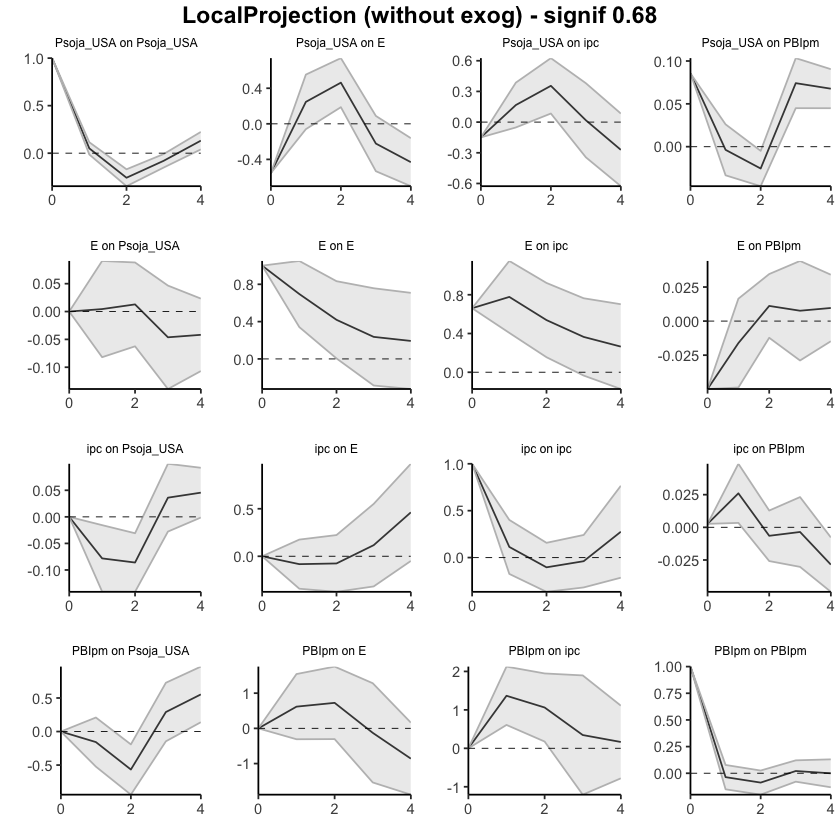

In [29]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.08288336,-0.3413842,0.1756175
38,ipc,E,2,-0.15831965,-0.7154740,0.3988347
39,ipc,E,3,-0.04143286,-1.0326716,0.9498059
40,ipc,E,4,0.42081718,-1.0814717,1.9231060


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,0.6173020,-0.3088524,1.543456
53,PBIpm,E,2,1.3424989,-0.6134443,3.298442
54,PBIpm,E,3,1.2156963,-2.1495217,4.580914
55,PBIpm,E,4,0.3556121,-4.0324209,4.743645


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.55393198,-0.5539320,-0.5539319815
2,Psoja_USA,E,1,-0.30721061,-0.6140693,-0.0003518744
3,Psoja_USA,E,2,0.15562536,-0.4270749,0.7383256327
4,Psoja_USA,E,3,-0.06654149,-0.9599894,0.8269064026
5,Psoja_USA,E,4,-0.49807067,-1.6613297,0.6651883093


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.08551669,0.085516692,0.08551669
12,Psoja_USA,PBIpm,1,0.08183544,0.052083390,0.11158750
13,Psoja_USA,PBIpm,2,0.05633500,0.005965511,0.10670449
14,Psoja_USA,PBIpm,3,0.13048820,0.050909537,0.21006686
15,Psoja_USA,PBIpm,4,0.19816030,0.095802091,0.30051851


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.000000000,0.00000000,0.00000000
17,E,Psoja_USA,1,0.004417412,-0.08198023,0.09081506
18,E,Psoja_USA,2,0.017235638,-0.14442615,0.17889743
19,E,Psoja_USA,3,-0.029028442,-0.28350892,0.22545204
20,E,Psoja_USA,4,-0.070829252,-0.39033357,0.24867506


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Psoja_USA,1,-0.07817885,-0.1407507,-0.01560699
33,ipc,Psoja_USA,2,-0.16416964,-0.2818787,-0.04646057
34,ipc,Psoja_USA,3,-0.12806475,-0.3095741,0.05344460
35,ipc,Psoja_USA,4,-0.08249615,-0.3108117,0.14581940


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.0000000,0.000000,0.00000000
47,PBIpm,Psoja_USA,1,-0.1572730,-0.523447,0.20890100
48,PBIpm,Psoja_USA,2,-0.7238034,-1.464628,0.01702143
49,PBIpm,Psoja_USA,3,-0.4332046,-1.610497,0.74408769
50,PBIpm,Psoja_USA,4,0.1205075,-1.471254,1.71226896


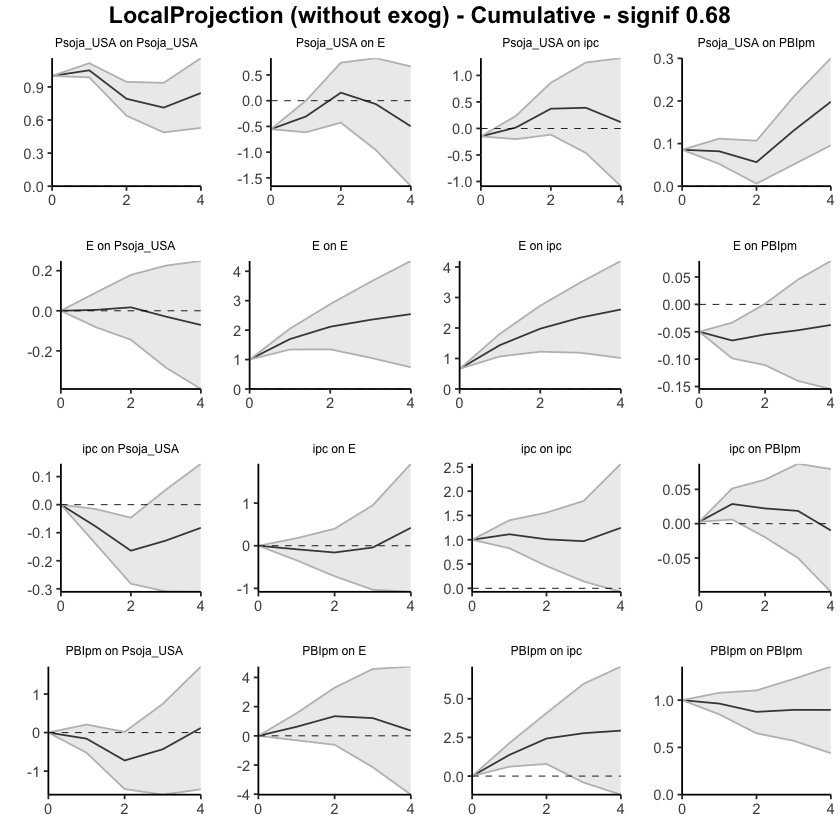

In [30]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,80,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.02657420,-0.3891228,0.3359744
38,ipc,E,2,0.05293397,-0.3751388,0.4810068
39,ipc,E,3,0.19400833,-0.3607726,0.7487892
40,ipc,E,4,0.47734607,-0.1268536,1.0815457


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,0.5238716,-0.4038229,1.4515661
53,PBIcf,E,2,0.5976780,-0.7510646,1.9464206
54,PBIcf,E,3,-0.8627564,-2.5328839,0.8073710
55,PBIcf,E,4,-2.1922376,-3.6557577,-0.7287174


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.08494822,-0.08494822,-0.08494822
2,Pmaíz_USA,E,1,0.46170443,0.03491997,0.88848889
3,Pmaíz_USA,E,2,0.41223444,-0.21932384,1.04379272
4,Pmaíz_USA,E,3,-0.35048931,-1.25715010,0.55617147
5,Pmaíz_USA,E,4,-0.47402341,-1.08024885,0.13220204


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.058571539,0.05857154,0.05857154
12,Pmaíz_USA,PBIcf,1,-0.018899729,-0.05349687,0.01569741
13,Pmaíz_USA,PBIcf,2,-0.006467656,-0.03938212,0.02644681
14,Pmaíz_USA,PBIcf,3,0.074420115,0.03786546,0.11097477
15,Pmaíz_USA,PBIcf,4,0.047726061,0.01039793,0.08505420


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,-0.02977445,-0.1139448,0.05439593
18,E,Pmaíz_USA,2,-0.02141562,-0.1207665,0.07793530
19,E,Pmaíz_USA,3,-0.02628938,-0.1172036,0.06462484
20,E,Pmaíz_USA,4,-0.01045864,-0.1201421,0.09922479


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Pmaíz_USA,1,0.01538801,-0.05355371,0.08432973
33,ipc,Pmaíz_USA,2,-0.04499721,-0.12619854,0.03620412
34,ipc,Pmaíz_USA,3,0.03791548,-0.03319107,0.10902203
35,ipc,Pmaíz_USA,4,0.01590289,-0.06375692,0.09556270


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,-0.2820160,-0.7766963,0.2126644
48,PBIcf,Pmaíz_USA,2,-0.2540822,-0.8057402,0.2975758
49,PBIcf,Pmaíz_USA,3,-0.0278514,-0.4821894,0.4264866
50,PBIcf,Pmaíz_USA,4,0.9910275,0.5082418,1.4738133


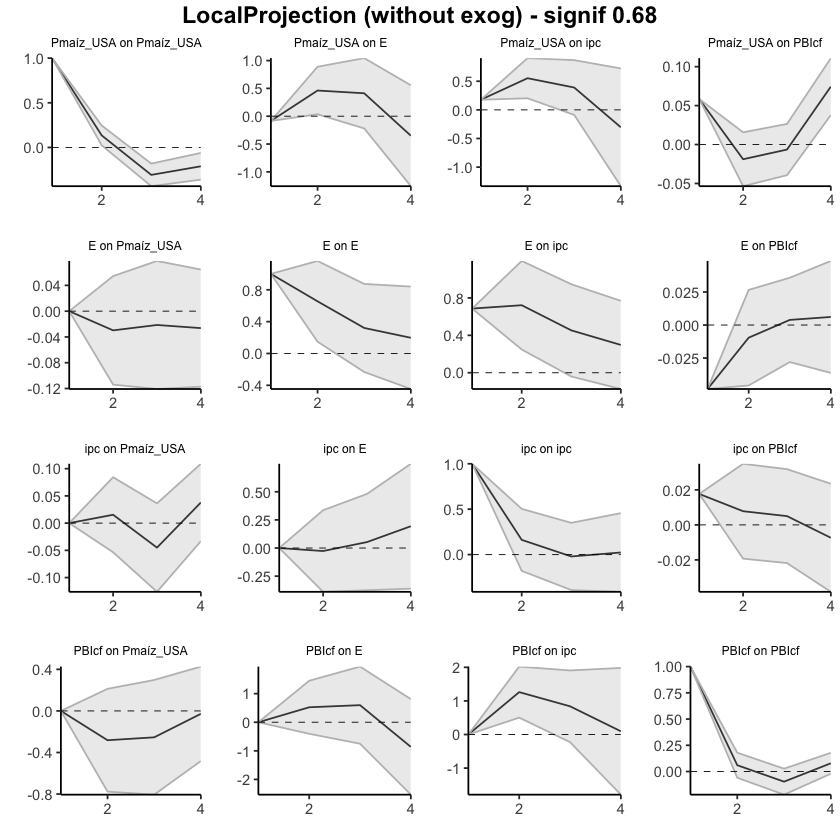

In [ ]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,80,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.02657420,-0.3891228,0.3359744
38,ipc,E,2,0.02635977,-0.7642616,0.8169812
39,ipc,E,3,0.22036810,-1.1250342,1.5657704
40,ipc,E,4,0.69771417,-1.2518877,2.6473161


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,0.5238716,-0.4038229,1.451566
53,PBIcf,E,2,1.1215496,-1.1548874,3.397987
54,PBIcf,E,3,0.2587932,-3.6877713,4.205358
55,PBIcf,E,4,-1.9334444,-7.3435291,3.476640


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.08494822,-0.08494822,-0.08494822
2,Pmaíz_USA,E,1,0.37675621,-0.05002825,0.80354067
3,Pmaíz_USA,E,2,0.78899065,-0.26935209,1.84733338
4,Pmaíz_USA,E,3,0.43850133,-1.52650219,2.40350485
5,Pmaíz_USA,E,4,-0.03552208,-2.60675104,2.53570689


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.05857154,0.058571539,0.05857154
12,Pmaíz_USA,PBIcf,1,0.03967181,0.005074670,0.07426895
13,Pmaíz_USA,PBIcf,2,0.03320415,-0.034307450,0.10071576
14,Pmaíz_USA,PBIcf,3,0.10762427,0.003558014,0.21169052
15,Pmaíz_USA,PBIcf,4,0.15535033,0.013955941,0.29674472


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,-0.02977445,-0.1139448,0.05439593
18,E,Pmaíz_USA,2,-0.05119007,-0.2347114,0.13233123
19,E,Pmaíz_USA,3,-0.07747945,-0.3519150,0.19695607
20,E,Pmaíz_USA,4,-0.08793810,-0.4720571,0.29618086


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.000000000,0.00000000,0.00000000
32,ipc,Pmaíz_USA,1,0.015388012,-0.05355371,0.08432973
33,ipc,Pmaíz_USA,2,-0.029609197,-0.17975225,0.12053385
34,ipc,Pmaíz_USA,3,0.008306281,-0.21294332,0.22955589
35,ipc,Pmaíz_USA,4,0.024209173,-0.27670024,0.32511859


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,-0.2820160,-0.7766963,0.2126644
48,PBIcf,Pmaíz_USA,2,-0.5360982,-1.5824366,0.5102402
49,PBIcf,Pmaíz_USA,3,-0.5639496,-2.0646260,0.9367268
50,PBIcf,Pmaíz_USA,4,0.4270780,-1.5563842,2.4105401


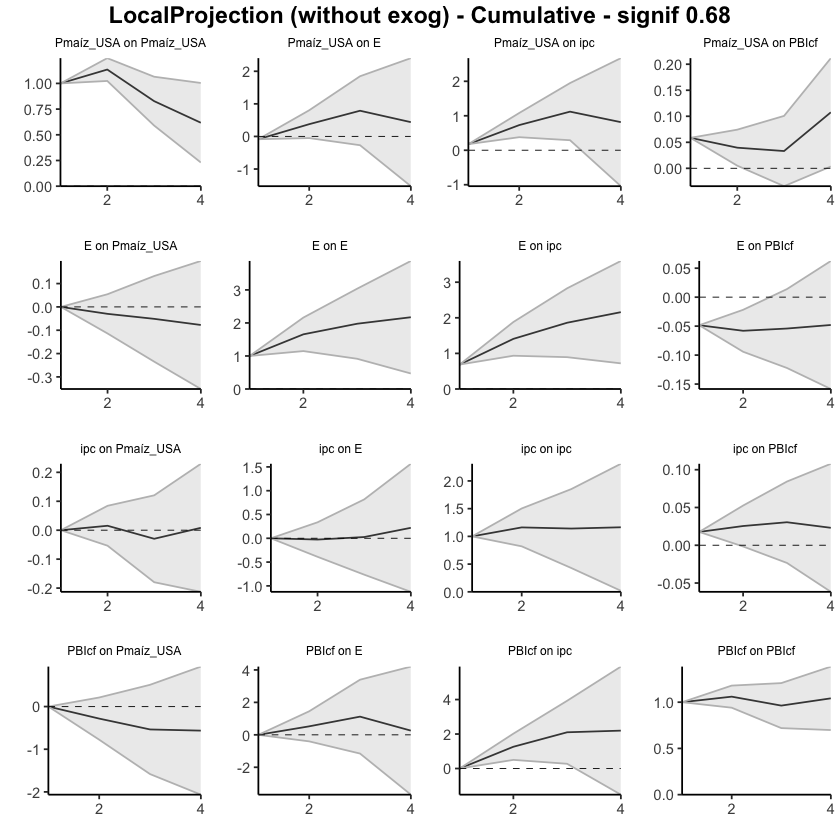

In [ ]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.000000000
37,ipc,E,1,0.10751504,-0.2102835,0.425313557
38,ipc,E,2,-0.14112053,-0.5170751,0.234834040
39,ipc,E,3,-0.58347711,-1.1683940,0.001439798
40,ipc,E,4,-0.08055872,-0.4700015,0.308884006


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.0000000
52,PBIpm,E,1,0.8756595,-0.06851604,1.8198351
53,PBIpm,E,2,1.0486730,0.08609775,2.0112483
54,PBIpm,E,3,-0.7696389,-1.87006695,0.3307892
55,PBIpm,E,4,-1.7672255,-3.16863067,-0.3658202


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.06438151,-0.06438151,-0.06438151
2,Pmaíz_USA,E,1,0.50109277,0.16998633,0.83219922
3,Pmaíz_USA,E,2,0.30356749,-0.04101546,0.64815044
4,Pmaíz_USA,E,3,-0.25547266,-0.61023973,0.09929440
5,Pmaíz_USA,E,4,-0.31839204,-0.58504696,-0.05173712


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.0460273926,0.046027393,0.04602739
12,Pmaíz_USA,PBIpm,1,-0.0062373388,-0.031869116,0.01939444
13,Pmaíz_USA,PBIpm,2,-0.0009574054,-0.025275412,0.02336060
14,Pmaíz_USA,PBIpm,3,0.0366032177,0.002786137,0.07042030
15,Pmaíz_USA,PBIpm,4,0.0676867863,0.037064580,0.09830899


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,0.01743893,-0.1276506,0.16252844
18,E,Pmaíz_USA,2,-0.01528634,-0.1279873,0.09741464
19,E,Pmaíz_USA,3,-0.05904955,-0.1575267,0.03942758
20,E,Pmaíz_USA,4,-0.02778697,-0.1691824,0.11360845


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Pmaíz_USA,1,0.03523139,-0.1075957,0.17805844
33,ipc,Pmaíz_USA,2,-0.10473810,-0.2216372,0.01216104
34,ipc,Pmaíz_USA,3,0.04282776,-0.0537233,0.13937881
35,ipc,Pmaíz_USA,4,0.01637776,-0.1127724,0.14552795


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.0000000,0.0000000,0.00000000
47,PBIpm,Pmaíz_USA,1,0.0745474,-0.3744750,0.52356984
48,PBIpm,Pmaíz_USA,2,-0.4486749,-0.9082282,0.01087843
49,PBIpm,Pmaíz_USA,3,-0.1487789,-0.5925760,0.29501808
50,PBIpm,Pmaíz_USA,4,0.5887687,0.1735746,1.00396275


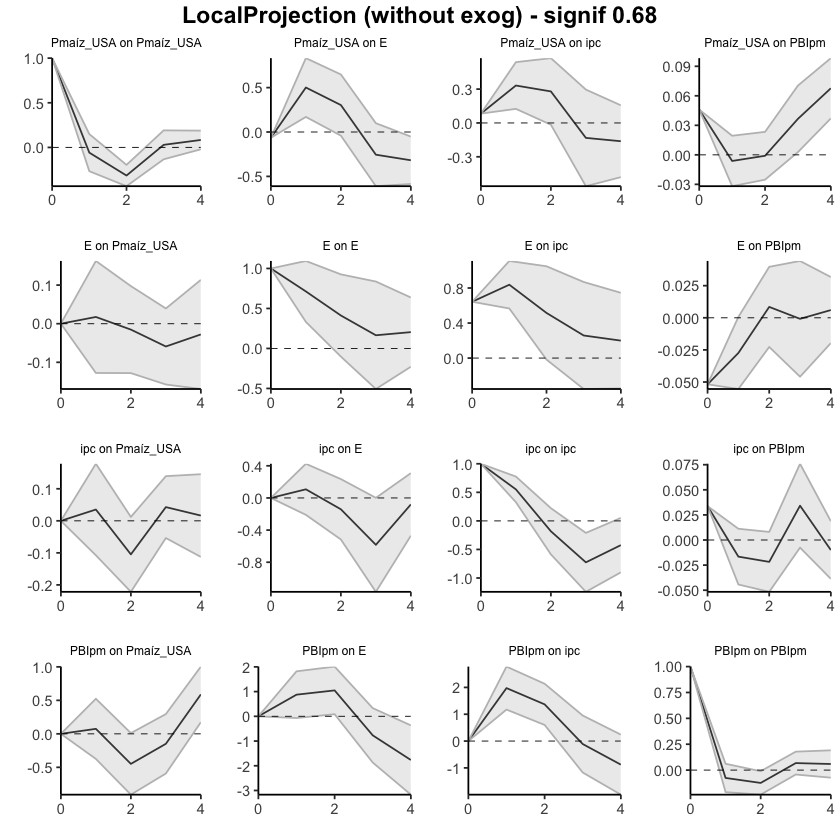

In [33]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,0.10751504,-0.2102835,0.4253136
38,ipc,E,2,-0.03360549,-0.7273586,0.6601476
39,ipc,E,3,-0.61708259,-1.8957526,0.6615874
40,ipc,E,4,-0.69764132,-2.3657540,0.9704714


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000
52,PBIpm,E,1,0.8756595,-0.06851604,1.819835
53,PBIpm,E,2,1.9243326,0.01758171,3.831083
54,PBIpm,E,3,1.1546937,-1.85248525,4.161873
55,PBIpm,E,4,-0.6125318,-5.02111592,3.796052


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.06438151,-0.06438151,-0.06438151
2,Pmaíz_USA,E,1,0.43671126,0.10560482,0.76781771
3,Pmaíz_USA,E,2,0.74027875,0.06458936,1.41596815
4,Pmaíz_USA,E,3,0.48480609,-0.54565037,1.51526255
5,Pmaíz_USA,E,4,0.16641405,-1.13069733,1.46352543


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.04602739,0.046027393,0.04602739
12,Pmaíz_USA,PBIpm,1,0.03979005,0.014158277,0.06542183
13,Pmaíz_USA,PBIpm,2,0.03883265,-0.011117135,0.08878243
14,Pmaíz_USA,PBIpm,3,0.07543587,-0.008330999,0.15920273
15,Pmaíz_USA,PBIpm,4,0.14312265,0.028733581,0.25751172


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.000000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,0.017438933,-0.1276506,0.1625284
18,E,Pmaíz_USA,2,0.002152597,-0.2556379,0.2599431
19,E,Pmaíz_USA,3,-0.056896950,-0.4131646,0.2993707
20,E,Pmaíz_USA,4,-0.084683917,-0.5823469,0.4129791


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
32,ipc,Pmaíz_USA,1,0.03523139,-0.1075957,0.1780584
33,ipc,Pmaíz_USA,2,-0.06950671,-0.3292329,0.1902195
34,ipc,Pmaíz_USA,3,-0.02667896,-0.3829562,0.3295983
35,ipc,Pmaíz_USA,4,-0.01030120,-0.4957286,0.4751262


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.00000000,0.000000,0.0000000
47,PBIpm,Pmaíz_USA,1,0.07454740,-0.374475,0.5235698
48,PBIpm,Pmaíz_USA,2,-0.37412746,-1.282703,0.5344483
49,PBIpm,Pmaíz_USA,3,-0.52290641,-1.875279,0.8294663
50,PBIpm,Pmaíz_USA,4,0.06586227,-1.701705,1.8334291


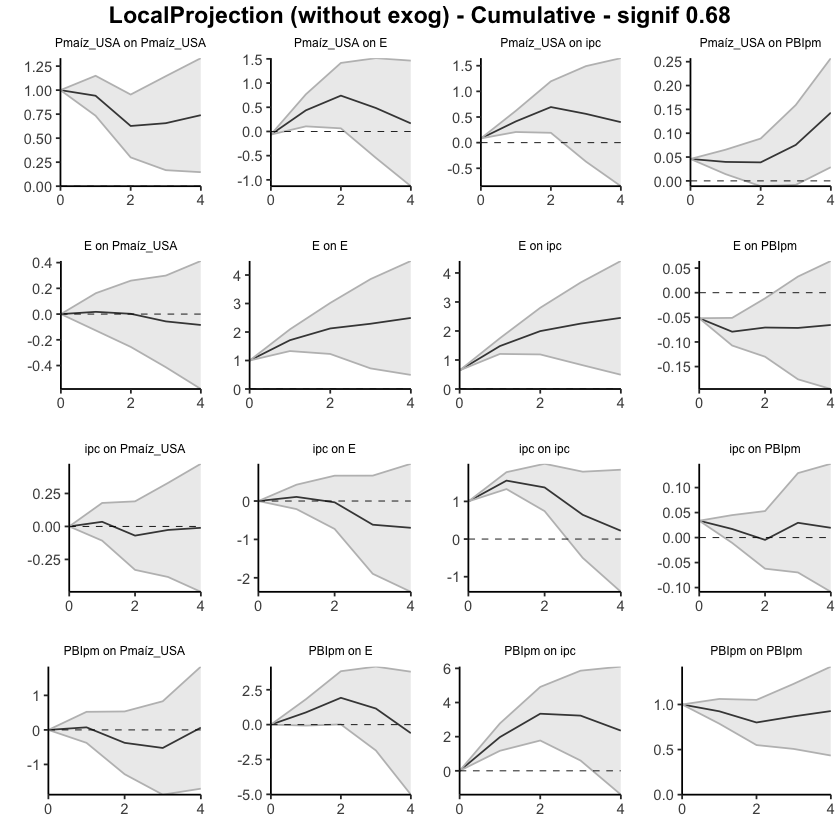

In [32]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.02662339,-0.2763935,0.2231467
38,ipc,E,2,-0.01173448,-0.2673166,0.2438477
39,ipc,E,3,0.10439906,-0.3247910,0.5335892
40,ipc,E,4,0.41629089,-0.1745704,1.0071522


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000000
52,PBIpm,E,1,0.8697149,-0.01932849,1.758758273
53,PBIpm,E,2,1.0150280,-0.06709121,2.097147298
54,PBIpm,E,3,-0.2115410,-1.57185882,1.148776744
55,PBIpm,E,4,-1.0915533,-2.18138690,-0.001719657


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.15612886,-0.1561289,-0.1561289
2,Ptrigo_USA,E,1,0.49769587,0.2322889,0.7631028
3,Ptrigo_USA,E,2,0.62014771,0.2460093,0.9942861
4,Ptrigo_USA,E,3,0.06059816,-0.4620767,0.5832730
5,Ptrigo_USA,E,4,-0.18500918,-0.5288290,0.1588107


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.04200478,0.04200478,0.04200478
12,Ptrigo_USA,PBIpm,1,-0.01274315,-0.04471943,0.01923313
13,Ptrigo_USA,PBIpm,2,-0.01847310,-0.04284111,0.00589491
14,Ptrigo_USA,PBIpm,3,0.04703284,0.01464641,0.07941926
15,Ptrigo_USA,PBIpm,4,0.07844187,0.04112565,0.11575809


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.000000000,0.00000000,0.00000000
17,E,Ptrigo_USA,1,-0.042150417,-0.13258623,0.04828539
18,E,Ptrigo_USA,2,-0.030665162,-0.15080575,0.08947542
19,E,Ptrigo_USA,3,-0.013327114,-0.09522190,0.06856767
20,E,Ptrigo_USA,4,0.006060367,-0.08695659,0.09907732


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.000000000,0.00000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.007104372,-0.07135760,0.05714886
33,ipc,Ptrigo_USA,2,0.018809156,-0.07236910,0.10998741
34,ipc,Ptrigo_USA,3,0.023886359,-0.03464362,0.08241634
35,ipc,Ptrigo_USA,4,-0.016180825,-0.08524613,0.05288448


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.03396981,-0.3533113,0.2853717
48,PBIpm,Ptrigo_USA,2,-0.20378988,-0.6258371,0.2182573
49,PBIpm,Ptrigo_USA,3,0.18231875,-0.1947508,0.5593883
50,PBIpm,Ptrigo_USA,4,0.13532371,-0.2629157,0.5335632


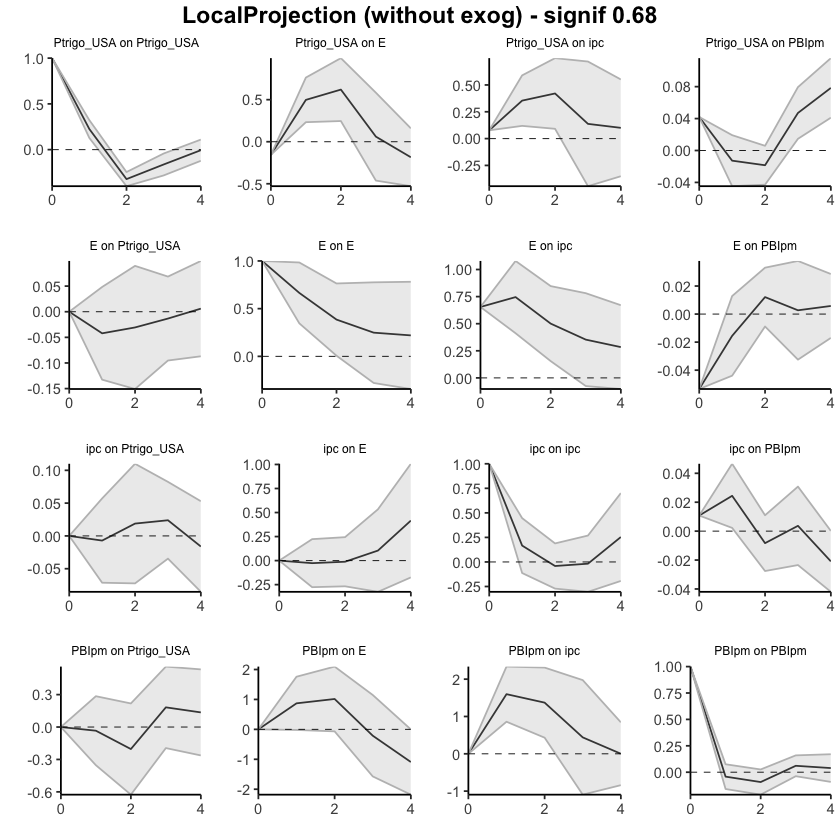

In [31]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.02662339,-0.2763935,0.2231467
38,ipc,E,2,-0.03835787,-0.5437101,0.4669944
39,ipc,E,3,0.06604119,-0.8685012,1.0005835
40,ipc,E,4,0.48233208,-1.0430715,2.0077357


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000
52,PBIpm,E,1,0.8697149,-0.01932849,1.758758
53,PBIpm,E,2,1.8847429,-0.08641970,3.855906
54,PBIpm,E,3,1.6732019,-1.65827852,5.004682
55,PBIpm,E,4,0.5816486,-3.83966542,5.002963


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.1561289,-0.15612886,-0.1561289
2,Ptrigo_USA,E,1,0.3415670,0.07616007,0.6069740
3,Ptrigo_USA,E,2,0.9617147,0.32216941,1.6012600
4,Ptrigo_USA,E,3,1.0223129,-0.13990732,2.1845331
5,Ptrigo_USA,E,4,0.8373037,-0.66873634,2.3433437


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.04200478,0.04200478,0.04200478
12,Ptrigo_USA,PBIpm,1,0.02926163,-0.00271465,0.06123791
13,Ptrigo_USA,PBIpm,2,0.01078853,-0.04555576,0.06713282
14,Ptrigo_USA,PBIpm,3,0.05782137,-0.03090935,0.14655208
15,Ptrigo_USA,PBIpm,4,0.13626323,0.01021630,0.26231017


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
17,E,Ptrigo_USA,1,-0.04215042,-0.1325862,0.04828539
18,E,Ptrigo_USA,2,-0.07281558,-0.2833920,0.13776082
19,E,Ptrigo_USA,3,-0.08614269,-0.3786139,0.20632849
20,E,Ptrigo_USA,4,-0.08008233,-0.4655705,0.30540581


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.000000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.007104372,-0.0713576,0.05714886
33,ipc,Ptrigo_USA,2,0.011704784,-0.1437267,0.16713627
34,ipc,Ptrigo_USA,3,0.035591143,-0.1783703,0.24955261
35,ipc,Ptrigo_USA,4,0.019410318,-0.2636165,0.30243709


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.03396981,-0.3533113,0.2853717
48,PBIpm,Ptrigo_USA,2,-0.23775970,-0.9791483,0.5036290
49,PBIpm,Ptrigo_USA,3,-0.05544095,-1.1738991,1.0630172
50,PBIpm,Ptrigo_USA,4,0.07988276,-1.4368148,1.5965804


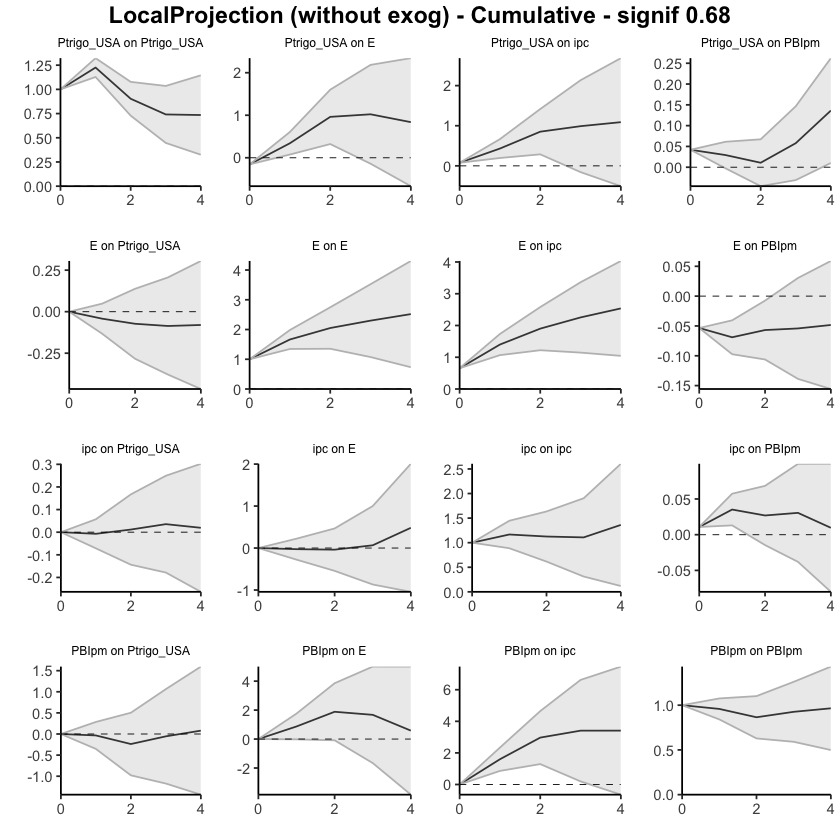

In [34]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,0.1518189,-0.1704747,0.47411245
38,ipc,E,2,-0.1930203,-0.5770607,0.19102012
39,ipc,E,3,-0.6924131,-1.3121447,-0.07268147
40,ipc,E,4,-0.1354142,-0.5912195,0.32039120


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000000
52,PBIpm,E,1,0.9666308,0.04574806,1.887513496
53,PBIpm,E,2,0.7939116,-0.17234137,1.760164489
54,PBIpm,E,3,-1.0841727,-2.15882907,-0.009516378
55,PBIpm,E,4,-1.9965638,-3.51013022,-0.482997413


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.0754667,-0.0754667,-0.0754667
2,Ptrigo_USA,E,1,0.4999351,0.1256410,0.8742291
3,Ptrigo_USA,E,2,0.7389898,0.3380341,1.1399455
4,Ptrigo_USA,E,3,0.2348942,-0.2800827,0.7498712
5,Ptrigo_USA,E,4,-0.1540903,-0.5261944,0.2180138


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.038933047,0.038933047,0.038933047
12,Ptrigo_USA,PBIpm,1,-0.008741447,-0.045942777,0.028459883
13,Ptrigo_USA,PBIpm,2,-0.027362031,-0.056828917,0.002104855
14,Ptrigo_USA,PBIpm,3,0.029622163,-0.008620134,0.067864459
15,Ptrigo_USA,PBIpm,4,0.089119049,0.044956100,0.133281999


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.000000000,0.00000000,0.00000000
17,E,Ptrigo_USA,1,-0.035395811,-0.13939754,0.06860592
18,E,Ptrigo_USA,2,-0.039204181,-0.18103427,0.10262591
19,E,Ptrigo_USA,3,-0.008039981,-0.09015174,0.07407178
20,E,Ptrigo_USA,4,0.012654284,-0.11472940,0.14003797


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.000000000,0.000000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.141432109,-0.233692768,-0.04917145
33,ipc,Ptrigo_USA,2,-0.040746398,-0.169723938,0.08823114
34,ipc,Ptrigo_USA,3,0.079701173,0.001383576,0.15801877
35,ipc,Ptrigo_USA,4,-0.005550254,-0.127083053,0.11598255


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.09872855,-0.3678644,0.1704073
48,PBIpm,Ptrigo_USA,2,-0.35621103,-0.8204450,0.1080230
49,PBIpm,Ptrigo_USA,3,0.21986115,-0.1627987,0.6025210
50,PBIpm,Ptrigo_USA,4,0.18444091,-0.2022076,0.5710894


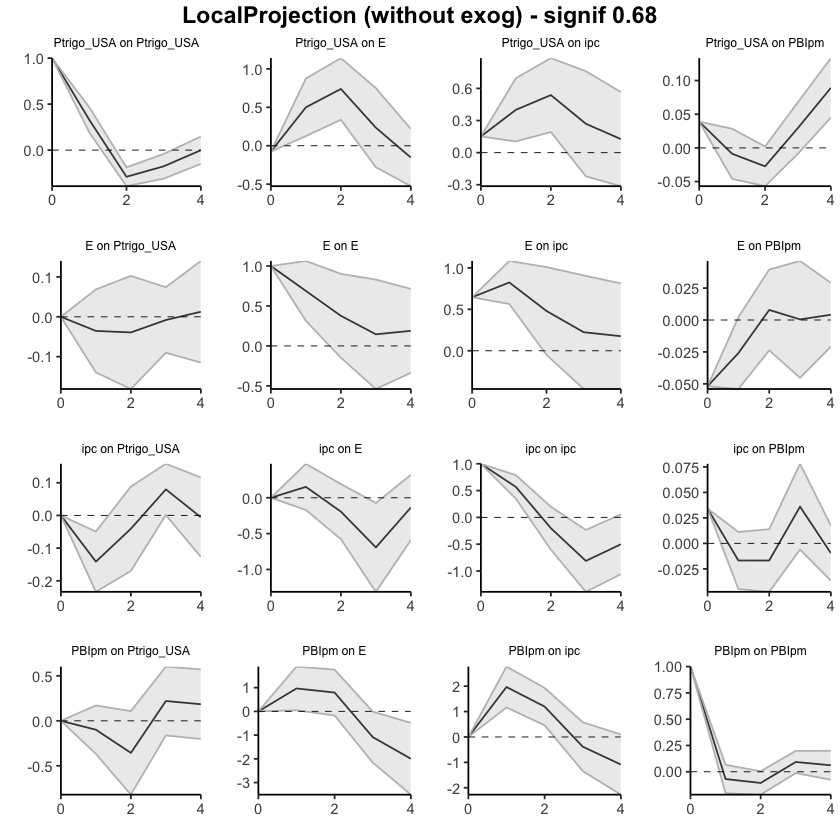

In [36]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,0.15181888,-0.1704747,0.4741125
38,ipc,E,2,-0.04120143,-0.7475354,0.6651326
39,ipc,E,3,-0.73361453,-2.0596802,0.5924511
40,ipc,E,4,-0.86902869,-2.6508997,0.9128423


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000
52,PBIpm,E,1,0.9666308,0.04574806,1.887513
53,PBIpm,E,2,1.7605423,-0.12659332,3.647678
54,PBIpm,E,3,0.6763696,-2.28542239,3.638162
55,PBIpm,E,4,-1.3201942,-5.79555261,3.155164


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.0754667,-0.07546670,-0.0754667
2,Ptrigo_USA,E,1,0.4244684,0.05017435,0.7987624
3,Ptrigo_USA,E,2,1.1634581,0.38820841,1.9387078
4,Ptrigo_USA,E,3,1.3983524,0.10812571,2.6885790
5,Ptrigo_USA,E,4,1.2442620,-0.41806872,2.9065928


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.038933047,0.03893305,0.03893305
12,Ptrigo_USA,PBIpm,1,0.030191600,-0.00700973,0.06739293
13,Ptrigo_USA,PBIpm,2,0.002829569,-0.06383865,0.06949779
14,Ptrigo_USA,PBIpm,3,0.032451732,-0.07245878,0.13736224
15,Ptrigo_USA,PBIpm,4,0.121570781,-0.02750268,0.27064424


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
17,E,Ptrigo_USA,1,-0.03539581,-0.1393975,0.06860592
18,E,Ptrigo_USA,2,-0.07459999,-0.3204318,0.17123183
19,E,Ptrigo_USA,3,-0.08263997,-0.4105836,0.24530360
20,E,Ptrigo_USA,4,-0.06998569,-0.5253130,0.38534158


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.0000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.1414321,-0.2336928,-0.04917145
33,ipc,Ptrigo_USA,2,-0.1821785,-0.4034167,0.03905969
34,ipc,Ptrigo_USA,3,-0.1024773,-0.4020331,0.19707846
35,ipc,Ptrigo_USA,4,-0.1080276,-0.5291162,0.31306101


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.09872855,-0.3678644,0.1704073
48,PBIpm,Ptrigo_USA,2,-0.45493959,-1.1883094,0.2784302
49,PBIpm,Ptrigo_USA,3,-0.23507844,-1.3511081,0.8809512
50,PBIpm,Ptrigo_USA,4,-0.05063753,-1.5533157,1.4520406


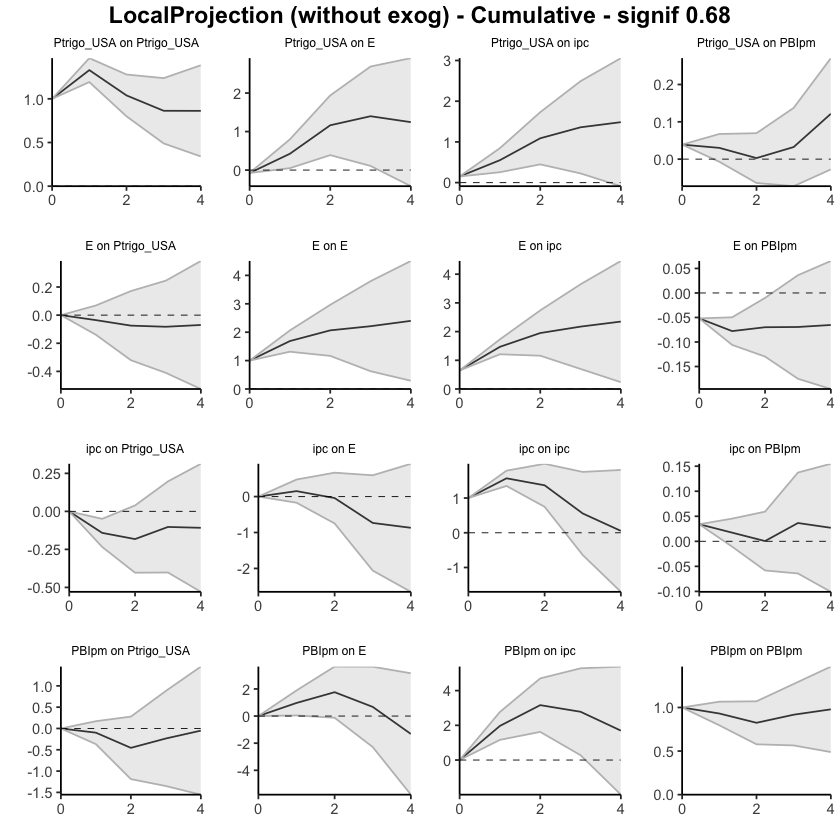

In [35]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, cumulative=TRUE)

### 1935-2023. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.0000000
12,ipc,E,1,-0.07477121,-0.34544294,0.1959005
13,ipc,E,2,-0.06590628,-0.37809249,0.2462799
14,ipc,E,3,0.11522045,-0.33738368,0.5678246
15,ipc,E,4,0.45094742,-0.07354373,0.9754386


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,0.6173020,-0.3088524,1.5434564
23,PBIpm,E,2,0.7251969,-0.3045918,1.7549857
24,PBIpm,E,3,-0.1268026,-1.5360775,1.2824723
25,PBIpm,E,4,-0.8600842,-1.8828992,0.1627308


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6437707,0.64377074,0.6437707
2,E,ipc,1,0.7695535,0.40671302,1.1323939
3,E,ipc,2,0.5355247,0.16068772,0.9103617
4,E,ipc,3,0.3639168,-0.02321676,0.7510504
5,E,ipc,4,0.2591028,-0.16570044,0.6839061


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.366996,0.6083453,2.125646
28,PBIpm,ipc,2,1.061979,0.1762512,1.947706
29,PBIpm,ipc,3,0.345554,-1.2052029,1.896311
30,PBIpm,ipc,4,0.164594,-0.7801244,1.109312


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.054431050,-0.05443105,-0.05443105
7,E,PBIpm,1,-0.016421396,-0.04809872,0.01525593
8,E,PBIpm,2,0.011642669,-0.01090066,0.03418600
9,E,PBIpm,3,0.007577684,-0.02803352,0.04318889
10,E,PBIpm,4,0.010126435,-0.01331242,0.03356529


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.015803629,0.015803629,0.015803629
17,ipc,PBIpm,1,0.025547522,0.001420713,0.049674331
18,ipc,PBIpm,2,-0.007629508,-0.028449585,0.013190569
19,ipc,PBIpm,3,-0.003272803,-0.031297678,0.024752072
20,ipc,PBIpm,4,-0.028557097,-0.051091572,-0.006022622


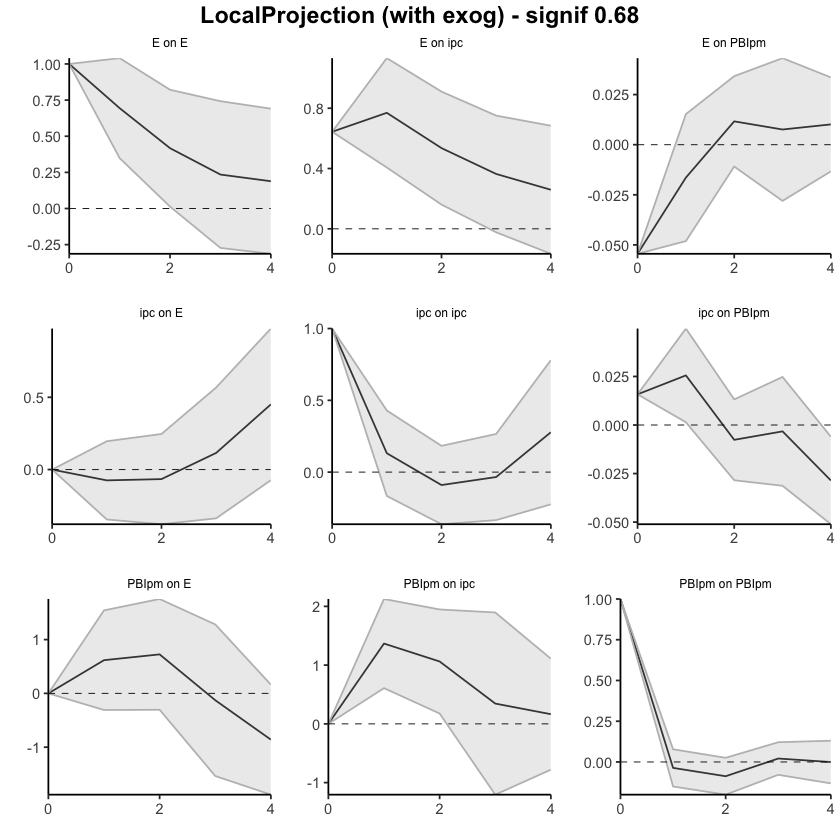

In [37]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.07477121,-0.3454429,0.1959005
13,ipc,E,2,-0.14067749,-0.7235354,0.4421804
14,ipc,E,3,-0.02545705,-1.0609191,1.0100050
15,ipc,E,4,0.42549038,-1.1344628,1.9854436


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,0.6173020,-0.3088524,1.543456
23,PBIpm,E,2,1.3424989,-0.6134443,3.298442
24,PBIpm,E,3,1.2156963,-2.1495217,4.580914
25,PBIpm,E,4,0.3556121,-4.0324209,4.743645


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6437707,0.6437707,0.6437707
2,E,ipc,1,1.4133242,1.0504838,1.7761647
3,E,ipc,2,1.9488489,1.2111715,2.6865263
4,E,ipc,3,2.3127657,1.1879547,3.4375767
5,E,ipc,4,2.5718686,1.0222543,4.1214829


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.366996,0.6083453,2.125646
28,PBIpm,ipc,2,2.428974,0.7845965,4.073352
29,PBIpm,ipc,3,2.774528,-0.4206064,5.969663
30,PBIpm,ipc,4,2.939122,-1.2007308,7.078976


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05443105,-0.05443105,-0.054431050
7,E,PBIpm,1,-0.07085245,-0.10252977,-0.039175123
8,E,PBIpm,2,-0.05920978,-0.11343043,-0.004989122
9,E,PBIpm,3,-0.05163209,-0.14146396,0.038199769
10,E,PBIpm,4,-0.04150566,-0.15477638,0.071765059


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.015803629,0.01580363,0.01580363
17,ipc,PBIpm,1,0.041351151,0.01722434,0.06547796
18,ipc,PBIpm,2,0.033721643,-0.01122524,0.07866853
19,ipc,PBIpm,3,0.030448840,-0.04252292,0.10342060
20,ipc,PBIpm,4,0.001891743,-0.09361449,0.09739798


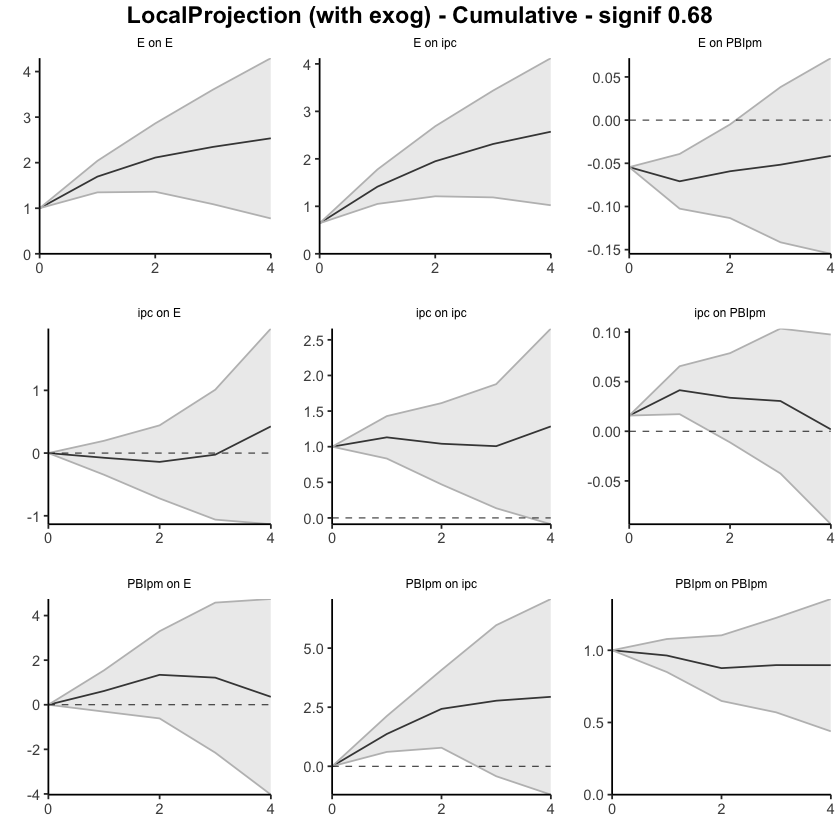

In [38]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.000000000
12,ipc,E,1,0.22473281,-0.07628396,0.525749589
13,ipc,E,2,0.23347591,-0.07653039,0.543482211
14,ipc,E,3,-0.39747230,-0.80100647,0.006061874
15,ipc,E,4,-0.02485972,-0.49063775,0.440918323


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.00000000,0.0000000,0.00000000
22,PBIpm,E,1,0.67013365,-0.1881156,1.52838290
23,PBIpm,E,2,0.03557968,-0.9153254,0.98648471
24,PBIpm,E,3,-1.09314053,-2.1041029,-0.08217813
25,PBIpm,E,4,-1.85379669,-3.0524167,-0.65517667


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6284730,0.6284730,0.6284730
2,E,ipc,1,0.8502623,0.6019695,1.0985551
3,E,ipc,2,0.5456002,0.1824551,0.9087452
4,E,ipc,3,0.2906147,-0.1004076,0.6816370
5,E,ipc,4,0.1953492,-0.3522997,0.7429981


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIpm,ipc,1,1.4450393,0.7341934,2.1558852
28,PBIpm,ipc,2,0.3459441,-0.4012951,1.0931833
29,PBIpm,ipc,3,-0.7999371,-1.6320930,0.0322188
30,PBIpm,ipc,4,-0.8562958,-1.7811640,0.0685724


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.050540236,-0.05054024,-0.050540236
7,E,PBIpm,1,-0.027202463,-0.05961502,0.005210089
8,E,PBIpm,2,0.003651217,-0.02583487,0.033137304
9,E,PBIpm,3,0.005291255,-0.03807221,0.048654722
10,E,PBIpm,4,0.011917495,-0.02348193,0.047316918


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.023943242,0.02394324,0.023943242
17,ipc,PBIpm,1,-0.009679809,-0.03786482,0.018505201
18,ipc,PBIpm,2,-0.034211967,-0.06271091,-0.005713028
19,ipc,PBIpm,3,0.012947690,-0.02531638,0.051211759
20,ipc,PBIpm,4,0.004495086,-0.02959952,0.038589695


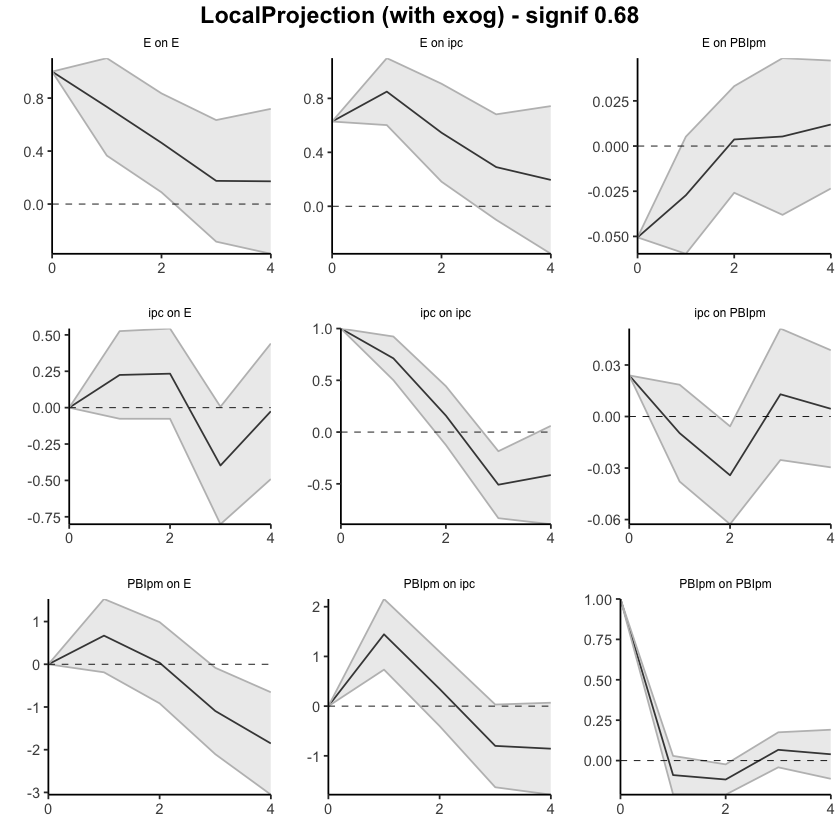

In [41]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 3, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.0000000
12,ipc,E,1,0.22473281,-0.07628396,0.5257496
13,ipc,E,2,0.45820873,-0.15281435,1.0692318
14,ipc,E,3,0.06073643,-0.95382082,1.0752937
15,ipc,E,4,0.03587671,-1.44445858,1.5162120


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,0.6701337,-0.1881156,1.528383
23,PBIpm,E,2,0.7057133,-1.1034409,2.514868
24,PBIpm,E,3,-0.3874272,-3.2075439,2.432689
25,PBIpm,E,4,-2.2412239,-6.2599606,1.777513


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.628473,0.6284730,0.628473
2,E,ipc,1,1.478735,1.2304424,1.727028
3,E,ipc,2,2.024335,1.4128976,2.635773
4,E,ipc,3,2.314950,1.3124900,3.317410
5,E,ipc,4,2.510299,0.9601904,4.060408


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.4450393,0.7341934,2.155885
28,PBIpm,ipc,2,1.7909834,0.3328983,3.249069
29,PBIpm,ipc,3,0.9910463,-1.2991947,3.281287
30,PBIpm,ipc,4,0.1347505,-3.0803586,3.349860


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05054024,-0.05054024,-0.05054024
7,E,PBIpm,1,-0.07774270,-0.11015525,-0.04533015
8,E,PBIpm,2,-0.07409148,-0.13599012,-0.01219284
9,E,PBIpm,3,-0.06880023,-0.17406233,0.03646188
10,E,PBIpm,4,-0.05688273,-0.19754426,0.08377880


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.023943242,0.02394324,0.02394324
17,ipc,PBIpm,1,0.014263434,-0.01392158,0.04244844
18,ipc,PBIpm,2,-0.019948533,-0.07663248,0.03673541
19,ipc,PBIpm,3,-0.007000844,-0.10194886,0.08794717
20,ipc,PBIpm,4,-0.002505758,-0.13154838,0.12653687


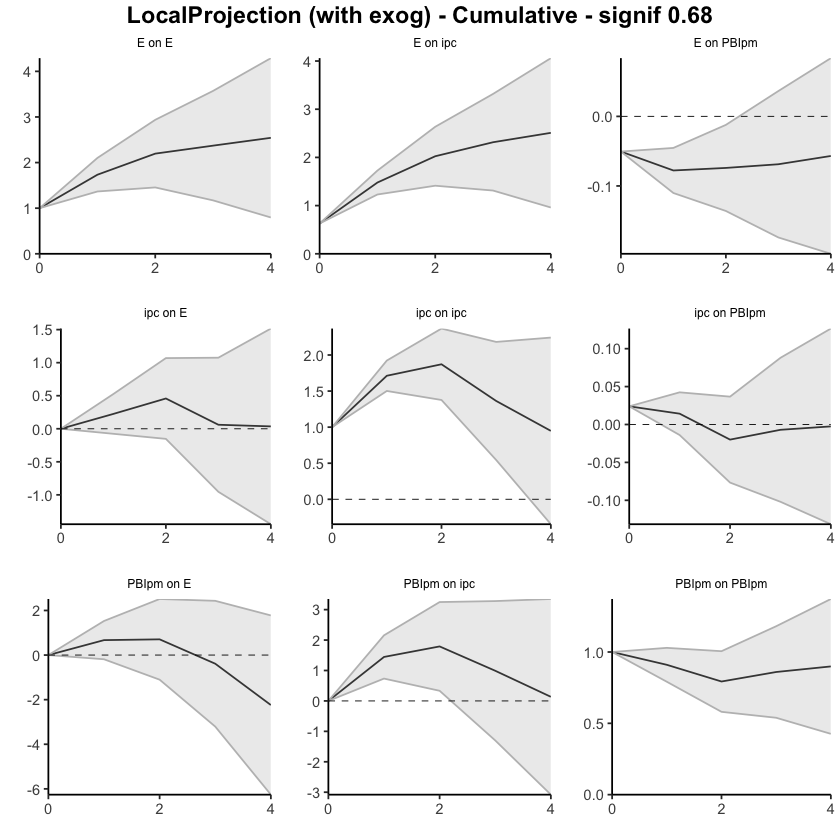

In [40]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 3, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.05156003,-0.3172554,0.2141353
13,ipc,E,2,-0.01986806,-0.3211022,0.2813661
14,ipc,E,3,0.12478273,-0.3209649,0.5705303
15,ipc,E,4,0.42928828,-0.1264704,0.9850470


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.00000000,0.00000000,0.00000000
22,PBIpm,E,1,0.72535279,-0.13927160,1.58997718
23,PBIpm,E,2,1.03002468,-0.09093849,2.15098784
24,PBIpm,E,3,-0.05794187,-1.52108362,1.40519987
25,PBIpm,E,4,-0.97855360,-2.02361125,0.06650406


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6532767,0.65327674,0.6532767
2,E,ipc,1,0.7437806,0.39485207,1.0927091
3,E,ipc,2,0.4942499,0.15668725,0.8318125
4,E,ipc,3,0.3372749,-0.04593595,0.7204857
5,E,ipc,4,0.2693946,-0.14275449,0.6815437


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.5195332,0.8131982,2.225868
28,PBIpm,ipc,2,1.3454085,0.3824761,2.308341
29,PBIpm,ipc,3,0.5570397,-1.1267218,2.240801
30,PBIpm,ipc,4,0.1262858,-0.7623187,1.014890


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.054965621,-0.054965621,-0.05496562
7,E,PBIpm,1,-0.015358058,-0.044106500,0.01339038
8,E,PBIpm,2,0.012870793,-0.008259624,0.03400121
9,E,PBIpm,3,0.002476186,-0.032270900,0.03722327
10,E,PBIpm,4,0.005934825,-0.014592851,0.02646250


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.017765322,0.017765322,0.017765322
17,ipc,PBIpm,1,0.024741857,0.001291003,0.048192712
18,ipc,PBIpm,2,-0.009234251,-0.029923995,0.011455493
19,ipc,PBIpm,3,0.002215388,-0.025092138,0.029522915
20,ipc,PBIpm,4,-0.024631403,-0.044916502,-0.004346304


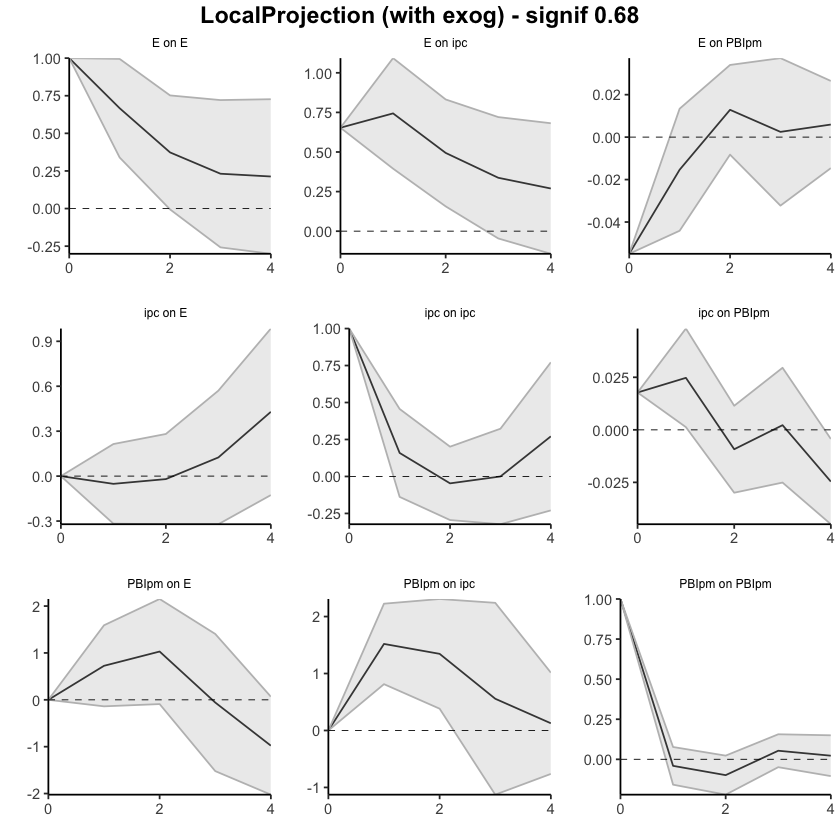

In [39]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.05156003,-0.3172554,0.2141353
13,ipc,E,2,-0.07142809,-0.6383576,0.4955014
14,ipc,E,3,0.05335464,-0.9593225,1.0660317
15,ipc,E,4,0.48264292,-1.0857929,2.0510787


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,0.7253528,-0.1392716,1.589977
23,PBIpm,E,2,1.7553775,-0.2302101,3.740965
24,PBIpm,E,3,1.6974356,-1.7512937,5.146165
25,PBIpm,E,4,0.7188820,-3.7749050,5.212669


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6532767,0.6532767,0.6532767
2,E,ipc,1,1.3970573,1.0481288,1.7459858
3,E,ipc,2,1.8913072,1.2048161,2.5777983
4,E,ipc,3,2.2285821,1.1588801,3.2982840
5,E,ipc,4,2.4979767,1.0161256,3.9798278


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.00000000,0.000000
27,PBIpm,ipc,1,1.519533,0.81319816,2.225868
28,PBIpm,ipc,2,2.864942,1.19567423,4.534209
29,PBIpm,ipc,3,3.421981,0.06895245,6.775010
30,PBIpm,ipc,4,3.548267,-0.69336620,7.789901


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05496562,-0.05496562,-0.054965621
7,E,PBIpm,1,-0.07032368,-0.09907212,-0.041575237
8,E,PBIpm,2,-0.05745289,-0.10733174,-0.007574028
9,E,PBIpm,3,-0.05497670,-0.13960264,0.029649244
10,E,PBIpm,4,-0.04904187,-0.15419550,0.056111746


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.01776532,0.01776532,0.01776532
17,ipc,PBIpm,1,0.04250718,0.01905632,0.06595803
18,ipc,PBIpm,2,0.03327293,-0.01086767,0.07741353
19,ipc,PBIpm,3,0.03548832,-0.03595981,0.10693644
20,ipc,PBIpm,4,0.01085691,-0.08087631,0.10259014


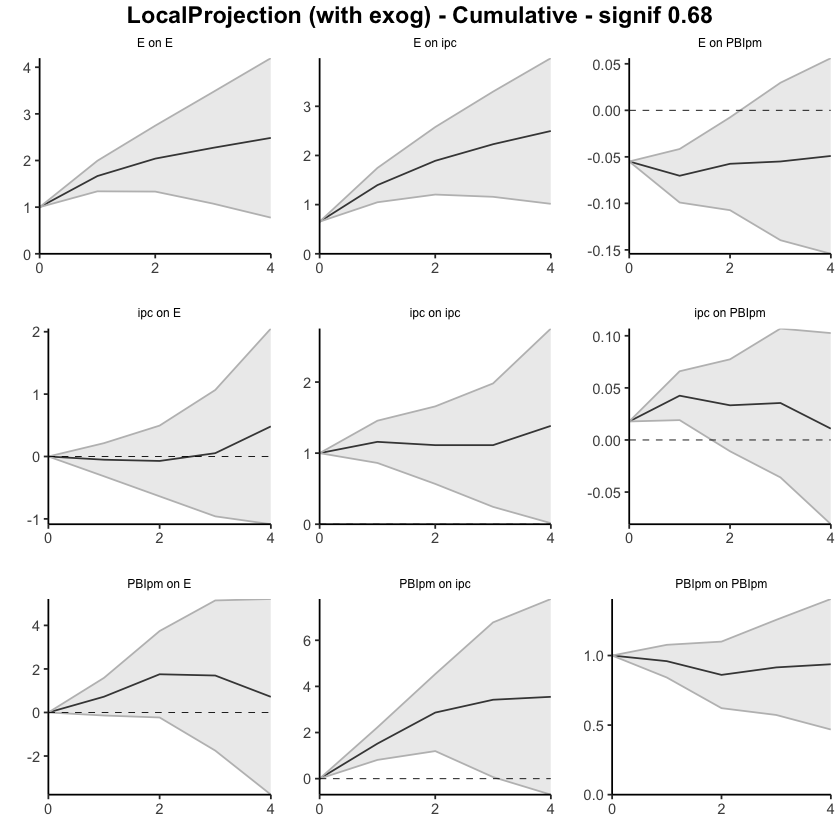

In [42]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.00000000
12,ipc,E,1,0.23360976,-0.07652507,0.54374459
13,ipc,E,2,0.26806680,-0.06755283,0.60368643
14,ipc,E,3,-0.43358776,-0.84171254,-0.02546298
15,ipc,E,4,-0.06568191,-0.48677324,0.35540941


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,0.7609147,-0.1262759,1.6481053
23,PBIpm,E,2,0.4344224,-0.4722390,1.3410838
24,PBIpm,E,3,-0.5942877,-1.6272522,0.4386769
25,PBIpm,E,4,-1.5960750,-2.6674457,-0.5247042


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6256983,0.6256983,0.6256983
2,E,ipc,1,0.8315765,0.5911195,1.0720336
3,E,ipc,2,0.5289884,0.1455410,0.9124359
4,E,ipc,3,0.2720386,-0.1338613,0.6779385
5,E,ipc,4,0.1984237,-0.3629187,0.7597661


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.00000000,0.0000000
27,PBIpm,ipc,1,1.7052337,0.98489249,2.4255748
28,PBIpm,ipc,2,0.7454457,0.07634955,1.4145419
29,PBIpm,ipc,3,-0.3528351,-1.22562605,0.5199559
30,PBIpm,ipc,4,-0.6562161,-1.51672634,0.2042940


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.0532129529,-0.05321295,-0.05321295
7,E,PBIpm,1,-0.0270912924,-0.05826024,0.00407766
8,E,PBIpm,2,0.0099483283,-0.01767190,0.03756856
9,E,PBIpm,3,-0.0007690096,-0.04181875,0.04028073
10,E,PBIpm,4,0.0063751315,-0.02239115,0.03514142


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.040733791,0.040733791,0.0407337911
17,ipc,PBIpm,1,-0.010327285,-0.040670166,0.0200155964
18,ipc,PBIpm,2,-0.027855428,-0.056685525,0.0009746686
19,ipc,PBIpm,3,0.034868717,-0.004926329,0.0746637624
20,ipc,PBIpm,4,0.002603295,-0.031753406,0.0369599970


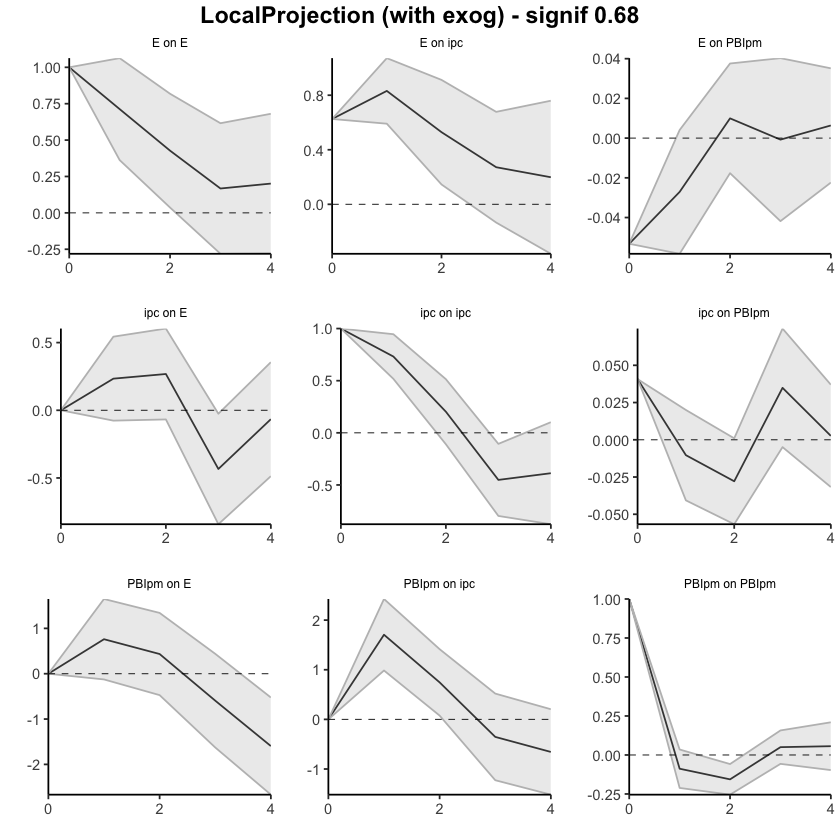

In [43]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 3, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.00000000,0.0000000
12,ipc,E,1,0.233609761,-0.07652507,0.5437446
13,ipc,E,2,0.501676563,-0.14407790,1.1474310
14,ipc,E,3,0.068088803,-0.98579043,1.1219680
15,ipc,E,4,0.002406891,-1.47256367,1.4773775


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,0.7609147,-0.1262759,1.648105
23,PBIpm,E,2,1.1953371,-0.5985149,2.989189
24,PBIpm,E,3,0.6010494,-2.2257670,3.427866
25,PBIpm,E,4,-0.9950255,-4.8932127,2.903162


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6256983,0.6256983,0.6256983
2,E,ipc,1,1.4572749,1.2168178,1.6977319
3,E,ipc,2,1.9862633,1.3623588,2.6101678
4,E,ipc,3,2.2583019,1.2284976,3.2881063
5,E,ipc,4,2.4567256,0.8655789,4.0478724


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.705234,0.9848925,2.425575
28,PBIpm,ipc,2,2.450679,1.0612420,3.840117
29,PBIpm,ipc,3,2.097844,-0.1643840,4.360073
30,PBIpm,ipc,4,1.441628,-1.6811104,4.564367


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05321295,-0.05321295,-0.05321295
7,E,PBIpm,1,-0.08030425,-0.11147320,-0.04913529
8,E,PBIpm,2,-0.07035592,-0.12914510,-0.01156673
9,E,PBIpm,3,-0.07112493,-0.17096385,0.02871400
10,E,PBIpm,4,-0.06474980,-0.19335501,0.06385541


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.040733791,4.073379e-02,0.04073379
17,ipc,PBIpm,1,0.030406506,6.362499e-05,0.06074939
18,ipc,PBIpm,2,0.002551078,-5.662190e-02,0.06172406
19,ipc,PBIpm,3,0.037419795,-6.154823e-02,0.13638782
20,ipc,PBIpm,4,0.040023090,-9.330163e-02,0.17334782


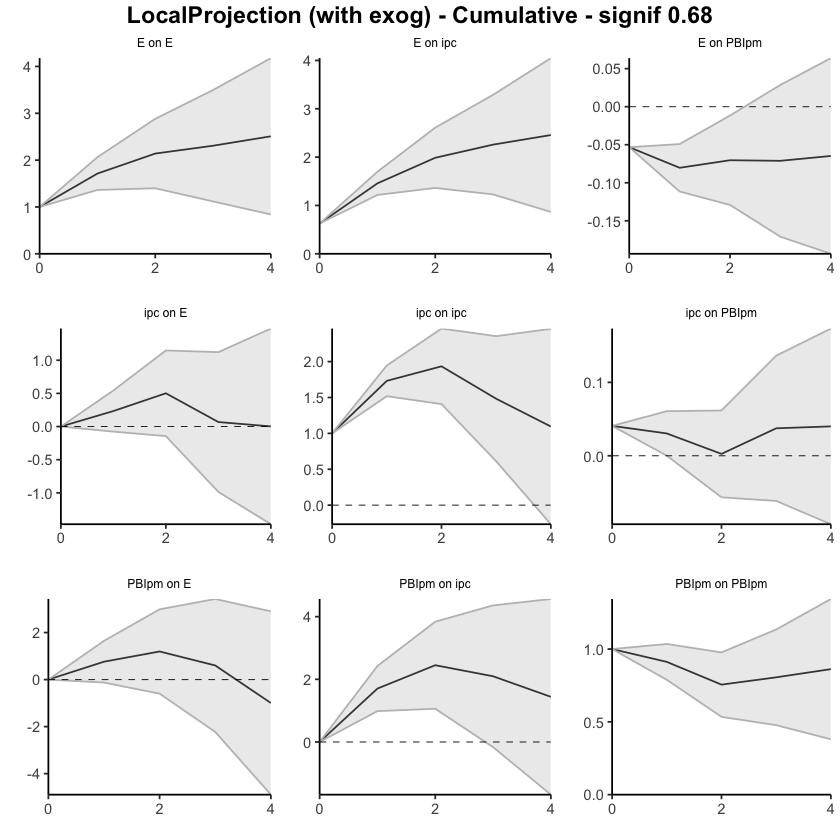

In [44]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 3, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.0000000,0.0000000
12,ipc,E,1,-0.021125516,-0.2765157,0.2342647
13,ipc,E,2,-0.005318014,-0.2677407,0.2571047
14,ipc,E,3,0.103061812,-0.3347275,0.5408511
15,ipc,E,4,0.409390672,-0.1883600,1.0071413


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.000000000
22,PBIpm,E,1,0.8697149,-0.01932849,1.758758273
23,PBIpm,E,2,1.0150280,-0.06709121,2.097147298
24,PBIpm,E,3,-0.2115410,-1.57185882,1.148776744
25,PBIpm,E,4,-1.0915533,-2.18138690,-0.001719657


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6502975,0.65029746,0.6502975
2,E,ipc,1,0.7436757,0.41188717,1.0754641
3,E,ipc,2,0.5001715,0.15575070,0.8445922
4,E,ipc,3,0.3529173,-0.07313297,0.7789677
5,E,ipc,4,0.2829949,-0.10111642,0.6671063


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000000,0.0000000,0.0000000
27,PBIpm,ipc,1,1.598058689,0.8594374,2.3366800
28,PBIpm,ipc,2,1.371094362,0.4318839,2.3103048
29,PBIpm,ipc,3,0.439903578,-1.0947023,1.9745095
30,PBIpm,ipc,4,0.001445188,-0.8402452,0.8431356


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.054202415,-0.054202415,-0.05420242
7,E,PBIpm,1,-0.015608088,-0.043824955,0.01260878
8,E,PBIpm,2,0.012218232,-0.008592325,0.03302879
9,E,PBIpm,3,0.002638964,-0.032371366,0.03764929
10,E,PBIpm,4,0.005853049,-0.016740842,0.02844694


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.017108058,0.017108058,0.017108058
17,ipc,PBIpm,1,0.024151456,0.001240699,0.047062213
18,ipc,PBIpm,2,-0.008897028,-0.028934819,0.011140763
19,ipc,PBIpm,3,0.004052062,-0.023698027,0.031802152
20,ipc,PBIpm,4,-0.020674170,-0.042556424,0.001208083


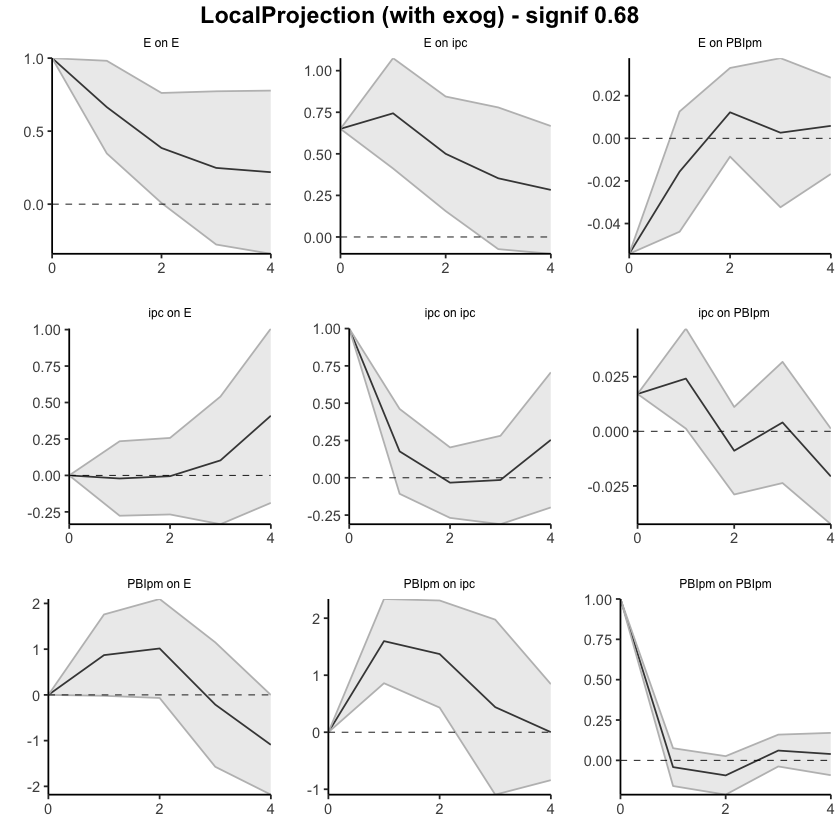

In [45]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.02112552,-0.2765157,0.2342647
13,ipc,E,2,-0.02644353,-0.5442564,0.4913694
14,ipc,E,3,0.07661828,-0.8789839,1.0322205
15,ipc,E,4,0.48600895,-1.0673439,2.0393618


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.000000
22,PBIpm,E,1,0.8697149,-0.01932849,1.758758
23,PBIpm,E,2,1.8847429,-0.08641970,3.855906
24,PBIpm,E,3,1.6732019,-1.65827852,5.004682
25,PBIpm,E,4,0.5816486,-3.83966542,5.002963


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6502975,0.6502975,0.6502975
2,E,ipc,1,1.3939731,1.0621846,1.7257616
3,E,ipc,2,1.8941446,1.2179353,2.5703538
4,E,ipc,3,2.2470619,1.1448024,3.3493215
5,E,ipc,4,2.5300569,1.0436859,4.0164278


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.598059,0.8594374,2.336680
28,PBIpm,ipc,2,2.969153,1.2913213,4.646985
29,PBIpm,ipc,3,3.409057,0.1966189,6.621494
30,PBIpm,ipc,4,3.410502,-0.6436263,7.464630


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05420242,-0.05420242,-0.054202415
7,E,PBIpm,1,-0.06981050,-0.09802737,-0.041593637
8,E,PBIpm,2,-0.05759227,-0.10661970,-0.008564847
9,E,PBIpm,3,-0.05495331,-0.13899106,0.029084447
10,E,PBIpm,4,-0.04910026,-0.15573190,0.057531387


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.01710806,0.01710806,0.01710806
17,ipc,PBIpm,1,0.04125951,0.01834876,0.06417027
18,ipc,PBIpm,2,0.03236249,-0.01058606,0.07531103
19,ipc,PBIpm,3,0.03641455,-0.03428409,0.10711318
20,ipc,PBIpm,4,0.01574038,-0.07684051,0.10832127


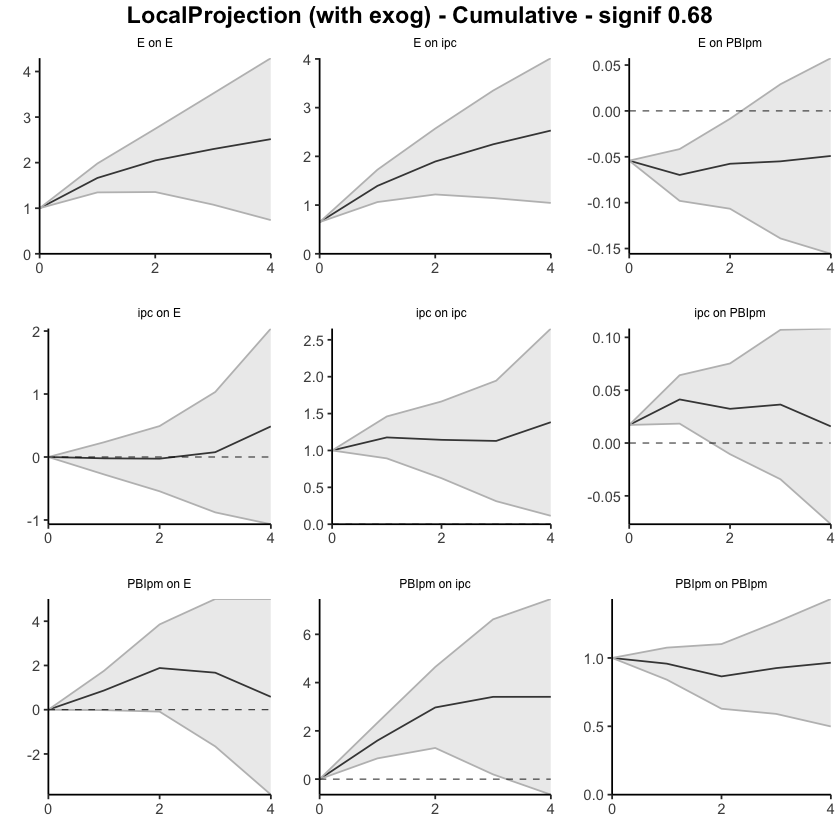

In [46]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,0.1579038,-0.1701867,0.48599421
13,ipc,E,2,-0.1880227,-0.5781456,0.20210023
14,ipc,E,3,-0.6992379,-1.3257344,-0.07274138
15,ipc,E,4,-0.1479824,-0.6133155,0.31735076


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.000000000
22,PBIpm,E,1,0.9666308,0.04574806,1.887513496
23,PBIpm,E,2,0.7939116,-0.17234137,1.760164489
24,PBIpm,E,3,-1.0841727,-2.15882907,-0.009516378
25,PBIpm,E,4,-1.9965638,-3.51013022,-0.482997413


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6439907,0.6439907,0.6439907
2,E,ipc,1,0.8222641,0.5631430,1.0813851
3,E,ipc,2,0.4800782,-0.0488126,1.0089690
4,E,ipc,3,0.2254318,-0.4585446,0.9094082
5,E,ipc,4,0.1768847,-0.4586169,0.8123864


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.00000000
27,PBIpm,ipc,1,1.9665554,1.1626517,2.77045915
28,PBIpm,ipc,2,1.1962293,0.4596972,1.93276132
29,PBIpm,ipc,3,-0.3818712,-1.3444873,0.58074499
30,PBIpm,ipc,4,-1.0862762,-2.2714917,0.09893941


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.0521979918,-0.05219799,-0.052197992
7,E,PBIpm,1,-0.0258570389,-0.05391493,0.002200855
8,E,PBIpm,2,0.0079481775,-0.02364308,0.039539432
9,E,PBIpm,3,0.0003984678,-0.04527559,0.046072526
10,E,PBIpm,4,0.0041078318,-0.02078634,0.029001999


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.040390943,0.040390943,0.04039094
17,ipc,PBIpm,1,-0.017218394,-0.046069911,0.01163312
18,ipc,PBIpm,2,-0.017461887,-0.048887455,0.01396368
19,ipc,PBIpm,3,0.036623535,-0.006094755,0.07934182
20,ipc,PBIpm,4,-0.009184849,-0.037135696,0.01876600


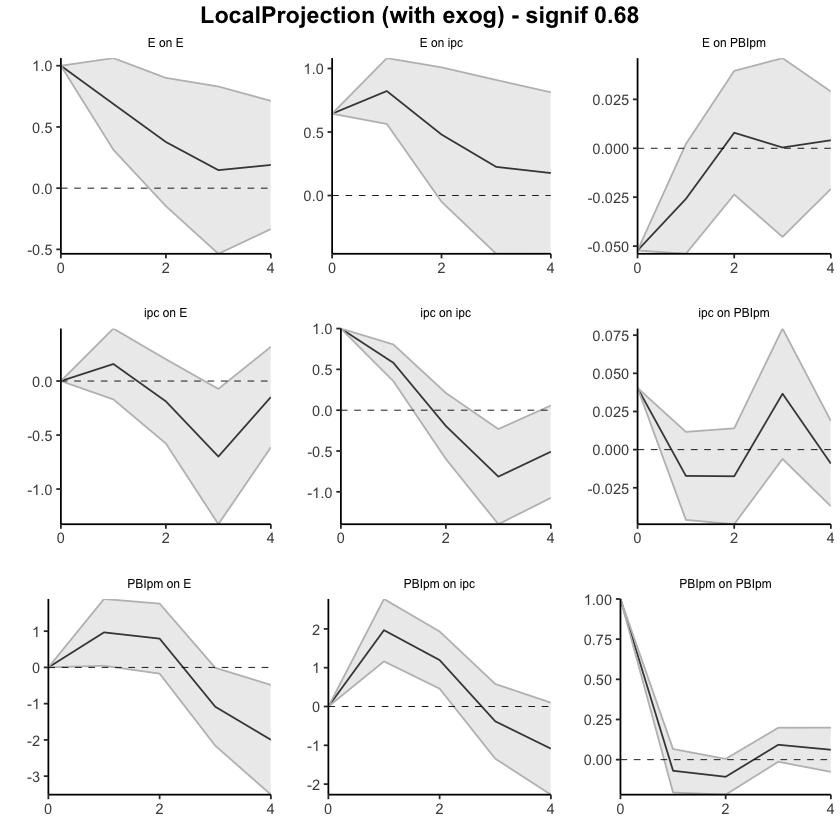

In [47]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.15790375,-0.1701867,0.4859942
13,ipc,E,2,-0.03011895,-0.7483323,0.6880944
14,ipc,E,3,-0.72935684,-2.0740667,0.6153531
15,ipc,E,4,-0.87733922,-2.6873823,0.9327038


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.000000
22,PBIpm,E,1,0.9666308,0.04574806,1.887513
23,PBIpm,E,2,1.7605423,-0.12659332,3.647678
24,PBIpm,E,3,0.6763696,-2.28542239,3.638162
25,PBIpm,E,4,-1.3201942,-5.79555261,3.155164


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6439907,0.6439907,0.6439907
2,E,ipc,1,1.4662548,1.2071337,1.7253758
3,E,ipc,2,1.9463330,1.1583211,2.7343448
4,E,ipc,3,2.1717648,0.6997766,3.6437531
5,E,ipc,4,2.3486496,0.2411597,4.4561395


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.966555,1.1626517,2.770459
28,PBIpm,ipc,2,3.162785,1.6223489,4.703220
29,PBIpm,ipc,3,2.780914,0.2778616,5.283965
30,PBIpm,ipc,4,1.694637,-1.9936301,5.382905


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05219799,-0.05219799,-0.05219799
7,E,PBIpm,1,-0.07805503,-0.10611292,-0.04999714
8,E,PBIpm,2,-0.07010685,-0.12975600,-0.01045770
9,E,PBIpm,3,-0.06970839,-0.17503159,0.03561482
10,E,PBIpm,4,-0.06560055,-0.19581793,0.06461682


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.040390943,0.040390943,0.04039094
17,ipc,PBIpm,1,0.023172549,-0.005678968,0.05202407
18,ipc,PBIpm,2,0.005710662,-0.054566423,0.06598775
19,ipc,PBIpm,3,0.042334197,-0.060661178,0.14532957
20,ipc,PBIpm,4,0.033149348,-0.097796875,0.16409557


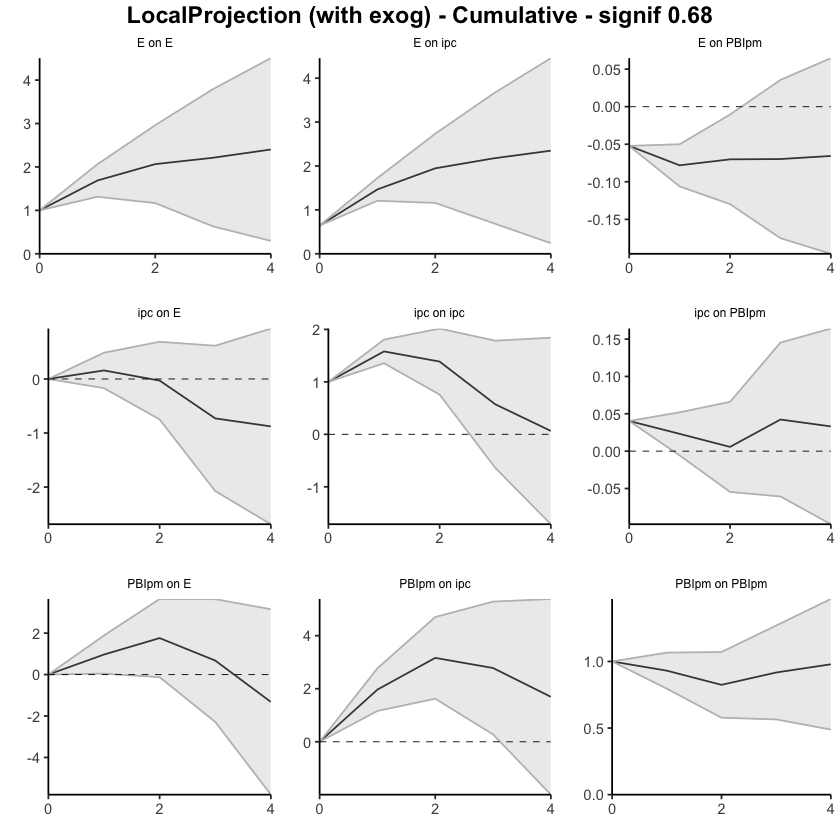

In [48]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.00000000
12,ipc,E,1,0.31203193,0.02968890,0.59437496
13,ipc,E,2,0.28809358,-0.05194706,0.62813422
14,ipc,E,3,-0.45226795,-0.85535645,-0.04917946
15,ipc,E,4,-0.09201895,-0.58649104,0.40245313


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,0.7542603,-0.1585261,1.6670467
23,PBIpm,E,2,0.1848615,-0.8287746,1.1984976
24,PBIpm,E,3,-0.9924375,-2.0103388,0.0254639
25,PBIpm,E,4,-1.7717331,-2.9600046,-0.5834615


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6311501,0.6311501,0.6311501
2,E,ipc,1,0.8265893,0.6296664,1.0235122
3,E,ipc,2,0.4991030,0.1673755,0.8308305
4,E,ipc,3,0.2390644,-0.1343145,0.6124434
5,E,ipc,4,0.1748546,-0.5409460,0.8906552


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIpm,ipc,1,1.6302667,0.9764760,2.2840573
28,PBIpm,ipc,2,0.5152553,-0.2077087,1.2382192
29,PBIpm,ipc,3,-0.7212936,-1.5891890,0.1466019
30,PBIpm,ipc,4,-0.8823238,-1.8658054,0.1011578


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.052182728,-0.05218273,-0.052182728
7,E,PBIpm,1,-0.026852084,-0.05628025,0.002576081
8,E,PBIpm,2,0.006823686,-0.02306768,0.036715048
9,E,PBIpm,3,0.000321550,-0.03916007,0.039803173
10,E,PBIpm,4,0.005326658,-0.02713881,0.037792125


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.0383189941,0.038318994,0.038318994
17,ipc,PBIpm,1,-0.0095567226,-0.037903647,0.018790202
18,ipc,PBIpm,2,-0.0272348361,-0.057401612,0.002931939
19,ipc,PBIpm,3,0.0352936581,-0.002231396,0.072818712
20,ipc,PBIpm,4,0.0008872901,-0.034985092,0.036759673


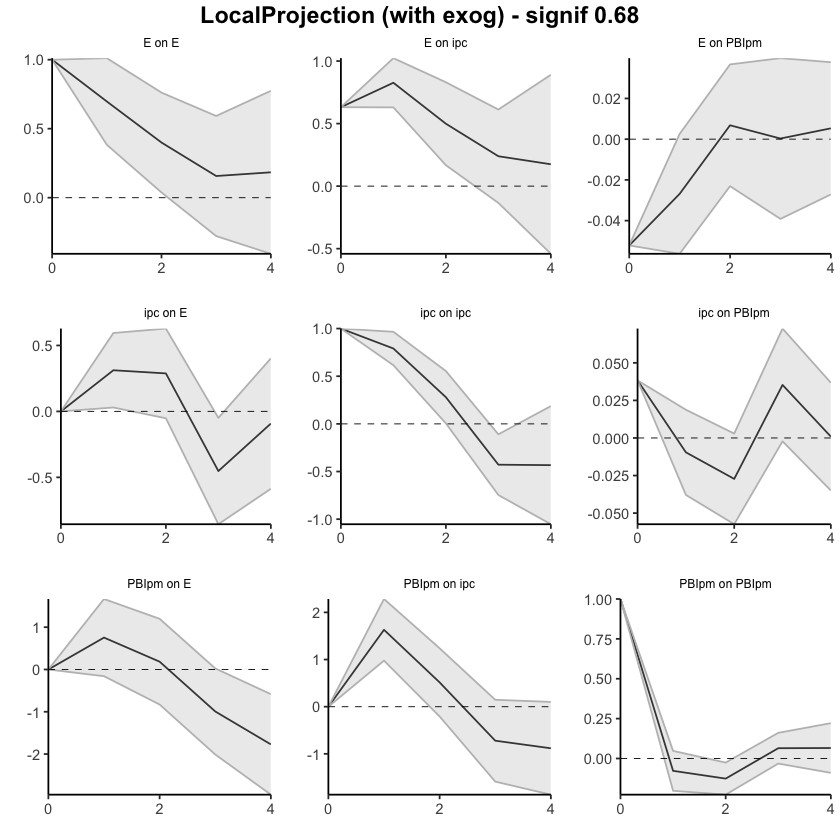

In [50]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 3, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.000000
12,ipc,E,1,0.3120319,0.02968890,0.594375
13,ipc,E,2,0.6001255,-0.02225816,1.222509
14,ipc,E,3,0.1478576,-0.87761461,1.173330
15,ipc,E,4,0.0558386,-1.46410564,1.575783


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.00000000,0.0000000,0.000000
22,PBIpm,E,1,0.75426031,-0.1585261,1.667047
23,PBIpm,E,2,0.93912182,-0.9873007,2.865544
24,PBIpm,E,3,-0.05331563,-2.9976395,2.891008
25,PBIpm,E,4,-1.82504868,-5.9576441,2.307547


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6311501,0.6311501,0.6311501
2,E,ipc,1,1.4577394,1.2608165,1.6546622
3,E,ipc,2,1.9568424,1.4281921,2.4854927
4,E,ipc,3,2.1959069,1.2938776,3.0979361
5,E,ipc,4,2.3707615,0.7529316,3.9885913


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.6302667,0.9764760,2.284057
28,PBIpm,ipc,2,2.1455220,0.7687674,3.522277
29,PBIpm,ipc,3,1.4242284,-0.8204217,3.668878
30,PBIpm,ipc,4,0.5419046,-2.6862271,3.770036


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05218273,-0.05218273,-0.05218273
7,E,PBIpm,1,-0.07903481,-0.10846298,-0.04960665
8,E,PBIpm,2,-0.07221113,-0.13153065,-0.01289160
9,E,PBIpm,3,-0.07188958,-0.17069073,0.02691157
10,E,PBIpm,4,-0.06656292,-0.19782954,0.06470370


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.038318994,0.0383189941,0.03831899
17,ipc,PBIpm,1,0.028762272,0.0004153468,0.05710920
18,ipc,PBIpm,2,0.001527435,-0.0569862647,0.06004114
19,ipc,PBIpm,3,0.036821094,-0.0592176610,0.13285985
20,ipc,PBIpm,4,0.037708384,-0.0942027533,0.16961952


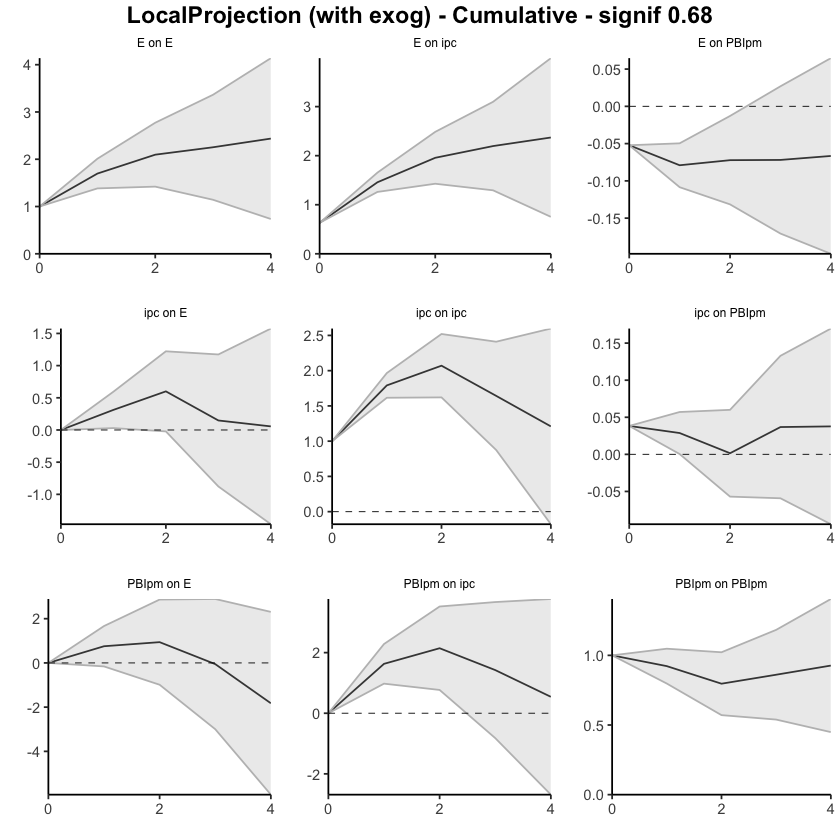

In [49]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 3, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

### 1935-1974. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,-0.13563501,-0.3190582,0.04778817
38,ipc,E,2,-0.09523029,-0.1749466,-0.01551401
39,ipc,E,3,0.30147373,0.2055901,0.39735732
40,ipc,E,4,0.31839539,0.2201953,0.41659548


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.469433,0.9382117,2.000654
53,PBIpm,E,2,1.619706,0.5076335,2.731779
54,PBIpm,E,3,1.228580,0.4103871,2.046774
55,PBIpm,E,4,1.006042,0.1483061,1.863778


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.34549253,-0.34549253,-0.3454925
2,Psoja_USA,E,1,0.07666990,0.01557341,0.1377664
3,Psoja_USA,E,2,-0.06540293,-0.23499555,0.1041897
4,Psoja_USA,E,3,0.02248151,-0.11917469,0.1641377
5,Psoja_USA,E,4,0.12977862,-0.05254361,0.3121008


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.048968690,0.048968690,0.048968690
12,Psoja_USA,PBIpm,1,-0.009601381,-0.033325773,0.014123010
13,Psoja_USA,PBIpm,2,-0.014729347,-0.037486761,0.008028066
14,Psoja_USA,PBIpm,3,0.022658700,-0.008249125,0.053566525
15,Psoja_USA,PBIpm,4,0.061518475,0.022690582,0.100346368


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.00000000,0.0000000
17,E,Psoja_USA,1,0.13600983,-0.27919502,0.5512147
18,E,Psoja_USA,2,0.17546731,-0.09747501,0.4484096
19,E,Psoja_USA,3,0.05008132,-0.26990796,0.3700706
20,E,Psoja_USA,4,-0.31232580,-0.49526202,-0.1293896


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Psoja_USA,1,0.04563164,-0.14279205,0.2340553
33,ipc,Psoja_USA,2,0.04999653,-0.06504124,0.1650343
34,ipc,Psoja_USA,3,-0.61739659,-0.80230655,-0.4324866
35,ipc,Psoja_USA,4,-0.17066068,-0.19261489,-0.1487065


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Psoja_USA,1,0.02014211,-0.5293099,0.5695941
48,PBIpm,Psoja_USA,2,-1.55395481,-2.1486324,-0.9592773
49,PBIpm,Psoja_USA,3,0.11195487,-0.5918760,0.8157857
50,PBIpm,Psoja_USA,4,0.45297753,-0.3169459,1.2229010


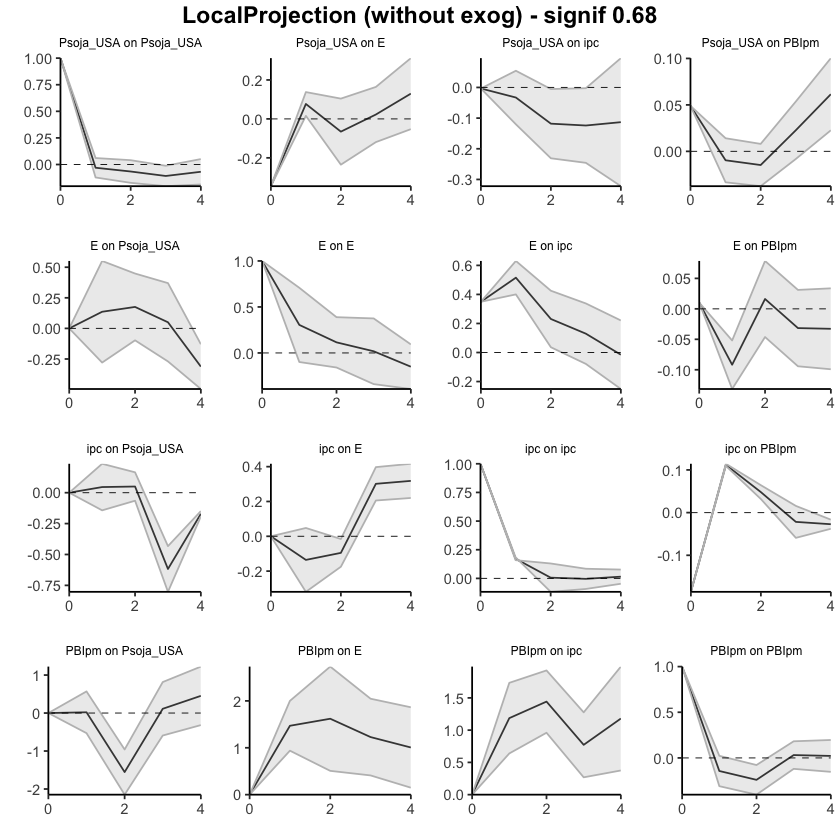

In [51]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.00000000
37,ipc,E,1,-0.13563501,-0.31905819,0.04778817
38,ipc,E,2,-0.23086530,-0.49400476,0.03227416
39,ipc,E,3,0.07060843,-0.28841461,0.42963147
40,ipc,E,4,0.38900382,-0.06821931,0.84622695


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.469433,0.9382117,2.000654
53,PBIpm,E,2,3.089139,1.4458452,4.732433
54,PBIpm,E,3,4.317719,1.8562323,6.779207
55,PBIpm,E,4,5.323762,2.0045384,8.642985


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.3454925,-0.3454925,-0.34549253
2,Psoja_USA,E,1,-0.2688226,-0.3299191,-0.20772615
3,Psoja_USA,E,2,-0.3342256,-0.5649147,-0.10353645
4,Psoja_USA,E,3,-0.3117440,-0.6840894,0.06060127
5,Psoja_USA,E,4,-0.1819654,-0.7366330,0.37270211


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.04896869,0.048968690,0.04896869
12,Psoja_USA,PBIpm,1,0.03936731,0.015642917,0.06309170
13,Psoja_USA,PBIpm,2,0.02463796,-0.021843844,0.07111977
14,Psoja_USA,PBIpm,3,0.04729666,-0.030092969,0.12468629
15,Psoja_USA,PBIpm,4,0.10881514,-0.007402387,0.22503266


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.000000,0.0000000
17,E,Psoja_USA,1,0.13600983,-0.279195,0.5512147
18,E,Psoja_USA,2,0.31147714,-0.376670,0.9996243
19,E,Psoja_USA,3,0.36155847,-0.646578,1.3696949
20,E,Psoja_USA,4,0.04923266,-1.141840,1.2403053


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.0000000,0.0000000
32,ipc,Psoja_USA,1,0.04563164,-0.1427920,0.2340553
33,ipc,Psoja_USA,2,0.09562817,-0.2078333,0.3990896
34,ipc,Psoja_USA,3,-0.52176842,-1.0101398,-0.0333970
35,ipc,Psoja_USA,4,-0.69242910,-1.2027547,-0.1821035


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Psoja_USA,1,0.02014211,-0.5293099,0.5695941
48,PBIpm,Psoja_USA,2,-1.53381270,-2.6779423,-0.3896831
49,PBIpm,Psoja_USA,3,-1.42185783,-3.2698182,0.4261026
50,PBIpm,Psoja_USA,4,-0.96888029,-3.5867641,1.6490036


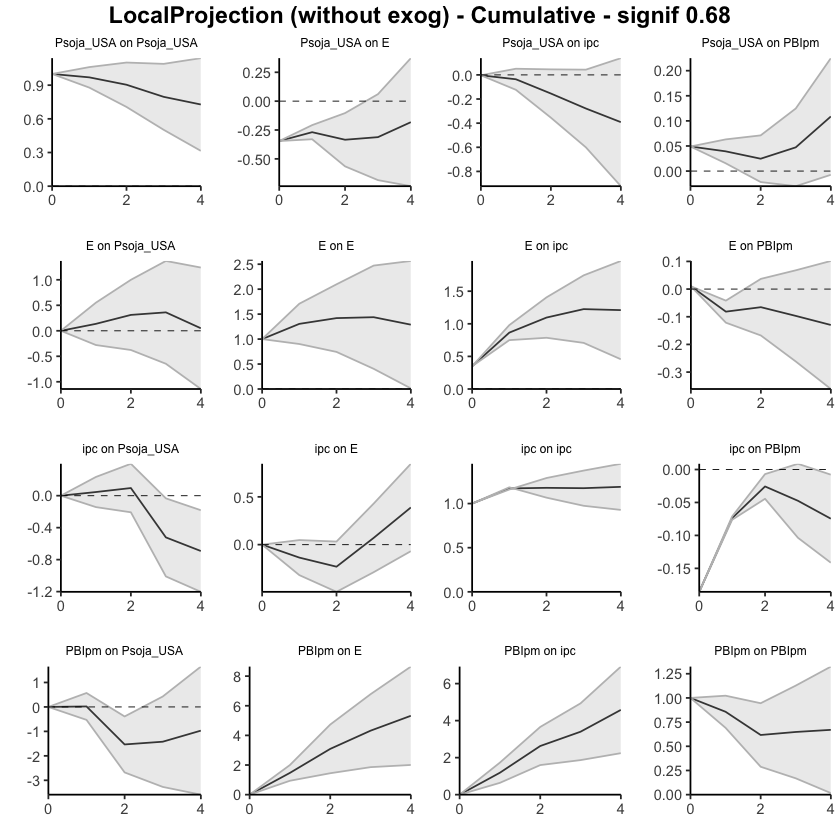

In [52]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,-0.06543370,-0.2504126,0.11954519
38,ipc,E,2,-0.07554575,-0.1730681,0.02197662
39,ipc,E,3,0.31327869,0.2028192,0.42373823
40,ipc,E,4,0.34075441,0.2213153,0.46019356


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,1.5946696,1.1573354,2.032004
53,PBIpm,E,2,1.4675652,0.4571322,2.477998
54,PBIpm,E,3,1.0966403,0.3909720,1.802309
55,PBIpm,E,4,0.9821962,0.2094532,1.754939


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.151012459,-0.15101246,-0.15101246
2,Pmaíz_USA,E,1,0.004329803,-0.02432994,0.03298954
3,Pmaíz_USA,E,2,0.012116353,-0.07674569,0.10097840
4,Pmaíz_USA,E,3,0.070170773,0.01958137,0.12076018
5,Pmaíz_USA,E,4,0.050530839,-0.00339829,0.10445997


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.017489349,0.017489349,0.017489349
12,Pmaíz_USA,PBIpm,1,0.016503746,0.004465749,0.028541743
13,Pmaíz_USA,PBIpm,2,0.001069274,-0.016285362,0.018423910
14,Pmaíz_USA,PBIpm,3,-0.029686278,-0.064829574,0.005457018
15,Pmaíz_USA,PBIpm,4,0.073851240,0.040768340,0.106934140


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,-0.07209462,-0.4288720,0.2846827
18,E,Pmaíz_USA,2,0.32345469,-0.1151157,0.7620251
19,E,Pmaíz_USA,3,0.03129771,-0.3252630,0.3878584
20,E,Pmaíz_USA,4,-0.08772859,-0.2786604,0.1032032


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.0000000,0.00000000,0.0000000
32,ipc,Pmaíz_USA,1,0.3703743,0.06906407,0.6716845
33,ipc,Pmaíz_USA,2,-0.2394257,-0.29660230,-0.1822491
34,ipc,Pmaíz_USA,3,-0.2520789,-0.36275217,-0.1414056
35,ipc,Pmaíz_USA,4,-0.1974145,-0.26673497,-0.1280940


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Pmaíz_USA,1,0.07874400,-0.5988303,0.7563183
48,PBIpm,Pmaíz_USA,2,-0.94620224,-1.5855143,-0.3068902
49,PBIpm,Pmaíz_USA,3,0.09757358,-0.7508908,0.9460380
50,PBIpm,Pmaíz_USA,4,-0.24583520,-1.1474252,0.6557548


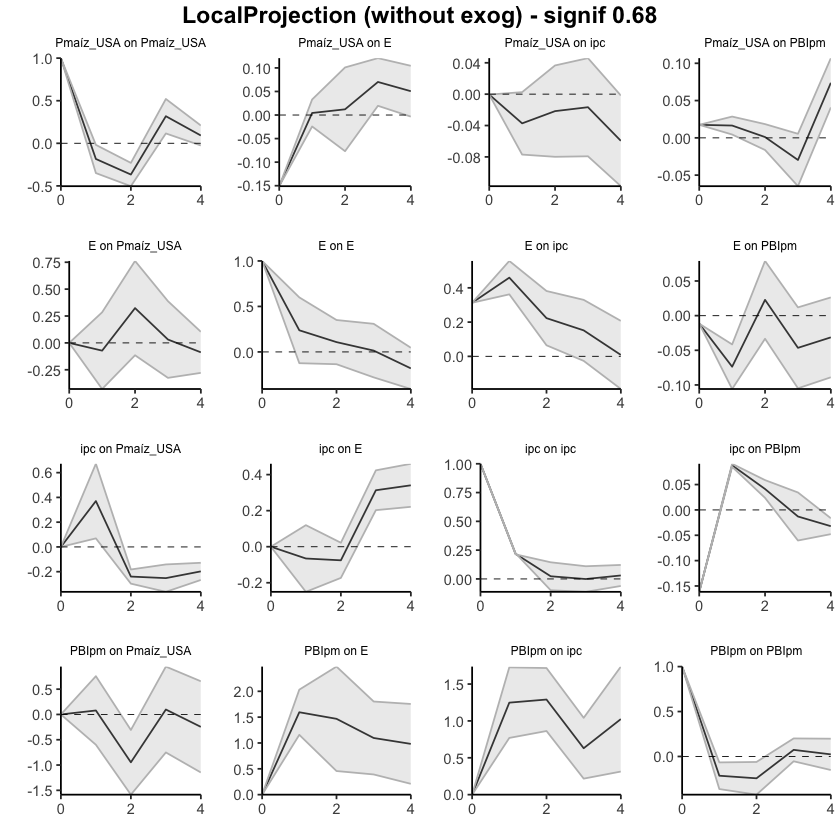

In [53]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000000,0.0000000
37,ipc,E,1,-0.0654337,-0.2504125844,0.1195452
38,ipc,E,2,-0.1409794,-0.4234806910,0.1415218
39,ipc,E,3,0.1722992,-0.2206615392,0.5652600
40,ipc,E,4,0.5130537,0.0006537145,1.0254536


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.000000,0.000000
52,PBIpm,E,1,1.594670,1.157335,2.032004
53,PBIpm,E,2,3.062235,1.614468,4.510002
54,PBIpm,E,3,4.158875,2.005440,6.312311
55,PBIpm,E,4,5.141071,2.214893,8.067250


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.15101246,-0.1510125,-0.15101246
2,Pmaíz_USA,E,1,-0.14668266,-0.1753424,-0.11802291
3,Pmaíz_USA,E,2,-0.13456630,-0.2520881,-0.01704452
4,Pmaíz_USA,E,3,-0.06439553,-0.2325067,0.10371566
5,Pmaíz_USA,E,4,-0.01386469,-0.2359050,0.20817563


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.017489349,0.017489349,0.01748935
12,Pmaíz_USA,PBIpm,1,0.033993095,0.021955098,0.04603109
13,Pmaíz_USA,PBIpm,2,0.035062369,0.005669735,0.06445500
14,Pmaíz_USA,PBIpm,3,0.005376091,-0.059159839,0.06991202
15,Pmaíz_USA,PBIpm,4,0.079227331,-0.018391499,0.17684616


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,-0.07209462,-0.4288720,0.2846827
18,E,Pmaíz_USA,2,0.25136007,-0.5439877,1.0467078
19,E,Pmaíz_USA,3,0.28265779,-0.8692506,1.4345662
20,E,Pmaíz_USA,4,0.19492919,-1.1479110,1.5377694


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.0000000,0.00000000,0.0000000
32,ipc,Pmaíz_USA,1,0.3703743,0.06906407,0.6716845
33,ipc,Pmaíz_USA,2,0.1309486,-0.22753823,0.4894354
34,ipc,Pmaíz_USA,3,-0.1211303,-0.59029041,0.3480298
35,ipc,Pmaíz_USA,4,-0.3185448,-0.85702538,0.2199358


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Pmaíz_USA,1,0.0787440,-0.5988303,0.7563183
48,PBIpm,Pmaíz_USA,2,-0.8674582,-2.1843446,0.4494281
49,PBIpm,Pmaíz_USA,3,-0.7698847,-2.9352355,1.3954662
50,PBIpm,Pmaíz_USA,4,-1.0157199,-4.0826607,2.0512210


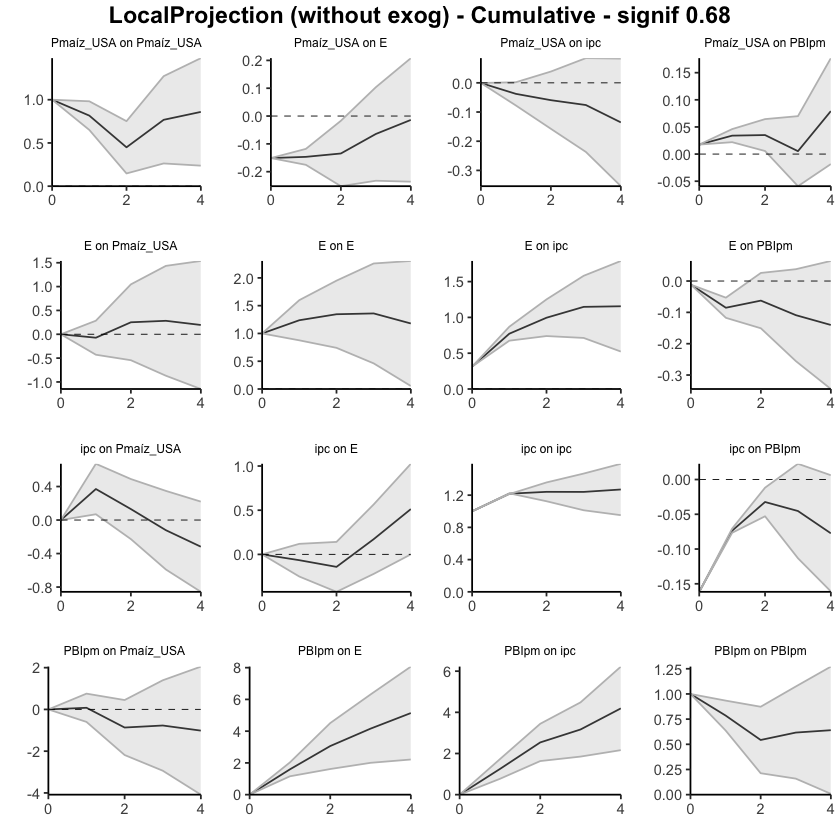

In [54]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,-0.3447747,-0.47640669,-0.2131427
38,ipc,E,2,-0.3829191,-0.44161908,-0.3242192
39,ipc,E,3,0.1912907,0.01305529,0.3695261
40,ipc,E,4,0.8379493,0.85168586,0.8242127


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,2.808324,2.3024617,3.314187
53,PBIpm,E,2,1.029851,-0.1191928,2.178894
54,PBIpm,E,3,-4.239193,-5.7835058,-2.694881
55,PBIpm,E,4,2.162912,0.2980922,4.027732


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.8278306270,-0.8278306,-0.8278306
2,Pmaíz_USA,E,1,0.4808687412,0.3571906,0.6045469
3,Pmaíz_USA,E,2,-0.0003028777,-0.1629891,0.1623834
4,Pmaíz_USA,E,3,-0.5991906640,-0.6287275,-0.5696538
5,Pmaíz_USA,E,4,0.4483661838,0.1487509,0.7479815


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.066487757,0.06648776,0.06648776
12,Pmaíz_USA,PBIpm,1,-0.005141651,0.05114910,-0.06143240
13,Pmaíz_USA,PBIpm,2,-0.004093944,0.05967043,-0.06785832
14,Pmaíz_USA,PBIpm,3,0.165171274,-0.07476598,0.40510853
15,Pmaíz_USA,PBIpm,4,-0.041338340,-0.05728208,-0.02539460


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,-0.06679111,-1.3292575,1.1956753
18,E,Pmaíz_USA,2,0.19109725,-0.8372781,1.2194726
19,E,Pmaíz_USA,3,0.21424063,-0.2243346,0.6528159
20,E,Pmaíz_USA,4,-0.18780107,-0.7041308,0.3285286


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
32,ipc,Pmaíz_USA,1,0.6495041,0.6005998,0.6984085
33,ipc,Pmaíz_USA,2,-0.1039293,-0.5851531,0.3772945
34,ipc,Pmaíz_USA,3,-0.6052147,-0.7738615,-0.4365679
35,ipc,Pmaíz_USA,4,-0.2082286,-0.2710980,-0.1453592


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.000000,0.0000000,0.0000000
47,PBIpm,Pmaíz_USA,1,3.251398,0.6002268,5.9025690
48,PBIpm,Pmaíz_USA,2,-2.418800,-4.0600725,-0.7775265
49,PBIpm,Pmaíz_USA,3,2.285374,0.1921377,4.3786103
50,PBIpm,Pmaíz_USA,4,2.949560,-0.6823492,6.5814698


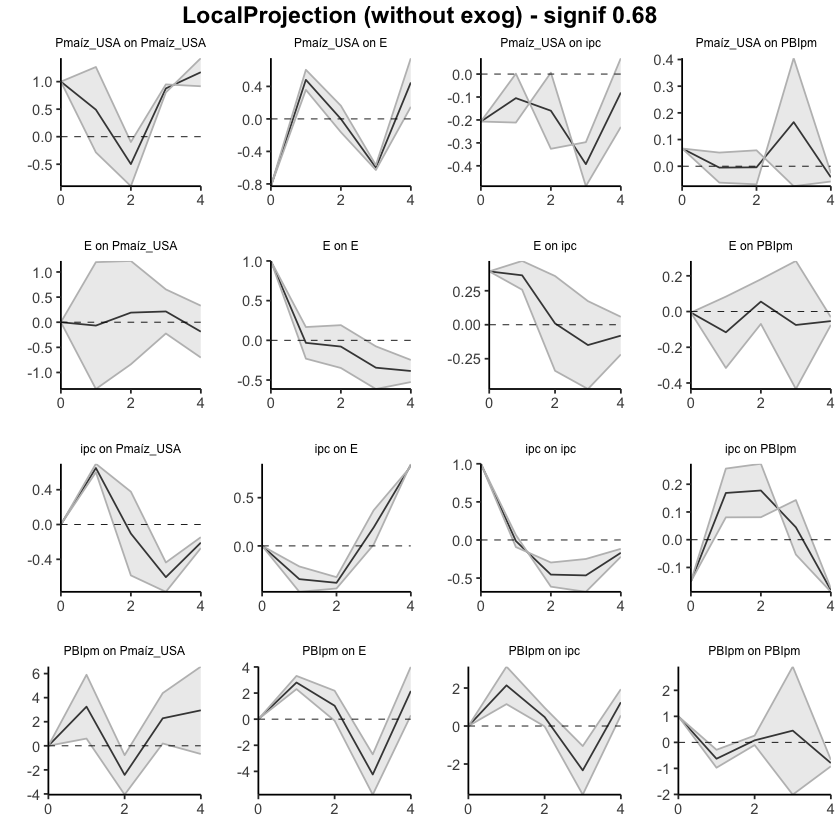

In [55]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,-0.3447747,-0.47640669,-0.2131427
38,ipc,E,2,-0.7276938,-0.91802576,-0.5373619
39,ipc,E,3,-0.5364031,-0.90497047,-0.1678358
40,ipc,E,4,0.3015462,-0.05328462,0.6563769


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.000000,0.000000
52,PBIpm,E,1,2.8083245,2.302462,3.314187
53,PBIpm,E,2,3.8381752,2.183269,5.493082
54,PBIpm,E,3,-0.4010182,-3.600237,2.798201
55,PBIpm,E,4,1.7618941,-3.302145,6.825933


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.8278306,-0.8278306,-0.82783063
2,Pmaíz_USA,E,1,-0.3469619,-0.4706400,-0.22328374
3,Pmaíz_USA,E,2,-0.3472648,-0.6336291,-0.06090038
4,Pmaíz_USA,E,3,-0.9464554,-1.2623567,-0.63055419
5,Pmaíz_USA,E,4,-0.4980892,-1.1136058,0.11742729


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.06648776,0.06648776,0.066487757
12,Pmaíz_USA,PBIpm,1,0.06134611,0.11763686,0.005055352
13,Pmaíz_USA,PBIpm,2,0.05725216,0.17730729,-0.062802971
14,Pmaíz_USA,PBIpm,3,0.22242344,0.10254131,0.342305558
15,Pmaíz_USA,PBIpm,4,0.18108510,0.04525923,0.316910959


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.000000,0.000000
17,E,Pmaíz_USA,1,-0.06679111,-1.329258,1.195675
18,E,Pmaíz_USA,2,0.12430614,-2.166536,2.415148
19,E,Pmaíz_USA,3,0.33854677,-2.390870,3.067964
20,E,Pmaíz_USA,4,0.15074570,-3.095001,3.396492


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Pmaíz_USA,1,0.64950413,0.60059976,0.6984085
33,ipc,Pmaíz_USA,2,0.54557481,0.01544666,1.0757030
34,ipc,Pmaíz_USA,3,-0.05963987,-0.75841485,0.6391351
35,ipc,Pmaíz_USA,4,-0.26786847,-1.02951281,0.4937759


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.0000000,0.0000000,0.000000
47,PBIpm,Pmaíz_USA,1,3.2513979,0.6002268,5.902569
48,PBIpm,Pmaíz_USA,2,0.8325984,-3.4598457,5.125043
49,PBIpm,Pmaíz_USA,3,3.1179725,-3.2677079,9.503653
50,PBIpm,Pmaíz_USA,4,6.0675327,-3.9500572,16.085123


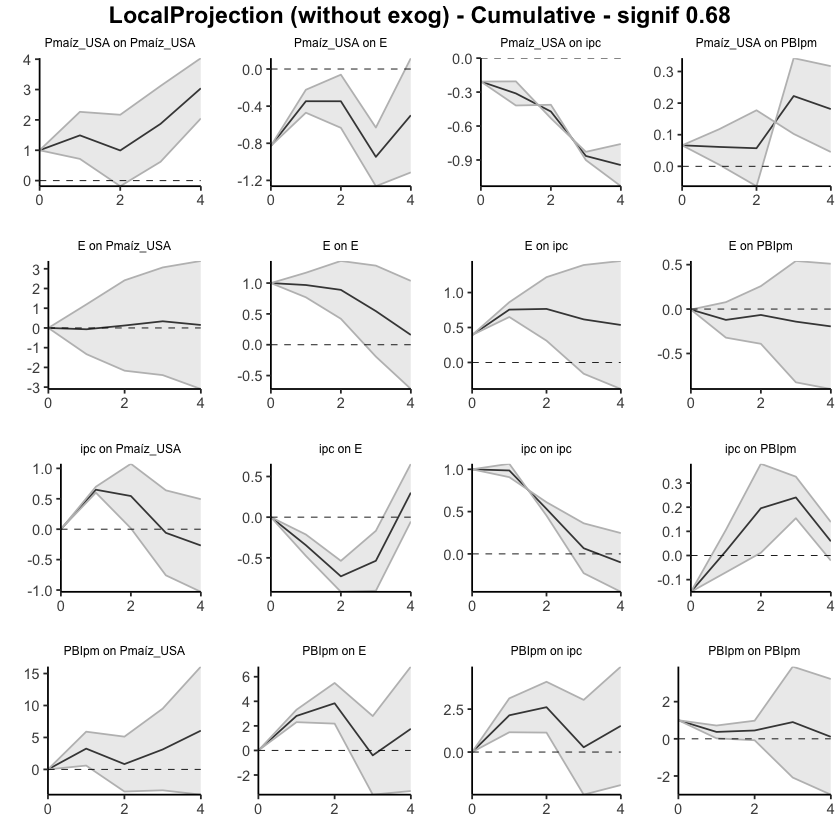

In [56]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.1369399,-0.2974759,0.02359608
38,ipc,E,2,-0.1359240,-0.2189626,-0.05288531
39,ipc,E,3,0.2934005,0.2006309,0.38617011
40,ipc,E,4,0.3048617,0.2001312,0.40959224


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,1.5598728,1.0950122,2.024733
53,PBIpm,E,2,1.4384518,0.5198727,2.357031
54,PBIpm,E,3,1.1253051,0.3945337,1.856076
55,PBIpm,E,4,0.9638388,0.1947035,1.732974


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.39636609,-0.396366092,-0.39636609
2,Ptrigo_USA,E,1,0.03844586,-0.002011232,0.07890295
3,Ptrigo_USA,E,2,0.14082315,-0.025580761,0.30722706
4,Ptrigo_USA,E,3,0.09135731,-0.082026365,0.26474098
5,Ptrigo_USA,E,4,0.22155139,0.020094064,0.42300871


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.03606457,0.03606457,0.036064567
12,Ptrigo_USA,PBIpm,1,0.01195752,-0.01905127,0.042966318
13,Ptrigo_USA,PBIpm,2,-0.01716051,-0.03751947,0.003198445
14,Ptrigo_USA,PBIpm,3,0.01288429,-0.01552057,0.041289143
15,Ptrigo_USA,PBIpm,4,0.06793406,0.04275390,0.093114220


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000000,0.0000000
17,E,Ptrigo_USA,1,0.30785181,-0.0008286156,0.6165322
18,E,Ptrigo_USA,2,0.23960273,-0.2295086843,0.7087141
19,E,Ptrigo_USA,3,0.03224764,-0.1596263912,0.2241217
20,E,Ptrigo_USA,4,-0.14246095,-0.4183403734,0.1334185


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.04761987,-0.1207070,0.02546731
33,ipc,Ptrigo_USA,2,-0.15972926,-0.2135799,-0.10587866
34,ipc,Ptrigo_USA,3,-0.28675576,-0.3764608,-0.19705068
35,ipc,Ptrigo_USA,4,-0.29980356,-0.3454228,-0.25418431


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.2577619,-0.7491698,0.2336461
48,PBIpm,Ptrigo_USA,2,0.1392973,-0.6717731,0.9503677
49,PBIpm,Ptrigo_USA,3,-0.1593962,-0.6993657,0.3805733
50,PBIpm,Ptrigo_USA,4,-0.5503434,-1.2792261,0.1785393


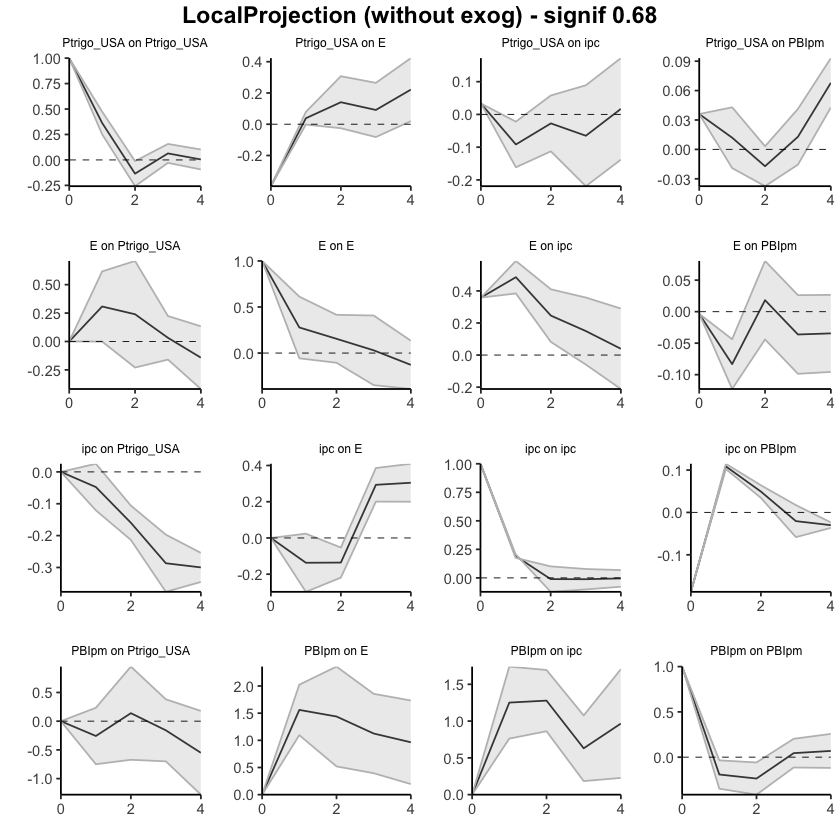

In [57]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,-0.13693992,-0.2974759,0.02359608
38,ipc,E,2,-0.27286388,-0.5164385,-0.02928923
39,ipc,E,3,0.02053661,-0.3158077,0.35688088
40,ipc,E,4,0.32539832,-0.1156765,0.76647313


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.000000,0.000000
52,PBIpm,E,1,1.559873,1.095012,2.024733
53,PBIpm,E,2,2.998325,1.614885,4.381764
54,PBIpm,E,3,4.123630,2.009419,6.237841
55,PBIpm,E,4,5.087468,2.204122,7.970815


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.39636609,-0.3963661,-0.39636609
2,Ptrigo_USA,E,1,-0.35792023,-0.3983773,-0.31746314
3,Ptrigo_USA,E,2,-0.21709708,-0.4239581,-0.01023608
4,Ptrigo_USA,E,3,-0.12573977,-0.5059845,0.25450490
5,Ptrigo_USA,E,4,0.09581161,-0.4858904,0.67751361


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.03606457,0.036064567,0.03606457
12,Ptrigo_USA,PBIpm,1,0.04802209,0.017013296,0.07903089
13,Ptrigo_USA,PBIpm,2,0.03086158,-0.020506170,0.08222933
14,Ptrigo_USA,PBIpm,3,0.04374587,-0.036026742,0.12351847
15,Ptrigo_USA,PBIpm,4,0.11167993,0.006727162,0.21663269


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.0000000,0.0000000000,0.0000000
17,E,Ptrigo_USA,1,0.3078518,-0.0008286156,0.6165322
18,E,Ptrigo_USA,2,0.5474545,-0.2303372999,1.3252464
19,E,Ptrigo_USA,3,0.5797022,-0.3899636911,1.5493681
20,E,Ptrigo_USA,4,0.4372412,-0.8083040645,1.6827865


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.04761987,-0.1207070,0.02546731
33,ipc,Ptrigo_USA,2,-0.20734913,-0.3342869,-0.08041135
34,ipc,Ptrigo_USA,3,-0.49410489,-0.7107478,-0.27746203
35,ipc,Ptrigo_USA,4,-0.79390845,-1.0561706,-0.53164634


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.2577619,-0.7491698,0.2336461
48,PBIpm,Ptrigo_USA,2,-0.1184646,-1.4209430,1.1840138
49,PBIpm,Ptrigo_USA,3,-0.2778608,-2.1203087,1.5645871
50,PBIpm,Ptrigo_USA,4,-0.8282042,-3.3995348,1.7431264


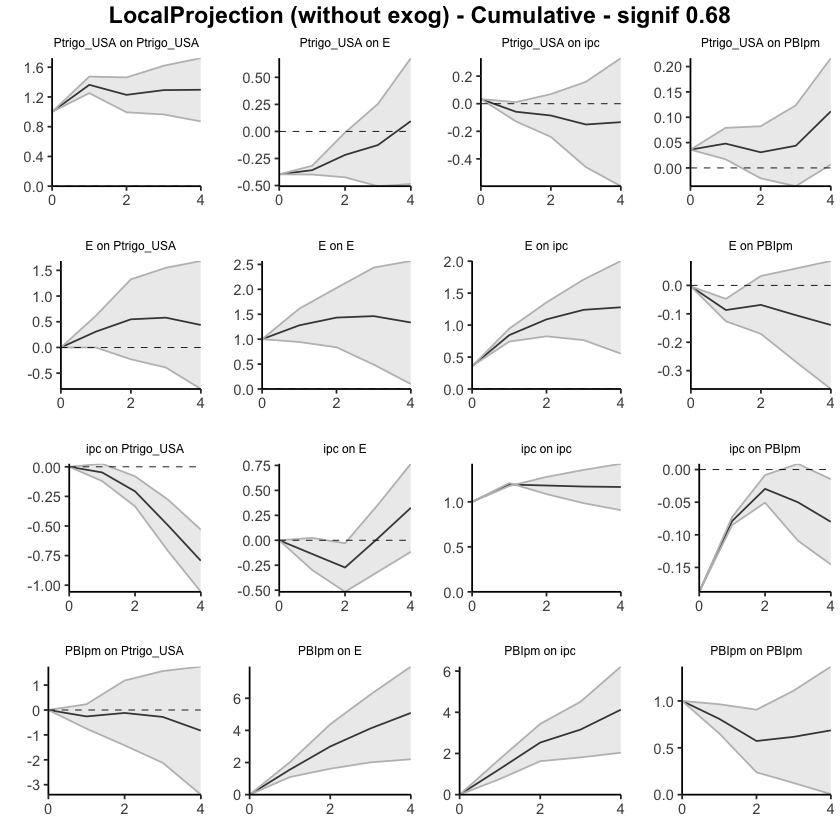

In [61]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.00000000
37,ipc,E,1,-0.44957740,-0.56844479,-0.33071001
38,ipc,E,2,-0.53222490,-0.61984619,-0.44460362
39,ipc,E,3,0.03317086,0.05395223,0.01238949
40,ipc,E,4,0.76991699,0.64686346,0.89297053


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.182978,0.1730080,2.192948
53,PBIpm,E,2,1.288380,0.7562887,1.820472
54,PBIpm,E,3,1.242536,0.7161973,1.768875
55,PBIpm,E,4,2.857372,2.4939397,3.220804


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.08305348,-0.08305348,-0.08305348
2,Ptrigo_USA,E,1,0.03813684,-0.40529680,0.48157047
3,Ptrigo_USA,E,2,0.13296682,-0.26232222,0.52825587
4,Ptrigo_USA,E,3,1.51605657,1.34272609,1.68938704
5,Ptrigo_USA,E,4,-0.08732962,-0.33037070,0.15571147


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,-0.02136606,-0.02136606,-0.02136606
12,Ptrigo_USA,PBIpm,1,0.09845982,0.05478704,0.14213260
13,Ptrigo_USA,PBIpm,2,0.11520962,-0.15321997,0.38363920
14,Ptrigo_USA,PBIpm,3,-0.15368570,-0.22572636,-0.08164505
15,Ptrigo_USA,PBIpm,4,0.05899854,-0.07722896,0.19522604


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.00000000,0.00000000
17,E,Ptrigo_USA,1,0.43906921,0.05555472,0.82258369
18,E,Ptrigo_USA,2,0.26653103,-2.66544777,3.19850983
19,E,Ptrigo_USA,3,-0.06434184,-0.19089809,0.06221442
20,E,Ptrigo_USA,4,-0.29867200,-0.35678015,-0.24056385


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.27650560,-0.3818125,-0.17119864
33,ipc,Ptrigo_USA,2,-0.23855077,-2.1291262,1.65202466
34,ipc,Ptrigo_USA,3,-0.09973641,-0.1528447,-0.04662809
35,ipc,Ptrigo_USA,4,-0.44267903,-0.3951392,-0.49021890


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.2935131,-0.9678797,0.3808535
48,PBIpm,Ptrigo_USA,2,-2.3645648,-6.6716711,1.9425415
49,PBIpm,Ptrigo_USA,3,-0.1460771,-0.5588326,0.2666785
50,PBIpm,Ptrigo_USA,4,0.9675201,0.6199448,1.3150954


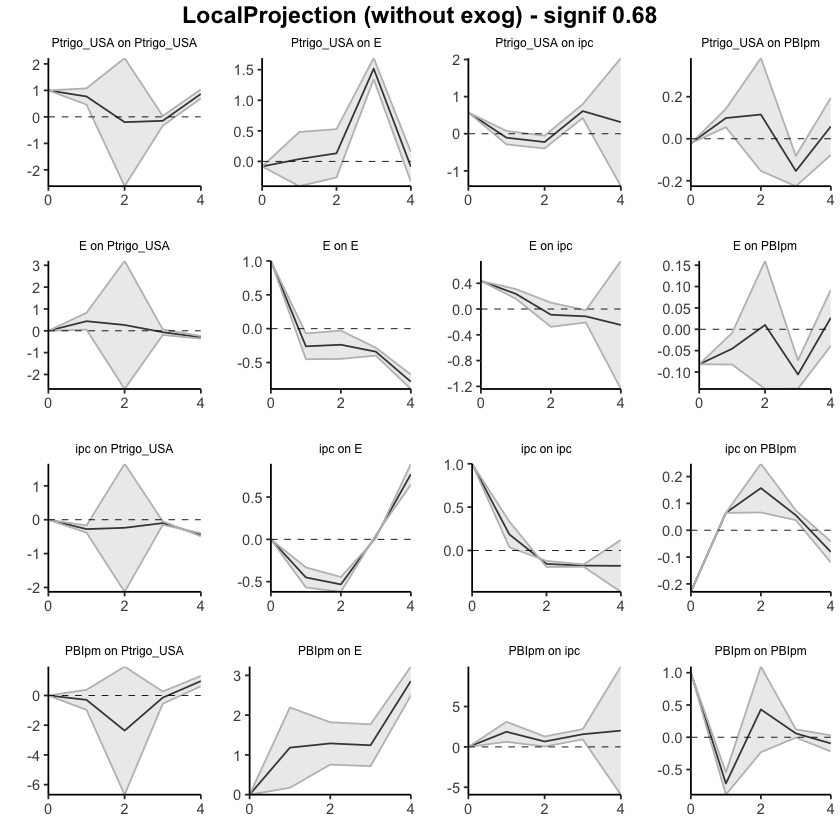

In [60]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.4495774,-0.5684448,-0.3307100
38,ipc,E,2,-0.9818023,-1.1882910,-0.7753136
39,ipc,E,3,-0.9486314,-1.1343387,-0.7629241
40,ipc,E,4,-0.1787145,-0.4874753,0.1300464


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.182978,0.1730080,2.192948
53,PBIpm,E,2,2.471358,0.9292967,4.013420
54,PBIpm,E,3,3.713894,1.6454940,5.782295
55,PBIpm,E,4,6.571266,4.1394337,9.003098


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.08305348,-0.08305348,-0.08305348
2,Ptrigo_USA,E,1,-0.04491664,-0.48835028,0.39851700
3,Ptrigo_USA,E,2,0.08805018,-0.75067250,0.92677286
4,Ptrigo_USA,E,3,1.60410675,0.59205359,2.61615991
5,Ptrigo_USA,E,4,1.51677713,0.26168289,2.77187137


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,-0.02136606,-0.02136606,-0.02136606
12,Ptrigo_USA,PBIpm,1,0.07709376,0.03342098,0.12076654
13,Ptrigo_USA,PBIpm,2,0.19230337,-0.11979899,0.50440574
14,Ptrigo_USA,PBIpm,3,0.03861767,-0.34552535,0.42276069
15,Ptrigo_USA,PBIpm,4,0.09761621,-0.42275432,0.61798673


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.0000000,0.00000000,0.0000000
17,E,Ptrigo_USA,1,0.4390692,0.05555472,0.8225837
18,E,Ptrigo_USA,2,0.7056002,-2.60989304,4.0210935
19,E,Ptrigo_USA,3,0.6412584,-2.80079114,4.0833079
20,E,Ptrigo_USA,4,0.3425864,-3.15757129,3.8427441


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
32,ipc,Ptrigo_USA,1,-0.2765056,-0.3818125,-0.1711986
33,ipc,Ptrigo_USA,2,-0.5150564,-2.5109387,1.4808260
34,ipc,Ptrigo_USA,3,-0.6147928,-2.6637835,1.4341979
35,ipc,Ptrigo_USA,4,-1.0574718,-3.0589226,0.9439790


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.2935131,-0.9678797,0.3808535
48,PBIpm,Ptrigo_USA,2,-2.6580779,-7.6395508,2.3233950
49,PBIpm,Ptrigo_USA,3,-2.8041549,-8.1983834,2.5900735
50,PBIpm,Ptrigo_USA,4,-1.8366348,-7.5784386,3.9051690


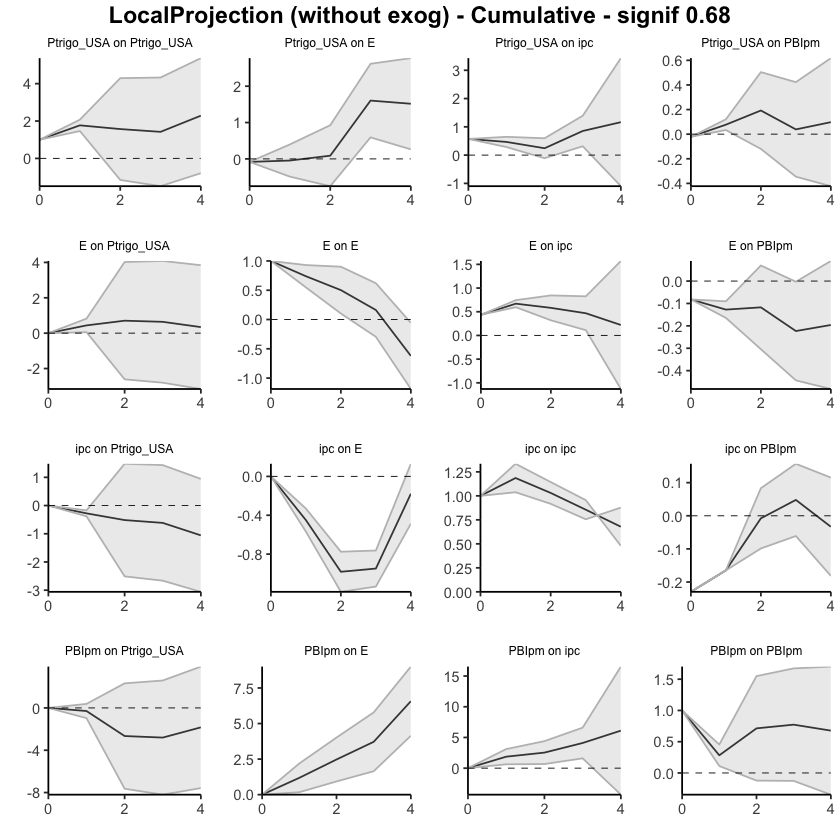

In [59]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

### 1935-1974. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.08854557,-0.2889923,0.11190112
13,ipc,E,2,-0.04332520,-0.1586789,0.07202855
14,ipc,E,3,0.34084481,0.2187414,0.46294822
15,ipc,E,4,0.35063502,0.2249479,0.47632211


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,1.469433,0.9382117,2.000654
23,PBIpm,E,2,1.619706,0.5076335,2.731779
24,PBIpm,E,3,1.228580,0.4103871,2.046774
25,PBIpm,E,4,1.006042,0.1483061,1.863778


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.29857022,0.29857022,0.2985702
2,E,ipc,1,0.46855814,0.37032458,0.5667917
3,E,ipc,2,0.18419120,0.01140858,0.3569738
4,E,ipc,3,0.10500553,-0.08252824,0.2925393
5,E,ipc,4,-0.05408124,-0.26109837,0.1529359


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.1860711,0.6388782,1.733264
28,PBIpm,ipc,2,1.4424293,0.9594396,1.925419
29,PBIpm,ipc,3,0.7721883,0.2686255,1.275751
30,PBIpm,ipc,4,1.1799431,0.3749858,1.984900


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01251743,-0.01251743,-0.01251743
7,E,PBIpm,1,-0.09282707,-0.12720146,-0.05845268
8,E,PBIpm,2,0.02145347,-0.03496168,0.07786861
9,E,PBIpm,3,-0.03149913,-0.08743013,0.02443186
10,E,PBIpm,4,-0.03207289,-0.09236025,0.02821446


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.15355548,-0.15355548,-0.15355548
17,ipc,PBIpm,1,0.10729084,0.09943681,0.11514487
18,ipc,PBIpm,2,0.04032108,0.01892557,0.06171658
19,ipc,PBIpm,3,-0.02073440,-0.06299701,0.02152821
20,ipc,PBIpm,4,-0.02649980,-0.04275499,-0.01024462


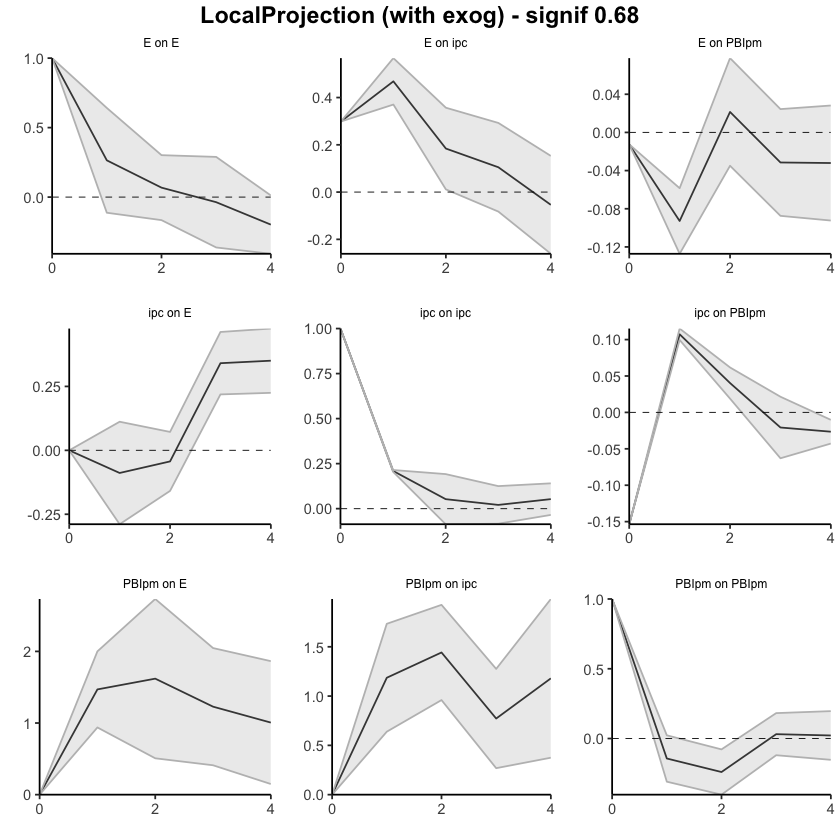

In [62]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.000000000,0.0000000
12,ipc,E,1,-0.08854557,-0.288992268,0.1119011
13,ipc,E,2,-0.13187077,-0.447671211,0.1839297
14,ipc,E,3,0.20897404,-0.228929804,0.6468779
15,ipc,E,4,0.55960906,-0.003981882,1.1232000


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,1.469433,0.9382117,2.000654
23,PBIpm,E,2,3.089139,1.4458452,4.732433
24,PBIpm,E,3,4.317719,1.8562323,6.779207
25,PBIpm,E,4,5.323762,2.0045384,8.642985


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2985702,0.2985702,0.2985702
2,E,ipc,1,0.7671284,0.6688948,0.8653619
3,E,ipc,2,0.9513196,0.6803034,1.2223357
4,E,ipc,3,1.0563251,0.5977751,1.5148750
5,E,ipc,4,1.0022438,0.3366768,1.6678109


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.186071,0.6388782,1.733264
28,PBIpm,ipc,2,2.628500,1.5983178,3.658683
29,PBIpm,ipc,3,3.400689,1.8669433,4.934434
30,PBIpm,ipc,4,4.580632,2.2419292,6.919335


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01251743,-0.01251743,-0.012517433
7,E,PBIpm,1,-0.10534451,-0.13971890,-0.070970116
8,E,PBIpm,2,-0.08389104,-0.17468058,0.006898496
9,E,PBIpm,3,-0.11539017,-0.26211070,0.031330358
10,E,PBIpm,4,-0.14746307,-0.35447095,0.059544817


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.153555478,-0.15355548,-0.15355548
17,ipc,PBIpm,1,-0.046264637,-0.05411866,-0.03841061
18,ipc,PBIpm,2,-0.005943559,-0.03519309,0.02330597
19,ipc,PBIpm,3,-0.026677960,-0.09819010,0.04483418
20,ipc,PBIpm,4,-0.053177763,-0.14094509,0.03458956


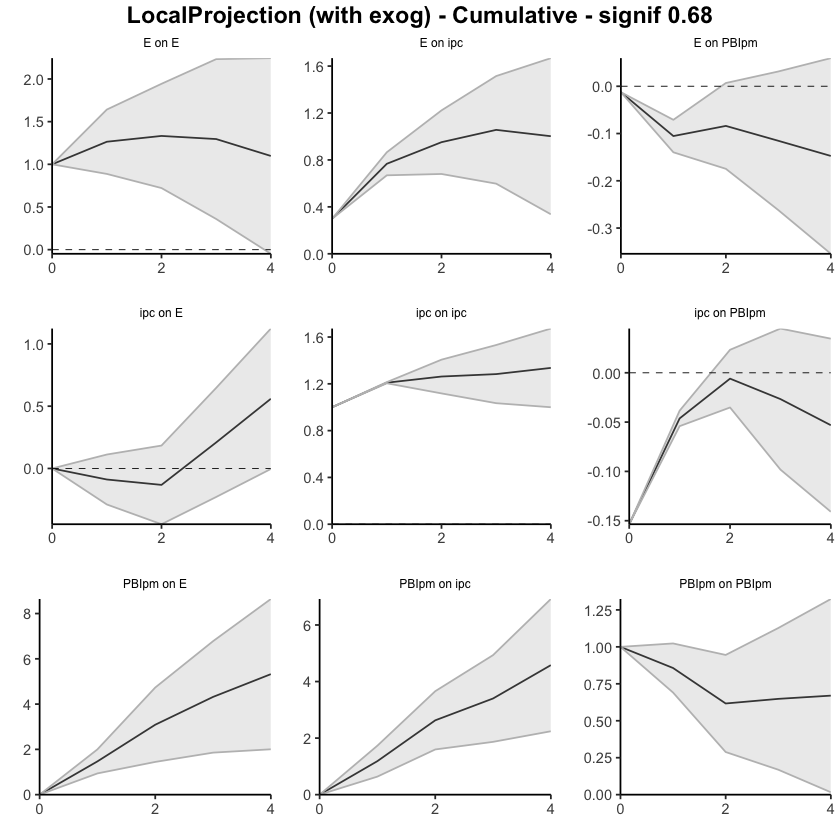

In [63]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.05445278,-0.2424432,0.13353760
13,ipc,E,2,-0.06544006,-0.1699203,0.03904016
14,ipc,E,3,0.32083018,0.2055114,0.43614896
15,ipc,E,4,0.34751783,0.2227576,0.47227810


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,1.5946696,1.1573354,2.032004
23,PBIpm,E,2,1.4675652,0.4571322,2.477998
24,PBIpm,E,3,1.0966403,0.3909720,1.802309
25,PBIpm,E,4,0.9821962,0.2094532,1.754939


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.299516683,0.29951668,0.2995167
2,E,ipc,1,0.448191491,0.35383302,0.5425500
3,E,ipc,2,0.214207563,0.06025307,0.3681621
4,E,ipc,3,0.147541649,-0.02632070,0.3214040
5,E,ipc,4,0.001039594,-0.19179488,0.1938741


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.2478317,0.7693584,1.726305
28,PBIpm,ipc,2,1.2901309,0.8630903,1.717171
29,PBIpm,ipc,3,0.6295983,0.2172765,1.041920
30,PBIpm,ipc,4,1.0251109,0.3135382,1.736684


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01608120,-0.01608120,-0.01608120
7,E,PBIpm,1,-0.07343281,-0.10457425,-0.04229137
8,E,PBIpm,2,0.02384073,-0.03085641,0.07853787
9,E,PBIpm,3,-0.04677865,-0.10367987,0.01012258
10,E,PBIpm,4,-0.03104126,-0.08730319,0.02522067


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.15466776,-0.15466776,-0.15466776
17,ipc,PBIpm,1,0.08648800,0.08242749,0.09054851
18,ipc,PBIpm,2,0.03958848,0.02080825,0.05836870
19,ipc,PBIpm,3,-0.01246900,-0.06072409,0.03578609
20,ipc,PBIpm,4,-0.03194857,-0.04878373,-0.01511340


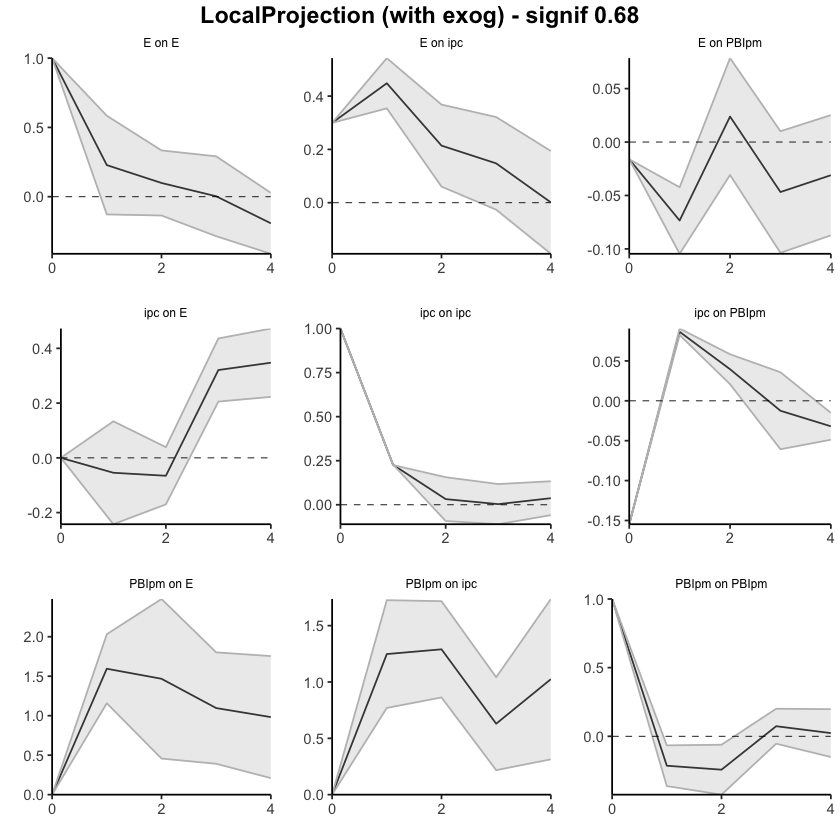

In [64]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.0000000
12,ipc,E,1,-0.05445278,-0.24244315,0.1335376
13,ipc,E,2,-0.11989284,-0.41236344,0.1725778
14,ipc,E,3,0.20093734,-0.20685205,0.6087267
15,ipc,E,4,0.54845516,0.01590551,1.0810048


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.000000,0.000000
22,PBIpm,E,1,1.594670,1.157335,2.032004
23,PBIpm,E,2,3.062235,1.614468,4.510002
24,PBIpm,E,3,4.158875,2.005440,6.312311
25,PBIpm,E,4,5.141071,2.214893,8.067250


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2995167,0.2995167,0.2995167
2,E,ipc,1,0.7477082,0.6533497,0.8420666
3,E,ipc,2,0.9619157,0.7136028,1.2102287
4,E,ipc,3,1.1094574,0.6872821,1.5316327
5,E,ipc,4,1.1104970,0.4954872,1.7255068


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.247832,0.7693584,1.726305
28,PBIpm,ipc,2,2.537963,1.6324487,3.443476
29,PBIpm,ipc,3,3.167561,1.8497252,4.485396
30,PBIpm,ipc,4,4.192672,2.1632634,6.222080


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01608120,-0.0160812,-0.01608120
7,E,PBIpm,1,-0.08951401,-0.1206555,-0.05837257
8,E,PBIpm,2,-0.06567329,-0.1515119,0.02016529
9,E,PBIpm,3,-0.11245193,-0.2551917,0.03028787
10,E,PBIpm,4,-0.14349319,-0.3424949,0.05550854


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.15466776,-0.15466776,-0.154667763
17,ipc,PBIpm,1,-0.06817976,-0.07224027,-0.064119257
18,ipc,PBIpm,2,-0.02859129,-0.05143202,-0.005750557
19,ipc,PBIpm,3,-0.04106029,-0.11215611,0.030035531
20,ipc,PBIpm,4,-0.07300886,-0.16093984,0.014922126


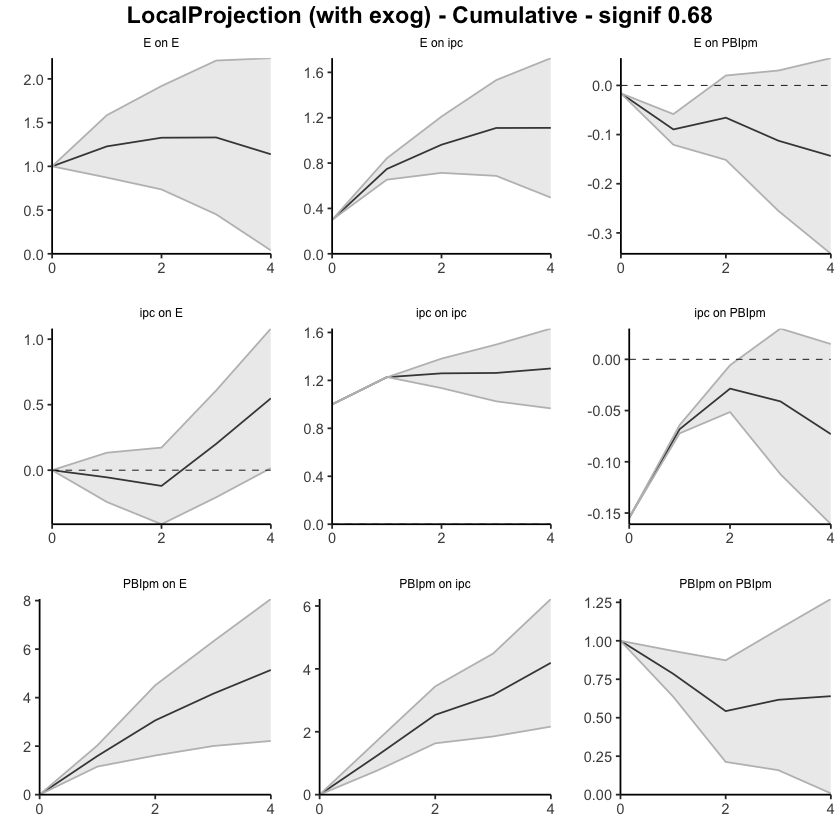

In [65]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.09105652,-0.2652663,0.08315328
13,ipc,E,2,-0.09361214,-0.2036707,0.01644637
14,ipc,E,3,0.32650116,0.2122360,0.44076629
15,ipc,E,4,0.33321287,0.2058583,0.46056739


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,1.5598728,1.0950122,2.024733
23,PBIpm,E,2,1.4384518,0.5198727,2.357031
24,PBIpm,E,3,1.1253051,0.3945337,1.856076
25,PBIpm,E,4,0.9638388,0.1947035,1.732974


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.30128781,0.30128781,0.3012878
2,E,ipc,1,0.44704917,0.35552219,0.5385762
3,E,ipc,2,0.21855920,0.06992930,0.3671891
4,E,ipc,3,0.13641673,-0.05766051,0.3304940
5,E,ipc,4,0.01831413,-0.21218581,0.2488141


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.2514596,0.7621863,1.740733
28,PBIpm,ipc,2,1.2784065,0.8619659,1.694847
29,PBIpm,ipc,3,0.6302882,0.1842391,1.076337
30,PBIpm,ipc,4,0.9664813,0.2275269,1.705436


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01472976,-0.01472976,-0.01472976
7,E,PBIpm,1,-0.08522235,-0.12095352,-0.04949119
8,E,PBIpm,2,0.02055736,-0.03697542,0.07809013
9,E,PBIpm,3,-0.03604632,-0.09282620,0.02073355
10,E,PBIpm,4,-0.03428859,-0.09095366,0.02237647


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.15800628,-0.15800628,-0.15800628
17,ipc,PBIpm,1,0.10294768,0.09209822,0.11379714
18,ipc,PBIpm,2,0.04231766,0.02221108,0.06242423
19,ipc,PBIpm,3,-0.01920093,-0.06170852,0.02330666
20,ipc,PBIpm,4,-0.02803980,-0.03997455,-0.01610505


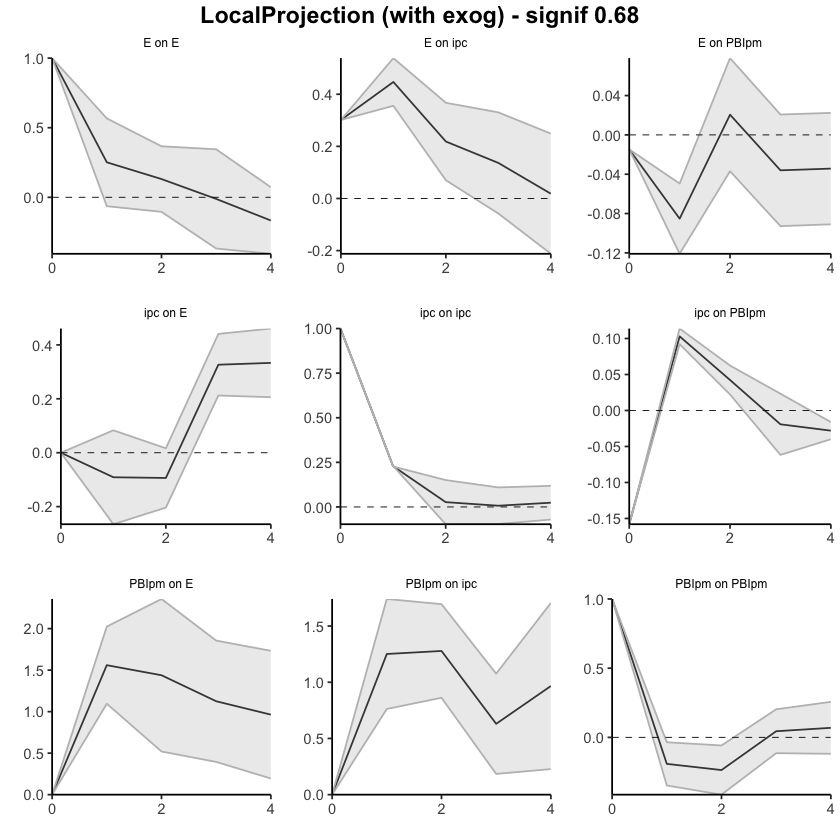

In [66]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.00000000
12,ipc,E,1,-0.09105652,-0.26526631,0.08315328
13,ipc,E,2,-0.18466866,-0.46893696,0.09959965
14,ipc,E,3,0.14183250,-0.25670094,0.54036594
15,ipc,E,4,0.47504537,-0.05084259,1.00093334


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.000000,0.000000
22,PBIpm,E,1,1.559873,1.095012,2.024733
23,PBIpm,E,2,2.998325,1.614885,4.381764
24,PBIpm,E,3,4.123630,2.009419,6.237841
25,PBIpm,E,4,5.087468,2.204122,7.970815


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3012878,0.3012878,0.3012878
2,E,ipc,1,0.7483370,0.6568100,0.8398640
3,E,ipc,2,0.9668962,0.7267393,1.2070531
4,E,ipc,3,1.1033129,0.6690788,1.5375470
5,E,ipc,4,1.1216270,0.4568930,1.7863611


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.251460,0.7621863,1.740733
28,PBIpm,ipc,2,2.529866,1.6241523,3.435580
29,PBIpm,ipc,3,3.160154,1.8083914,4.511917
30,PBIpm,ipc,4,4.126636,2.0359183,6.217353


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01472976,-0.01472976,-0.01472976
7,E,PBIpm,1,-0.09995211,-0.13568327,-0.06422095
8,E,PBIpm,2,-0.07939475,-0.17265869,0.01386919
9,E,PBIpm,3,-0.11544108,-0.26548489,0.03460274
10,E,PBIpm,4,-0.14972967,-0.35643855,0.05697921


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.15800628,-0.15800628,-0.15800628
17,ipc,PBIpm,1,-0.05505860,-0.06590806,-0.04420914
18,ipc,PBIpm,2,-0.01274094,-0.04369698,0.01821509
19,ipc,PBIpm,3,-0.03194187,-0.10540550,0.04152175
20,ipc,PBIpm,4,-0.05998167,-0.14538005,0.02541670


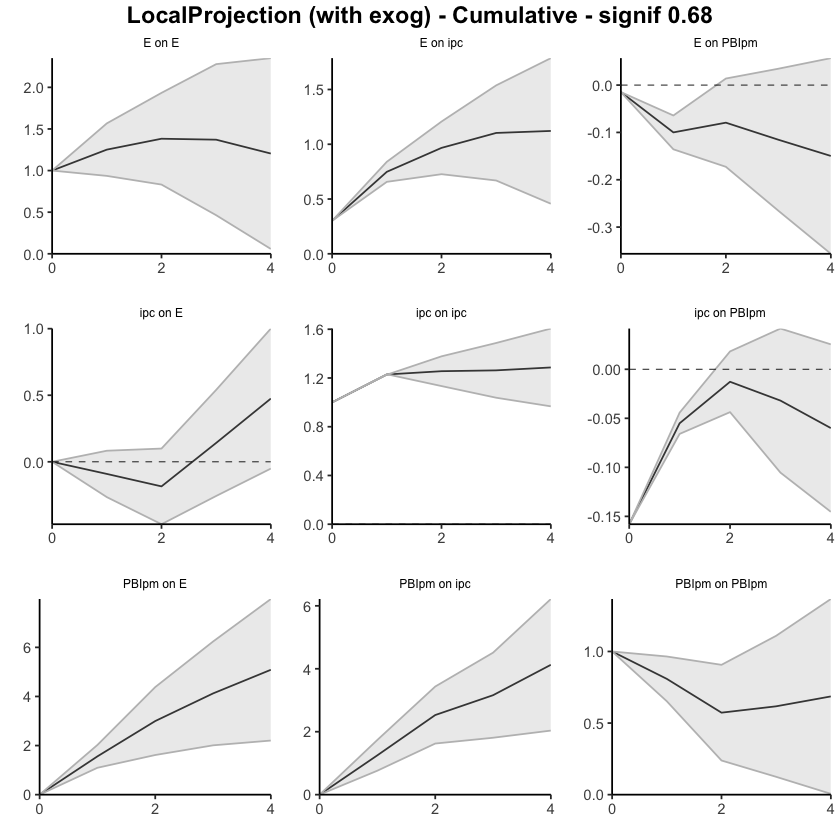

In [67]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

### 1935-1975. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,-0.2635508,-0.42597014,-0.1011314
38,ipc,E,2,0.5274847,0.25899000,0.7959794
39,ipc,E,3,0.4119817,0.07365139,0.7503121
40,ipc,E,4,0.2214998,0.03071811,0.4122815


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000
52,PBIpm,E,1,1.8761271,1.27378103,2.478473
53,PBIpm,E,2,1.9372412,0.63704012,3.237442
54,PBIpm,E,3,1.2322258,0.27068809,2.193763
55,PBIpm,E,4,0.9885576,-0.01304069,1.990156


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.55444550,-0.55444550,-0.55444550
2,Psoja_USA,E,1,-0.08777342,-0.08744365,-0.08810319
3,Psoja_USA,E,2,0.46049044,-0.06051557,0.98149644
4,Psoja_USA,E,3,-0.03352180,-0.09983954,0.03279593
5,Psoja_USA,E,4,0.14090176,0.14141347,0.14039004


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.04991466,0.049914664,0.04991466
12,Psoja_USA,PBIpm,1,0.00586070,-0.008200085,0.01992149
13,Psoja_USA,PBIpm,2,-0.03501065,-0.040191724,-0.02982959
14,Psoja_USA,PBIpm,3,0.03073304,0.015352071,0.04611400
15,Psoja_USA,PBIpm,4,0.06958954,0.044958356,0.09422073


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.0000000,0.0000000
17,E,Psoja_USA,1,0.09903199,-0.3499890,0.5480529
18,E,Psoja_USA,2,0.15144220,-0.1633418,0.4662262
19,E,Psoja_USA,3,-0.12413387,-0.5170416,0.2687739
20,E,Psoja_USA,4,-0.37945959,-0.5781918,-0.1807274


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Psoja_USA,1,0.07773517,-0.1112708,0.26674117
33,ipc,Psoja_USA,2,-0.05396215,-0.1886334,0.08070907
34,ipc,Psoja_USA,3,-0.63025626,-0.8386890,-0.42182348
35,ipc,Psoja_USA,4,-0.15332463,-0.1949559,-0.11169331


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Psoja_USA,1,-0.06683715,-0.6407471,0.5070728
48,PBIpm,Psoja_USA,2,-1.59731978,-2.1717817,-1.0228579
49,PBIpm,Psoja_USA,3,0.11138896,-0.6020426,0.8248205
50,PBIpm,Psoja_USA,4,0.45469288,-0.3144513,1.2238370


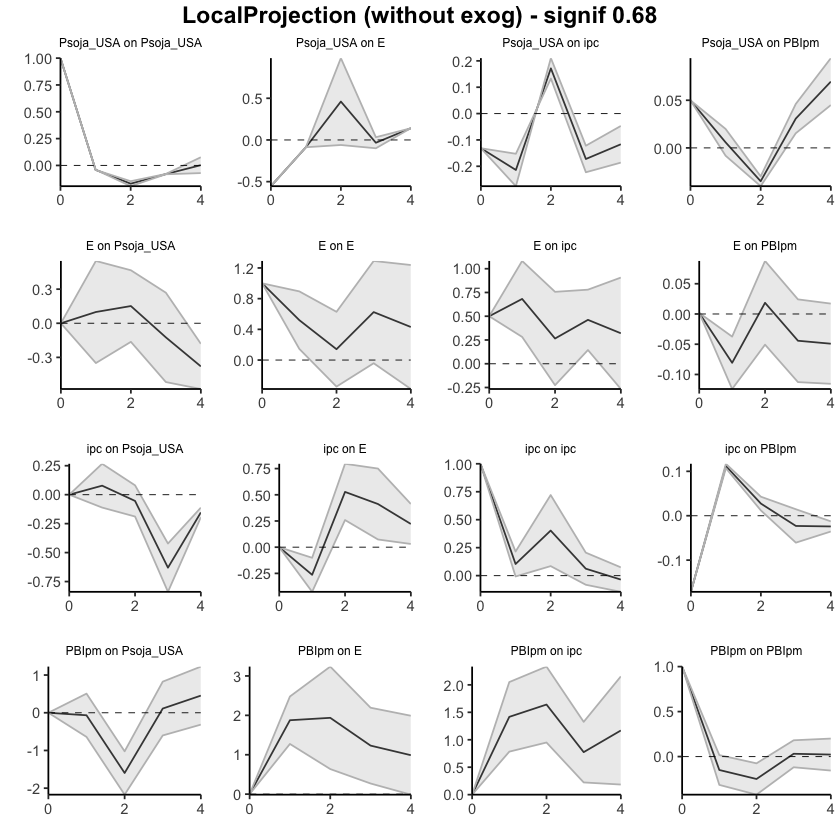

In [68]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,-0.2635508,-0.42597014,-0.1011314
38,ipc,E,2,0.2639339,-0.16698014,0.6948480
39,ipc,E,3,0.6759157,-0.09332875,1.4451601
40,ipc,E,4,0.8974154,-0.06261065,1.8574415


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.000000,0.000000
52,PBIpm,E,1,1.876127,1.273781,2.478473
53,PBIpm,E,2,3.813368,1.910821,5.715916
54,PBIpm,E,3,5.045594,2.181509,7.909679
55,PBIpm,E,4,6.034152,2.168469,9.899835


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.55444550,-0.5544455,-0.5544455
2,Psoja_USA,E,1,-0.64221892,-0.6418892,-0.6425487
3,Psoja_USA,E,2,-0.18172848,-0.7024047,0.3389478
4,Psoja_USA,E,3,-0.21525029,-0.8022443,0.3717437
5,Psoja_USA,E,4,-0.07434853,-0.6608308,0.5121337


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.04991466,0.049914664,0.04991466
12,Psoja_USA,PBIpm,1,0.05577536,0.041714579,0.06983615
13,Psoja_USA,PBIpm,2,0.02076471,0.001522855,0.04000657
14,Psoja_USA,PBIpm,3,0.05149775,0.016874926,0.08612057
15,Psoja_USA,PBIpm,4,0.12108729,0.061833283,0.18034129


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.0000000,0.0000000
17,E,Psoja_USA,1,0.09903199,-0.3499890,0.5480529
18,E,Psoja_USA,2,0.25047419,-0.5133308,1.0142792
19,E,Psoja_USA,3,0.12634032,-1.0303724,1.2830531
20,E,Psoja_USA,4,-0.25311927,-1.6085642,1.1023256


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Psoja_USA,1,0.07773517,-0.1112708,0.26674117
33,ipc,Psoja_USA,2,0.02377302,-0.2999042,0.34745024
34,ipc,Psoja_USA,3,-0.60648324,-1.1385932,-0.07437325
35,ipc,Psoja_USA,4,-0.75980787,-1.3335492,-0.18606655


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Psoja_USA,1,-0.06683715,-0.6407471,0.5070728
48,PBIpm,Psoja_USA,2,-1.66415692,-2.8125288,-0.5157850
49,PBIpm,Psoja_USA,3,-1.55276796,-3.4145714,0.3090355
50,PBIpm,Psoja_USA,4,-1.09807508,-3.7290227,1.5328725


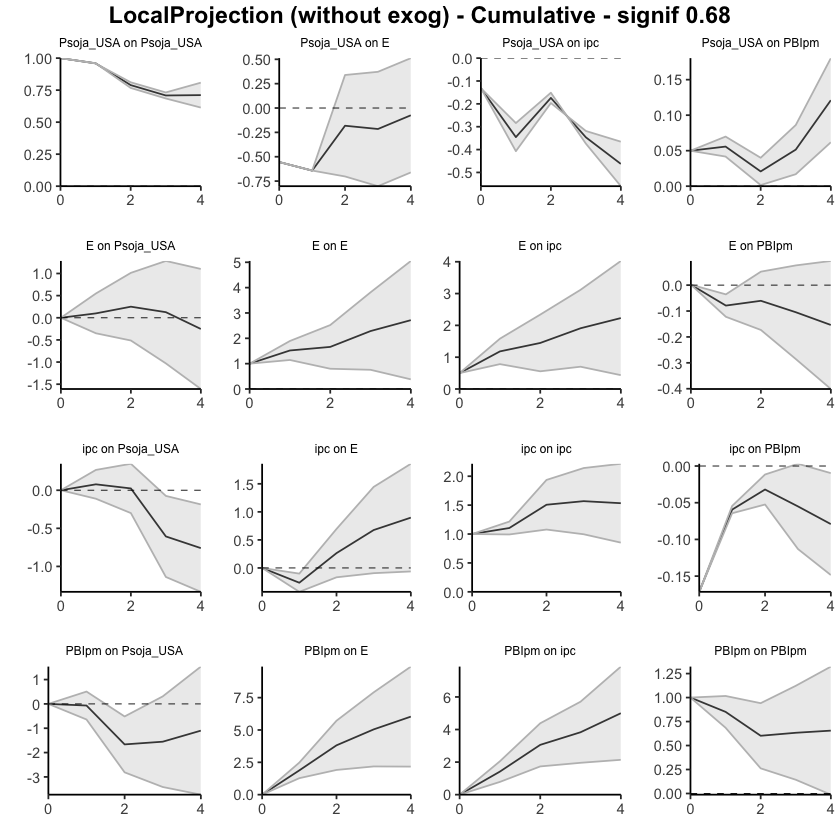

In [69]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.00000000
37,ipc,E,1,-0.2627423,-0.45799763,-0.06748695
38,ipc,E,2,0.6582887,0.05897096,1.25760647
39,ipc,E,3,0.4631096,-0.01708986,0.94330908
40,ipc,E,4,0.2754381,0.03211962,0.51875662


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.694131,0.9924685,2.395793
53,PBIpm,E,2,2.246717,1.2888483,3.204586
54,PBIpm,E,3,1.386337,0.4064146,2.366259
55,PBIpm,E,4,1.244024,0.1116892,2.376358


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.15175435,-0.15175435,-0.15175435
2,Pmaíz_USA,E,1,0.22862178,0.03256984,0.42467371
3,Pmaíz_USA,E,2,0.25411592,0.09757829,0.41065356
4,Pmaíz_USA,E,3,0.01913056,-0.02270673,0.06096785
5,Pmaíz_USA,E,4,0.05512455,0.04148682,0.06876229


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.017502116,0.0175021163,0.017502116
12,Pmaíz_USA,PBIpm,1,0.012680000,-0.0001215464,0.025481546
13,Pmaíz_USA,PBIpm,2,-0.006441095,-0.0244243997,0.011542210
14,Pmaíz_USA,PBIpm,3,-0.028801540,-0.0633709383,0.005767859
15,Pmaíz_USA,PBIpm,4,0.073778590,0.0401842324,0.107372948


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.00000000,0.00000000
17,E,Pmaíz_USA,1,-0.01665881,-0.40916892,0.37585129
18,E,Pmaíz_USA,2,0.25355790,-0.01887323,0.52598903
19,E,Pmaíz_USA,3,-0.03183149,-0.34674114,0.28307816
20,E,Pmaíz_USA,4,-0.15138130,-0.36004938,0.05728679


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.0000000,0.00000000,0.00000000
32,ipc,Pmaíz_USA,1,0.3718768,0.06176968,0.68198397
33,ipc,Pmaíz_USA,2,-0.1385871,-0.20919987,-0.06797425
34,ipc,Pmaíz_USA,3,-0.2585135,-0.38485762,-0.13216946
35,ipc,Pmaíz_USA,4,-0.1958478,-0.28642608,-0.10526957


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Pmaíz_USA,1,0.07863023,-0.6155613,0.7728218
48,PBIpm,Pmaíz_USA,2,-0.81918913,-1.3911348,-0.2472434
49,PBIpm,Pmaíz_USA,3,0.08011755,-0.7642587,0.9244938
50,PBIpm,Pmaíz_USA,4,-0.26351867,-1.1612744,0.6342371


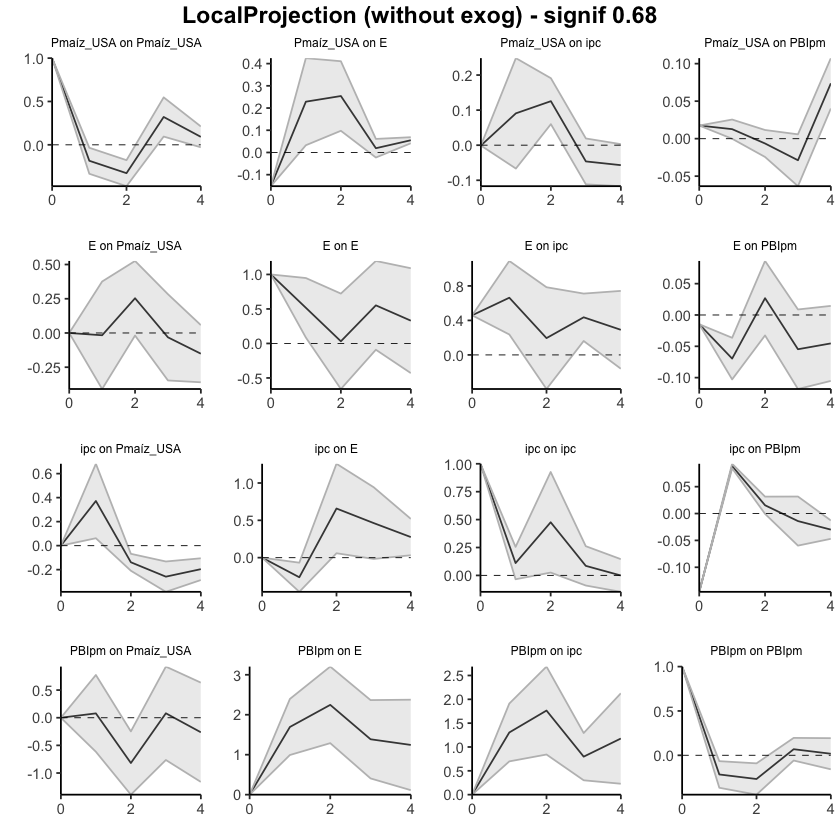

In [70]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.2627423,-0.4579976,-0.06748695
38,ipc,E,2,0.3955464,-0.3990267,1.19011951
39,ipc,E,3,0.8586560,-0.4161165,2.13342859
40,ipc,E,4,1.1340942,-0.3839969,2.65218521


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.694131,0.9924685,2.395793
53,PBIpm,E,2,3.940848,2.2813168,5.600380
54,PBIpm,E,3,5.327185,2.6877314,7.966638
55,PBIpm,E,4,6.571209,2.7994205,10.342997


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.15175435,-0.151754350,-0.1517544
2,Pmaíz_USA,E,1,0.07686743,-0.119184511,0.2729194
3,Pmaíz_USA,E,2,0.33098335,-0.021606225,0.6835729
4,Pmaíz_USA,E,3,0.35011391,-0.044312958,0.7445408
5,Pmaíz_USA,E,4,0.40523846,-0.002826135,0.8133031


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.017502116,0.01750212,0.01750212
12,Pmaíz_USA,PBIpm,1,0.030182116,0.01738057,0.04298366
13,Pmaíz_USA,PBIpm,2,0.023741022,-0.00704383,0.05452587
14,Pmaíz_USA,PBIpm,3,-0.005060518,-0.07041477,0.06029373
15,Pmaíz_USA,PBIpm,4,0.068718072,-0.03023054,0.16766668


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,-0.01665881,-0.4091689,0.3758513
18,E,Pmaíz_USA,2,0.23689908,-0.4280422,0.9018403
19,E,Pmaíz_USA,3,0.20506759,-0.7747833,1.1849185
20,E,Pmaíz_USA,4,0.05368629,-1.1348327,1.2422053


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Pmaíz_USA,1,0.37187683,0.06176968,0.6819840
33,ipc,Pmaíz_USA,2,0.23328977,-0.14743019,0.6140097
34,ipc,Pmaíz_USA,3,-0.02522377,-0.53228781,0.4818403
35,ipc,Pmaíz_USA,4,-0.22107160,-0.81871389,0.3765707


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Pmaíz_USA,1,0.07863023,-0.6155613,0.7728218
48,PBIpm,Pmaíz_USA,2,-0.74055890,-2.0066962,0.5255784
49,PBIpm,Pmaíz_USA,3,-0.66044135,-2.7709548,1.4500721
50,PBIpm,Pmaíz_USA,4,-0.92396001,-3.9322293,2.0843092


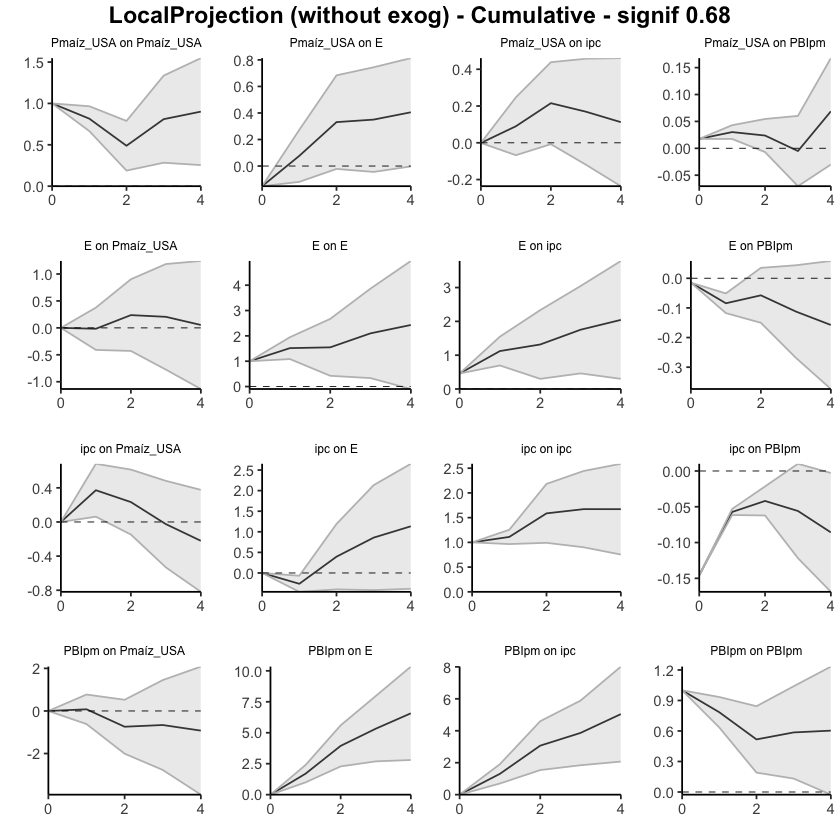

In [71]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.47081080,-0.5845614,-0.3570603
38,ipc,E,2,0.44000559,0.2004245,0.6795867
39,ipc,E,3,0.66799252,-11.9916859,13.3276710
40,ipc,E,4,0.08232305,-2.0707418,2.2353879


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.716044,0.5542500,2.877838
53,PBIpm,E,2,6.335441,5.6743457,6.996537
54,PBIpm,E,3,4.064818,-23.7172350,31.846872
55,PBIpm,E,4,1.458143,-0.7502462,3.666533


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.57019906,-0.5701991,-0.5701991
2,Pmaíz_USA,E,1,0.59608504,0.3510665,0.8411036
3,Pmaíz_USA,E,2,1.56342323,1.5161568,1.6106897
4,Pmaíz_USA,E,3,1.11388819,-0.2688995,2.4966759
5,Pmaíz_USA,E,4,0.06521129,0.5620232,-0.4316006


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.06372161,0.06372161,0.06372161
12,Pmaíz_USA,PBIpm,1,-0.03068217,-0.03782902,-0.02353531
13,Pmaíz_USA,PBIpm,2,0.02110482,-0.01440666,0.05661630
14,Pmaíz_USA,PBIpm,3,0.18141914,0.13401570,0.22882259
15,Pmaíz_USA,PBIpm,4,-0.07385583,-0.09270624,-0.05500542


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,0.09051937,-0.1997751,0.3808139
18,E,Pmaíz_USA,2,0.12861739,-0.3019504,0.5591852
19,E,Pmaíz_USA,3,-0.12477159,-0.3572858,0.1077426
20,E,Pmaíz_USA,4,-0.26434087,-0.7389260,0.2102443


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Pmaíz_USA,1,0.66577818,0.5163612,0.81519519
33,ipc,Pmaíz_USA,2,-0.06575503,-0.3278664,0.19635633
34,ipc,Pmaíz_USA,3,-0.75656808,-0.9339614,-0.57917477
35,ipc,Pmaíz_USA,4,-0.05062504,-0.1318397,0.03058968


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.0000000,0.000000,0.00000000
47,PBIpm,Pmaíz_USA,1,3.1648137,2.545235,3.78439257
48,PBIpm,Pmaíz_USA,2,-2.0332648,-2.853815,-1.21271422
49,PBIpm,Pmaíz_USA,3,-0.4829085,-1.052824,0.08700739
50,PBIpm,Pmaíz_USA,4,3.0697175,1.580902,4.55853294


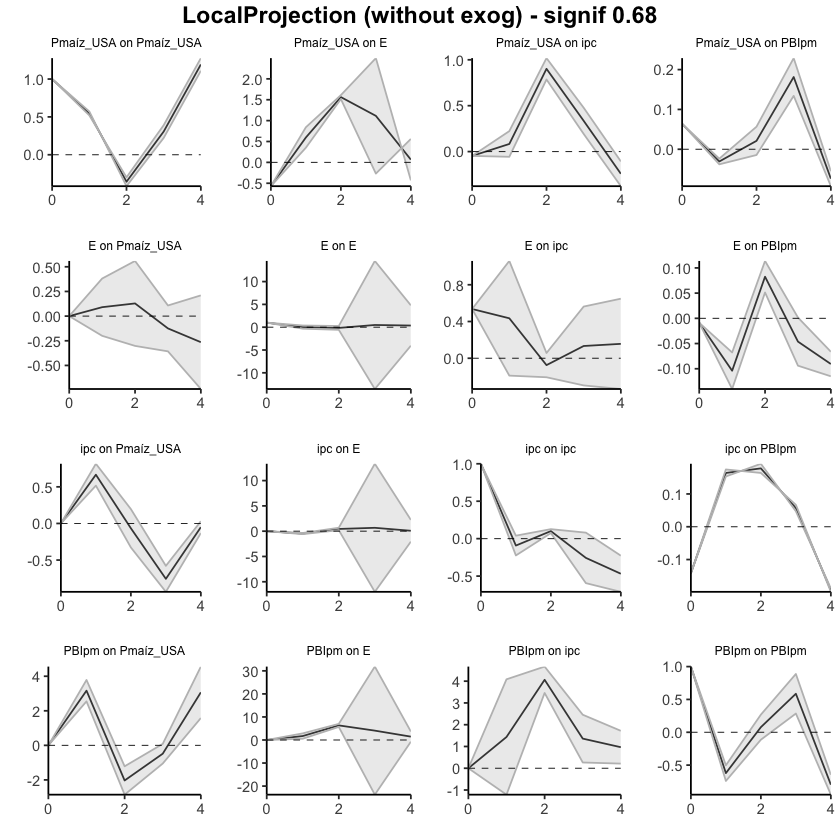

In [72]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.47081080,-0.5845614,-0.3570603
38,ipc,E,2,-0.03080521,-0.3841369,0.3225264
39,ipc,E,3,0.63718731,-12.3758228,13.6501974
40,ipc,E,4,0.71951037,-14.4465646,15.8855853


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.000000,0.000000
52,PBIpm,E,1,1.716044,0.554250,2.877838
53,PBIpm,E,2,8.051485,6.228596,9.874375
54,PBIpm,E,3,12.116304,-17.488639,41.721247
55,PBIpm,E,4,13.574447,-18.238886,45.387780


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.57019906,-0.5701991,-0.5701991
2,Pmaíz_USA,E,1,0.02588598,-0.2191326,0.2709046
3,Pmaíz_USA,E,2,1.58930921,1.2970242,1.8815943
4,Pmaíz_USA,E,3,2.70319741,1.0281247,4.3782701
5,Pmaíz_USA,E,4,2.76840870,1.5901479,3.9466695


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.06372161,0.06372161,0.06372161
12,Pmaíz_USA,PBIpm,1,0.03303944,0.02589259,0.04018629
13,Pmaíz_USA,PBIpm,2,0.05414426,0.01148593,0.09680259
14,Pmaíz_USA,PBIpm,3,0.23556340,0.14550162,0.32562518
15,Pmaíz_USA,PBIpm,4,0.16170758,0.05279539,0.27061976


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,0.09051937,-0.1997751,0.3808139
18,E,Pmaíz_USA,2,0.21913676,-0.5017255,0.9399991
19,E,Pmaíz_USA,3,0.09436517,-0.8590113,1.0477417
20,E,Pmaíz_USA,4,-0.16997570,-1.5979374,1.2579860


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
32,ipc,Pmaíz_USA,1,0.6657782,0.5163612,0.8151952
33,ipc,Pmaíz_USA,2,0.6000232,0.1884948,1.0115515
34,ipc,Pmaíz_USA,3,-0.1565449,-0.7454666,0.4323768
35,ipc,Pmaíz_USA,4,-0.2071700,-0.8773064,0.4629664


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.0000000,0.0000000,0.000000
47,PBIpm,Pmaíz_USA,1,3.1648137,2.5452349,3.784393
48,PBIpm,Pmaíz_USA,2,1.1315490,-0.3085804,2.571678
49,PBIpm,Pmaíz_USA,3,0.6486405,-1.3614048,2.658686
50,PBIpm,Pmaíz_USA,4,3.7183579,0.2194971,7.217219


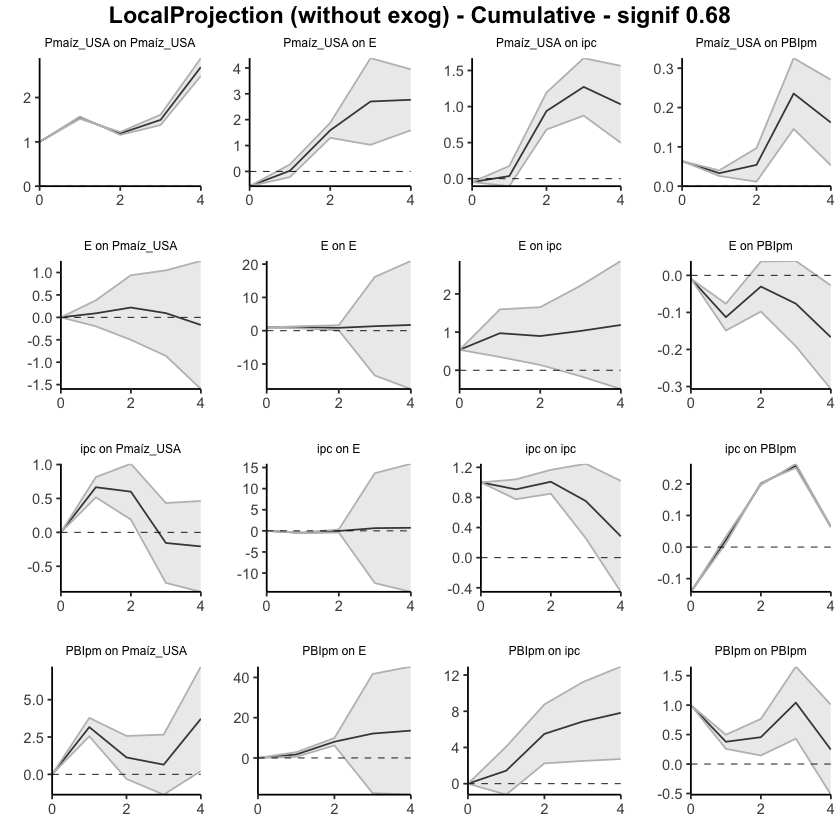

In [73]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000000,0.00000000
37,ipc,E,1,-0.4417288,-0.9598794996,0.07642189
38,ipc,E,2,0.3273834,0.0467521538,0.60801466
39,ipc,E,3,0.3806976,0.1208771328,0.64051813
40,ipc,E,4,0.2255646,0.0009010983,0.45022819


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.618811,0.9787426,2.258880
53,PBIpm,E,2,1.958372,1.1354220,2.781321
54,PBIpm,E,3,1.324768,0.4643633,2.185174
55,PBIpm,E,4,1.238594,0.2482258,2.228961


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.76059123,-0.76059123,-0.76059123
2,Ptrigo_USA,E,1,0.12665703,0.18037282,0.07294123
3,Ptrigo_USA,E,2,0.72395386,0.39236706,1.05554066
4,Ptrigo_USA,E,3,0.05084025,0.07764933,0.02403116
5,Ptrigo_USA,E,4,0.08317589,0.23596334,-0.06961157


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.03337215,0.03337215,0.03337215
12,Ptrigo_USA,PBIpm,1,0.03255491,0.02237127,0.04273856
13,Ptrigo_USA,PBIpm,2,-0.04299151,-0.03378859,-0.05219443
14,Ptrigo_USA,PBIpm,3,0.02679653,0.03307872,0.02051434
15,Ptrigo_USA,PBIpm,4,0.08498786,0.08573889,0.08423682


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.0000000,0.0000000,0.00000000
17,E,Ptrigo_USA,1,0.1931531,-0.1121341,0.49844034
18,E,Ptrigo_USA,2,0.2143395,-0.2604888,0.68916779
19,E,Ptrigo_USA,3,-0.1234312,-0.3215979,0.07473549
20,E,Ptrigo_USA,4,-0.2765058,-0.5950879,0.04207629


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Ptrigo_USA,1,0.07316315,-0.05085057,0.19717686
33,ipc,Ptrigo_USA,2,-0.19906999,-0.31531060,-0.08282937
34,ipc,Ptrigo_USA,3,-0.30157823,-0.43408457,-0.16907190
35,ipc,Ptrigo_USA,4,-0.30175088,-0.35787868,-0.24562308


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.27921313,-0.7277591,0.1693329
48,PBIpm,Ptrigo_USA,2,0.08480325,-0.5973648,0.7669713
49,PBIpm,Ptrigo_USA,3,-0.19716061,-0.6767854,0.2824642
50,PBIpm,Ptrigo_USA,4,-0.58919550,-1.3789234,0.2005324


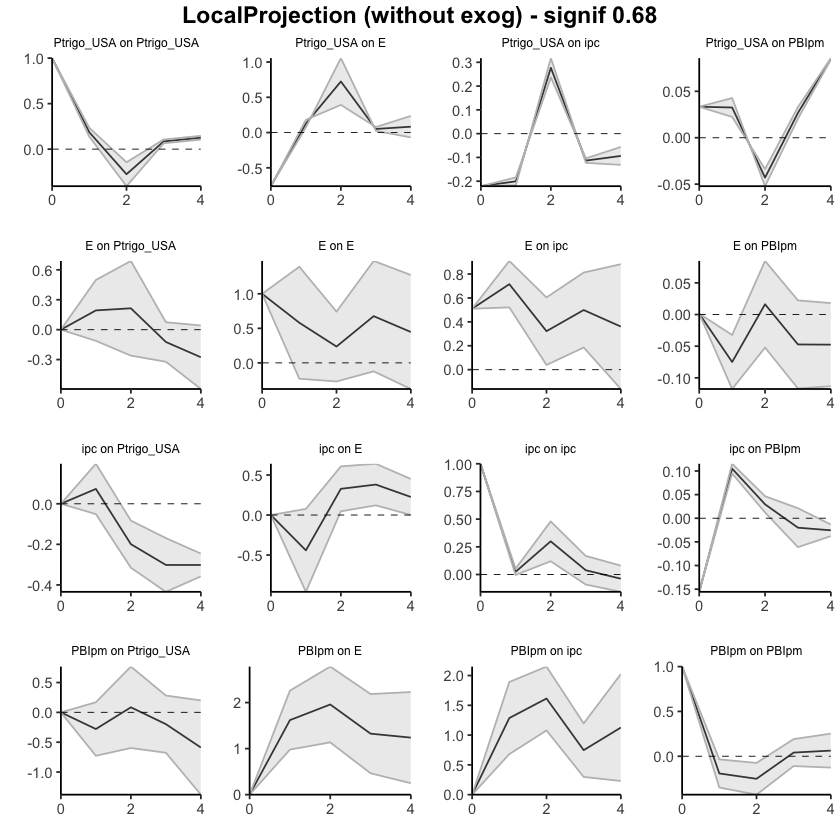

In [74]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.4417288,-0.9598795,0.07642189
38,ipc,E,2,-0.1143454,-0.9131273,0.68443655
39,ipc,E,3,0.2663522,-0.7922502,1.32495467
40,ipc,E,4,0.4919169,-0.7913491,1.77518286


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.618811,0.9787426,2.258880
53,PBIpm,E,2,3.577183,2.1141646,5.040202
54,PBIpm,E,3,4.901952,2.5785279,7.225375
55,PBIpm,E,4,6.140545,2.8267537,9.454337


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.76059123,-0.7605912,-0.7605912
2,Ptrigo_USA,E,1,-0.63393420,-0.5802184,-0.6876500
3,Ptrigo_USA,E,2,0.09001966,-0.1878513,0.3678907
4,Ptrigo_USA,E,3,0.14085990,-0.1102020,0.3919218
5,Ptrigo_USA,E,4,0.22403579,0.1257613,0.3223103


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.03337215,0.03337215,0.03337215
12,Ptrigo_USA,PBIpm,1,0.06592706,0.05574341,0.07611070
13,Ptrigo_USA,PBIpm,2,0.02293555,0.02195482,0.02391627
14,Ptrigo_USA,PBIpm,3,0.04973208,0.05503354,0.04443061
15,Ptrigo_USA,PBIpm,4,0.13471993,0.14077243,0.12866743


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.000000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,0.193153134,-0.1121341,0.4984403
18,E,Ptrigo_USA,2,0.407492613,-0.3726229,1.1876081
19,E,Ptrigo_USA,3,0.284061407,-0.6942208,1.2623436
20,E,Ptrigo_USA,4,0.007555618,-1.2893087,1.3044199


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Ptrigo_USA,1,0.07316315,-0.05085057,0.19717686
33,ipc,Ptrigo_USA,2,-0.12590684,-0.36616117,0.11434749
34,ipc,Ptrigo_USA,3,-0.42748507,-0.80024574,-0.05472441
35,ipc,Ptrigo_USA,4,-0.72923596,-1.15812442,-0.30034749


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.2792131,-0.7277591,0.1693329
48,PBIpm,Ptrigo_USA,2,-0.1944099,-1.3251239,0.9363041
49,PBIpm,Ptrigo_USA,3,-0.3915705,-2.0019093,1.2187683
50,PBIpm,Ptrigo_USA,4,-0.9807660,-3.3808328,1.4193008


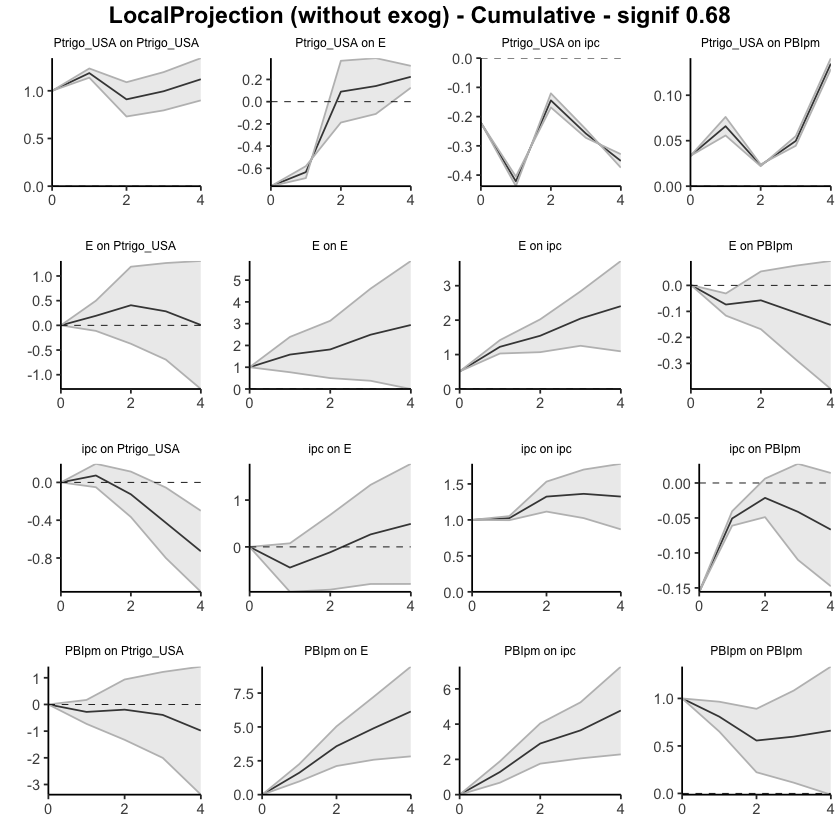

In [75]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,-0.47175966,-0.71363940,-0.2298799
38,ipc,E,2,-0.21676216,-0.28631610,-0.1472082
39,ipc,E,3,0.13439232,0.02303534,0.2457493
40,ipc,E,4,0.01573706,-0.23855061,0.2700247


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000000,0.000000,0.000000
52,PBIpm,E,1,1.859634430,1.347246,2.372023
53,PBIpm,E,2,4.299205862,3.633475,4.964936
54,PBIpm,E,3,4.435873577,3.062988,5.808759
55,PBIpm,E,4,-0.006018494,-3.558135,3.546098


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.155053091,-0.1550531,-0.1550531
2,Ptrigo_USA,E,1,0.002153221,-0.3821412,0.3864477
3,Ptrigo_USA,E,2,1.461910753,1.1364251,1.7873964
4,Ptrigo_USA,E,3,3.192070814,2.5873063,3.7968353
5,Ptrigo_USA,E,4,-0.022047479,-1.3465565,1.3024615


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,-0.02510084,-0.02510084,-0.02510084
12,Ptrigo_USA,PBIpm,1,0.10734745,0.03777547,0.17691942
13,Ptrigo_USA,PBIpm,2,0.08491646,0.03255456,0.13727836
14,Ptrigo_USA,PBIpm,3,0.04290674,-0.01623087,0.10204436
15,Ptrigo_USA,PBIpm,4,0.06010434,-0.04539885,0.16560753


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.0000000,0.00000000,0.00000000
17,E,Ptrigo_USA,1,0.3999433,0.07566131,0.72422520
18,E,Ptrigo_USA,2,0.1110319,-0.52942872,0.75149258
19,E,Ptrigo_USA,3,-0.2844901,-0.47124762,-0.09773257
20,E,Ptrigo_USA,4,-0.4120766,-0.61573154,-0.20842161


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.0000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.2843155,-0.3781753,-0.19045565
33,ipc,Ptrigo_USA,2,-0.3312484,-0.7486169,0.08612010
34,ipc,Ptrigo_USA,3,-0.1236979,-0.1866239,-0.06077196
35,ipc,Ptrigo_USA,4,-0.1671886,-0.2877214,-0.04665570


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.3379044,-0.8371388,0.1613300
48,PBIpm,Ptrigo_USA,2,-2.2630438,-2.7579493,-1.7681382
49,PBIpm,Ptrigo_USA,3,-1.3255904,-2.0685118,-0.5826691
50,PBIpm,Ptrigo_USA,4,1.7316085,1.4983680,1.9648491


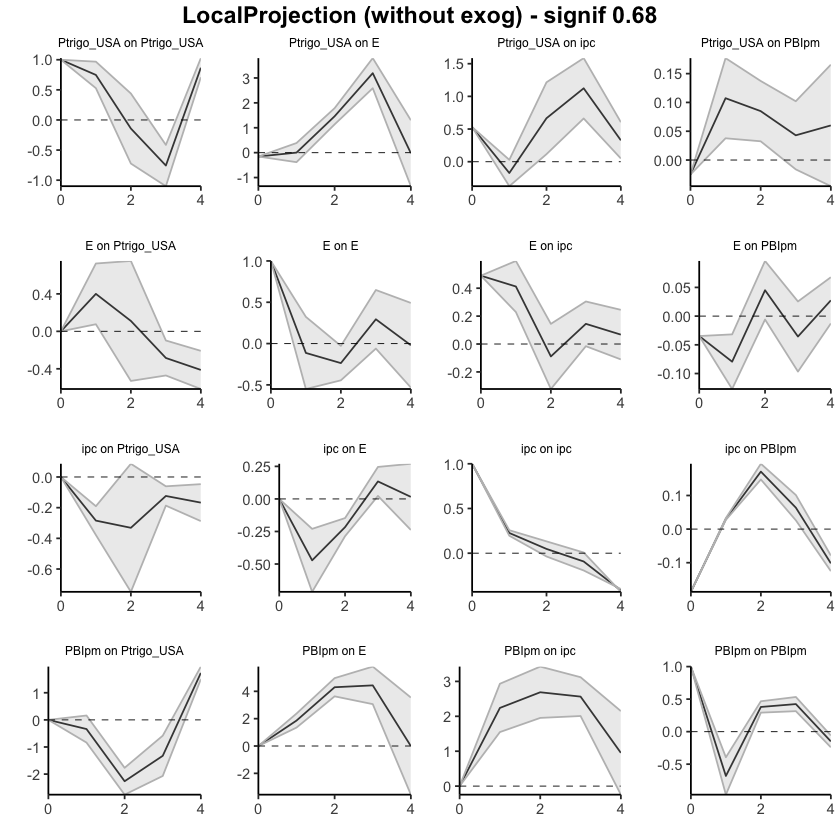

In [76]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.4717597,-0.7136394,-0.2298799
38,ipc,E,2,-0.6885218,-0.9999555,-0.3770881
39,ipc,E,3,-0.5541295,-0.9769202,-0.1313388
40,ipc,E,4,-0.5383924,-1.2154708,0.1386859


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.000000,0.000000
52,PBIpm,E,1,1.859634,1.347246,2.372023
53,PBIpm,E,2,6.158840,4.980721,7.336960
54,PBIpm,E,3,10.594714,8.043709,13.145719
55,PBIpm,E,4,10.588695,4.485574,16.691817


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.1550531,-0.1550531,-0.1550531
2,Ptrigo_USA,E,1,-0.1528999,-0.5371943,0.2313946
3,Ptrigo_USA,E,2,1.3090109,0.5992308,2.0187909
4,Ptrigo_USA,E,3,4.5010817,3.1865371,5.8156263
5,Ptrigo_USA,E,4,4.4790342,1.8399807,7.1180878


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,-0.02510084,-0.02510084,-0.02510084
12,Ptrigo_USA,PBIpm,1,0.08224661,0.01267464,0.15181859
13,Ptrigo_USA,PBIpm,2,0.16716307,0.04522919,0.28909695
14,Ptrigo_USA,PBIpm,3,0.21006981,0.02899832,0.39114130
15,Ptrigo_USA,PBIpm,4,0.27017415,-0.01640053,0.55674883


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.0000000,0.00000000,0.0000000
17,E,Ptrigo_USA,1,0.3999433,0.07566131,0.7242252
18,E,Ptrigo_USA,2,0.5109752,-0.45376740,1.4757178
19,E,Ptrigo_USA,3,0.2264851,-0.92501502,1.3779852
20,E,Ptrigo_USA,4,-0.1855915,-1.54074656,1.1695636


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
32,ipc,Ptrigo_USA,1,-0.2843155,-0.3781753,-0.1904556
33,ipc,Ptrigo_USA,2,-0.6155639,-1.1267922,-0.1043355
34,ipc,Ptrigo_USA,3,-0.7392618,-1.3134160,-0.1651075
35,ipc,Ptrigo_USA,4,-0.9064503,-1.6011375,-0.2117632


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.3379044,-0.8371388,0.1613300
48,PBIpm,Ptrigo_USA,2,-2.6009482,-3.5950881,-1.6068082
49,PBIpm,Ptrigo_USA,3,-3.9265386,-5.6635999,-2.1894773
50,PBIpm,Ptrigo_USA,4,-2.1949301,-4.1652320,-0.2246282


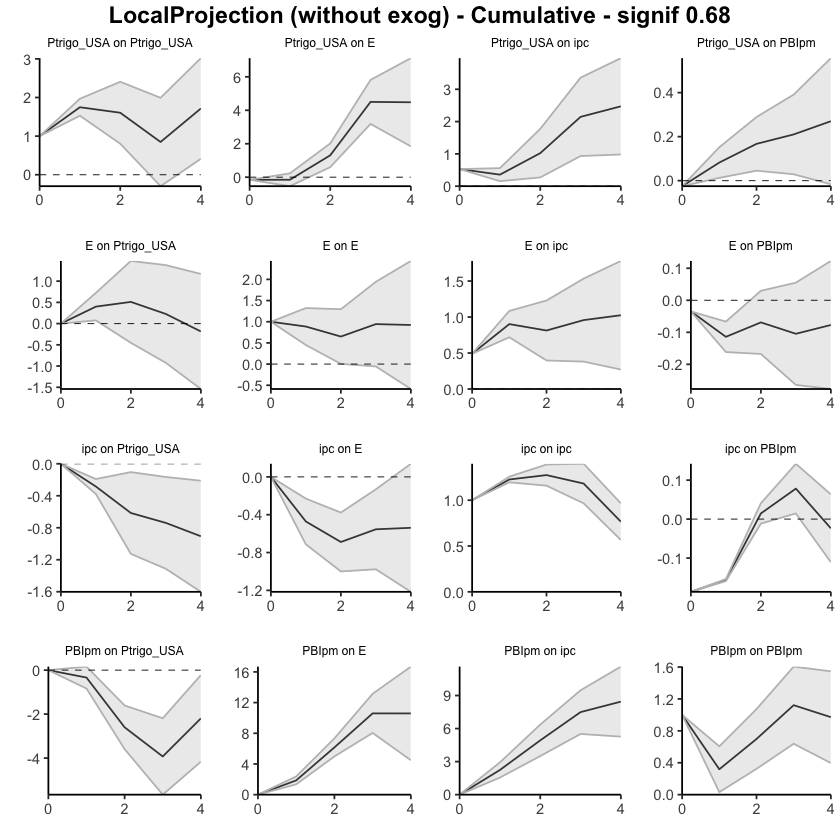

In [77]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

### 1935-1975. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.1952219,-0.37957883,-0.01086502
13,ipc,E,2,0.5980393,0.28219110,0.91388755
14,ipc,E,3,0.4568596,0.08350989,0.83020927
15,ipc,E,4,0.2575032,0.03024316,0.48476324


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.000000
22,PBIpm,E,1,1.8761271,1.27378103,2.478473
23,PBIpm,E,2,1.9372412,0.63704012,3.237442
24,PBIpm,E,3,1.2322258,0.27068809,2.193763
25,PBIpm,E,4,0.9885576,-0.01304069,1.990156


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4554628,0.4554628,0.4554628
2,E,ipc,1,0.6445529,0.2644802,1.0246256
3,E,ipc,2,0.2095062,-0.2516164,0.6706288
4,E,ipc,3,0.4412015,0.1427410,0.7396619
5,E,ipc,4,0.2950486,-0.2636566,0.8537538


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.4172562,0.7835785,2.050934
28,PBIpm,ipc,2,1.6414050,0.9500932,2.332717
29,PBIpm,ipc,3,0.7743448,0.2226590,1.326031
30,PBIpm,ipc,4,1.1693456,0.1840644,2.154627


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01376624,-0.01376624,-0.01376624
7,E,PBIpm,1,-0.08225488,-0.12150333,-0.04300643
8,E,PBIpm,2,0.02302481,-0.04146665,0.08751627
9,E,PBIpm,3,-0.04392986,-0.10717195,0.01931222
10,E,PBIpm,4,-0.04858515,-0.11026370,0.01309340


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.13498810,-0.134988102,-0.134988102
17,ipc,PBIpm,1,0.10659910,0.095589528,0.117608665
18,ipc,PBIpm,2,0.01831341,-0.003489636,0.040116452
19,ipc,PBIpm,3,-0.02188422,-0.064974689,0.021206242
20,ipc,PBIpm,4,-0.02331699,-0.041160839,-0.005473132


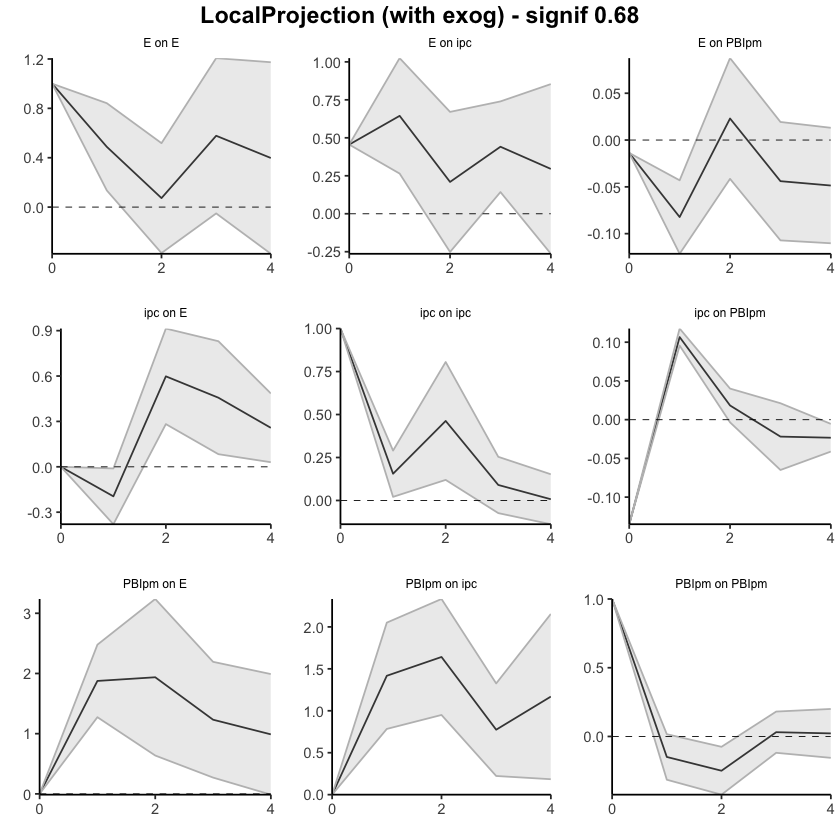

In [78]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.1952219,-0.37957883,-0.01086502
13,ipc,E,2,0.4028174,-0.09738774,0.90302253
14,ipc,E,3,0.8596770,-0.01387785,1.73323180
15,ipc,E,4,1.1171802,0.01636532,2.21799504


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.000000,0.000000
22,PBIpm,E,1,1.876127,1.273781,2.478473
23,PBIpm,E,2,3.813368,1.910821,5.715916
24,PBIpm,E,3,5.045594,2.181509,7.909679
25,PBIpm,E,4,6.034152,2.168469,9.899835


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4554628,0.4554628,0.4554628
2,E,ipc,1,1.1000157,0.7199430,1.4800884
3,E,ipc,2,1.3095219,0.4683267,2.1507172
4,E,ipc,3,1.7507234,0.6110677,2.8903791
5,E,ipc,4,2.0457720,0.3474111,3.7441329


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.417256,0.7835785,2.050934
28,PBIpm,ipc,2,3.058661,1.7336717,4.383651
29,PBIpm,ipc,3,3.833006,1.9563307,5.709681
30,PBIpm,ipc,4,5.002352,2.1403952,7.864308


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01376624,-0.01376624,-0.01376624
7,E,PBIpm,1,-0.09602112,-0.13526958,-0.05677267
8,E,PBIpm,2,-0.07299631,-0.17673623,0.03074360
9,E,PBIpm,3,-0.11692617,-0.28390817,0.05005582
10,E,PBIpm,4,-0.16551132,-0.39417187,0.06314922


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.13498810,-0.13498810,-0.13498810
17,ipc,PBIpm,1,-0.02838901,-0.03939857,-0.01737944
18,ipc,PBIpm,2,-0.01007560,-0.04288821,0.02273701
19,ipc,PBIpm,3,-0.03195982,-0.10786290,0.04394326
20,ipc,PBIpm,4,-0.05527681,-0.14902374,0.03847012


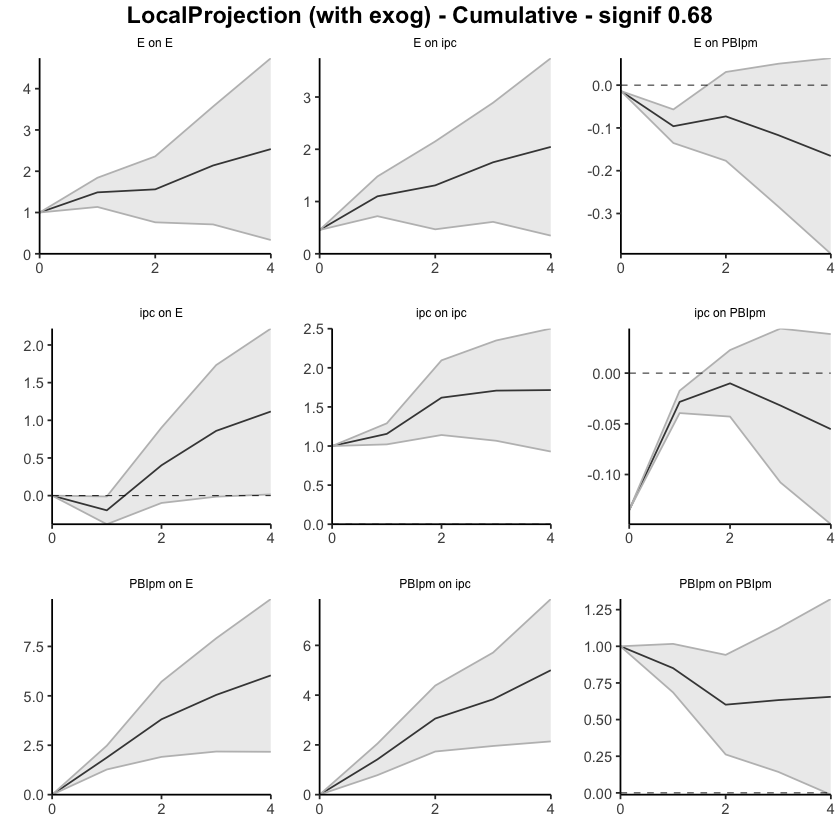

In [79]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.2460497,-0.44821867,-0.04388081
13,ipc,E,2,0.6804260,0.07167019,1.28918178
14,ipc,E,3,0.4767694,-0.01308539,0.96662421
15,ipc,E,4,0.2876957,0.03322011,0.54217126


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,1.694131,0.9924685,2.395793
23,PBIpm,E,2,2.246717,1.2888483,3.204586
24,PBIpm,E,3,1.386337,0.4064146,2.366259
25,PBIpm,E,4,1.244024,0.1116892,2.376358


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4501820,0.4501820,0.4501820
2,E,ipc,1,0.6578894,0.2347680,1.0810107
3,E,ipc,2,0.1847100,-0.3983737,0.7677937
4,E,ipc,3,0.4327923,0.1610174,0.7045671
5,E,ipc,4,0.2870686,-0.1601016,0.7342388


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.3047517,0.6981213,1.911382
28,PBIpm,ipc,2,1.7643157,0.8421604,2.686471
29,PBIpm,ipc,3,0.7972557,0.3014973,1.293014
30,PBIpm,ipc,4,1.1778442,0.2287604,2.126928


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01671361,-0.01671361,-0.016713610
7,E,PBIpm,1,-0.06968885,-0.10237748,-0.037000211
8,E,PBIpm,2,0.02752998,-0.03120818,0.086268143
9,E,PBIpm,3,-0.05478491,-0.11743790,0.007868089
10,E,PBIpm,4,-0.04514705,-0.10430656,0.014012458


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.13585242,-0.135852421,-0.13585242
17,ipc,PBIpm,1,0.08627658,0.080567474,0.09198569
18,ipc,PBIpm,2,0.01279036,-0.005015764,0.03059648
19,ipc,PBIpm,3,-0.01334154,-0.060281991,0.03359890
20,ipc,PBIpm,4,-0.02976137,-0.048568906,-0.01095384


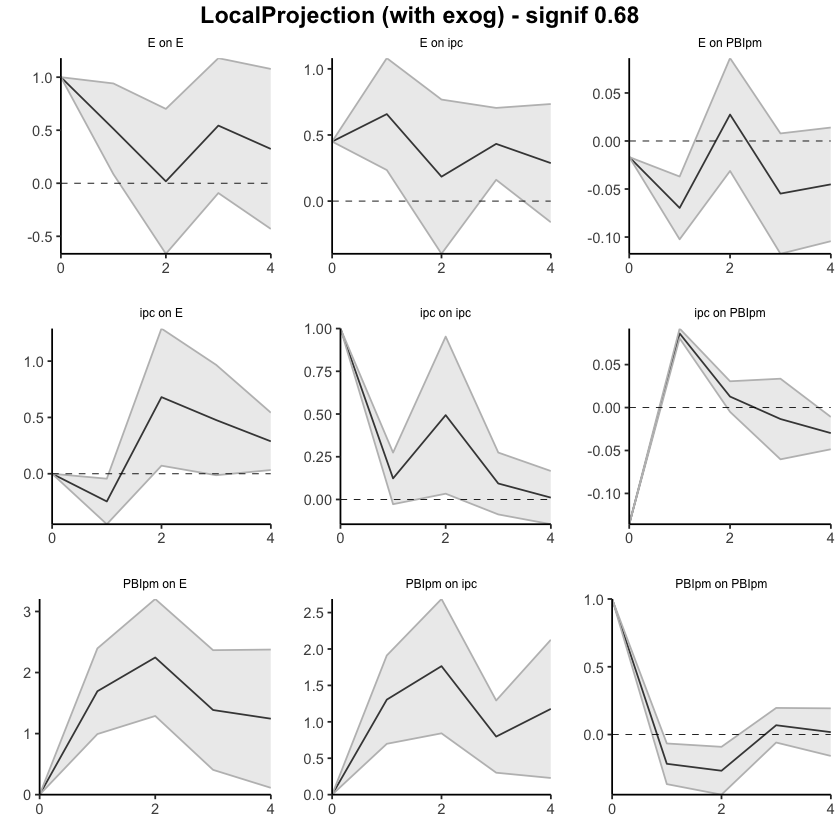

In [80]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.2460497,-0.4482187,-0.04388081
13,ipc,E,2,0.4343762,-0.3765485,1.24530096
14,ipc,E,3,0.9111456,-0.3896339,2.21192517
15,ipc,E,4,1.1988413,-0.3564138,2.75409644


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,1.694131,0.9924685,2.395793
23,PBIpm,E,2,3.940848,2.2813168,5.600380
24,PBIpm,E,3,5.327185,2.6877314,7.966638
25,PBIpm,E,4,6.571209,2.7994205,10.342997


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.450182,0.4501820,0.450182
2,E,ipc,1,1.108071,0.6849500,1.531193
3,E,ipc,2,1.292781,0.2865763,2.298986
4,E,ipc,3,1.725574,0.4475937,3.003554
5,E,ipc,4,2.012642,0.2874921,3.737792


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.304752,0.6981213,1.911382
28,PBIpm,ipc,2,3.069067,1.5402817,4.597853
29,PBIpm,ipc,3,3.866323,1.8417790,5.890867
30,PBIpm,ipc,4,5.044167,2.0705394,8.017795


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01671361,-0.01671361,-0.01671361
7,E,PBIpm,1,-0.08640246,-0.11909109,-0.05371382
8,E,PBIpm,2,-0.05887248,-0.15029927,0.03255432
9,E,PBIpm,3,-0.11365738,-0.26773717,0.04042241
10,E,PBIpm,4,-0.15880444,-0.37204374,0.05443487


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.13585242,-0.13585242,-0.13585242
17,ipc,PBIpm,1,-0.04957584,-0.05528495,-0.04386673
18,ipc,PBIpm,2,-0.03678549,-0.06030071,-0.01327026
19,ipc,PBIpm,3,-0.05012703,-0.12058270,0.02032865
20,ipc,PBIpm,4,-0.07988840,-0.16915161,0.00937481


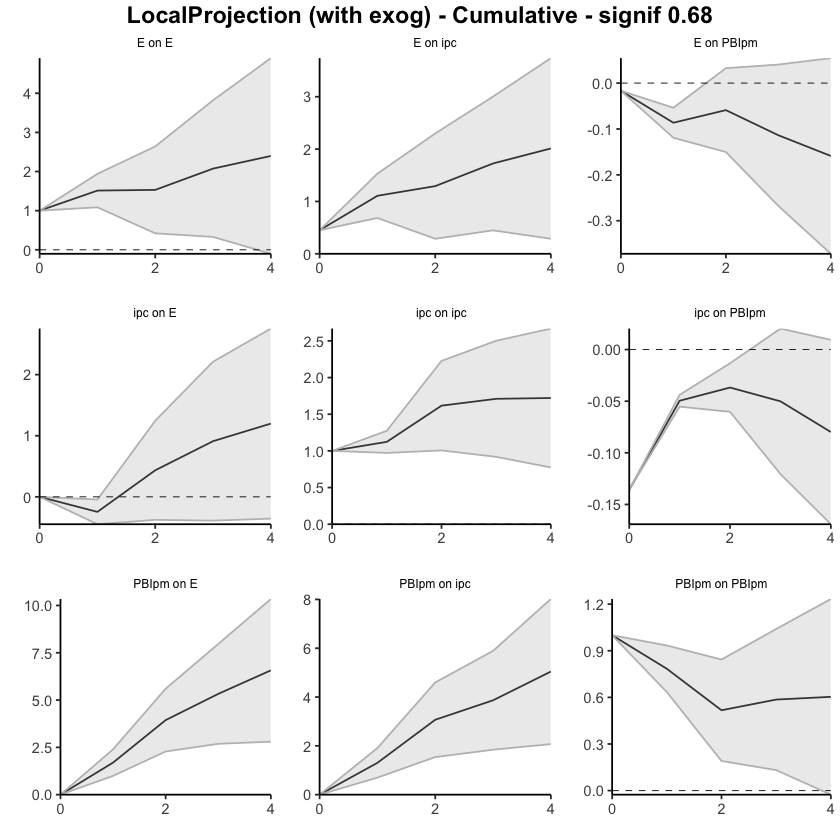

In [83]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.000000000,0.0000000
12,ipc,E,1,-0.4064699,-0.938561792,0.1256219
13,ipc,E,2,0.3700381,0.071482449,0.6685938
14,ipc,E,3,0.4095520,0.130991295,0.6881128
15,ipc,E,4,0.2525421,0.006307631,0.4987765


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,1.618811,0.9787426,2.258880
23,PBIpm,E,2,1.958372,1.1354220,2.781321
24,PBIpm,E,3,1.324768,0.4643633,2.185174
25,PBIpm,E,4,1.238594,0.2482258,2.228961


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4523002,0.452300250,0.4523002
2,E,ipc,1,0.6870960,0.507034902,0.8671571
3,E,ipc,2,0.2708495,0.009894668,0.5318044
4,E,ipc,3,0.4811544,0.184245093,0.7780637
5,E,ipc,4,0.3389982,-0.157724177,0.8357206


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.2859761,0.6800327,1.891920
28,PBIpm,ipc,2,1.6141051,1.0782789,2.149931
29,PBIpm,ipc,3,0.7469716,0.2976759,1.196267
30,PBIpm,ipc,4,1.1266816,0.2289607,2.024402


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01051853,-0.01051853,-0.01051853
7,E,PBIpm,1,-0.07702564,-0.11579231,-0.03825898
8,E,PBIpm,2,0.01975932,-0.04394743,0.08346607
9,E,PBIpm,3,-0.04695807,-0.11101447,0.01709833
10,E,PBIpm,4,-0.04744036,-0.10840374,0.01352302


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.13385575,-0.133855747,-0.133855747
17,ipc,PBIpm,1,0.10072777,0.086973877,0.114481660
18,ipc,PBIpm,2,0.02396923,0.002920618,0.045017852
19,ipc,PBIpm,3,-0.01905548,-0.063513617,0.025402660
20,ipc,PBIpm,4,-0.02410195,-0.040517144,-0.007686751


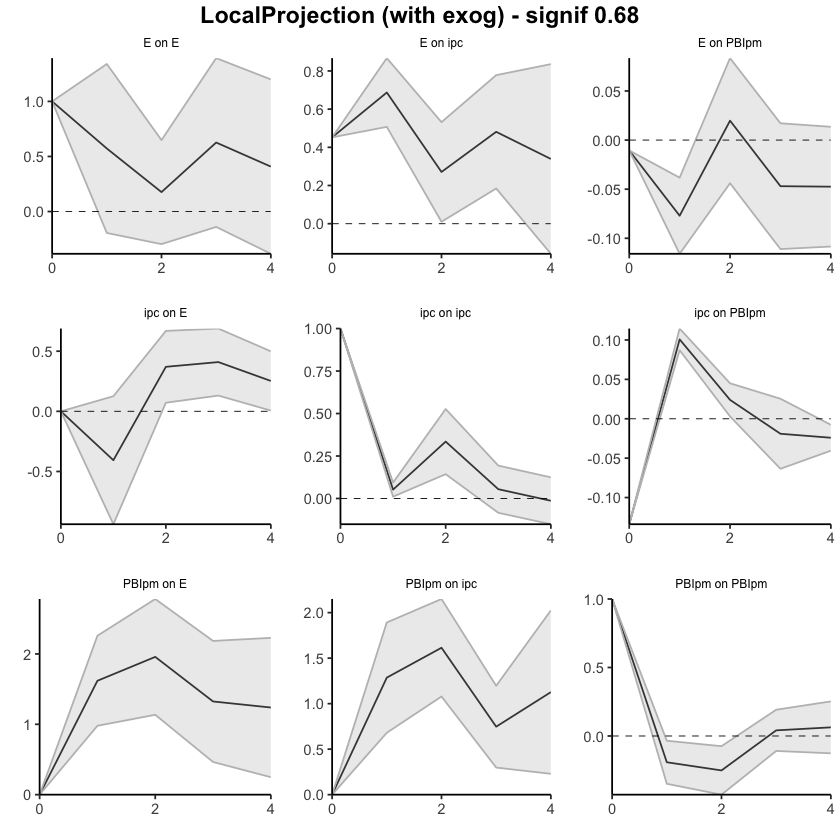

In [82]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.40646995,-0.9385618,0.1256219
13,ipc,E,2,-0.03643182,-0.8670793,0.7942157
14,ipc,E,3,0.37312021,-0.7360880,1.4823285
15,ipc,E,4,0.62566230,-0.7297804,1.9811050


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,1.618811,0.9787426,2.258880
23,PBIpm,E,2,3.577183,2.1141646,5.040202
24,PBIpm,E,3,4.901952,2.5785279,7.225375
25,PBIpm,E,4,6.140545,2.8267537,9.454337


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4523002,0.4523002,0.4523002
2,E,ipc,1,1.1393963,0.9593352,1.3194574
3,E,ipc,2,1.4102458,0.9692298,1.8512617
4,E,ipc,3,1.8914002,1.1534749,2.6293254
5,E,ipc,4,2.2303984,0.9957507,3.4650460


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.285976,0.6800327,1.891920
28,PBIpm,ipc,2,2.900081,1.7583115,4.041851
29,PBIpm,ipc,3,3.647053,2.0559874,5.238118
30,PBIpm,ipc,4,4.773734,2.2849481,7.262521


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01051853,-0.01051853,-0.01051853
7,E,PBIpm,1,-0.08754417,-0.12631083,-0.04877750
8,E,PBIpm,2,-0.06778485,-0.17025827,0.03468857
9,E,PBIpm,3,-0.11474292,-0.28127274,0.05178690
10,E,PBIpm,4,-0.16218328,-0.38967648,0.06530992


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.133855747,-0.13385575,-0.13385575
17,ipc,PBIpm,1,-0.033127979,-0.04688187,-0.01937409
18,ipc,PBIpm,2,-0.009158744,-0.04396125,0.02564376
19,ipc,PBIpm,3,-0.028214223,-0.10747487,0.05104642
20,ipc,PBIpm,4,-0.052316170,-0.14799201,0.04335967


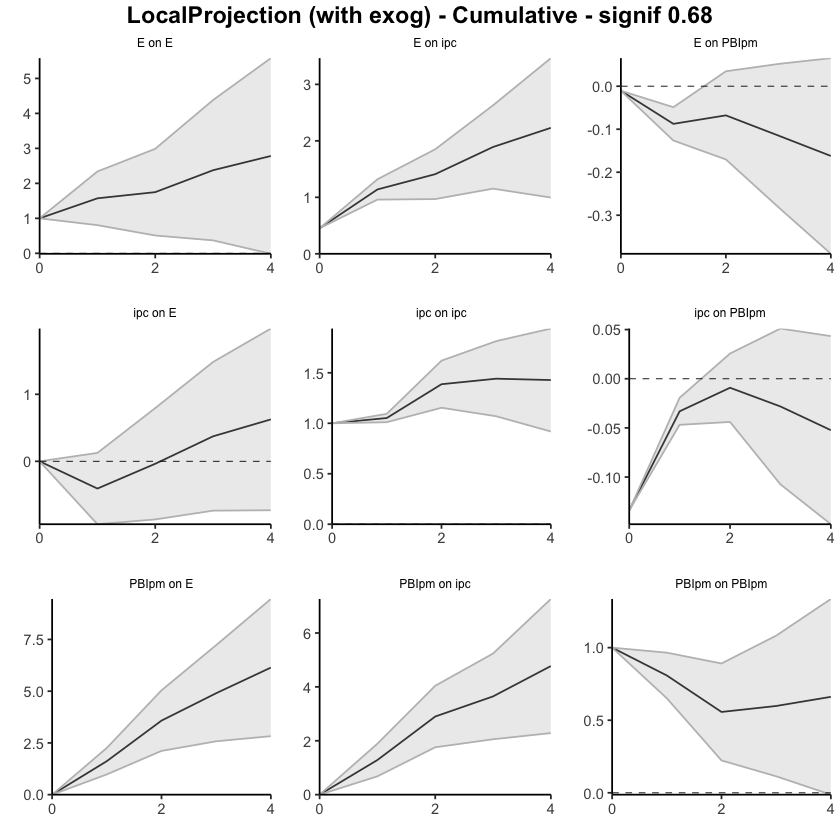

In [84]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

### 1935-1982. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.1741131,-0.2973342,-0.05089194
38,ipc,E,2,0.6286147,-0.4301733,1.68740261
39,ipc,E,3,0.5890213,0.1870753,0.99096729
40,ipc,E,4,0.4763810,0.0174971,0.93526494


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,0.6913563,-0.2850759,1.667789
53,PBIpm,E,2,2.2951721,1.3374282,3.252916
54,PBIpm,E,3,1.0874541,-0.3225453,2.497453
55,PBIpm,E,4,0.6342713,-0.2816944,1.550237


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.7156522,-0.71565222,-0.7156522
2,Psoja_USA,E,1,-0.3275505,-0.37729420,-0.2778068
3,Psoja_USA,E,2,0.3782426,0.43087137,0.3256137
4,Psoja_USA,E,3,0.2649829,-0.02420793,0.5541737
5,Psoja_USA,E,4,0.1223182,0.11095392,0.1336826


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.060975256,0.060975256,0.06097526
12,Psoja_USA,PBIpm,1,0.003885794,-0.013799859,0.02157145
13,Psoja_USA,PBIpm,2,-0.028284980,-0.038798952,-0.01777101
14,Psoja_USA,PBIpm,3,0.021178643,0.006602463,0.03575482
15,Psoja_USA,PBIpm,4,0.046307348,0.033545301,0.05906940


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.00000000,0.000000000
17,E,Psoja_USA,1,-0.01180065,-0.21322241,0.189621100
18,E,Psoja_USA,2,0.18778379,0.04887241,0.326695178
19,E,Psoja_USA,3,-0.01094720,-0.16873803,0.146843633
20,E,Psoja_USA,4,-0.13468264,-0.25962200,-0.009743283


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Psoja_USA,1,0.05121216,-0.04657069,0.14899501
33,ipc,Psoja_USA,2,-0.15978995,-0.22043378,-0.09914613
34,ipc,Psoja_USA,3,-0.18556984,-0.26486651,-0.10627317
35,ipc,Psoja_USA,4,-0.01147705,-0.03352200,0.01056789


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Psoja_USA,1,-0.02047814,-0.4715117,0.4305554
48,PBIpm,Psoja_USA,2,-1.22475154,-1.7395447,-0.7099584
49,PBIpm,Psoja_USA,3,0.47914746,-0.1733264,1.1316213
50,PBIpm,Psoja_USA,4,0.56787283,-0.1599936,1.2957393


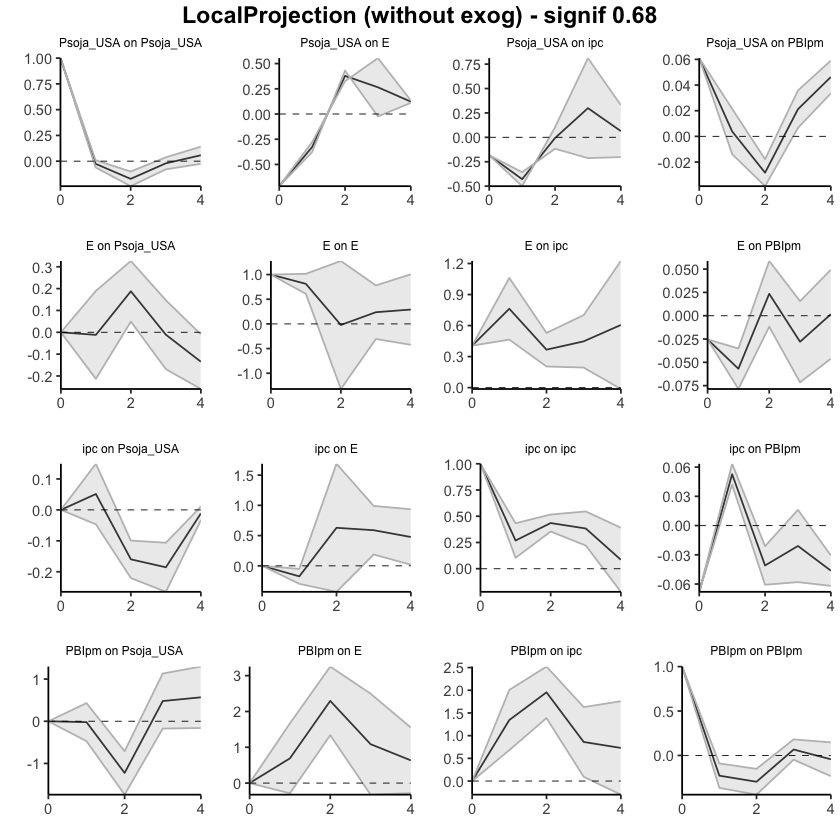

In [85]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.1741131,-0.2973342,-0.05089194
38,ipc,E,2,0.4545016,-0.7275075,1.63651066
39,ipc,E,3,1.0435229,-0.5404321,2.62747796
40,ipc,E,4,1.5199039,-0.5229350,3.56274289


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,0.6913563,-0.2850759,1.667789
53,PBIpm,E,2,2.9865284,1.0523523,4.920705
54,PBIpm,E,3,4.0739825,0.7298070,7.418158
55,PBIpm,E,4,4.7082538,0.4481125,8.968395


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.7156522,-0.7156522,-0.71565222
2,Psoja_USA,E,1,-1.0432027,-1.0929464,-0.99345903
3,Psoja_USA,E,2,-0.6649602,-0.6620750,-0.66784530
4,Psoja_USA,E,3,-0.3999773,-0.6862830,-0.11367157
5,Psoja_USA,E,4,-0.2776590,-0.5753290,0.02001099


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.06097526,0.060975256,0.06097526
12,Psoja_USA,PBIpm,1,0.06486105,0.047175397,0.08254670
13,Psoja_USA,PBIpm,2,0.03657607,0.008376445,0.06477570
14,Psoja_USA,PBIpm,3,0.05775471,0.014978908,0.10053052
15,Psoja_USA,PBIpm,4,0.10406206,0.048524209,0.15959992


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.0000000,0.0000000
17,E,Psoja_USA,1,-0.01180065,-0.2132224,0.1896211
18,E,Psoja_USA,2,0.17598314,-0.1643500,0.5163163
19,E,Psoja_USA,3,0.16503594,-0.3330880,0.6631599
20,E,Psoja_USA,4,0.03035330,-0.5927100,0.6534166


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Psoja_USA,1,0.05121216,-0.04657069,0.14899501
33,ipc,Psoja_USA,2,-0.10857779,-0.26700447,0.04984888
34,ipc,Psoja_USA,3,-0.29414763,-0.53187097,-0.05642429
35,ipc,Psoja_USA,4,-0.30562469,-0.56539298,-0.04585640


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Psoja_USA,1,-0.02047814,-0.4715117,0.4305554
48,PBIpm,Psoja_USA,2,-1.24522968,-2.2110564,-0.2794030
49,PBIpm,Psoja_USA,3,-0.76608223,-2.3843828,0.8522184
50,PBIpm,Psoja_USA,4,-0.19820940,-2.5443765,2.1479577


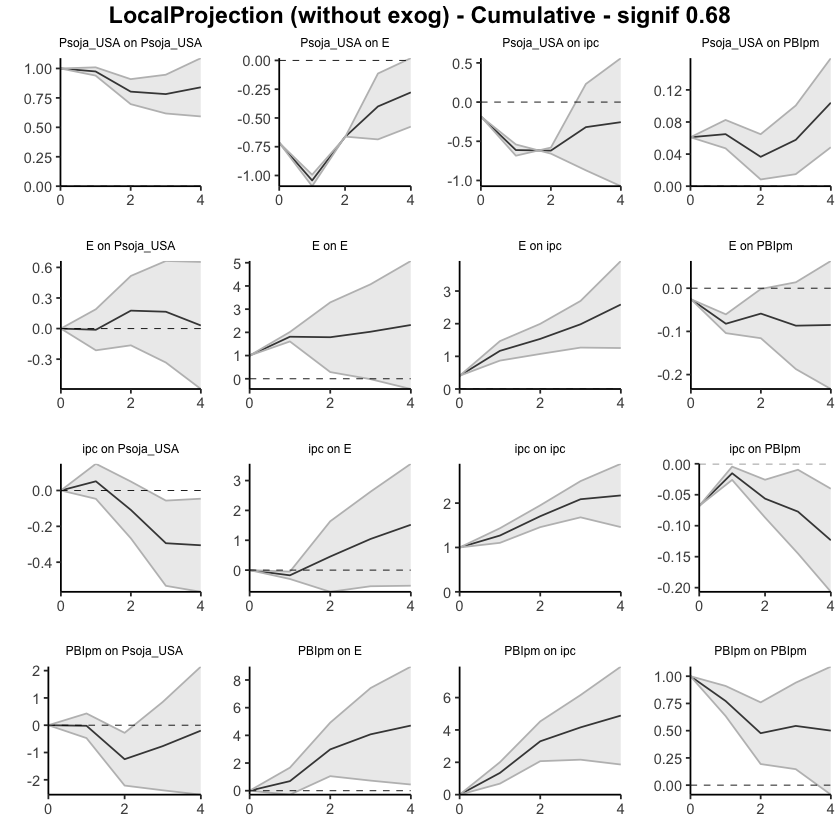

In [86]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.1494078,-0.2301312,-0.06868435
38,ipc,E,2,0.6421772,0.3148879,0.96946637
39,ipc,E,3,0.6575498,0.3534245,0.96167510
40,ipc,E,4,0.5509561,0.2687400,0.83317212


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000
52,PBIpm,E,1,0.7602659,-0.28475019,1.805282
53,PBIpm,E,2,2.2435412,1.32045439,3.166628
54,PBIpm,E,3,1.2787784,0.26464149,2.292915
55,PBIpm,E,4,0.8978625,0.05795159,1.737773


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.1568921,-0.156892140,-0.1568921
2,Pmaíz_USA,E,1,0.2591948,0.002830201,0.5155594
3,Pmaíz_USA,E,2,0.5419445,0.156935712,0.9269534
4,Pmaíz_USA,E,3,0.3466416,0.158468670,0.5348146
5,Pmaíz_USA,E,4,0.1203508,0.066863889,0.1738378


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.01447017,0.014470173,0.014470173
12,Pmaíz_USA,PBIpm,1,0.01242510,-0.003197074,0.028047276
13,Pmaíz_USA,PBIpm,2,-0.02333032,-0.044696476,-0.001964165
14,Pmaíz_USA,PBIpm,3,-0.02896208,-0.056786337,-0.001137826
15,Pmaíz_USA,PBIpm,4,0.05758747,0.033769158,0.081405790


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.00000000,0.00000000
17,E,Pmaíz_USA,1,-0.15975029,-0.30361594,-0.01588464
18,E,Pmaíz_USA,2,0.04955755,-0.14683868,0.24595379
19,E,Pmaíz_USA,3,0.01292132,-0.11114915,0.13699179
20,E,Pmaíz_USA,4,0.01772548,-0.05079249,0.08624346


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Pmaíz_USA,1,0.13447374,0.03535394,0.23359353
33,ipc,Pmaíz_USA,2,-0.04590248,-0.12294526,0.03114029
34,ipc,Pmaíz_USA,3,-0.05207383,-0.15604682,0.05189915
35,ipc,Pmaíz_USA,4,-0.09405845,-0.14013388,-0.04798303


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.0000000,0.0000000,0.00000000
47,PBIpm,Pmaíz_USA,1,-0.1997788,-0.7558631,0.35630535
48,PBIpm,Pmaíz_USA,2,-0.5383872,-1.0040930,-0.07268147
49,PBIpm,Pmaíz_USA,3,0.1440782,-0.5406785,0.82883492
50,PBIpm,Pmaíz_USA,4,0.1765690,-0.6392923,0.99243030


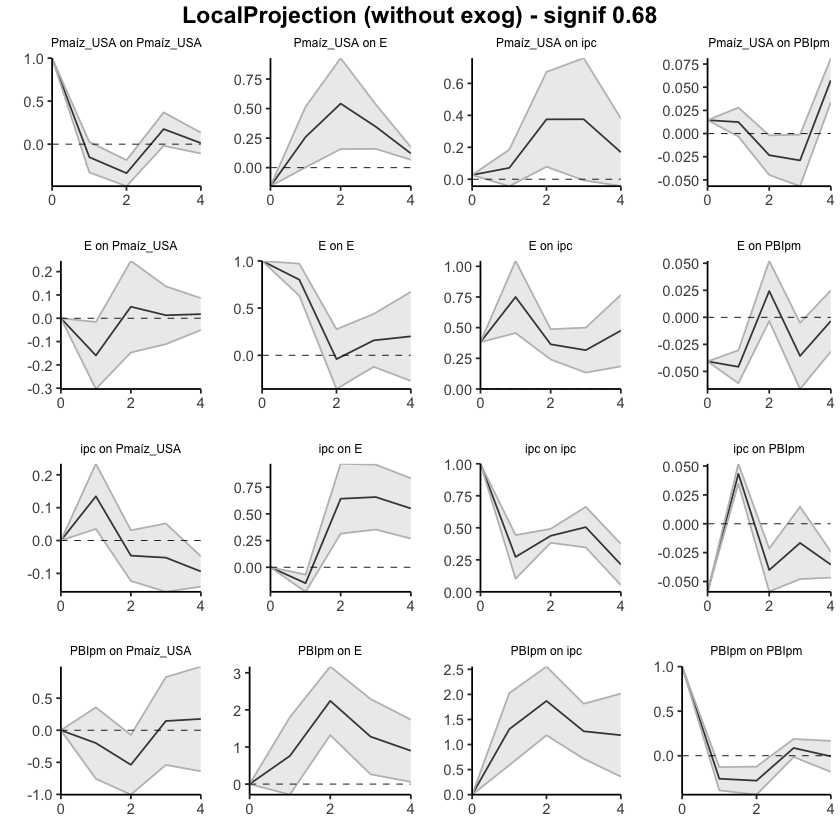

In [87]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.00000000
37,ipc,E,1,-0.1494078,-0.23013122,-0.06868435
38,ipc,E,2,0.4927694,0.08475671,0.90078202
39,ipc,E,3,1.1503192,0.43818119,1.86245712
40,ipc,E,4,1.7012752,0.70692119,2.69562924


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,0.7602659,-0.2847502,1.805282
53,PBIpm,E,2,3.0038071,1.0357042,4.971910
54,PBIpm,E,3,4.2825855,1.3003457,7.264825
55,PBIpm,E,4,5.1804480,1.3582973,9.002599


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.1568921,-0.156892140,-0.1568921
2,Pmaíz_USA,E,1,0.1023026,-0.154061939,0.3586672
3,Pmaíz_USA,E,2,0.6442472,0.002873774,1.2856206
4,Pmaíz_USA,E,3,0.9908888,0.161342444,1.8204352
5,Pmaíz_USA,E,4,1.1112396,0.228206332,1.9942730


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.014470173,0.01447017,0.01447017
12,Pmaíz_USA,PBIpm,1,0.026895274,0.01127310,0.04251745
13,Pmaíz_USA,PBIpm,2,0.003564954,-0.03342338,0.04055328
14,Pmaíz_USA,PBIpm,3,-0.025397128,-0.09020971,0.03941546
15,Pmaíz_USA,PBIpm,4,0.032190347,-0.05644056,0.12082125


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,-0.15975029,-0.3036159,-0.01588464
18,E,Pmaíz_USA,2,-0.11019273,-0.4504546,0.23006915
19,E,Pmaíz_USA,3,-0.09727141,-0.5616038,0.36706094
20,E,Pmaíz_USA,4,-0.07954593,-0.6123963,0.45330440


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Pmaíz_USA,1,0.13447374,0.03535394,0.2335935
33,ipc,Pmaíz_USA,2,0.08857125,-0.08759131,0.2647338
34,ipc,Pmaíz_USA,3,0.03649742,-0.24363813,0.3166330
35,ipc,Pmaíz_USA,4,-0.05756103,-0.38377201,0.2686500


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Pmaíz_USA,1,-0.1997788,-0.7558631,0.3563054
48,PBIpm,Pmaíz_USA,2,-0.7381661,-1.7599560,0.2836239
49,PBIpm,Pmaíz_USA,3,-0.5940879,-2.3006345,1.1124588
50,PBIpm,Pmaíz_USA,4,-0.4175189,-2.9399268,2.1048891


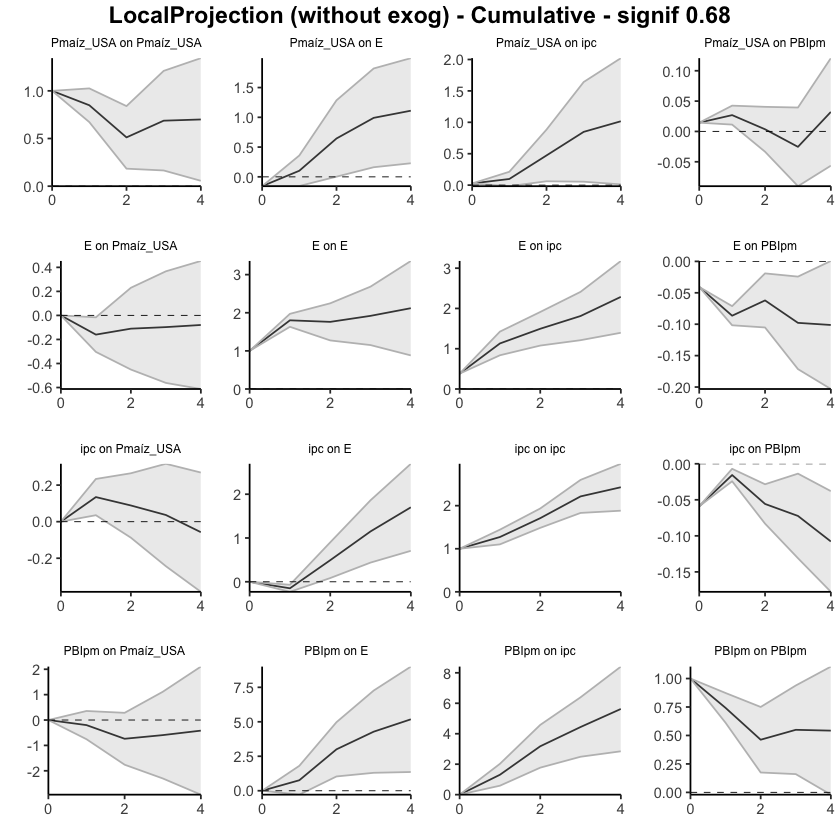

In [88]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.1960695,-0.3018268,-0.09031219
38,ipc,E,2,0.5310939,0.3501922,0.71199555
39,ipc,E,3,0.5133236,0.1956038,0.83104332
40,ipc,E,4,0.4892215,0.2284539,0.74998913


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000
52,PBIpm,E,1,0.9820501,0.01437508,1.949725
53,PBIpm,E,2,2.4927250,1.63930635,3.346144
54,PBIpm,E,3,1.4386212,0.45174829,2.425494
55,PBIpm,E,4,1.0170055,0.30788374,1.726127


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.63204744,-0.6320474,-0.6320474
2,Ptrigo_USA,E,1,-0.04510322,-0.2192040,0.1289975
3,Ptrigo_USA,E,2,0.95604532,0.6600854,1.2520053
4,Ptrigo_USA,E,3,0.84853356,0.6934725,1.0035946
5,Ptrigo_USA,E,4,0.39263488,0.5224577,0.2628121


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.006648923,0.006648923,0.006648923
12,Ptrigo_USA,PBIpm,1,0.031873882,0.011089504,0.052658259
13,Ptrigo_USA,PBIpm,2,-0.056579241,-0.069947628,-0.043210855
14,Ptrigo_USA,PBIpm,3,-0.012236393,-0.016166471,-0.008306316
15,Ptrigo_USA,PBIpm,4,0.029347086,0.032556624,0.026137549


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.000000000,0.00000000,0.00000000
17,E,Ptrigo_USA,1,-0.036162203,-0.22478043,0.15245602
18,E,Ptrigo_USA,2,-0.058367984,-0.45903604,0.34230007
19,E,Ptrigo_USA,3,0.009567021,-0.06357364,0.08270768
20,E,Ptrigo_USA,4,0.034453272,-0.08871440,0.15762094


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Ptrigo_USA,1,0.02331786,-0.06732732,0.1139630
33,ipc,Ptrigo_USA,2,0.06098990,-0.15599669,0.2779765
34,ipc,Ptrigo_USA,3,-0.01763305,-0.06877980,0.0335137
35,ipc,Ptrigo_USA,4,-0.15056699,-0.18147248,-0.1196615


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.14312112,-0.5191151,0.2328728
48,PBIpm,Ptrigo_USA,2,0.23929831,-0.1773267,0.6559233
49,PBIpm,Ptrigo_USA,3,0.00351832,-0.5069671,0.5140038
50,PBIpm,Ptrigo_USA,4,-0.15447199,-0.8842461,0.5753021


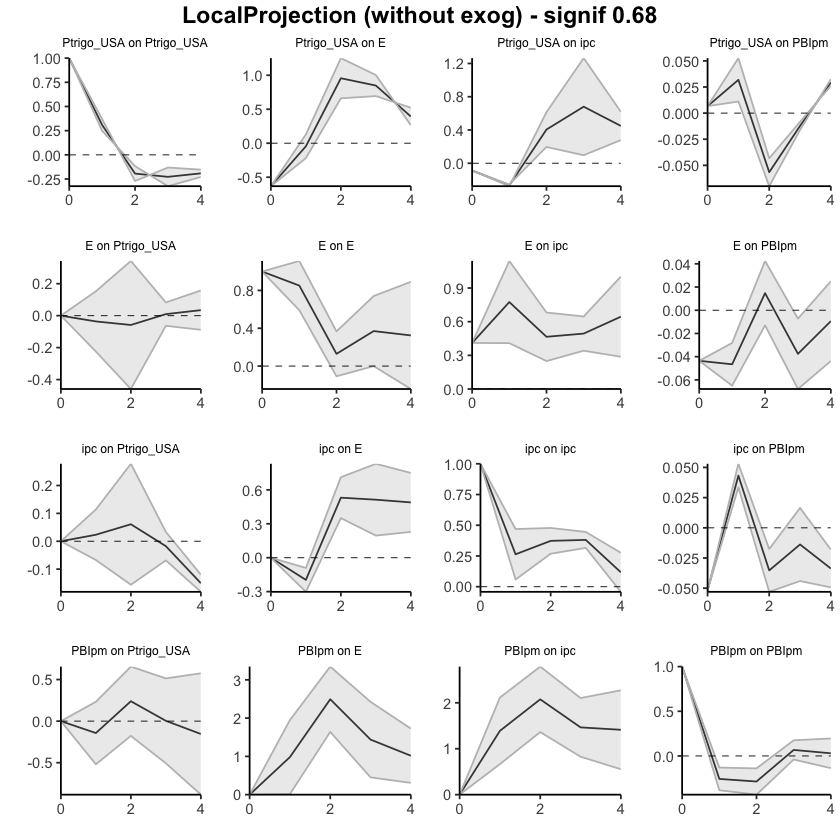

In [89]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.1960695,-0.3018268,-0.09031219
38,ipc,E,2,0.3350244,0.0483654,0.62168335
39,ipc,E,3,0.8483479,0.2439692,1.45272667
40,ipc,E,4,1.3375695,0.4724231,2.20271580


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000
52,PBIpm,E,1,0.9820501,0.01437508,1.949725
53,PBIpm,E,2,3.4747750,1.65368143,5.295869
54,PBIpm,E,3,4.9133963,2.10542972,7.721363
55,PBIpm,E,4,5.9304018,2.41331347,9.447490


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.6320474,-0.6320474,-0.6320474
2,Ptrigo_USA,E,1,-0.6771507,-0.8512514,-0.5030499
3,Ptrigo_USA,E,2,0.2788947,-0.1911661,0.7489554
4,Ptrigo_USA,E,3,1.1274282,0.5023065,1.7525500
5,Ptrigo_USA,E,4,1.5200631,1.0247641,2.0153620


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.0066489227,0.006648923,0.006648923
12,Ptrigo_USA,PBIpm,1,0.0385228042,0.017738427,0.059307181
13,Ptrigo_USA,PBIpm,2,-0.0180564372,-0.052209201,0.016096327
14,Ptrigo_USA,PBIpm,3,-0.0302928306,-0.068375672,0.007790011
15,Ptrigo_USA,PBIpm,4,-0.0009457443,-0.035819049,0.033927560


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,-0.03616220,-0.2247804,0.1524560
18,E,Ptrigo_USA,2,-0.09453019,-0.6838165,0.4947561
19,E,Ptrigo_USA,3,-0.08496317,-0.7473901,0.5774638
20,E,Ptrigo_USA,4,-0.05050989,-0.8361045,0.7350847


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Ptrigo_USA,1,0.02331786,-0.06732732,0.1139630
33,ipc,Ptrigo_USA,2,0.08430776,-0.22332402,0.3919395
34,ipc,Ptrigo_USA,3,0.06667471,-0.29210381,0.4254532
35,ipc,Ptrigo_USA,4,-0.08389228,-0.47357629,0.3057917


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.14312112,-0.5191151,0.2328728
48,PBIpm,Ptrigo_USA,2,0.09617719,-0.6964418,0.8887962
49,PBIpm,Ptrigo_USA,3,0.09969551,-1.2034089,1.4027999
50,PBIpm,Ptrigo_USA,4,-0.05477648,-2.0876550,1.9781020


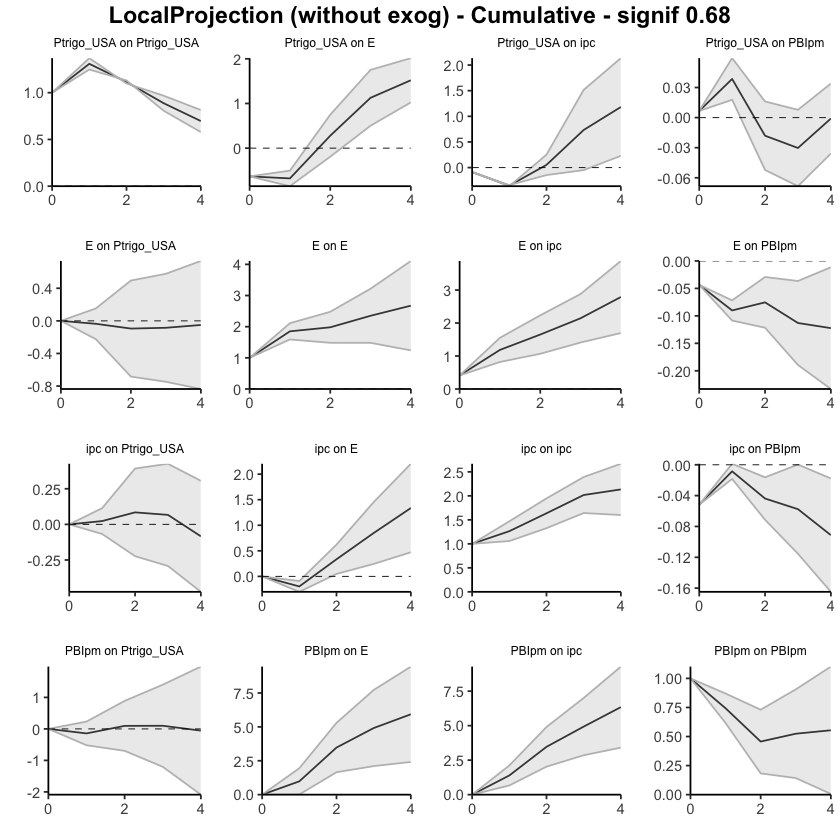

In [90]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.000000000,0.00000000,0.0000000
37,ipc,E,1,-0.740631058,-0.89422814,-0.5870340
38,ipc,E,2,-0.002566948,-0.20699852,0.2018646
39,ipc,E,3,0.498824560,0.02095127,0.9766978
40,ipc,E,4,-0.114971992,-0.75914767,0.5292037


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.00000000,0.00000000,0.0000000
52,PBIpm,E,1,-0.02758064,-0.74233977,0.6871785
53,PBIpm,E,2,1.79633222,0.95329449,2.6393699
54,PBIpm,E,3,0.95500613,-0.08380689,1.9938191
55,PBIpm,E,4,-0.33265753,-1.07438187,0.4090668


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.6561104,-0.6561104,-0.6561104
2,Ptrigo_USA,E,1,-0.2898877,-0.2903456,-0.2894298
3,Ptrigo_USA,E,2,0.7867866,0.7134702,0.8601030
4,Ptrigo_USA,E,3,0.8453917,0.6515635,1.0392200
5,Ptrigo_USA,E,4,0.3541161,0.2597520,0.4484802


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.01381763,0.01381763,0.013817629
12,Ptrigo_USA,PBIpm,1,0.04449288,0.02701005,0.061975708
13,Ptrigo_USA,PBIpm,2,-0.05471229,-0.07479671,-0.034627868
14,Ptrigo_USA,PBIpm,3,-0.01051291,-0.01402191,-0.007003905
15,Ptrigo_USA,PBIpm,4,0.03511640,0.03556951,0.034663289


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.000000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,0.034160906,-0.2376093,0.3059311
18,E,Ptrigo_USA,2,-0.066458764,-0.4449566,0.3120390
19,E,Ptrigo_USA,3,-0.000555569,-0.1725437,0.1714325
20,E,Ptrigo_USA,4,0.043493375,-0.1598687,0.2468555


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.000000000,0.00000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.293780058,-0.52711053,-0.06044958
33,ipc,Ptrigo_USA,2,0.008095378,-0.21609609,0.23228685
34,ipc,Ptrigo_USA,3,0.244113740,0.07716984,0.41105764
35,ipc,Ptrigo_USA,4,0.064870671,-0.07592982,0.20567116


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.08754085,-0.5659933,0.3909116
48,PBIpm,Ptrigo_USA,2,0.10635187,-0.4023743,0.6150781
49,PBIpm,Ptrigo_USA,3,0.42104037,-0.3283868,1.1704675
50,PBIpm,Ptrigo_USA,4,0.10139030,-0.7943823,0.9971629


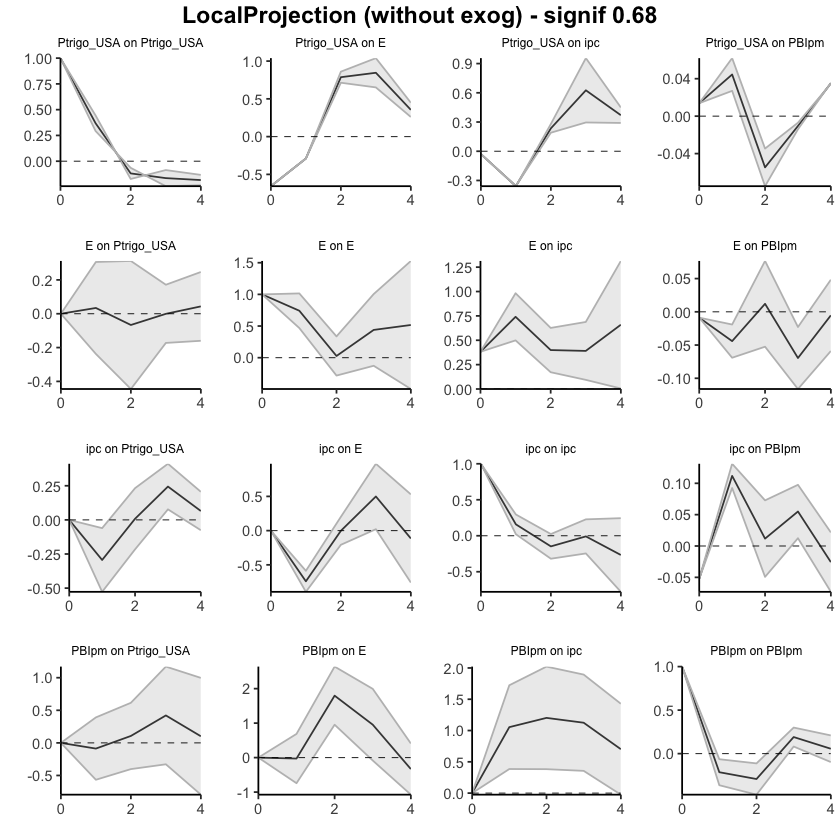

In [91]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.7406311,-0.8942281,-0.5870340
38,ipc,E,2,-0.7431980,-1.1012267,-0.3851694
39,ipc,E,3,-0.2443734,-1.0802754,0.5915285
40,ipc,E,4,-0.3593454,-1.8394230,1.1207322


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.00000000,0.0000000,0.0000000
52,PBIpm,E,1,-0.02758064,-0.7423398,0.6871785
53,PBIpm,E,2,1.76875158,0.2109547,3.3265484
54,PBIpm,E,3,2.72375770,0.1271478,5.3203676
55,PBIpm,E,4,2.39110018,-0.9472340,5.7294344


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.6561104,-0.6561104,-0.65611039
2,Ptrigo_USA,E,1,-0.9459981,-0.9464560,-0.94554014
3,Ptrigo_USA,E,2,-0.1592115,-0.2329858,-0.08543718
4,Ptrigo_USA,E,3,0.6861803,0.4185777,0.95378280
5,Ptrigo_USA,E,4,1.0402964,0.6783298,1.40226302


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.013817629,0.01381763,0.01381763
12,Ptrigo_USA,PBIpm,1,0.058310506,0.04082767,0.07579334
13,Ptrigo_USA,PBIpm,2,0.003598216,-0.03396904,0.04116547
14,Ptrigo_USA,PBIpm,3,-0.006914690,-0.04799094,0.03416156
15,Ptrigo_USA,PBIpm,4,0.028201709,-0.01242144,0.06882485


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,0.03416091,-0.2376093,0.3059311
18,E,Ptrigo_USA,2,-0.03229786,-0.6825659,0.6179701
19,E,Ptrigo_USA,3,-0.03285343,-0.8551095,0.7894027
20,E,Ptrigo_USA,4,0.01063995,-1.0149783,1.0362582


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.29378006,-0.5271105,-0.06044958
33,ipc,Ptrigo_USA,2,-0.28568468,-0.7432066,0.17183727
34,ipc,Ptrigo_USA,3,-0.04157094,-0.6660368,0.58289491
35,ipc,Ptrigo_USA,4,0.02329973,-0.7419666,0.78856607


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.08754085,-0.5659933,0.3909116
48,PBIpm,Ptrigo_USA,2,0.01881102,-0.9683676,1.0059896
49,PBIpm,Ptrigo_USA,3,0.43985139,-1.2967544,2.1764571
50,PBIpm,Ptrigo_USA,4,0.54124169,-2.0911366,3.1736200


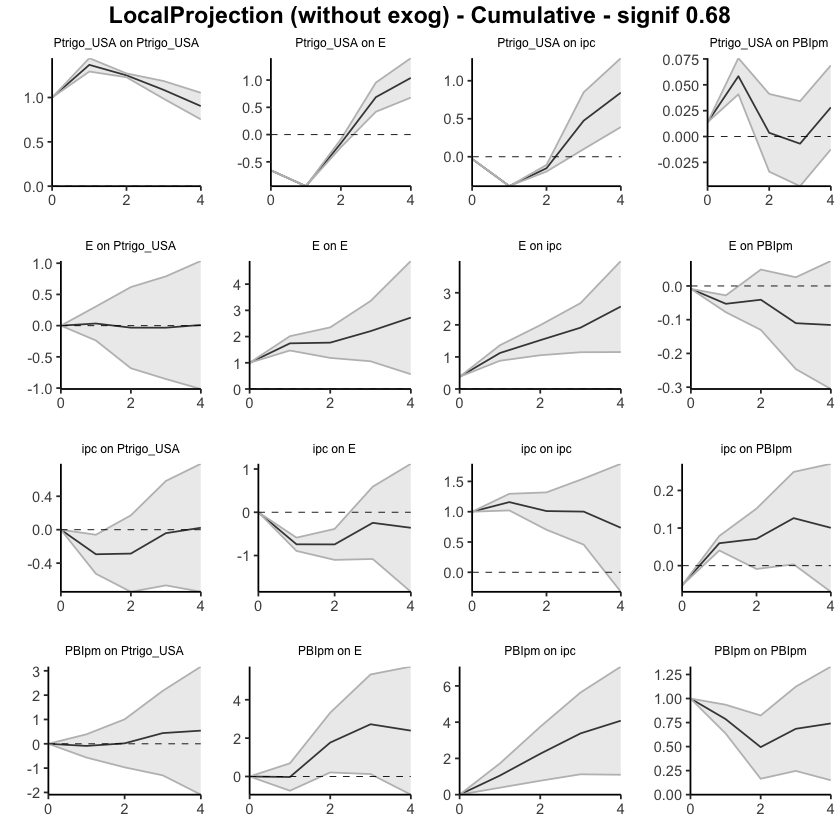

In [92]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

### 1943-1982. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.1674267,-0.30009131,-0.03476203
13,ipc,E,2,0.6508123,-0.41723840,1.71886298
14,ipc,E,3,0.5995386,0.18395586,1.01512126
15,ipc,E,4,0.4825153,0.01477271,0.95025796


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,0.6913563,-0.2850759,1.667789
23,PBIpm,E,2,2.2951721,1.3374282,3.252916
24,PBIpm,E,3,1.0874541,-0.3225453,2.497453
25,PBIpm,E,4,0.6342713,-0.2816944,1.550237


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3793129,0.379312887,0.3793129
2,E,ipc,1,0.7388085,0.452988085,1.0246289
3,E,ipc,2,0.3311309,0.177781231,0.4844805
4,E,ipc,3,0.4266616,0.186977888,0.6663453
5,E,ipc,4,0.5943875,-0.003771417,1.1925463


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.00000000,0.000000
27,PBIpm,ipc,1,1.3444283,0.68161033,2.007246
28,PBIpm,ipc,2,1.9545793,1.38779046,2.521368
29,PBIpm,ipc,3,0.8609502,0.09295774,1.628943
30,PBIpm,ipc,4,0.7295038,-0.29968779,1.758695


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.035955754,-0.035955754,-0.03595575
7,E,PBIpm,1,-0.055448519,-0.075200845,-0.03569619
8,E,PBIpm,2,0.028215250,-0.004725855,0.06115636
9,E,PBIpm,3,-0.028222302,-0.069339238,0.01289463
10,E,PBIpm,4,0.003355591,-0.041620696,0.04833188


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.05832402,-0.05832402,-0.05832402
17,ipc,PBIpm,1,0.05047364,0.03840961,0.06253767
18,ipc,PBIpm,2,-0.04382064,-0.06500534,-0.02263594
19,ipc,PBIpm,3,-0.02031142,-0.05850658,0.01788375
20,ipc,PBIpm,4,-0.04669527,-0.06414664,-0.02924390


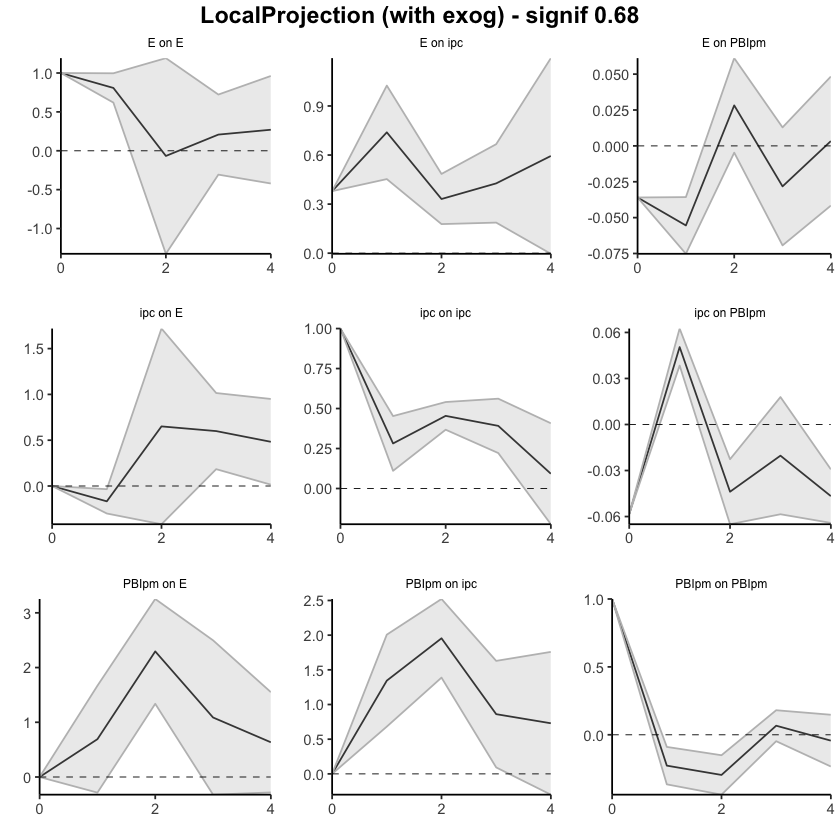

In [93]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.1674267,-0.3000913,-0.03476203
13,ipc,E,2,0.4833856,-0.7173297,1.68410095
14,ipc,E,3,1.0829242,-0.5333738,2.69922221
15,ipc,E,4,1.5654395,-0.5186011,3.64948016


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,0.6913563,-0.2850759,1.667789
23,PBIpm,E,2,2.9865284,1.0523523,4.920705
24,PBIpm,E,3,4.0739825,0.7298070,7.418158
25,PBIpm,E,4,4.7082538,0.4481125,8.968395


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3793129,0.3793129,0.3793129
2,E,ipc,1,1.1181214,0.8323010,1.4039418
3,E,ipc,2,1.4492522,1.0100822,1.8884223
4,E,ipc,3,1.8759138,1.1970601,2.5547675
5,E,ipc,4,2.4703013,1.1932887,3.7473138


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.344428,0.6816103,2.007246
28,PBIpm,ipc,2,3.299008,2.0694008,4.528614
29,PBIpm,ipc,3,4.159958,2.1623585,6.157557
30,PBIpm,ipc,4,4.889462,1.8626707,7.916252


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03595575,-0.03595575,-0.035955754
7,E,PBIpm,1,-0.09140427,-0.11115660,-0.071651946
8,E,PBIpm,2,-0.06318902,-0.11588245,-0.010495590
9,E,PBIpm,3,-0.09141132,-0.18522169,0.002399044
10,E,PBIpm,4,-0.08805573,-0.22684239,0.050730922


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.058324024,-0.05832402,-0.058324024
17,ipc,PBIpm,1,-0.007850385,-0.01991442,0.004213646
18,ipc,PBIpm,2,-0.051671026,-0.08491975,-0.018422297
19,ipc,PBIpm,3,-0.071982443,-0.14342633,-0.000538551
20,ipc,PBIpm,4,-0.118677715,-0.20757298,-0.029782451


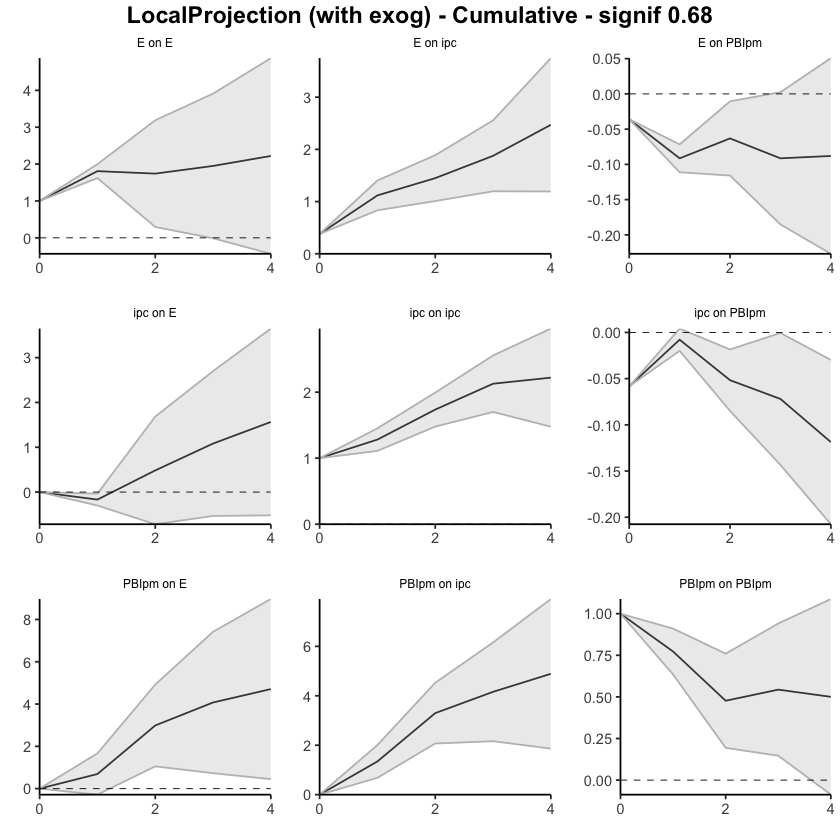

In [94]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.1467012,-0.2311450,-0.06225734
13,ipc,E,2,0.6501644,0.3195889,0.98073994
14,ipc,E,3,0.6621024,0.3543666,0.96983815
15,ipc,E,4,0.5541526,0.2689463,0.83935879


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.000000
22,PBIpm,E,1,0.7602659,-0.28475019,1.805282
23,PBIpm,E,2,2.2435412,1.32045439,3.166628
24,PBIpm,E,3,1.2787784,0.26464149,2.292915
25,PBIpm,E,4,0.8978625,0.05795159,1.737773


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3744558,0.3744558,0.3744558
2,E,ipc,1,0.7463138,0.4545520,1.0380757
3,E,ipc,2,0.3590336,0.2369208,0.4811464
4,E,ipc,3,0.3115917,0.1301329,0.4930505
5,E,ipc,4,0.4730474,0.1838667,0.7622282


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.306710,0.5883313,2.025089
28,PBIpm,ipc,2,1.869446,1.1843585,2.554533
29,PBIpm,ipc,3,1.264780,0.7163620,1.813198
30,PBIpm,ipc,4,1.186618,0.3582252,2.015011


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.041397029,-0.041397029,-0.041397029
7,E,PBIpm,1,-0.045755610,-0.060774224,-0.030736996
8,E,PBIpm,2,0.024906149,-0.002605602,0.052417901
9,E,PBIpm,3,-0.035671800,-0.065911932,-0.005431667
10,E,PBIpm,4,-0.003112516,-0.031133931,0.024908900


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.05541656,-0.05541656,-0.05541656
17,ipc,PBIpm,1,0.04242559,0.03331614,0.05153504
18,ipc,PBIpm,2,-0.04110052,-0.06033610,-0.02186494
19,ipc,PBIpm,3,-0.01631506,-0.04802136,0.01539124
20,ipc,PBIpm,4,-0.03547635,-0.04728439,-0.02366830


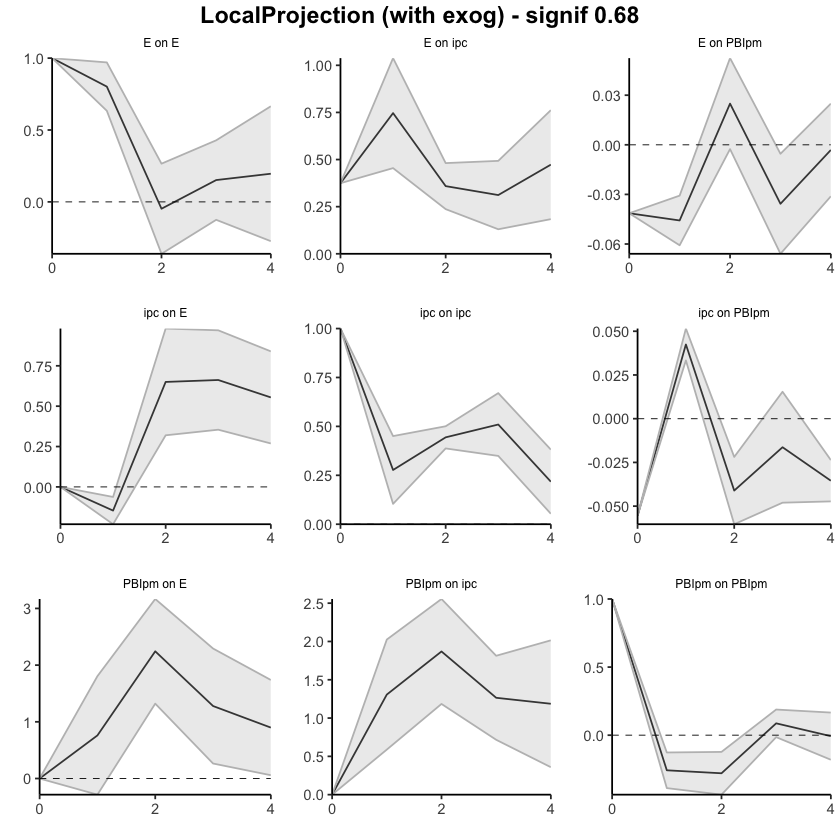

In [95]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.1467012,-0.23114497,-0.06225734
13,ipc,E,2,0.5034633,0.08844393,0.91848260
14,ipc,E,3,1.1655657,0.44281057,1.88832074
15,ipc,E,4,1.7197182,0.71175688,2.72767954


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,0.7602659,-0.2847502,1.805282
23,PBIpm,E,2,3.0038071,1.0357042,4.971910
24,PBIpm,E,3,4.2825855,1.3003457,7.264825
25,PBIpm,E,4,5.1804480,1.3582973,9.002599


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3744558,0.3744558,0.3744558
2,E,ipc,1,1.1207696,0.8290078,1.4125315
3,E,ipc,2,1.4798033,1.0659286,1.8936779
4,E,ipc,3,1.7913949,1.1960615,2.3867284
5,E,ipc,4,2.2644423,1.3799282,3.1489565


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.306710,0.5883313,2.025089
28,PBIpm,ipc,2,3.176156,1.7726898,4.579623
29,PBIpm,ipc,3,4.440936,2.4890518,6.392821
30,PBIpm,ipc,4,5.627554,2.8472771,8.407832


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.04139703,-0.04139703,-0.0413970285
7,E,PBIpm,1,-0.08715264,-0.10217125,-0.0721340248
8,E,PBIpm,2,-0.06224649,-0.10477685,-0.0197161238
9,E,PBIpm,3,-0.09791829,-0.17068879,-0.0251477907
10,E,PBIpm,4,-0.10103080,-0.20182272,-0.0002388909


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.05541656,-0.05541656,-0.055416556
17,ipc,PBIpm,1,-0.01299097,-0.02210042,-0.003881513
18,ipc,PBIpm,2,-0.05409148,-0.08243651,-0.025746449
19,ipc,PBIpm,3,-0.07040654,-0.13045788,-0.010355209
20,ipc,PBIpm,4,-0.10588289,-0.17774227,-0.034023510


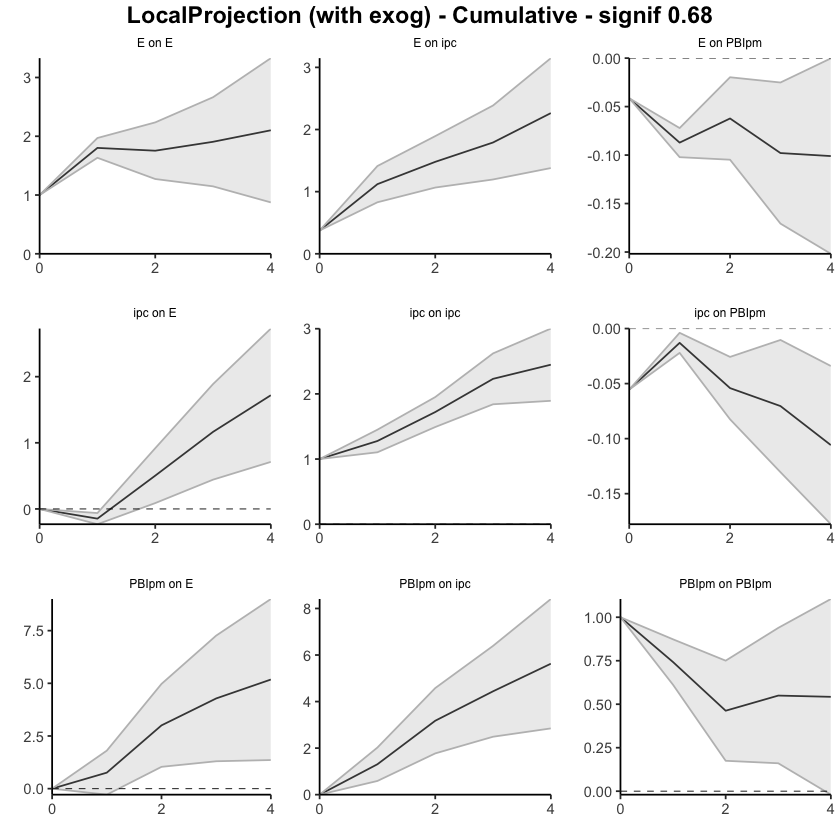

In [97]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,-0.7468156,-0.8807562,-0.6128750
13,ipc,E,2,0.1071019,-0.1476607,0.3618645
14,ipc,E,3,0.8855588,0.5094384,1.2616792
15,ipc,E,4,0.1917333,-0.2037924,0.5872589


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.0000000
22,PBIpm,E,1,-0.3065642,-1.17249366,0.5593652
23,PBIpm,E,2,1.4126599,0.48518487,2.3401348
24,PBIpm,E,3,1.0449077,-0.06916685,2.1589822
25,PBIpm,E,4,-0.2483401,-1.14893045,0.6522502


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3303814,0.33038136,0.3303814
2,E,ipc,1,0.7429633,0.53024676,0.9556799
3,E,ipc,2,0.4027601,0.18308246,0.6224377
4,E,ipc,3,0.2672143,0.07641606,0.4580125
5,E,ipc,4,0.4869265,0.07942838,0.8944245


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.00000000,0.000000
27,PBIpm,ipc,1,0.9576703,0.20732502,1.708016
28,PBIpm,ipc,2,0.8184153,-0.06301684,1.699847
29,PBIpm,ipc,3,0.9961440,0.23953684,1.752751
30,PBIpm,ipc,4,0.5611280,-0.31101564,1.433272


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.021567322,-0.02156732,-0.02156732
7,E,PBIpm,1,-0.049471638,-0.06939222,-0.02955106
8,E,PBIpm,2,0.026211228,-0.03667566,0.08909811
9,E,PBIpm,3,-0.058261384,-0.09426192,-0.02226085
10,E,PBIpm,4,-0.004687601,-0.04159889,0.03222369


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.050238197,-0.05023820,-0.05023820
17,ipc,PBIpm,1,0.108220355,0.08662851,0.12981220
18,ipc,PBIpm,2,0.002365165,-0.07247616,0.07720649
19,ipc,PBIpm,3,0.024462092,-0.01221044,0.06113463
20,ipc,PBIpm,4,-0.030553353,-0.07465910,0.01355239


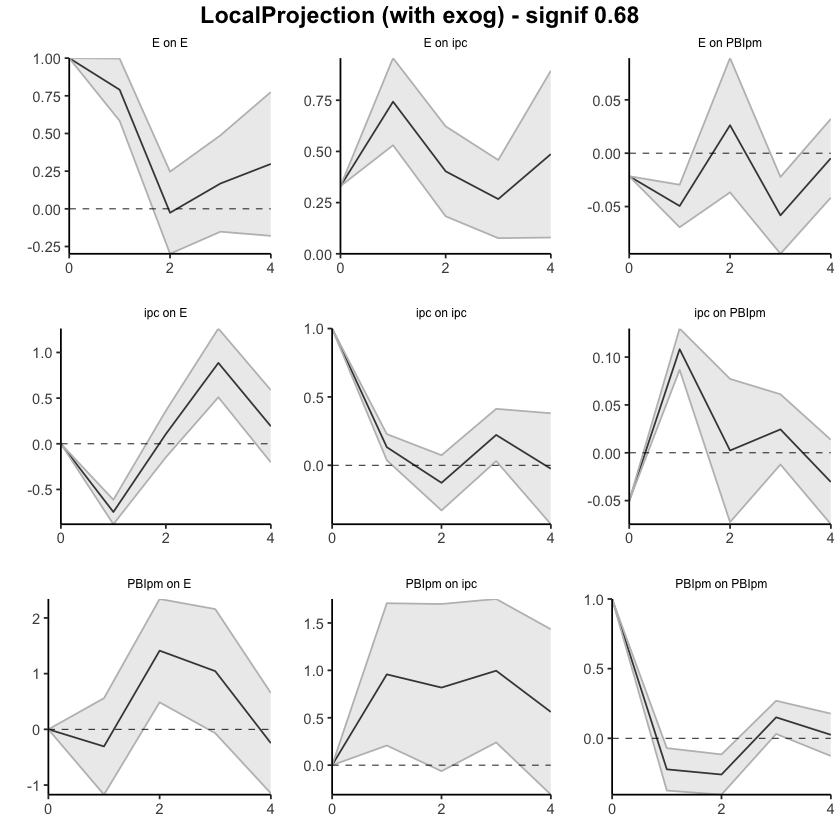

In [98]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,-0.7468156,-0.8807562,-0.6128750
13,ipc,E,2,-0.6397137,-1.0284168,-0.2510105
14,ipc,E,3,0.2458451,-0.5189784,1.0106687
15,ipc,E,4,0.4375784,-0.7227708,1.5979276


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,-0.3065642,-1.1724937,0.5593652
23,PBIpm,E,2,1.1060956,-0.6873088,2.8995000
24,PBIpm,E,3,2.1510033,-0.7564756,5.0584823
25,PBIpm,E,4,1.9026632,-1.9054061,5.7107324


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3303814,0.3303814,0.3303814
2,E,ipc,1,1.0733447,0.8606281,1.2860613
3,E,ipc,2,1.4761048,1.0437106,1.9084990
4,E,ipc,3,1.7433191,1.1201266,2.3665115
5,E,ipc,4,2.2302455,1.1995550,3.2609360


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.00000000,0.000000
27,PBIpm,ipc,1,0.9576703,0.20732502,1.708016
28,PBIpm,ipc,2,1.7760856,0.14430818,3.407863
29,PBIpm,ipc,3,2.7722295,0.38384502,5.160614
30,PBIpm,ipc,4,3.3333576,0.07282938,6.593886


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.02156732,-0.02156732,-0.02156732
7,E,PBIpm,1,-0.07103896,-0.09095954,-0.05111838
8,E,PBIpm,2,-0.04482773,-0.12763520,0.03797974
9,E,PBIpm,3,-0.10308912,-0.22189712,0.01571889
10,E,PBIpm,4,-0.10777672,-0.26349601,0.04794258


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.05023820,-0.05023820,-0.0502382
17,ipc,PBIpm,1,0.05798216,0.03639032,0.0795740
18,ipc,PBIpm,2,0.06034732,-0.03608584,0.1567805
19,ipc,PBIpm,3,0.08480942,-0.04829629,0.2179151
20,ipc,PBIpm,4,0.05425606,-0.12295538,0.2314675


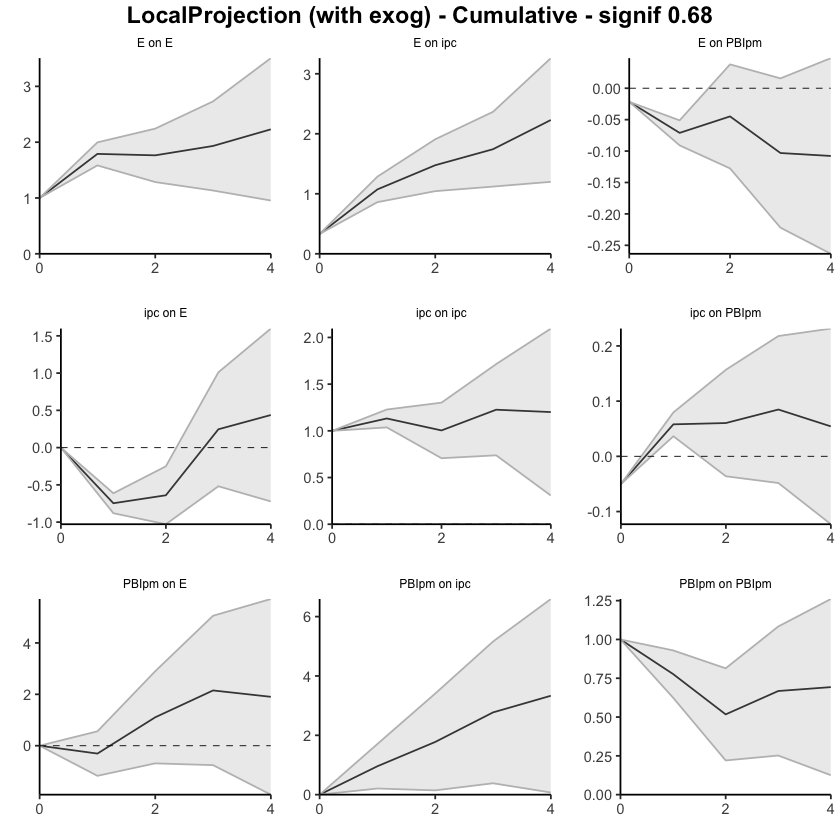

In [99]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.1993778,-0.3018752,-0.09688044
13,ipc,E,2,0.5226964,0.3446697,0.70072303
14,ipc,E,3,0.5084771,0.1940820,0.82287229
15,ipc,E,4,0.4857954,0.2274167,0.74417414


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.000000
22,PBIpm,E,1,0.9820501,0.01437508,1.949725
23,PBIpm,E,2,2.4927250,1.63930635,3.346144
24,PBIpm,E,3,1.4386212,0.45174829,2.425494
25,PBIpm,E,4,1.0170055,0.30788374,1.726127


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3759871,0.3759871,0.3759871
2,E,ipc,1,0.7692315,0.4082605,1.1302024
3,E,ipc,2,0.4574539,0.2429076,0.6720003
4,E,ipc,3,0.4842868,0.3324921,0.6360814
5,E,ipc,4,0.6440624,0.2898859,0.9982389


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.390001,0.6654684,2.114534
28,PBIpm,ipc,2,2.075719,1.3629187,2.788519
29,PBIpm,ipc,3,1.465168,0.8264932,2.103843
30,PBIpm,ipc,4,1.412668,0.5531877,2.272148


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.039373338,-0.03937334,-0.039373338
7,E,PBIpm,1,-0.048669966,-0.06704737,-0.030292562
8,E,PBIpm,2,0.015246139,-0.01225459,0.042746868
9,E,PBIpm,3,-0.036917150,-0.06643449,-0.007399815
10,E,PBIpm,4,-0.008136605,-0.04235731,0.026084101


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.05510897,-0.05510897,-0.05510897
17,ipc,PBIpm,1,0.04409249,0.03470776,0.05347722
18,ipc,PBIpm,2,-0.03430824,-0.05155566,-0.01706082
19,ipc,PBIpm,3,-0.01401652,-0.04394039,0.01590736
20,ipc,PBIpm,4,-0.03381475,-0.04891102,-0.01871847


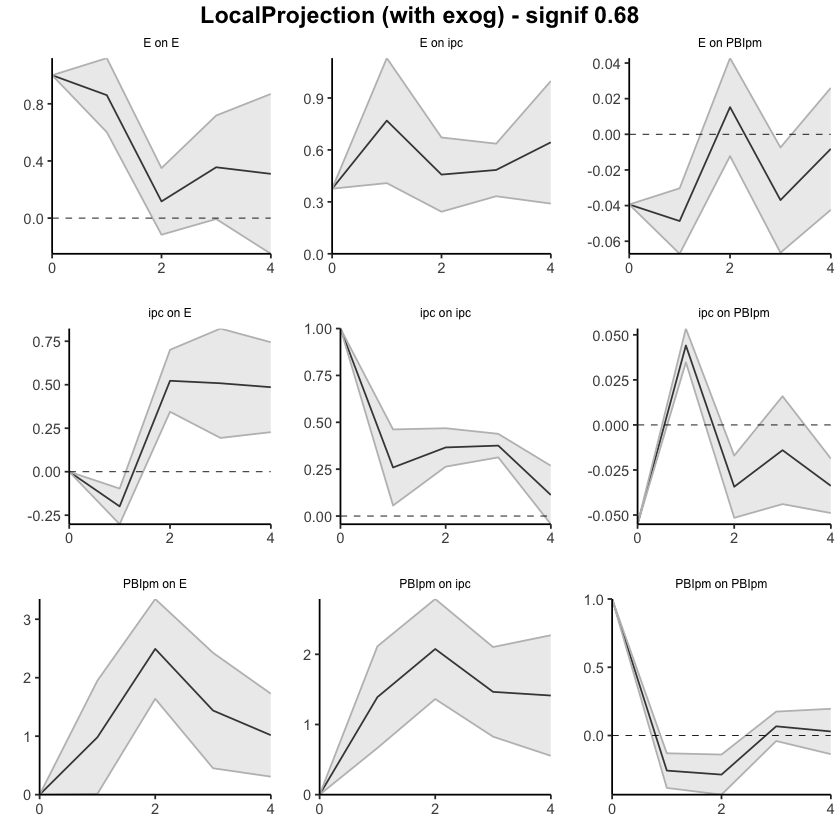

In [100]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.1993778,-0.30187522,-0.09688044
13,ipc,E,2,0.3233185,0.04279446,0.60384259
14,ipc,E,3,0.8317956,0.23687641,1.42671488
15,ipc,E,4,1.3175911,0.46429312,2.17088902


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.000000
22,PBIpm,E,1,0.9820501,0.01437508,1.949725
23,PBIpm,E,2,3.4747750,1.65368143,5.295869
24,PBIpm,E,3,4.9133963,2.10542972,7.721363
25,PBIpm,E,4,5.9304018,2.41331347,9.447490


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3759871,0.3759871,0.3759871
2,E,ipc,1,1.1452185,0.7842476,1.5061895
3,E,ipc,2,1.6026725,1.0271552,2.1781898
4,E,ipc,3,2.0869592,1.3596473,2.8142712
5,E,ipc,4,2.7310216,1.6495331,3.8125100


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.390001,0.6654684,2.114534
28,PBIpm,ipc,2,3.465720,2.0283871,4.903053
29,PBIpm,ipc,3,4.930888,2.8548803,7.006895
30,PBIpm,ipc,4,6.343556,3.4080681,9.279044


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03937334,-0.03937334,-0.039373338
7,E,PBIpm,1,-0.08804330,-0.10642071,-0.069665900
8,E,PBIpm,2,-0.07279716,-0.11867530,-0.026919031
9,E,PBIpm,3,-0.10971431,-0.18510978,-0.034318846
10,E,PBIpm,4,-0.11785092,-0.22746709,-0.008234745


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.05510897,-0.05510897,-0.055108972
17,ipc,PBIpm,1,-0.01101648,-0.02040121,-0.001631757
18,ipc,PBIpm,2,-0.04532472,-0.07195687,-0.018692575
19,ipc,PBIpm,3,-0.05934124,-0.11589726,-0.002785217
20,ipc,PBIpm,4,-0.09315599,-0.16480829,-0.021503686


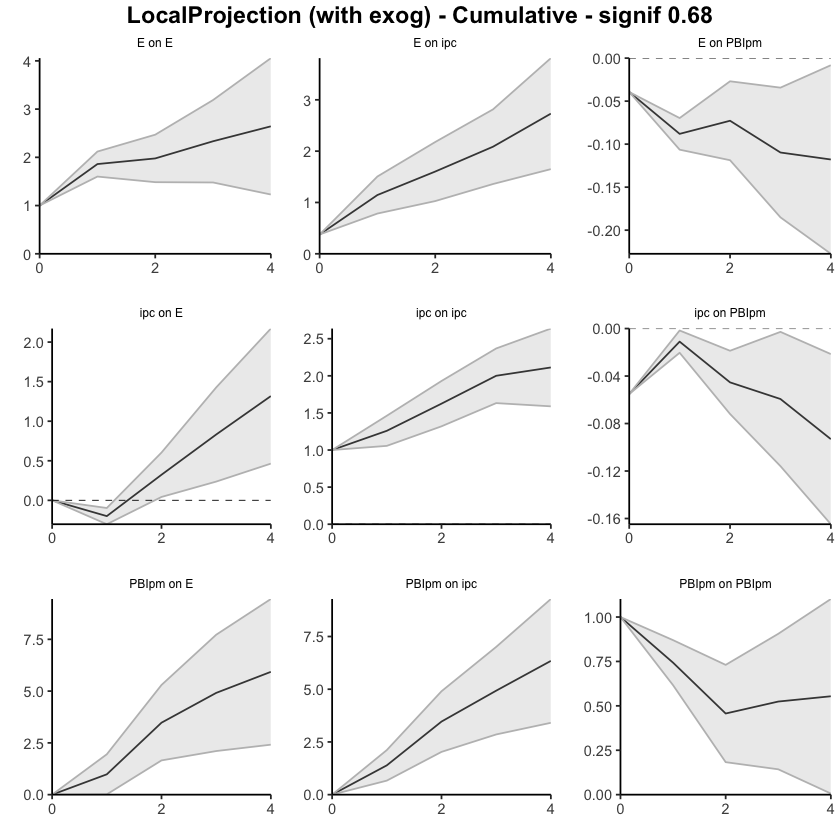

In [101]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.00000000,0.0000000
12,ipc,E,1,-0.740795526,-0.89865485,-0.5829362
13,ipc,E,2,0.008144921,-0.20131384,0.2176037
14,ipc,E,3,0.504519442,0.02045152,0.9885874
15,ipc,E,4,-0.116955692,-0.76555441,0.5316430


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.00000000,0.00000000,0.0000000
22,PBIpm,E,1,-0.02758064,-0.74233977,0.6871785
23,PBIpm,E,2,1.79633222,0.95329449,2.6393699
24,PBIpm,E,3,0.95500613,-0.08380689,1.9938191
25,PBIpm,E,4,-0.33265753,-1.07438187,0.4090668


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3159315,0.31593149,0.3159315
2,E,ipc,1,0.7239638,0.49508535,0.9528422
3,E,ipc,2,0.4021183,0.19105989,0.6131767
4,E,ipc,3,0.3848577,0.10797905,0.6617364
5,E,ipc,4,0.6730676,0.05697191,1.2891634


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.00000000,0.000000
27,PBIpm,ipc,1,1.0541336,0.38489268,1.723375
28,PBIpm,ipc,2,1.2022297,0.38269684,2.021763
29,PBIpm,ipc,3,1.1248356,0.35558726,1.894084
30,PBIpm,ipc,4,0.7015085,-0.02473311,1.427750


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.011161778,-0.01116178,-0.01116178
7,E,PBIpm,1,-0.050226349,-0.07307322,-0.02737948
8,E,PBIpm,2,0.012946979,-0.04650724,0.07240119
9,E,PBIpm,3,-0.074240241,-0.11743906,-0.03104142
10,E,PBIpm,4,-0.003937489,-0.05356500,0.04569002


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.04625329,-0.04625329,-0.04625329
17,ipc,PBIpm,1,0.11055630,0.09034046,0.13077214
18,ipc,PBIpm,2,0.01002250,-0.05207229,0.07211728
19,ipc,PBIpm,3,0.05614465,0.01291375,0.09937555
20,ipc,PBIpm,4,-0.02540048,-0.07368287,0.02288190


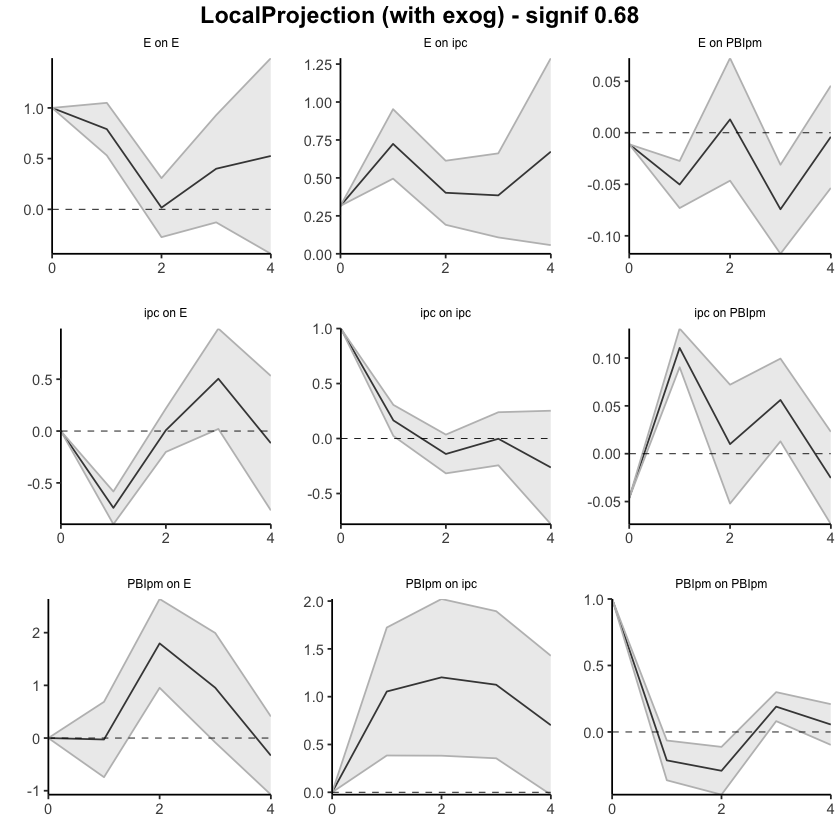

In [102]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,-0.7407955,-0.8986548,-0.5829362
13,ipc,E,2,-0.7326506,-1.0999687,-0.3653325
14,ipc,E,3,-0.2281312,-1.0795172,0.6232548
15,ipc,E,4,-0.3450869,-1.8450716,1.1548979


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.00000000,0.0000000,0.0000000
22,PBIpm,E,1,-0.02758064,-0.7423398,0.6871785
23,PBIpm,E,2,1.76875158,0.2109547,3.3265484
24,PBIpm,E,3,2.72375770,0.1271478,5.3203676
25,PBIpm,E,4,2.39110018,-0.9472340,5.7294344


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3159315,0.3159315,0.3159315
2,E,ipc,1,1.0398952,0.8110168,1.2687736
3,E,ipc,2,1.4420136,1.0020767,1.8819504
4,E,ipc,3,1.8268713,1.1100558,2.5436868
5,E,ipc,4,2.4999389,1.1670277,3.8328501


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.054134,0.3848927,1.723375
28,PBIpm,ipc,2,2.256363,0.7675895,3.745137
29,PBIpm,ipc,3,3.381199,1.1231768,5.639221
30,PBIpm,ipc,4,4.082707,1.0984437,7.066971


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01116178,-0.01116178,-0.011161778
7,E,PBIpm,1,-0.06138813,-0.08423499,-0.038541260
8,E,PBIpm,2,-0.04844115,-0.13074223,0.033859933
9,E,PBIpm,3,-0.12268139,-0.24818129,0.002818513
10,E,PBIpm,4,-0.12661888,-0.30174629,0.048508531


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.04625329,-0.046253288,-0.04625329
17,ipc,PBIpm,1,0.06430301,0.044087167,0.08451885
18,ipc,PBIpm,2,0.07432551,-0.007985119,0.15663613
19,ipc,PBIpm,3,0.13047015,0.004928628,0.25601168
20,ipc,PBIpm,4,0.10506967,-0.068754242,0.27889358


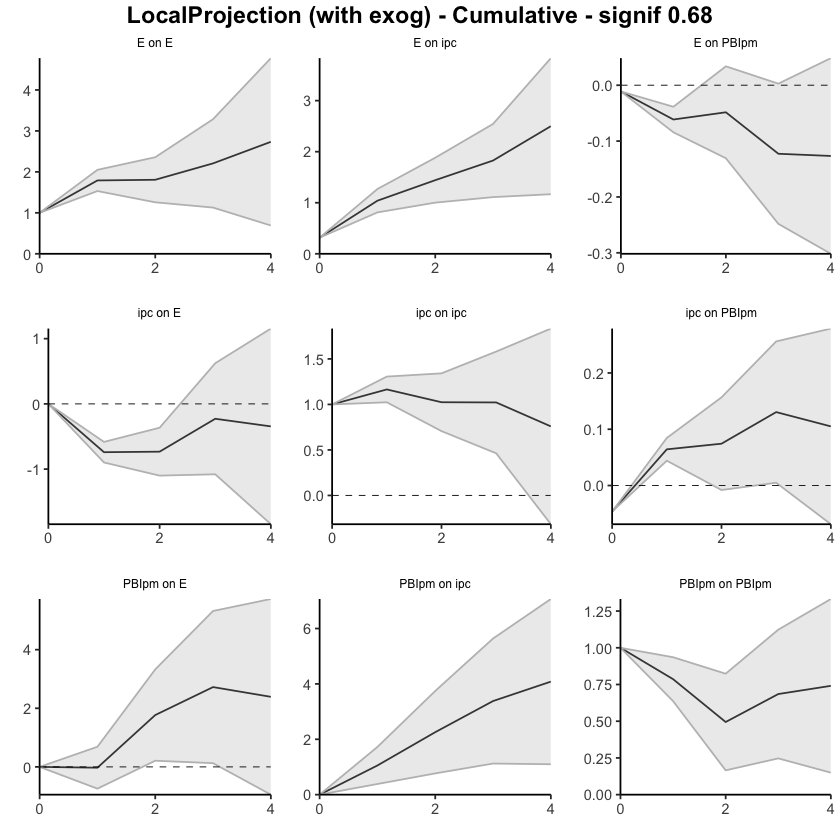

In [103]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

### 1935-1987. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.21444053,-0.2942966,-0.1345845
38,ipc,E,2,0.06745005,-0.1702560,0.3051561
39,ipc,E,3,0.22360427,-0.3854643,0.8326728
40,ipc,E,4,0.72055411,0.2302133,1.2108949


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.0000000
52,PBIpm,E,1,2.0789918,0.47023436,3.6877493
53,PBIpm,E,2,0.8048644,-0.03413354,1.6438624
54,PBIpm,E,3,-1.2836124,-2.95801831,0.3907935
55,PBIpm,E,4,-0.1569447,-1.50558573,1.1916963


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.68443325,-0.684433250,-0.68443325
2,Psoja_USA,E,1,-0.12326915,-0.276497953,0.02995965
3,Psoja_USA,E,2,0.29334031,0.055594918,0.53108571
4,Psoja_USA,E,3,0.01866141,-0.167261915,0.20458474
5,Psoja_USA,E,4,0.14917895,-0.006795565,0.30515347


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.06807504,0.068075037,0.068075037
12,Psoja_USA,PBIpm,1,-0.01636111,-0.038537745,0.005815525
13,Psoja_USA,PBIpm,2,-0.03176865,-0.045742822,-0.017794485
14,Psoja_USA,PBIpm,3,0.03109986,0.009750239,0.052449485
15,Psoja_USA,PBIpm,4,0.03999182,0.016258496,0.063725144


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.00000000,0.00000000
17,E,Psoja_USA,1,-0.01991634,-0.16806097,0.12822829
18,E,Psoja_USA,2,0.03781167,-0.08406823,0.15969156
19,E,Psoja_USA,3,-0.07827167,-0.18652843,0.02998509
20,E,Psoja_USA,4,-0.12415848,-0.19265065,-0.05566630


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Psoja_USA,1,-0.03070517,-0.11523278,0.05382244
33,ipc,Psoja_USA,2,-0.13161951,-0.18790940,-0.07532962
34,ipc,Psoja_USA,3,-0.08475351,-0.12605930,-0.04344772
35,ipc,Psoja_USA,4,0.02525071,0.00835416,0.04214725


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.0000000,0.00000000,0.0000000
47,PBIpm,Psoja_USA,1,-0.1845936,-0.59830092,0.2291137
48,PBIpm,Psoja_USA,2,-1.2005616,-1.63528839,-0.7658348
49,PBIpm,Psoja_USA,3,0.5737085,-0.05595883,1.2033759
50,PBIpm,Psoja_USA,4,0.8099529,0.15215126,1.4677545


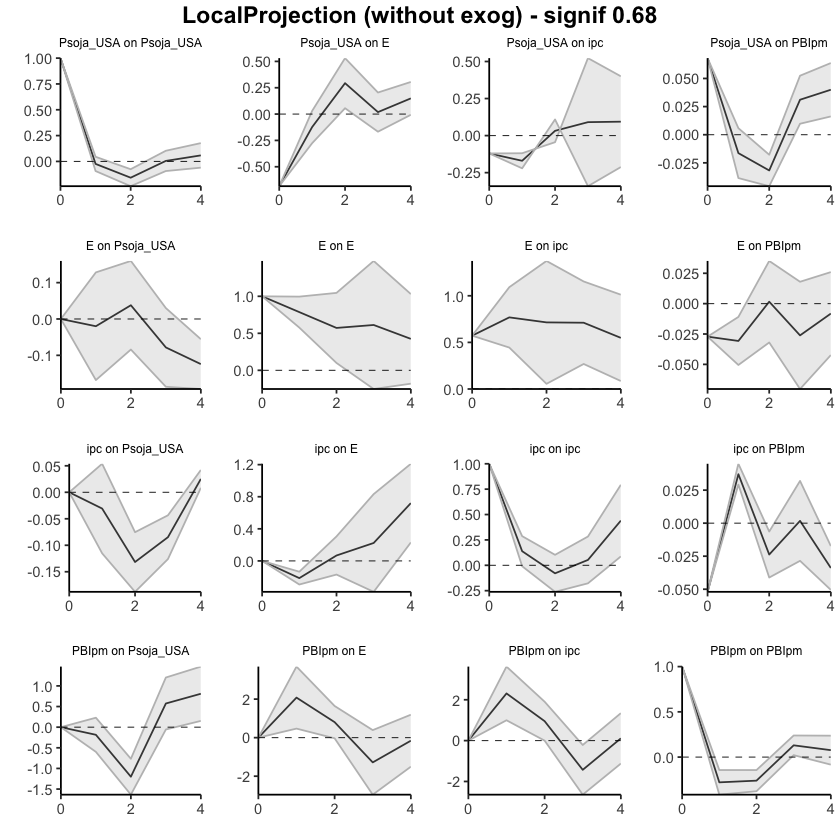

In [104]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.21444053,-0.2942966,-0.1345845
38,ipc,E,2,-0.14699049,-0.4645526,0.1705716
39,ipc,E,3,0.07661378,-0.8500169,1.0032444
40,ipc,E,4,0.79716789,-0.6198035,2.2141393


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,2.078992,0.4702344,3.687749
53,PBIpm,E,2,2.883856,0.4361008,5.331612
54,PBIpm,E,3,1.600244,-2.5219175,5.722405
55,PBIpm,E,4,1.443299,-4.0275032,6.914102


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.6844332,-0.6844332,-0.68443325
2,Psoja_USA,E,1,-0.8077024,-0.9609312,-0.65447360
3,Psoja_USA,E,2,-0.5143621,-0.9053363,-0.12338790
4,Psoja_USA,E,3,-0.4957007,-1.0725982,0.08119684
5,Psoja_USA,E,4,-0.3465217,-1.0793938,0.38635031


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.06807504,0.068075037,0.06807504
12,Psoja_USA,PBIpm,1,0.05171393,0.029537292,0.07389056
13,Psoja_USA,PBIpm,2,0.01994527,-0.016205530,0.05609608
14,Psoja_USA,PBIpm,3,0.05104514,-0.006455291,0.10854556
15,Psoja_USA,PBIpm,4,0.09103696,0.009803205,0.17227071


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.0000000,0.0000000
17,E,Psoja_USA,1,-0.01991634,-0.1680610,0.1282283
18,E,Psoja_USA,2,0.01789533,-0.2521292,0.2879199
19,E,Psoja_USA,3,-0.06037635,-0.4386576,0.3179049
20,E,Psoja_USA,4,-0.18453482,-0.6313083,0.2622386


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Psoja_USA,1,-0.03070517,-0.1152328,0.05382244
33,ipc,Psoja_USA,2,-0.16232468,-0.3031422,-0.02150718
34,ipc,Psoja_USA,3,-0.24707819,-0.4292015,-0.06495490
35,ipc,Psoja_USA,4,-0.22182748,-0.4208473,-0.02280764


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.000000000,0.0000000,0.0000000
47,PBIpm,Psoja_USA,1,-0.184593609,-0.5983009,0.2291137
48,PBIpm,Psoja_USA,2,-1.385155230,-2.2335893,-0.5367211
49,PBIpm,Psoja_USA,3,-0.811446699,-2.2895481,0.6666547
50,PBIpm,Psoja_USA,4,-0.001493819,-2.1373969,2.1344092


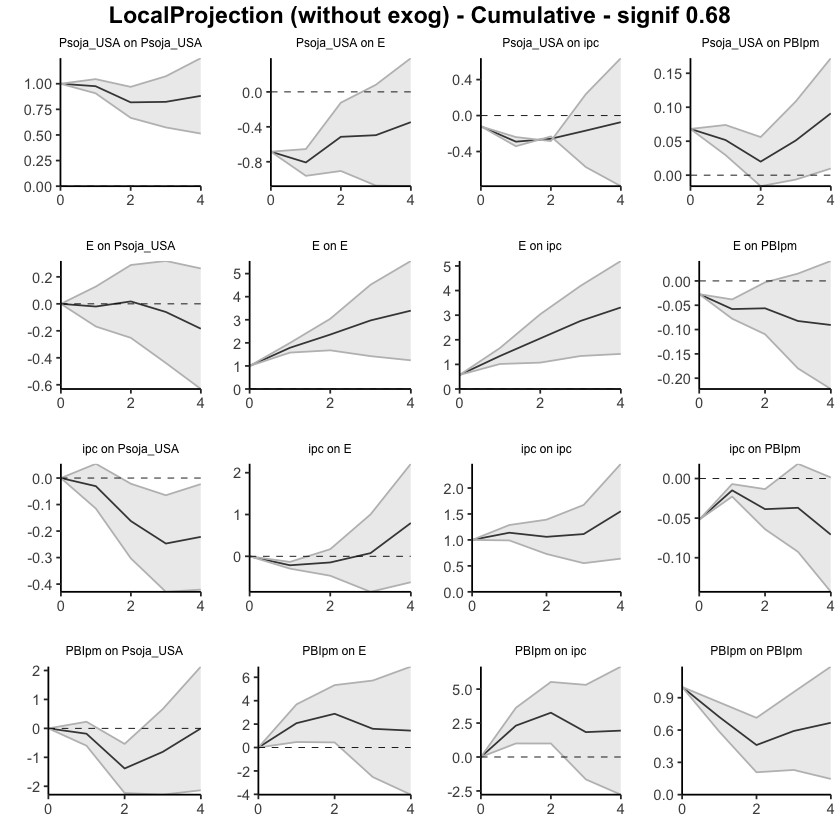

In [105]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.00000000
37,ipc,E,1,-0.1568725,-0.24243585,-0.07130906
38,ipc,E,2,0.1390479,-0.08351848,0.36161433
39,ipc,E,3,0.2692944,-0.26638353,0.80497238
40,ipc,E,4,0.7471225,0.36708341,1.12716163


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.00000000,0.0000000,0.0000000
52,PBIpm,E,1,2.20714188,0.4967355,3.9175483
53,PBIpm,E,2,1.07031685,0.1419073,1.9987264
54,PBIpm,E,3,-1.01953884,-2.6204802,0.5814025
55,PBIpm,E,4,-0.04221805,-1.3996420,1.3152059


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.1228058,-0.12280580,-0.1228058
2,Pmaíz_USA,E,1,0.3424434,0.05530451,0.6295823
3,Pmaíz_USA,E,2,0.5949061,0.18636487,1.0034474
4,Pmaíz_USA,E,3,0.2780934,0.01247289,0.5437140
5,Pmaíz_USA,E,4,0.3140739,0.09246850,0.5356794


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.019413617,0.01941362,0.019413617
12,Pmaíz_USA,PBIpm,1,0.003137012,-0.01506493,0.021338951
13,Pmaíz_USA,PBIpm,2,-0.030086253,-0.05333320,-0.006839307
14,Pmaíz_USA,PBIpm,3,-0.013751322,-0.04779110,0.020288458
15,Pmaíz_USA,PBIpm,4,0.050422839,0.01646905,0.084376629


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.000000000
17,E,Pmaíz_USA,1,-0.07530495,-0.2399396,0.089329672
18,E,Pmaíz_USA,2,-0.02157878,-0.1855383,0.142380707
19,E,Pmaíz_USA,3,-0.08692107,-0.1829669,0.009124731
20,E,Pmaíz_USA,4,-0.11434940,-0.1926917,-0.036007048


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.000000000,0.00000000,0.000000000
32,ipc,Pmaíz_USA,1,0.002076568,-0.10351866,0.107671794
33,ipc,Pmaíz_USA,2,-0.112945650,-0.22789635,0.002005054
34,ipc,Pmaíz_USA,3,-0.027998473,-0.11635602,0.060359075
35,ipc,Pmaíz_USA,4,0.002461411,-0.03080924,0.035732057


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Pmaíz_USA,1,-0.33245864,-0.8335893,0.1686721
48,PBIpm,Pmaíz_USA,2,-0.67243494,-1.1103372,-0.2345326
49,PBIpm,Pmaíz_USA,3,-0.07525601,-0.6741719,0.5236599
50,PBIpm,Pmaíz_USA,4,0.41567461,-0.3205220,1.1518712


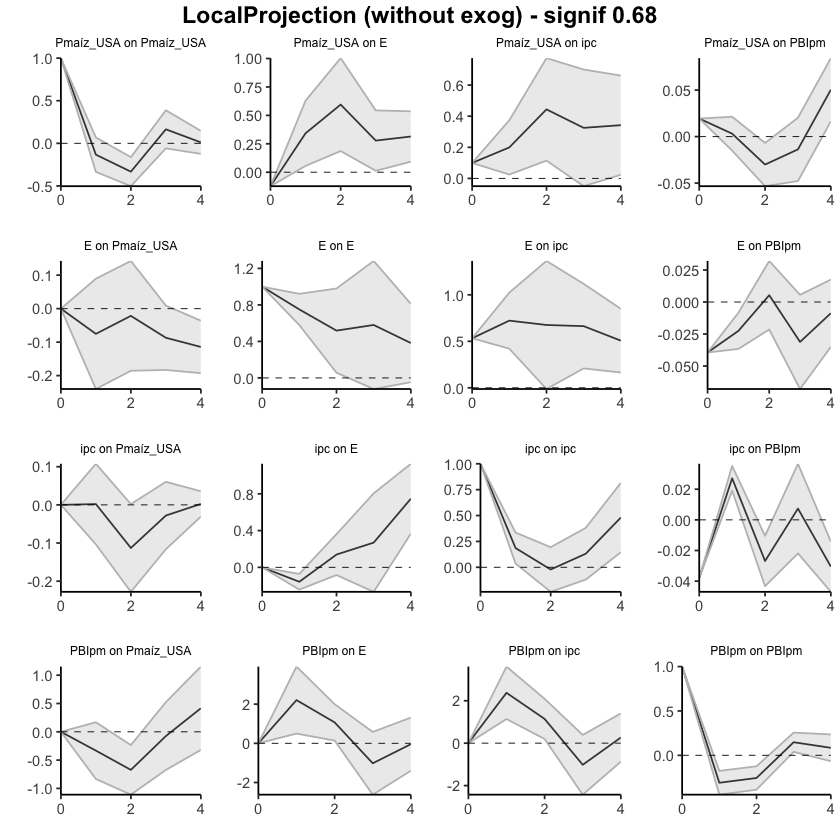

In [106]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,-0.15687246,-0.2424358,-0.07130906
38,ipc,E,2,-0.01782453,-0.3259543,0.29030527
39,ipc,E,3,0.25146990,-0.5923379,1.09527765
40,ipc,E,4,0.99859242,-0.2252544,2.22243928


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,2.207142,0.4967355,3.917548
53,PBIpm,E,2,3.277459,0.6386428,5.916275
54,PBIpm,E,3,2.257920,-1.9818374,6.497677
55,PBIpm,E,4,2.215702,-3.3814794,7.812883


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.1228058,-0.1228058,-0.1228058
2,Pmaíz_USA,E,1,0.2196376,-0.0675013,0.5067765
3,Pmaíz_USA,E,2,0.8145437,0.1188636,1.5102239
4,Pmaíz_USA,E,3,1.0926372,0.1313365,2.0539379
5,Pmaíz_USA,E,4,1.4067111,0.2238050,2.5896172


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.019413617,0.01941362,0.01941362
12,Pmaíz_USA,PBIpm,1,0.022550629,0.00434869,0.04075257
13,Pmaíz_USA,PBIpm,2,-0.007535624,-0.04898451,0.03391326
14,Pmaíz_USA,PBIpm,3,-0.021286946,-0.09677561,0.05420172
15,Pmaíz_USA,PBIpm,4,0.029135893,-0.08030656,0.13857835


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,-0.07530495,-0.2399396,0.08932967
18,E,Pmaíz_USA,2,-0.09688373,-0.4254778,0.23171038
19,E,Pmaíz_USA,3,-0.18380480,-0.6084447,0.24083511
20,E,Pmaíz_USA,4,-0.29815420,-0.8011365,0.20482806


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.000000000,0.0000000,0.0000000
32,ipc,Pmaíz_USA,1,0.002076568,-0.1035187,0.1076718
33,ipc,Pmaíz_USA,2,-0.110869082,-0.3314150,0.1096768
34,ipc,Pmaíz_USA,3,-0.138867555,-0.4477710,0.1700359
35,ipc,Pmaíz_USA,4,-0.136406145,-0.4785803,0.2057680


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.0000000,0.0000000,0.00000000
47,PBIpm,Pmaíz_USA,1,-0.3324586,-0.8335893,0.16867206
48,PBIpm,Pmaíz_USA,2,-1.0048936,-1.9439266,-0.06586058
49,PBIpm,Pmaíz_USA,3,-1.0801496,-2.6180985,0.45779933
50,PBIpm,Pmaíz_USA,4,-0.6644750,-2.9386205,1.60967057


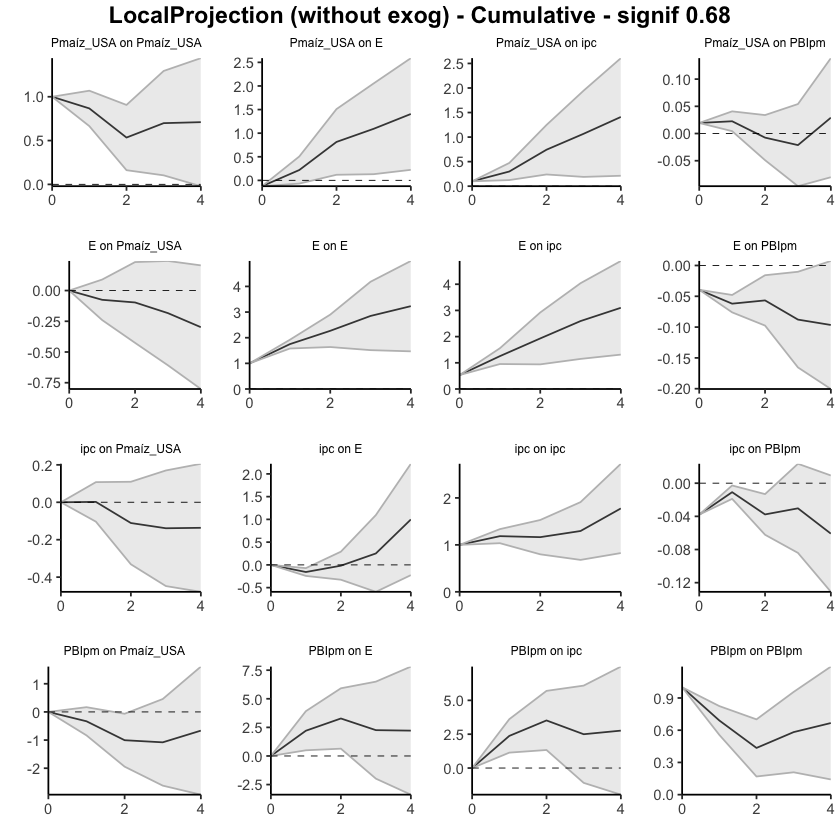

In [107]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,-0.15703044,-0.2694150,-0.04464584
38,ipc,E,2,0.04734434,-0.1345641,0.22925275
39,ipc,E,3,0.13392461,-0.2191777,0.48702689
40,ipc,E,4,0.68242447,0.3333613,1.03148766


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.0000000
52,PBIpm,E,1,2.4994944,0.7345507,4.2644380
53,PBIpm,E,2,1.5542510,0.6846674,2.4238346
54,PBIpm,E,3,-0.7542289,-2.0051580,0.4967002
55,PBIpm,E,4,0.1516522,-1.0209376,1.3242419


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.56239323,-0.5623932,-0.5623932
2,Ptrigo_USA,E,1,-0.01521082,-0.2084802,0.1780586
3,Ptrigo_USA,E,2,0.85341366,0.5760257,1.1308016
4,Ptrigo_USA,E,3,0.79639596,0.5924861,1.0003058
5,Ptrigo_USA,E,4,0.62383730,0.5076635,0.7400111


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.006044873,6.044873e-03,0.006044873
12,Ptrigo_USA,PBIpm,1,0.020477310,4.954146e-05,0.040905079
13,Ptrigo_USA,PBIpm,2,-0.055887579,-7.155309e-02,-0.040222065
14,Ptrigo_USA,PBIpm,3,-0.007809441,-1.826724e-02,0.002648361
15,Ptrigo_USA,PBIpm,4,0.028357658,1.556111e-02,0.041154207


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.000000000
17,E,Ptrigo_USA,1,-0.03494930,-0.1743424,0.104443752
18,E,Ptrigo_USA,2,-0.06908329,-0.3454096,0.207243018
19,E,Ptrigo_USA,3,-0.06040451,-0.1196578,-0.001151188
20,E,Ptrigo_USA,4,-0.06760420,-0.1557338,0.020525387


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.0000000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.0169146823,-0.0985641,0.06473474
33,ipc,Ptrigo_USA,2,0.0267890106,-0.1526109,0.20618893
34,ipc,Ptrigo_USA,3,-0.0002349319,-0.0522646,0.05179474
35,ipc,Ptrigo_USA,4,-0.0760797300,-0.1153866,-0.03677282


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.14108171,-0.4902449,0.2080814
48,PBIpm,Ptrigo_USA,2,0.06063241,-0.3215104,0.4427752
49,PBIpm,Ptrigo_USA,3,-0.04852482,-0.5515766,0.4545270
50,PBIpm,Ptrigo_USA,4,0.06703890,-0.5680712,0.7021490


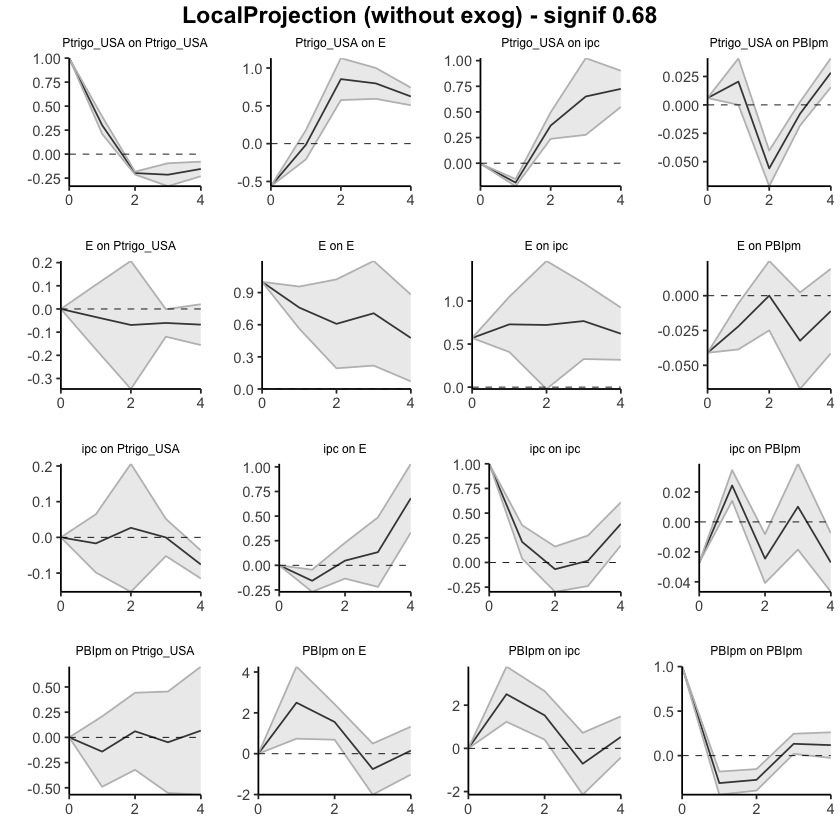

In [108]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,-0.15703044,-0.2694150,-0.04464584
38,ipc,E,2,-0.10968609,-0.4039791,0.18460691
39,ipc,E,3,0.02423852,-0.6231568,0.67163380
40,ipc,E,4,0.70666298,-0.2897955,1.70312146


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,2.499494,0.7345507,4.264438
53,PBIpm,E,2,4.053745,1.4192181,6.688273
54,PBIpm,E,3,3.299516,-0.5859398,7.184973
55,PBIpm,E,4,3.451169,-1.6068775,8.509215


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.5623932,-0.5623932,-0.5623932
2,Ptrigo_USA,E,1,-0.5776041,-0.7708735,-0.3843346
3,Ptrigo_USA,E,2,0.2758096,-0.1948478,0.7464670
4,Ptrigo_USA,E,3,1.0722056,0.3976383,1.7467728
5,Ptrigo_USA,E,4,1.6960429,0.9053018,2.4867839


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.006044873,0.006044873,0.006044873
12,Ptrigo_USA,PBIpm,1,0.026522183,0.006094414,0.046949952
13,Ptrigo_USA,PBIpm,2,-0.029365396,-0.065458678,0.006727887
14,Ptrigo_USA,PBIpm,3,-0.037174837,-0.083725921,0.009376248
15,Ptrigo_USA,PBIpm,4,-0.008817178,-0.068164812,0.050530455


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,-0.0349493,-0.1743424,0.1044438
18,E,Ptrigo_USA,2,-0.1040326,-0.5197519,0.3116868
19,E,Ptrigo_USA,3,-0.1644371,-0.6394098,0.3105356
20,E,Ptrigo_USA,4,-0.2320413,-0.7951436,0.3310610


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.000000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.016914682,-0.0985641,0.06473474
33,ipc,Ptrigo_USA,2,0.009874328,-0.2511750,0.27092367
34,ipc,Ptrigo_USA,3,0.009639396,-0.3034396,0.32271841
35,ipc,Ptrigo_USA,4,-0.066440334,-0.4188263,0.28594559


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.14108171,-0.4902449,0.2080814
48,PBIpm,Ptrigo_USA,2,-0.08044930,-0.8117553,0.6508567
49,PBIpm,Ptrigo_USA,3,-0.12897412,-1.3633319,1.1053836
50,PBIpm,Ptrigo_USA,4,-0.06193522,-1.9314031,1.8075326


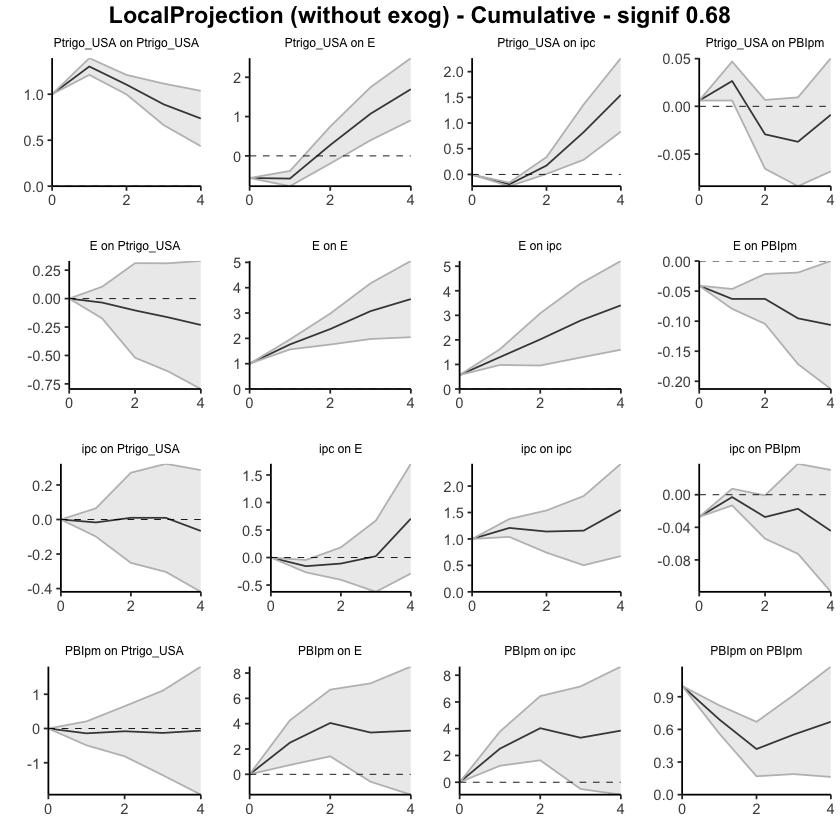

In [109]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,-0.55003123,-0.7539265,-0.34613597
38,ipc,E,2,-0.92006858,-1.2041695,-0.63596768
39,ipc,E,3,-0.42862171,-0.8219046,-0.03533876
40,ipc,E,4,0.04454011,-0.2062908,0.29537102


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.0000000
52,PBIpm,E,1,1.8885945,0.2513517,3.5258374
53,PBIpm,E,2,0.5779172,-0.3289568,1.4847913
54,PBIpm,E,3,-1.7616374,-2.8794037,-0.6438712
55,PBIpm,E,4,-0.5274854,-1.5210769,0.4661061


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.4701509,-0.4701509,-0.47015092
2,Ptrigo_USA,E,1,-0.1270097,-0.2137410,-0.04027838
3,Ptrigo_USA,E,2,0.6266728,0.4366732,0.81667244
4,Ptrigo_USA,E,3,0.7401729,0.4785995,1.00174623
5,Ptrigo_USA,E,4,0.5573701,0.3936564,0.72108383


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,-0.0005302076,-0.0005302076,-0.0005302076
12,Ptrigo_USA,PBIpm,1,0.0319991510,0.0040749604,0.0599233416
13,Ptrigo_USA,PBIpm,2,-0.0474988373,-0.0861642168,-0.0088334578
14,Ptrigo_USA,PBIpm,3,-0.0206248663,-0.0452119783,0.0039622457
15,Ptrigo_USA,PBIpm,4,0.0353811069,0.0170773609,0.0536848530


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.00000000,0.00000000
17,E,Ptrigo_USA,1,-0.01504127,-0.14669038,0.11660785
18,E,Ptrigo_USA,2,-0.07981378,-0.24240981,0.08278225
19,E,Ptrigo_USA,3,0.03893946,-0.07859473,0.15647366
20,E,Ptrigo_USA,4,0.03556492,-0.05067693,0.12180676


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.17698592,-0.26323032,-0.09074151
33,ipc,Ptrigo_USA,2,-0.01425129,-0.07055501,0.04205243
34,ipc,Ptrigo_USA,3,0.25433608,0.15600532,0.35266684
35,ipc,Ptrigo_USA,4,0.15372066,0.09532594,0.21211539


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.000000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,0.007929665,-0.3563442,0.3722035
48,PBIpm,Ptrigo_USA,2,-0.115414386,-0.5846416,0.3538129
49,PBIpm,Ptrigo_USA,3,0.176886879,-0.4411197,0.7948934
50,PBIpm,Ptrigo_USA,4,0.371807323,-0.3972925,1.1409071


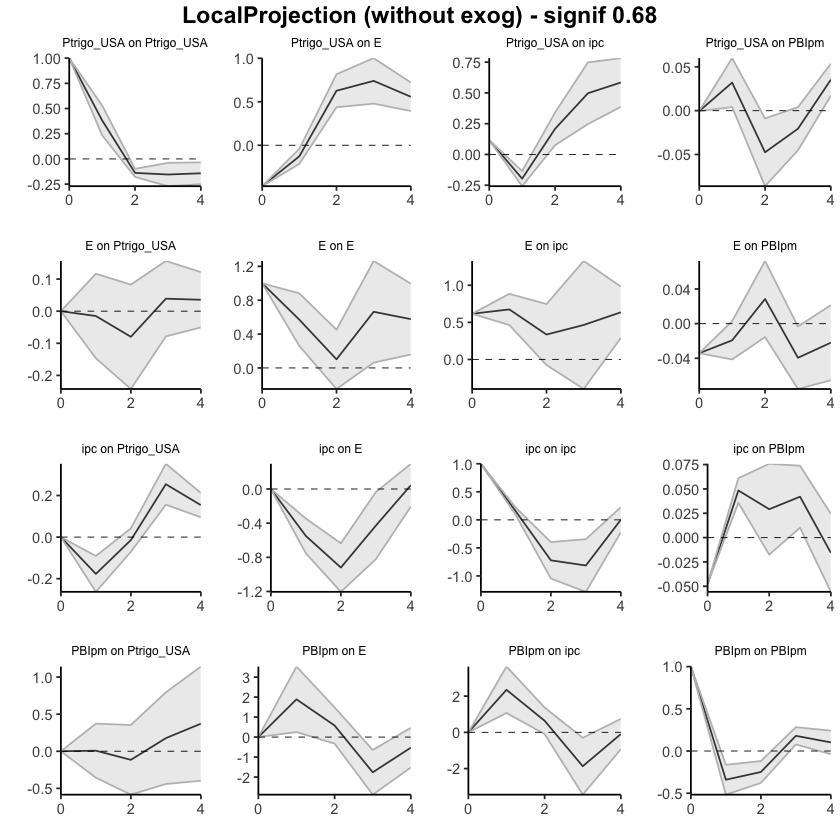

In [110]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.5500312,-0.7539265,-0.3461360
38,ipc,E,2,-1.4700998,-1.9580960,-0.9821036
39,ipc,E,3,-1.8987215,-2.7800006,-1.0174424
40,ipc,E,4,-1.8541814,-2.9862914,-0.7220714


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000
52,PBIpm,E,1,1.8885945,0.25135165,3.525837
53,PBIpm,E,2,2.4665118,-0.07760517,5.010629
54,PBIpm,E,3,0.7048743,-2.95700882,4.366757
55,PBIpm,E,4,0.1773890,-4.47808567,4.832864


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.4701509,-0.4701509,-0.4701509
2,Ptrigo_USA,E,1,-0.5971606,-0.6838919,-0.5104293
3,Ptrigo_USA,E,2,0.0295122,-0.2472187,0.3062431
4,Ptrigo_USA,E,3,0.7696851,0.2313808,1.3079894
5,Ptrigo_USA,E,4,1.3270552,0.6250371,2.0290732


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,-0.0005302076,-0.0005302076,-0.0005302076
12,Ptrigo_USA,PBIpm,1,0.0314689434,0.0035447528,0.0593931340
13,Ptrigo_USA,PBIpm,2,-0.0160298939,-0.0826194639,0.0505596762
14,Ptrigo_USA,PBIpm,3,-0.0366547602,-0.1278314423,0.0545219219
15,Ptrigo_USA,PBIpm,4,-0.0012736532,-0.1107540814,0.1082067749


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,-0.01504127,-0.1466904,0.1166079
18,E,Ptrigo_USA,2,-0.09485505,-0.3891002,0.1993901
19,E,Ptrigo_USA,3,-0.05591559,-0.4676949,0.3558638
20,E,Ptrigo_USA,4,-0.02035067,-0.5183719,0.4776705


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.17698592,-0.26323032,-0.09074151
33,ipc,Ptrigo_USA,2,-0.19123721,-0.33378533,-0.04868908
34,ipc,Ptrigo_USA,3,0.06309888,-0.17778000,0.30397776
35,ipc,Ptrigo_USA,4,0.21681954,-0.08245407,0.51609314


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.000000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,0.007929665,-0.3563442,0.3722035
48,PBIpm,Ptrigo_USA,2,-0.107484721,-0.9409859,0.7260164
49,PBIpm,Ptrigo_USA,3,0.069402158,-1.3821056,1.5209099
50,PBIpm,Ptrigo_USA,4,0.441209481,-1.7793980,2.6618170


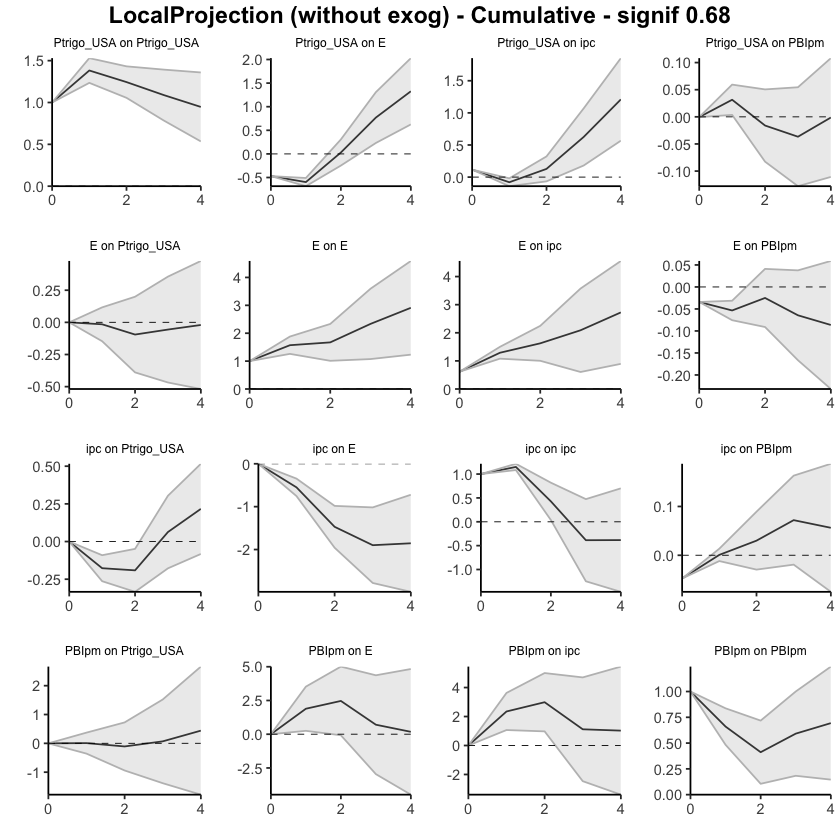

In [111]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

### 1935-1987. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.17152684,-0.2845902,-0.05846347
13,ipc,E,2,0.08406373,-0.1709606,0.33908802
14,ipc,E,3,0.19710847,-0.4465225,0.84073941
15,ipc,E,4,0.71731453,0.1991357,1.23549338


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.0000000
22,PBIpm,E,1,2.0789918,0.47023436,3.6877493
23,PBIpm,E,2,0.8048644,-0.03413354,1.6438624
24,PBIpm,E,3,-1.2836124,-2.95801831,0.3907935
25,PBIpm,E,4,-0.1569447,-1.50558573,1.1916963


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5235014,0.52350137,0.5235014
2,E,ipc,1,0.7353429,0.43357842,1.0371075
3,E,ipc,2,0.7075284,0.06818411,1.3468727
4,E,ipc,3,0.7246831,0.30727551,1.1420908
5,E,ipc,4,0.5258571,0.09396532,0.9577489


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.000000000,0.0000000
27,PBIpm,ipc,1,2.3096069,0.996209599,3.6230042
28,PBIpm,ipc,2,0.9519342,-0.001185163,1.9050536
29,PBIpm,ipc,3,-1.4298662,-2.645459875,-0.2142726
30,PBIpm,ipc,4,0.1105373,-1.123408026,1.3444827


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.036020397,-0.03602040,-0.03602040
7,E,PBIpm,1,-0.029337615,-0.04718941,-0.01148582
8,E,PBIpm,2,0.005703652,-0.02568197,0.03708927
9,E,PBIpm,3,-0.027696673,-0.06913873,0.01374538
10,E,PBIpm,4,-0.007395602,-0.03892769,0.02413648


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.031337960,-0.03133796,-0.03133796
17,ipc,PBIpm,1,0.031309392,0.02060915,0.04200964
18,ipc,PBIpm,2,-0.029126824,-0.04894399,-0.00930966
19,ipc,PBIpm,3,0.004423893,-0.02806799,0.03691577
20,ipc,PBIpm,4,-0.032362488,-0.05228129,-0.01244369


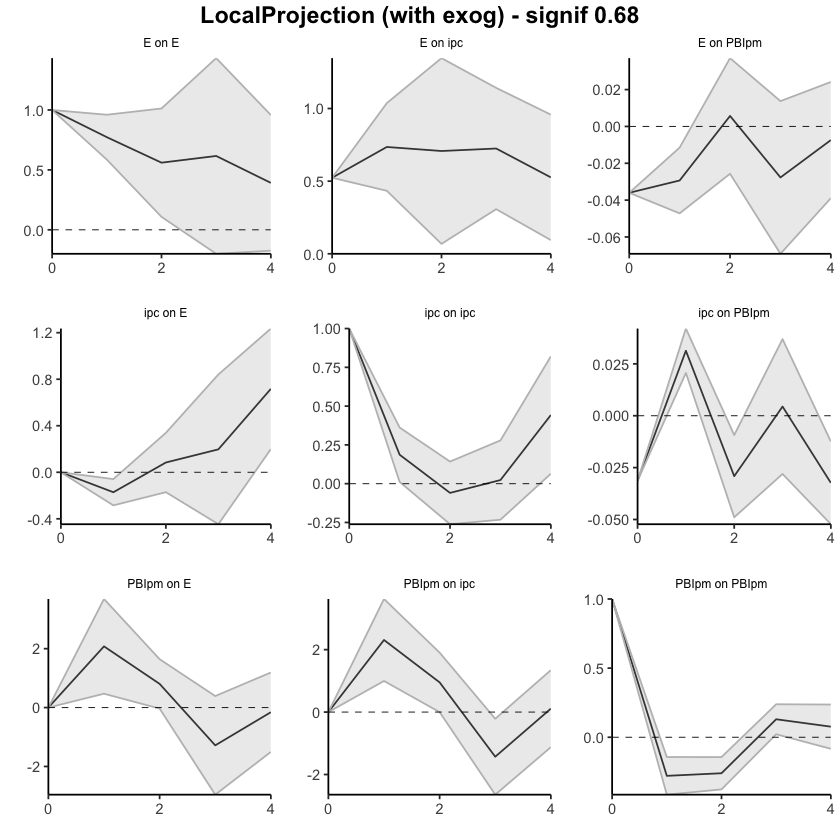

In [112]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.17152684,-0.2845902,-0.05846347
13,ipc,E,2,-0.08746311,-0.4555508,0.28062455
14,ipc,E,3,0.10964536,-0.9020733,1.12136396
15,ipc,E,4,0.82695988,-0.7029376,2.35685735


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,2.078992,0.4702344,3.687749
23,PBIpm,E,2,2.883856,0.4361008,5.331612
24,PBIpm,E,3,1.600244,-2.5219175,5.722405
25,PBIpm,E,4,1.443299,-4.0275032,6.914102


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5235014,0.5235014,0.5235014
2,E,ipc,1,1.2588443,0.9570798,1.5606088
3,E,ipc,2,1.9663727,1.0252639,2.9074815
4,E,ipc,3,2.6910558,1.3325394,4.0495723
5,E,ipc,4,3.2169129,1.4265047,5.0073211


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,2.309607,0.9962096,3.623004
28,PBIpm,ipc,2,3.261541,0.9950244,5.528058
29,PBIpm,ipc,3,1.831675,-1.6504354,5.313785
30,PBIpm,ipc,4,1.942212,-2.7738435,6.658268


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03602040,-0.03602040,-0.036020397
7,E,PBIpm,1,-0.06535801,-0.08320981,-0.047506217
8,E,PBIpm,2,-0.05965436,-0.10889178,-0.010416943
9,E,PBIpm,3,-0.08735103,-0.17803051,0.003328439
10,E,PBIpm,4,-0.09474664,-0.21695819,0.027464922


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-3.133796e-02,-0.03133796,-0.031337960
17,ipc,PBIpm,1,-2.856788e-05,-0.01072881,0.010671679
18,ipc,PBIpm,2,-2.915539e-02,-0.05967280,0.001362019
19,ipc,PBIpm,3,-2.473150e-02,-0.08774079,0.038277791
20,ipc,PBIpm,4,-5.709399e-02,-0.14002208,0.025834101


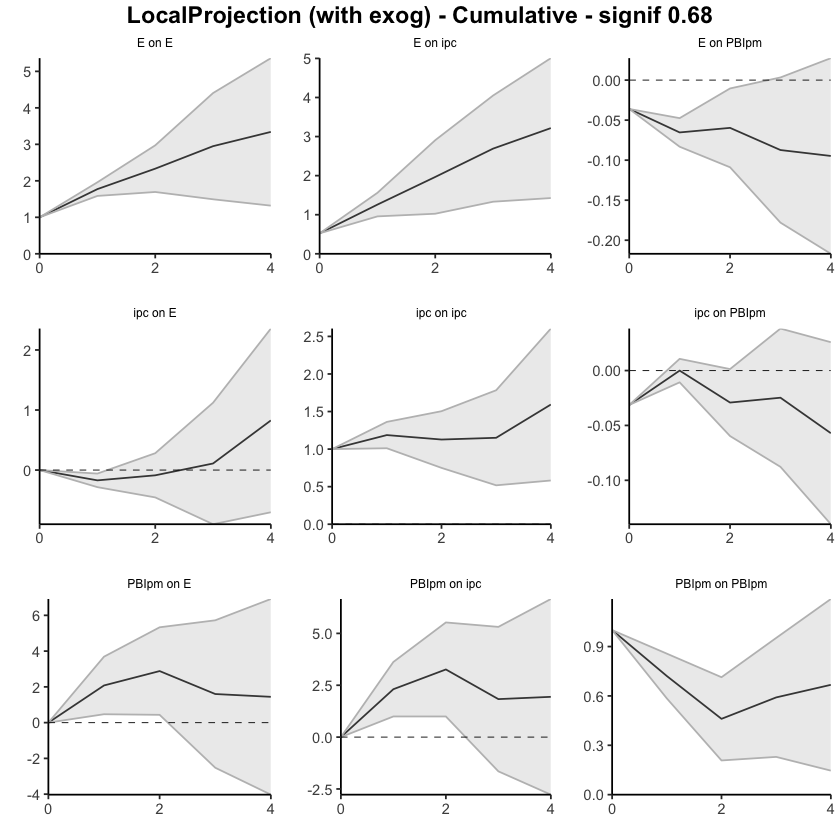

In [113]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.1413538,-0.23894326,-0.04376441
13,ipc,E,2,0.1465734,-0.08252072,0.37566757
14,ipc,E,3,0.2621260,-0.28480837,0.80906028
15,ipc,E,4,0.7468257,0.35724240,1.13640896


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.00000000,0.0000000,0.0000000
22,PBIpm,E,1,2.20714188,0.4967355,3.9175483
23,PBIpm,E,2,1.07031685,0.1419073,1.9987264
24,PBIpm,E,3,-1.01953884,-2.6204802,0.5814025
25,PBIpm,E,4,-0.04221805,-1.3996420,1.3152059


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5244808,0.52448083,0.5244808
2,E,ipc,1,0.7184430,0.41917965,1.0177064
3,E,ipc,2,0.6747178,-0.01115856,1.3605942
4,E,ipc,3,0.6631393,0.21194100,1.1143376
5,E,ipc,4,0.5026542,0.16419651,0.8411119


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIpm,ipc,1,2.3742678,1.1386619,3.6098738
28,PBIpm,ipc,2,1.1422893,0.1946326,2.0899461
29,PBIpm,ipc,3,-1.0191379,-2.4275909,0.3893151
30,PBIpm,ipc,4,0.2662555,-0.8713440,1.4038549


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.040174502,-0.04017450,-0.040174502
7,E,PBIpm,1,-0.022447181,-0.03634583,-0.008548528
8,E,PBIpm,2,0.005791963,-0.02069090,0.032274823
9,E,PBIpm,3,-0.031374587,-0.06778517,0.005035991
10,E,PBIpm,4,-0.008564235,-0.03456209,0.017433619


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.030877119,-0.03087712,-0.03087712
17,ipc,PBIpm,1,0.024910437,0.01589031,0.03393056
18,ipc,PBIpm,2,-0.028644260,-0.04601493,-0.01127359
19,ipc,PBIpm,3,0.008385149,-0.02161426,0.03838456
20,ipc,PBIpm,4,-0.029952266,-0.04743643,-0.01246810


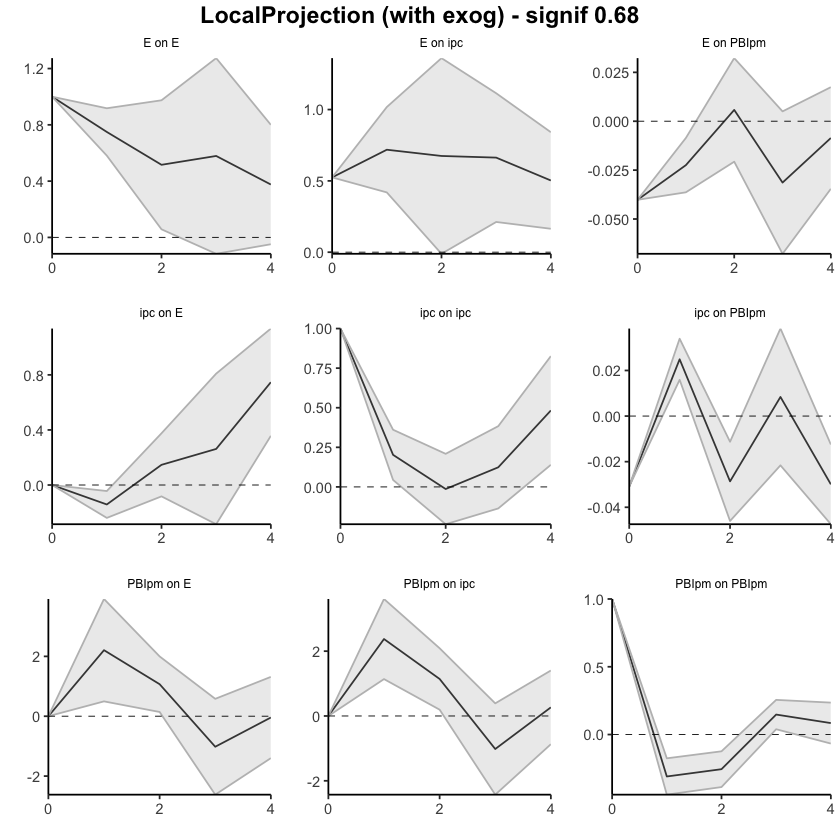

In [114]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.0000000,0.00000000
12,ipc,E,1,-0.141353834,-0.2389433,-0.04376441
13,ipc,E,2,0.005219591,-0.3214640,0.33190315
14,ipc,E,3,0.267345544,-0.6062723,1.14096343
15,ipc,E,4,1.014171224,-0.2490299,2.27737240


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,2.207142,0.4967355,3.917548
23,PBIpm,E,2,3.277459,0.6386428,5.916275
24,PBIpm,E,3,2.257920,-1.9818374,6.497677
25,PBIpm,E,4,2.215702,-3.3814794,7.812883


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5244808,0.5244808,0.5244808
2,E,ipc,1,1.2429239,0.9436605,1.5421872
3,E,ipc,2,1.9176417,0.9325019,2.9027814
4,E,ipc,3,2.5807810,1.1444429,4.0171190
5,E,ipc,4,3.0834352,1.3086394,4.8582310


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.000000,0.000000
27,PBIpm,ipc,1,2.374268,1.138662,3.609874
28,PBIpm,ipc,2,3.516557,1.333294,5.699820
29,PBIpm,ipc,3,2.497419,-1.094296,6.089135
30,PBIpm,ipc,4,2.763675,-1.965640,7.492990


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.04017450,-0.04017450,-0.040174502
7,E,PBIpm,1,-0.06262168,-0.07652033,-0.048723030
8,E,PBIpm,2,-0.05682972,-0.09721123,-0.016448207
9,E,PBIpm,3,-0.08820431,-0.16499640,-0.011412216
10,E,PBIpm,4,-0.09676854,-0.19955849,0.006021403


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.030877119,-0.03087712,-0.030877119
17,ipc,PBIpm,1,-0.005966682,-0.01498680,0.003053441
18,ipc,PBIpm,2,-0.034610942,-0.06100173,-0.008220152
19,ipc,PBIpm,3,-0.026225793,-0.08261599,0.030164407
20,ipc,PBIpm,4,-0.056178059,-0.13005242,0.017696305


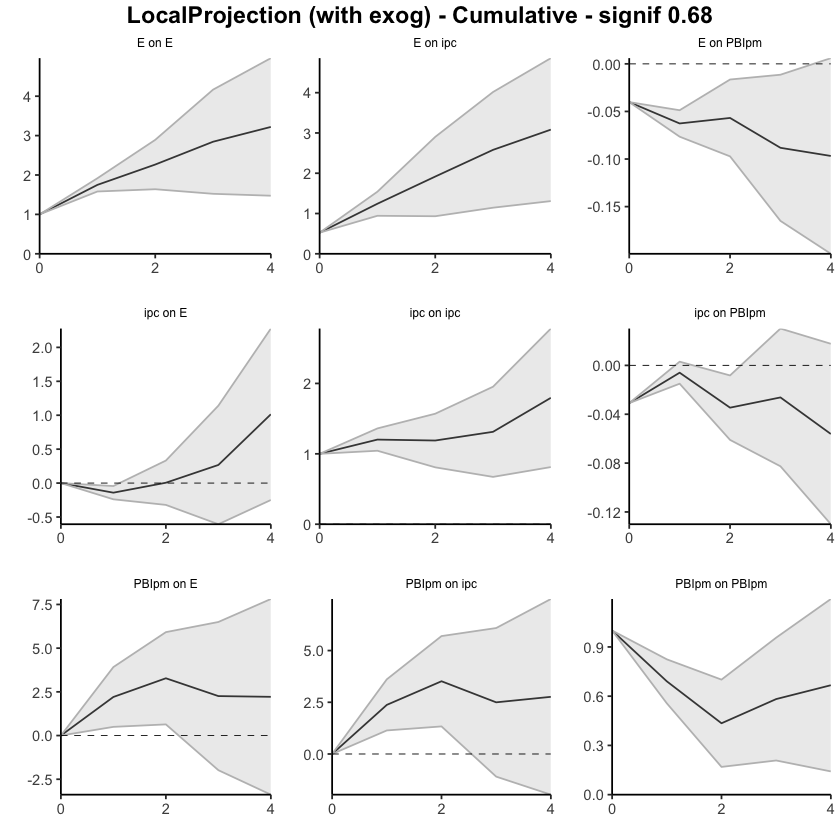

In [115]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.16397205,-0.2714550,-0.05648907
13,ipc,E,2,0.04302786,-0.1364655,0.22252126
14,ipc,E,3,0.13601926,-0.2136089,0.48564746
15,ipc,E,4,0.68200330,0.3361966,1.02780996


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,2.4994944,0.7345507,4.2644380
23,PBIpm,E,2,1.5542510,0.6846674,2.4238346
24,PBIpm,E,3,-0.7542289,-2.0051580,0.4967002
25,PBIpm,E,4,0.1516522,-1.0209376,1.3242419


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5312256,0.531225642,0.5312256
2,E,ipc,1,0.7229258,0.407585627,1.0382660
3,E,ipc,2,0.7256259,-0.009716791,1.4609685
4,E,ipc,3,0.7653768,0.332943072,1.1978104
5,E,ipc,4,0.6053310,0.309916495,0.9007454


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIpm,ipc,1,2.5093259,1.2314538,3.7871981
28,PBIpm,ipc,2,1.5303285,0.4080518,2.6526052
29,PBIpm,ipc,3,-0.7115212,-2.1434371,0.7203947
30,PBIpm,ipc,4,0.5297453,-0.4241152,1.4836057


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.038906588,-0.03890659,-0.03890659
7,E,PBIpm,1,-0.023290154,-0.03958596,-0.00699435
8,E,PBIpm,2,0.000700555,-0.02370782,0.02510893
9,E,PBIpm,3,-0.032600508,-0.06626139,0.00106037
10,E,PBIpm,4,-0.009845587,-0.03959949,0.01990832


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.029982986,-0.02998299,-0.029982986
17,ipc,PBIpm,1,0.025156447,0.01525639,0.035056506
18,ipc,PBIpm,2,-0.023741533,-0.03970936,-0.007773708
19,ipc,PBIpm,3,0.009773858,-0.01857546,0.038123175
20,ipc,PBIpm,4,-0.027479267,-0.04660807,-0.008350460


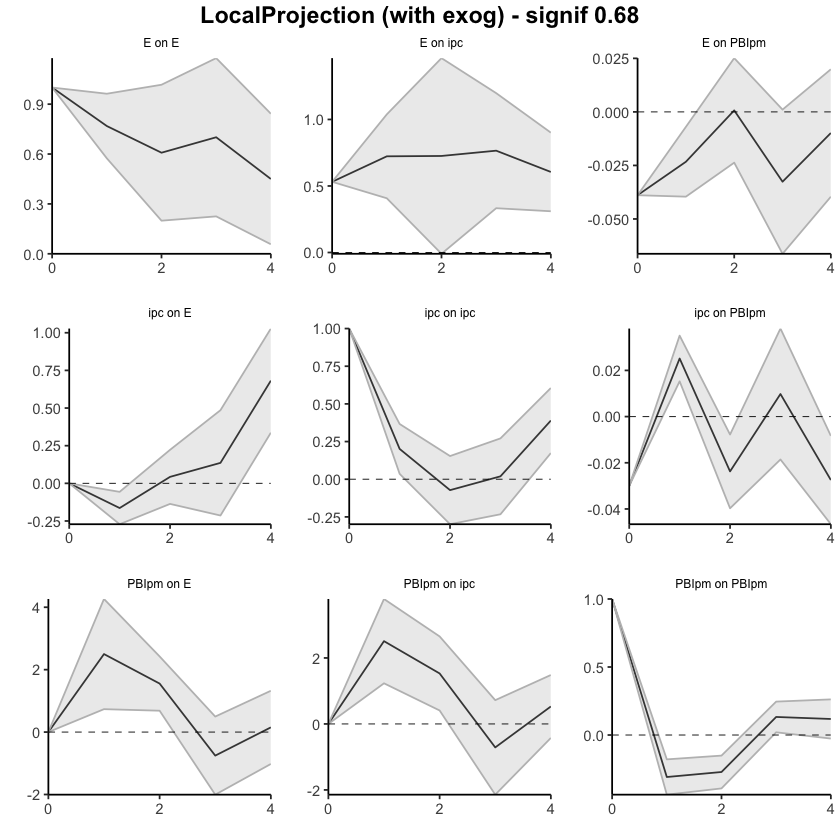

In [116]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.16397205,-0.2714550,-0.05648907
13,ipc,E,2,-0.12094418,-0.4079206,0.16603219
14,ipc,E,3,0.01507507,-0.6215295,0.65167964
15,ipc,E,4,0.69707837,-0.2853329,1.67948961


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,2.499494,0.7345507,4.264438
23,PBIpm,E,2,4.053745,1.4192181,6.688273
24,PBIpm,E,3,3.299516,-0.5859398,7.184973
25,PBIpm,E,4,3.451169,-1.6068775,8.509215


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5312256,0.5312256,0.5312256
2,E,ipc,1,1.2541514,0.9388113,1.5694916
3,E,ipc,2,1.9797773,0.9290945,3.0304602
4,E,ipc,3,2.7451541,1.2620375,4.2282706
5,E,ipc,4,3.3504850,1.5719540,5.1290160


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,2.509326,1.2314538,3.787198
28,PBIpm,ipc,2,4.039654,1.6395056,6.439803
29,PBIpm,ipc,3,3.328133,-0.5039315,7.160198
30,PBIpm,ipc,4,3.857878,-0.9280467,8.643804


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03890659,-0.03890659,-0.0389065879
7,E,PBIpm,1,-0.06219674,-0.07849255,-0.0459009377
8,E,PBIpm,2,-0.06149619,-0.10220037,-0.0207920053
9,E,PBIpm,3,-0.09409669,-0.16846175,-0.0197316348
10,E,PBIpm,4,-0.10394228,-0.20806125,0.0001766847


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.029982986,-0.02998299,-0.029982986
17,ipc,PBIpm,1,-0.004826539,-0.01472660,0.005073521
18,ipc,PBIpm,2,-0.028568072,-0.05443596,-0.002700187
19,ipc,PBIpm,3,-0.018794213,-0.07301141,0.035422988
20,ipc,PBIpm,4,-0.046273481,-0.11961949,0.027072528


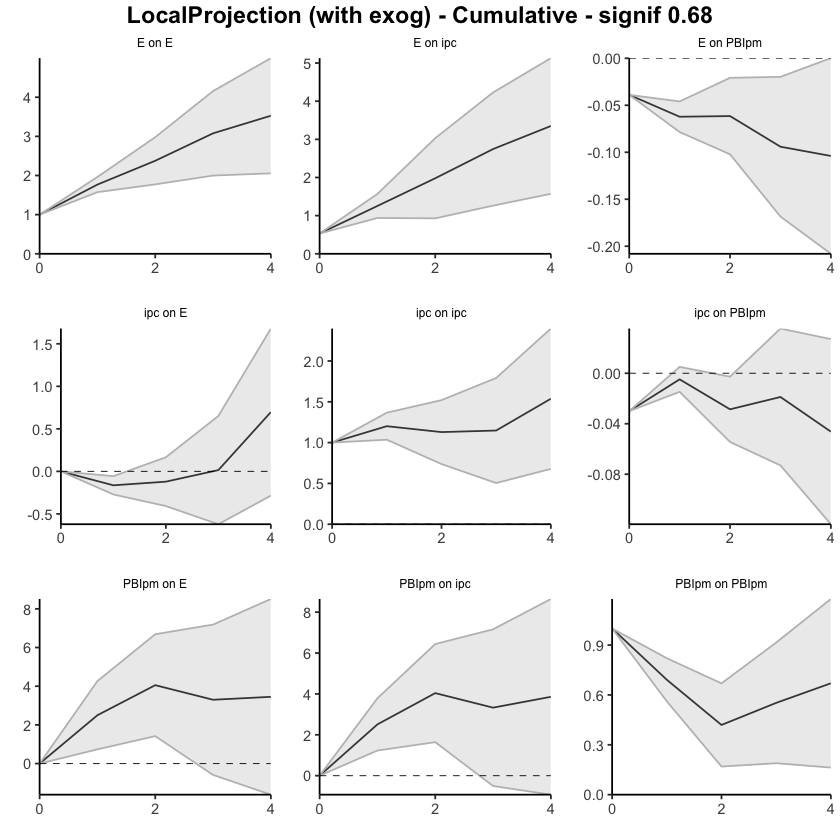

In [117]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

### 1935-1990. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.00000000
37,ipc,E,1,-0.12268548,-0.22759302,-0.01777793
38,ipc,E,2,0.04827759,-0.23786985,0.33442503
39,ipc,E,3,0.41145240,-0.07280391,0.89570872
40,ipc,E,4,1.12356972,0.78701706,1.46012237


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,1.0813449,-1.1791567,3.341847
53,PBIpm,E,2,1.7047526,0.5850569,2.824448
54,PBIpm,E,3,1.2964761,-1.4441510,4.037103
55,PBIpm,E,4,-0.1531396,-1.7514752,1.445196


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.6292607,-0.62926074,-0.6292607447
2,Psoja_USA,E,1,0.4205706,-0.09284007,0.9339812201
3,Psoja_USA,E,2,0.3956562,0.14789468,0.6434176164
4,Psoja_USA,E,3,-0.1539608,-0.56984779,0.2619262279
5,Psoja_USA,E,4,-0.2457498,-0.49063114,-0.0008684131


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.06086193,0.060861927,0.06086193
12,Psoja_USA,PBIpm,1,-0.03130057,-0.057060174,-0.00554096
13,Psoja_USA,PBIpm,2,-0.03320271,-0.047236966,-0.01916845
14,Psoja_USA,PBIpm,3,0.03584513,0.008967426,0.06272282
15,Psoja_USA,PBIpm,4,0.04766563,0.023992133,0.07133913


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.000000000,0.0000000,0.00000000
17,E,Psoja_USA,1,-0.024995721,-0.1769322,0.12694081
18,E,Psoja_USA,2,-0.002546663,-0.1334120,0.12831863
19,E,Psoja_USA,3,-0.047991608,-0.1922679,0.09628465
20,E,Psoja_USA,4,-0.071608349,-0.1691524,0.02593567


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Psoja_USA,1,-0.04797483,-0.13640797,0.04045830
33,ipc,Psoja_USA,2,-0.10747887,-0.17097847,-0.04397927
34,ipc,Psoja_USA,3,-0.01953931,-0.08085342,0.04177480
35,ipc,Psoja_USA,4,0.06226017,0.01558144,0.10893891


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Psoja_USA,1,-0.1001605,-0.5038368,0.3035157
48,PBIpm,Psoja_USA,2,-0.9205199,-1.4103861,-0.4306538
49,PBIpm,Psoja_USA,3,0.2544111,-0.3810961,0.8899183
50,PBIpm,Psoja_USA,4,0.8587218,0.1967167,1.5207269


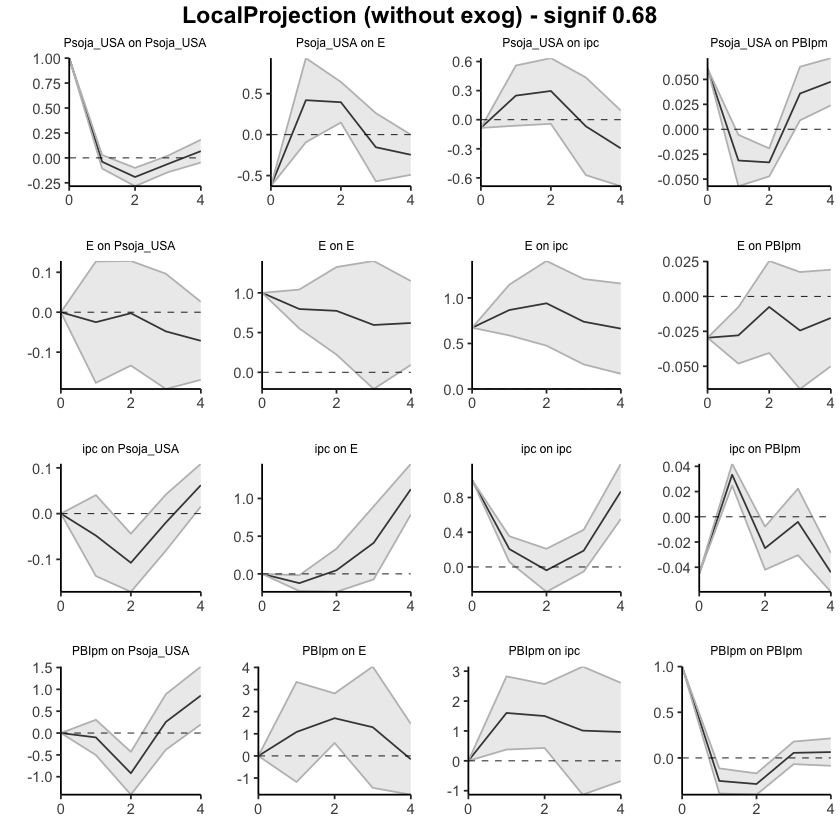

In [118]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,-0.12268548,-0.2275930,-0.01777793
38,ipc,E,2,-0.07440789,-0.4654629,0.31664710
39,ipc,E,3,0.33704452,-0.5382668,1.21235582
40,ipc,E,4,1.46061423,0.2487503,2.67247819


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.081345,-1.1791567,3.341847
53,PBIpm,E,2,2.786098,-0.5940998,6.166295
54,PBIpm,E,3,4.082574,-2.0382508,10.203398
55,PBIpm,E,4,3.929434,-3.7897260,11.648594


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.6292607,-0.6292607,-0.6292607
2,Psoja_USA,E,1,-0.2086902,-0.7221008,0.3047205
3,Psoja_USA,E,2,0.1869660,-0.5742061,0.9481381
4,Psoja_USA,E,3,0.0330052,-1.1440539,1.2100643
5,Psoja_USA,E,4,-0.2127446,-1.6346851,1.2091959


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.060861927,0.060861927,0.06086193
12,Psoja_USA,PBIpm,1,0.029561360,0.003801753,0.05532097
13,Psoja_USA,PBIpm,2,-0.003641346,-0.043435213,0.03615252
14,Psoja_USA,PBIpm,3,0.032203779,-0.034467787,0.09887534
15,Psoja_USA,PBIpm,4,0.079869409,-0.010475654,0.17021447


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.0000000,0.0000000
17,E,Psoja_USA,1,-0.02499572,-0.1769322,0.1269408
18,E,Psoja_USA,2,-0.02754238,-0.3103442,0.2552594
19,E,Psoja_USA,3,-0.07553399,-0.5026121,0.3515441
20,E,Psoja_USA,4,-0.14714234,-0.6717644,0.3774798


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.0000000,0.000000000
32,ipc,Psoja_USA,1,-0.04797483,-0.1364080,0.040458304
33,ipc,Psoja_USA,2,-0.15545371,-0.3073864,-0.003520965
34,ipc,Psoja_USA,3,-0.17499302,-0.3882399,0.038253831
35,ipc,Psoja_USA,4,-0.11273285,-0.3726584,0.147192737


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Psoja_USA,1,-0.10016054,-0.5038368,0.3035157
48,PBIpm,Psoja_USA,2,-1.02068045,-1.9142228,-0.1271381
49,PBIpm,Psoja_USA,3,-0.76626931,-2.2953189,0.7627802
50,PBIpm,Psoja_USA,4,0.09245248,-2.0986022,2.2835072


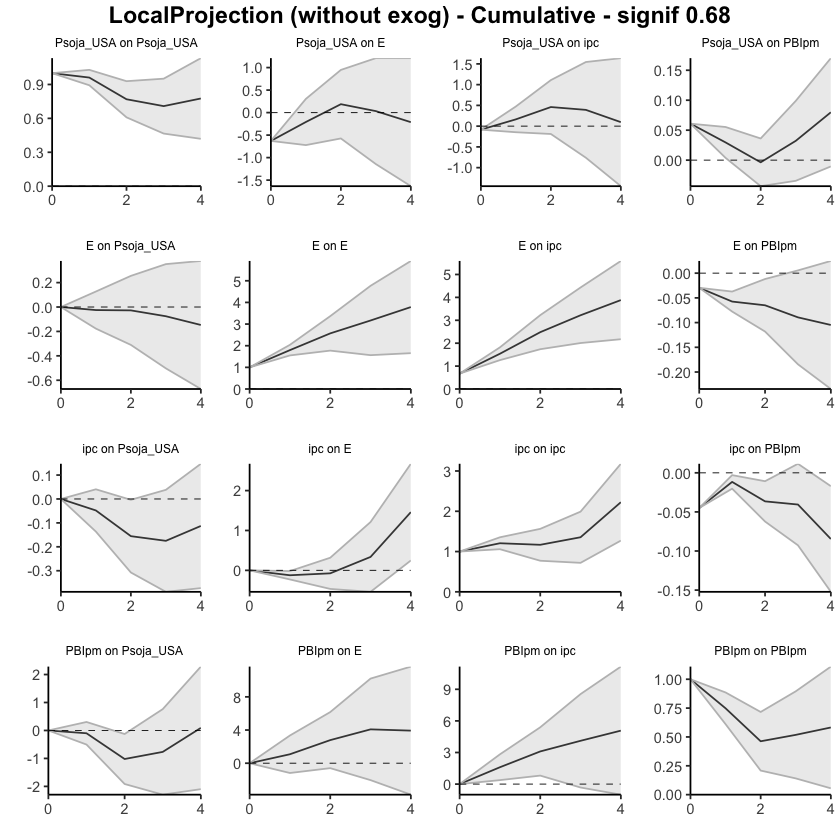

In [119]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,0.00905259,-0.13633374,0.1544389
38,ipc,E,2,0.19700534,-0.05107646,0.4450871
39,ipc,E,3,0.45009574,-0.04641070,0.9466022
40,ipc,E,4,1.08099244,0.75783209,1.4041528


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,1.6564042,-0.2721602,3.584969
53,PBIpm,E,2,2.2772374,1.0631754,3.491299
54,PBIpm,E,3,1.3897934,-1.1810509,3.960638
55,PBIpm,E,4,-0.3476482,-1.9602384,1.264942


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,0.04947696,0.04947696,0.04947696
2,Pmaíz_USA,E,1,0.74024375,0.30008977,1.18039773
3,Pmaíz_USA,E,2,0.50848396,0.05050130,0.96646662
4,Pmaíz_USA,E,3,-0.03291321,-0.77254480,0.70671839
5,Pmaíz_USA,E,4,0.20683455,-0.20593639,0.61960548


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.011471249,0.01147125,0.0114712493
12,Pmaíz_USA,PBIpm,1,-0.008375144,-0.03048099,0.0137307051
13,Pmaíz_USA,PBIpm,2,-0.025282590,-0.05127259,0.0007074104
14,Pmaíz_USA,PBIpm,3,-0.005214562,-0.05440460,0.0439754792
15,Pmaíz_USA,PBIpm,4,0.050313617,0.01439573,0.0862315055


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,-0.03207437,-0.2020084,0.13785968
18,E,Pmaíz_USA,2,-0.03688449,-0.1744936,0.10072463
19,E,Pmaíz_USA,3,-0.03995787,-0.1433156,0.06339983
20,E,Pmaíz_USA,4,-0.04883837,-0.1788081,0.08113135


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.0000000000,0.00000000,0.00000000
32,ipc,Pmaíz_USA,1,0.0009667816,-0.11267417,0.11460773
33,ipc,Pmaíz_USA,2,-0.0831114922,-0.16188443,-0.00433855
34,ipc,Pmaíz_USA,3,0.0388552991,-0.01942247,0.09713306
35,ipc,Pmaíz_USA,4,0.0792243261,0.01695280,0.14149585


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.0000000,0.0000000,0.00000000
47,PBIpm,Pmaíz_USA,1,-0.2459424,-0.6990568,0.20717195
48,PBIpm,Pmaíz_USA,2,-0.5069057,-0.9645867,-0.04922462
49,PBIpm,Pmaíz_USA,3,-0.2872360,-0.9354526,0.36098061
50,PBIpm,Pmaíz_USA,4,0.5262420,-0.1650718,1.21755575


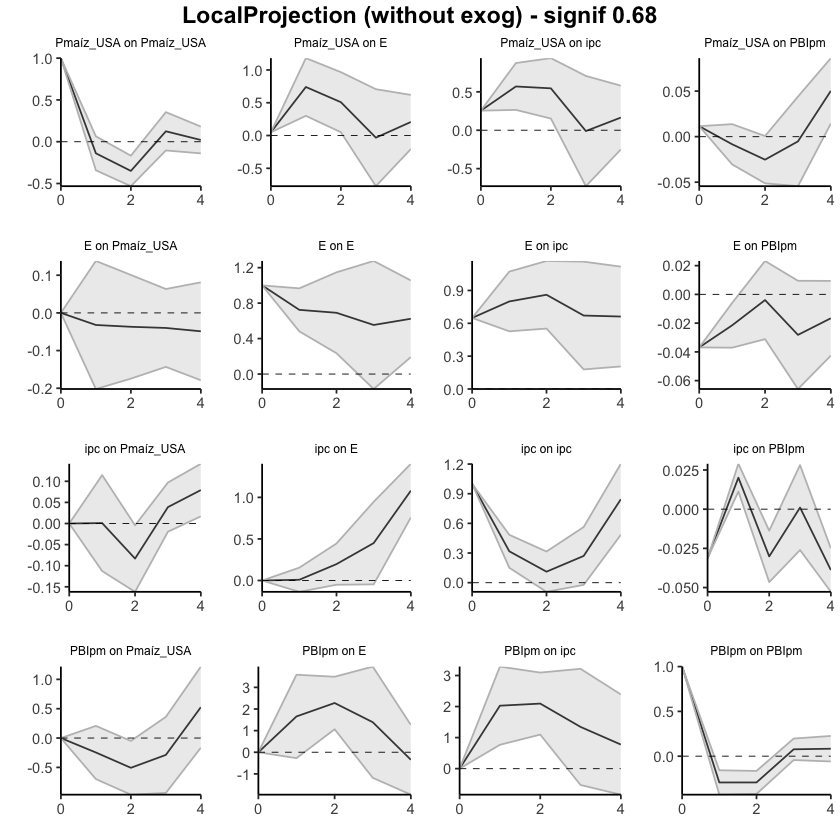

In [120]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,0.00905259,-0.1363337,0.1544389
38,ipc,E,2,0.20605793,-0.1874102,0.5995261
39,ipc,E,3,0.65615366,-0.2338209,1.5461282
40,ipc,E,4,1.73714610,0.5240112,2.9502810


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.656404,-0.2721602,3.584969
53,PBIpm,E,2,3.933642,0.7910152,7.076268
54,PBIpm,E,3,5.323435,-0.3900357,11.036906
55,PBIpm,E,4,4.975787,-2.3502741,12.301848


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,0.04947696,0.04947696,0.04947696
2,Pmaíz_USA,E,1,0.78972072,0.34956674,1.22987469
3,Pmaíz_USA,E,2,1.29820468,0.40006804,2.19634132
4,Pmaíz_USA,E,3,1.26529147,-0.37247677,2.90305971
5,Pmaíz_USA,E,4,1.47212602,-0.57841315,3.52266519


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.011471249,0.01147125,0.01147125
12,Pmaíz_USA,PBIpm,1,0.003096105,-0.01900974,0.02520195
13,Pmaíz_USA,PBIpm,2,-0.022186486,-0.07028234,0.02590936
14,Pmaíz_USA,PBIpm,3,-0.027401048,-0.12468694,0.06988484
15,Pmaíz_USA,PBIpm,4,0.022912570,-0.11029121,0.15611635


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,-0.03207437,-0.2020084,0.1378597
18,E,Pmaíz_USA,2,-0.06895886,-0.3765020,0.2385843
19,E,Pmaíz_USA,3,-0.10891673,-0.5198176,0.3019841
20,E,Pmaíz_USA,4,-0.15775509,-0.6986257,0.3831155


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.0000000000,0.0000000,0.0000000
32,ipc,Pmaíz_USA,1,0.0009667816,-0.1126742,0.1146077
33,ipc,Pmaíz_USA,2,-0.0821447106,-0.2745586,0.1102692
34,ipc,Pmaíz_USA,3,-0.0432894115,-0.2939811,0.2074022
35,ipc,Pmaíz_USA,4,0.0359349146,-0.2770283,0.3488981


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Pmaíz_USA,1,-0.2459424,-0.6990568,0.2071720
48,PBIpm,Pmaíz_USA,2,-0.7528481,-1.6636435,0.1579473
49,PBIpm,Pmaíz_USA,3,-1.0400841,-2.5990961,0.5189279
50,PBIpm,Pmaíz_USA,4,-0.5138421,-2.7641679,1.7364837


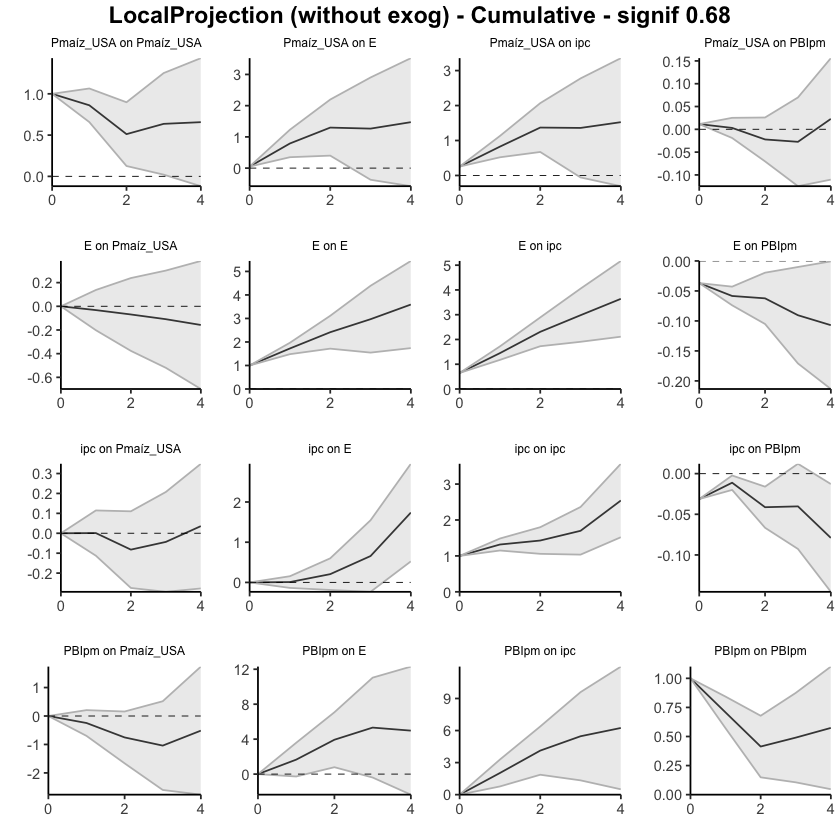

In [121]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.000000000,0.00000000,0.0000000
37,ipc,E,1,0.006394876,-0.15705201,0.1698418
38,ipc,E,2,0.094467163,-0.11751958,0.3064539
39,ipc,E,3,0.363640682,-0.09760217,0.8248835
40,ipc,E,4,1.014521019,0.69413590,1.3349061


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.000000000,0.000000
52,PBIpm,E,1,2.0644749,-0.002948705,4.131898
53,PBIpm,E,2,2.6802827,1.469021496,3.891544
54,PBIpm,E,3,1.4107915,-0.713498060,3.535081
55,PBIpm,E,4,-0.3016169,-1.960266707,1.357033


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.1325829,-0.13258289,-0.1325829
2,Ptrigo_USA,E,1,0.6175649,0.29135074,0.9437790
3,Ptrigo_USA,E,2,1.0647731,0.66804716,1.4614990
4,Ptrigo_USA,E,3,0.6466100,-0.07038709,1.3636070
5,Ptrigo_USA,E,4,0.7232085,0.37633373,1.0700834


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,-0.0088399024,-0.008839902,-0.008839902
12,Ptrigo_USA,PBIpm,1,0.0009552244,-0.025562194,0.027472642
13,Ptrigo_USA,PBIpm,2,-0.0550046211,-0.080681013,-0.029328229
14,Ptrigo_USA,PBIpm,3,-0.0070906314,-0.038296700,0.024115437
15,Ptrigo_USA,PBIpm,4,0.0248286244,-0.001794581,0.051451830


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.000000000,0.0000000,0.00000000
17,E,Ptrigo_USA,1,-0.050351566,-0.1868610,0.08615790
18,E,Ptrigo_USA,2,-0.076843232,-0.3321567,0.17847028
19,E,Ptrigo_USA,3,-0.045155902,-0.1140977,0.02378591
20,E,Ptrigo_USA,4,-0.006337095,-0.1711284,0.15845419


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.000000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.01754044,-0.101101347,0.06602047
33,ipc,Ptrigo_USA,2,0.02991338,-0.127729342,0.18755611
34,ipc,Ptrigo_USA,3,0.04523626,-0.002192259,0.09266477
35,ipc,Ptrigo_USA,4,-0.03066321,-0.112429951,0.05110353


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.12932600,-0.4806014,0.2219494
48,PBIpm,Ptrigo_USA,2,0.20028586,-0.1966781,0.5972498
49,PBIpm,Ptrigo_USA,3,-0.23026655,-0.7218106,0.2612775
50,PBIpm,Ptrigo_USA,4,-0.01592297,-0.6340914,0.6022455


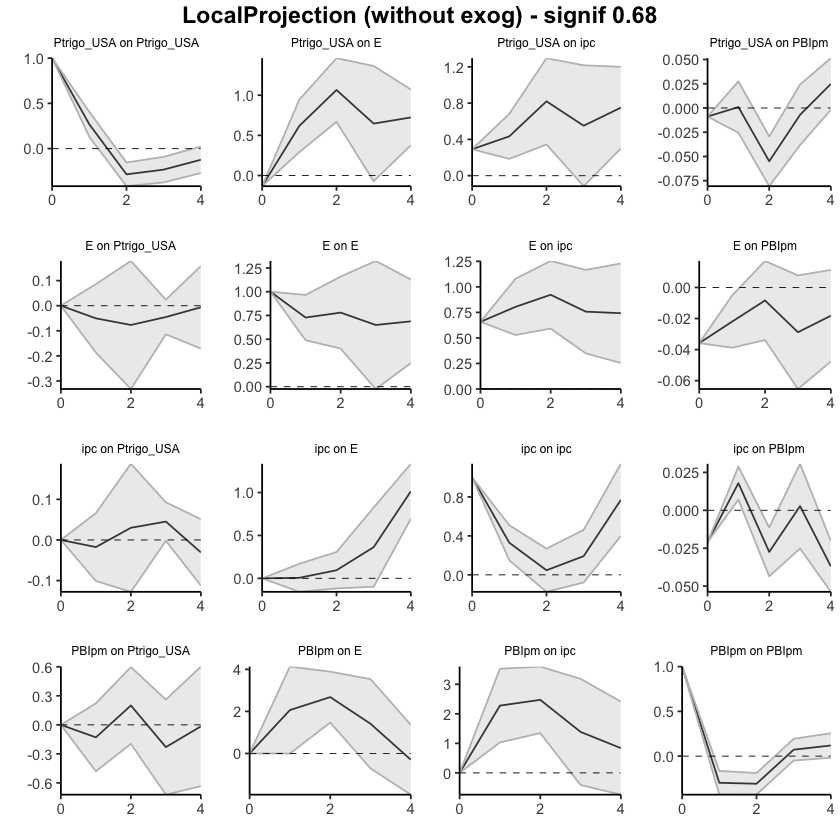

In [122]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.000000000,0.0000000,0.0000000
37,ipc,E,1,0.006394876,-0.1570520,0.1698418
38,ipc,E,2,0.100862038,-0.2745716,0.4762957
39,ipc,E,3,0.464502721,-0.3721738,1.3011792
40,ipc,E,4,1.479023740,0.3219621,2.6360853


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.000000000,0.000000
52,PBIpm,E,1,2.064475,-0.002948705,4.131898
53,PBIpm,E,2,4.744758,1.466072791,8.023442
54,PBIpm,E,3,6.155549,0.752574731,11.558524
55,PBIpm,E,4,5.853932,-1.207691977,12.915556


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.1325829,-0.1325829,-0.1325829
2,Ptrigo_USA,E,1,0.4849820,0.1587678,0.8111961
3,Ptrigo_USA,E,2,1.5497551,0.8268150,2.2726951
4,Ptrigo_USA,E,3,2.1963650,0.7564279,3.6363022
5,Ptrigo_USA,E,4,2.9195736,1.1327616,4.7063855


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,-0.008839902,-0.008839902,-0.008839902
12,Ptrigo_USA,PBIpm,1,-0.007884678,-0.034402096,0.018632740
13,Ptrigo_USA,PBIpm,2,-0.062889299,-0.115083110,-0.010695489
14,Ptrigo_USA,PBIpm,3,-0.069979930,-0.153379809,0.013419948
15,Ptrigo_USA,PBIpm,4,-0.045151306,-0.155174390,0.064871778


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,-0.05035157,-0.1868610,0.0861579
18,E,Ptrigo_USA,2,-0.12719480,-0.5190178,0.2646282
19,E,Ptrigo_USA,3,-0.17235070,-0.6331155,0.2884141
20,E,Ptrigo_USA,4,-0.17868780,-0.8042439,0.4468683


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.01754044,-0.1011013,0.06602047
33,ipc,Ptrigo_USA,2,0.01237294,-0.2288307,0.25357658
34,ipc,Ptrigo_USA,3,0.05760920,-0.2310229,0.34624135
35,ipc,Ptrigo_USA,4,0.02694599,-0.3434529,0.39734488


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,-0.12932600,-0.4806014,0.2219494
48,PBIpm,Ptrigo_USA,2,0.07095986,-0.6772795,0.8191992
49,PBIpm,Ptrigo_USA,3,-0.15930669,-1.3990901,1.0804767
50,PBIpm,Ptrigo_USA,4,-0.17522966,-2.0331815,1.6827222


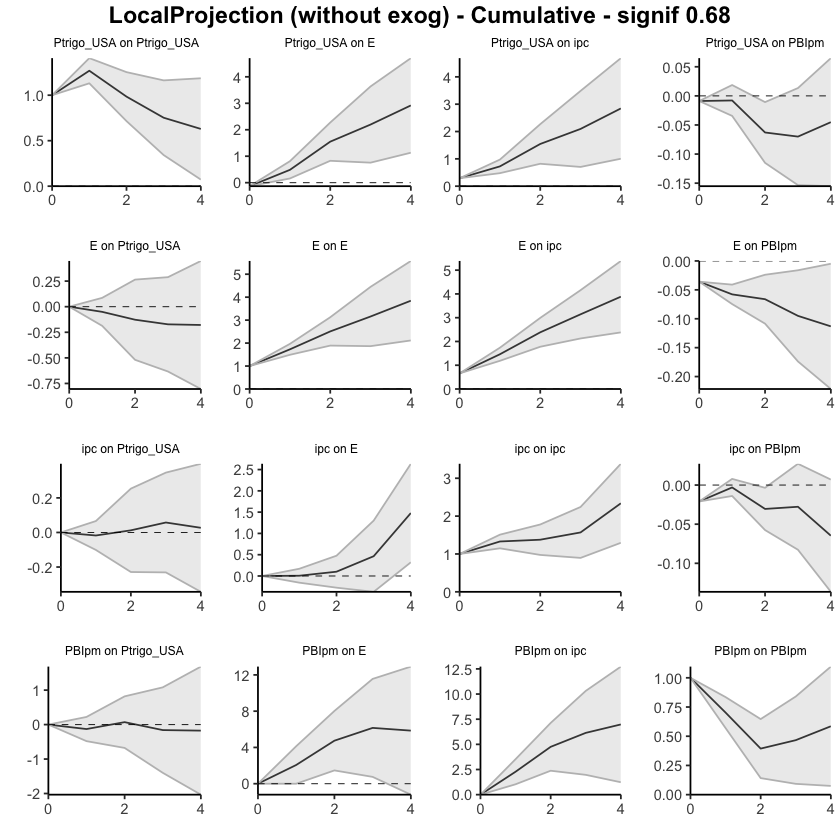

In [123]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.4990251,-0.7475930,-0.2504572
38,ipc,E,2,-0.7918731,-1.0645740,-0.5191721
39,ipc,E,3,-1.6778594,-2.3195680,-1.0361509
40,ipc,E,4,-0.5242318,-0.8898688,-0.1585949


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.0000000
52,PBIpm,E,1,1.8792892,0.07013709,3.6884414
53,PBIpm,E,2,1.9638813,0.69822586,3.2295367
54,PBIpm,E,3,-0.9389119,-2.23094431,0.3531205
55,PBIpm,E,4,-1.8797016,-3.14604467,-0.6133585


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.1841605,-0.1841605,-0.1841605
2,Ptrigo_USA,E,1,0.5358366,-0.1356053,1.2072785
3,Ptrigo_USA,E,2,1.0039695,0.5702677,1.4376714
4,Ptrigo_USA,E,3,0.3943225,-0.1540791,0.9427242
5,Ptrigo_USA,E,4,0.5138540,0.1484283,0.8792796


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,-0.008322461,-0.008322461,-0.008322461
12,Ptrigo_USA,PBIpm,1,0.009632945,-0.023896404,0.043162295
13,Ptrigo_USA,PBIpm,2,-0.056055411,-0.095930933,-0.016179890
14,Ptrigo_USA,PBIpm,3,-0.014572444,-0.048951417,0.019806530
15,Ptrigo_USA,PBIpm,4,0.036125973,0.011879401,0.060372546


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.000000000,0.00000000
17,E,Ptrigo_USA,1,-0.03345116,-0.169050406,0.10214808
18,E,Ptrigo_USA,2,-0.12846472,-0.332755405,0.07582596
19,E,Ptrigo_USA,3,-0.04526634,-0.174466328,0.08393365
20,E,Ptrigo_USA,4,0.10488918,0.002316716,0.20746164


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.000000000
32,ipc,Ptrigo_USA,1,-0.20717748,-0.2921086,-0.122246380
33,ipc,Ptrigo_USA,2,-0.11373173,-0.2254252,-0.002038254
34,ipc,Ptrigo_USA,3,0.08013105,-0.0171148,0.177376906
35,ipc,Ptrigo_USA,4,0.18611866,0.1413121,0.230925225


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,0.05226345,-0.3158155,0.4203424
48,PBIpm,Ptrigo_USA,2,-0.07814589,-0.5223394,0.3660476
49,PBIpm,Ptrigo_USA,3,-0.22617566,-0.9131630,0.4608117
50,PBIpm,Ptrigo_USA,4,0.40961134,-0.3273065,1.1465292


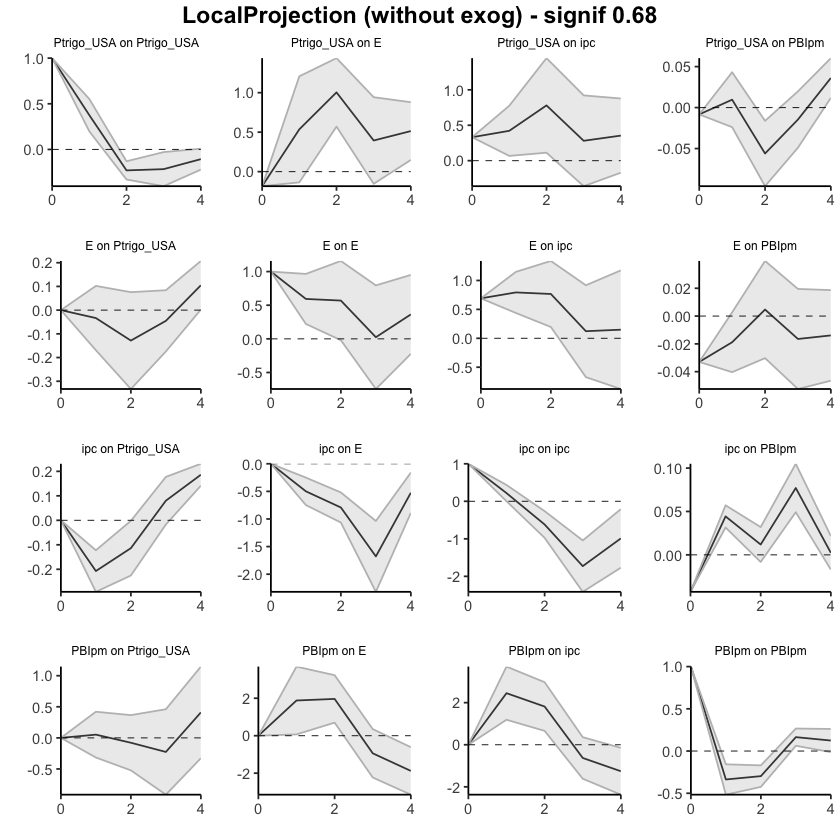

In [124]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.000000,0.0000000
37,ipc,E,1,-0.4990251,-0.747593,-0.2504572
38,ipc,E,2,-1.2908982,-1.812167,-0.7696293
39,ipc,E,3,-2.9687576,-4.131735,-1.8057802
40,ipc,E,4,-3.4929894,-5.021604,-1.9643750


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.00000000,0.000000
52,PBIpm,E,1,1.879289,0.07013709,3.688441
53,PBIpm,E,2,3.843171,0.76836295,6.917978
54,PBIpm,E,3,2.904259,-1.46258136,7.271099
55,PBIpm,E,4,1.024557,-4.60862603,6.657740


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.1841605,-0.18416052,-0.1841605
2,Ptrigo_USA,E,1,0.3516761,-0.31976581,1.0231180
3,Ptrigo_USA,E,2,1.3556456,0.25050186,2.4607893
4,Ptrigo_USA,E,3,1.7499681,0.09642276,3.4035135
5,Ptrigo_USA,E,4,2.2638221,0.24485108,4.2827931


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,-0.008322461,-0.008322461,-0.008322461
12,Ptrigo_USA,PBIpm,1,0.001310484,-0.032218866,0.034839834
13,Ptrigo_USA,PBIpm,2,-0.054744927,-0.128149798,0.018659944
14,Ptrigo_USA,PBIpm,3,-0.069317371,-0.177101215,0.038466474
15,Ptrigo_USA,PBIpm,4,-0.033191397,-0.165221814,0.098839019


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,-0.03345116,-0.1690504,0.1021481
18,E,Ptrigo_USA,2,-0.16191589,-0.5018058,0.1779740
19,E,Ptrigo_USA,3,-0.20718223,-0.6762721,0.2619077
20,E,Ptrigo_USA,4,-0.10229305,-0.6739554,0.4693693


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.0000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.2071775,-0.2921086,-0.12224638
33,ipc,Ptrigo_USA,2,-0.3209092,-0.5175338,-0.12428463
34,ipc,Ptrigo_USA,3,-0.2407782,-0.5346486,0.05309227
35,ipc,Ptrigo_USA,4,-0.0546595,-0.3933365,0.28401750


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,0.05226345,-0.3158155,0.4203424
48,PBIpm,Ptrigo_USA,2,-0.02588244,-0.8381549,0.7863900
49,PBIpm,Ptrigo_USA,3,-0.25205811,-1.7513179,1.2472017
50,PBIpm,Ptrigo_USA,4,0.15755324,-2.0786244,2.3937309


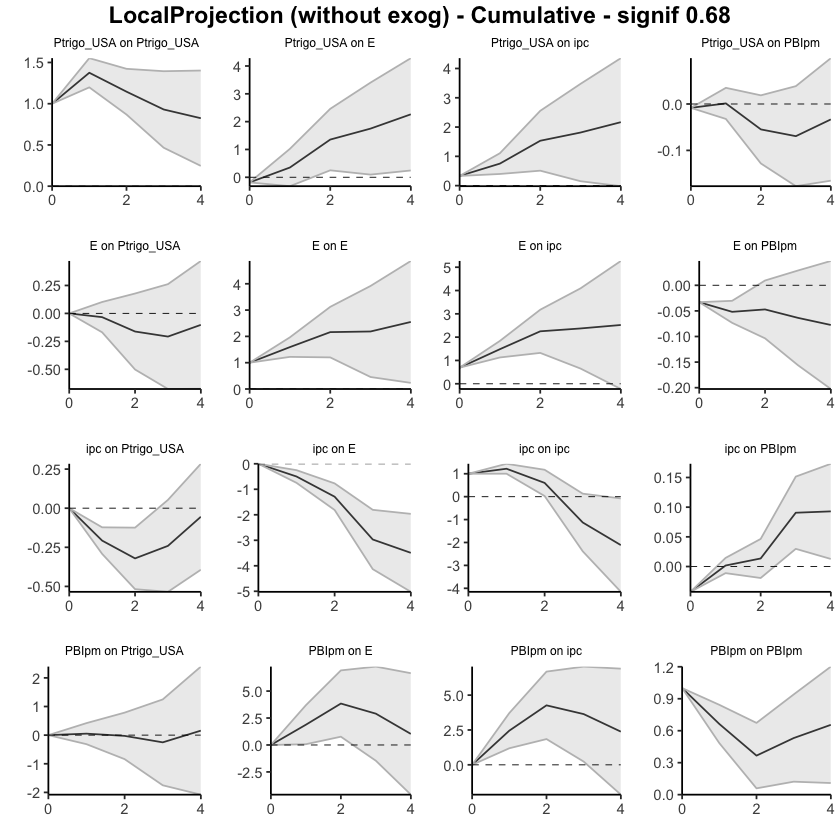

In [125]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.0937428,-0.4136669,0.2261813
38,ipc,E,2,-0.1817798,-0.6020956,0.2385360
39,ipc,E,3,-0.9869751,-1.3276467,-0.6463034
40,ipc,E,4,-0.5659544,-0.9917142,-0.1401946


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,3.0179641,1.9636416,4.072287
53,PBIpm,E,2,2.1772237,1.0245045,3.329943
54,PBIpm,E,3,0.8375115,-0.1262287,1.801252
55,PBIpm,E,4,0.4562148,-0.6202940,1.532724


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.1802595,-0.18025952,-0.1802595
2,Ptrigo_USA,E,1,0.2380584,-0.22161307,0.6977299
3,Ptrigo_USA,E,2,1.1639478,0.76227130,1.5656243
4,Ptrigo_USA,E,3,0.6836570,0.09048257,1.2768315
5,Ptrigo_USA,E,4,0.9562234,0.54611538,1.3663314


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,-0.008472152,-0.008472152,-0.008472152
12,Ptrigo_USA,PBIpm,1,0.055183678,-0.005669359,0.116036714
13,Ptrigo_USA,PBIpm,2,-0.082036800,-0.144982579,-0.019091021
14,Ptrigo_USA,PBIpm,3,-0.016000040,-0.121869393,0.089869313
15,Ptrigo_USA,PBIpm,4,0.022684503,-0.007262452,0.052631458


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,0.08552838,-0.2475654,0.4186222
18,E,Ptrigo_USA,2,0.02739772,-0.4001827,0.4549782
19,E,Ptrigo_USA,3,0.00597356,-0.3177489,0.3296960
20,E,Ptrigo_USA,4,0.08500740,-0.1228891,0.2929039


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.0000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.4547074,-0.6312893,-0.27812546
33,ipc,Ptrigo_USA,2,-0.1324348,-0.3220575,0.05718782
34,ipc,Ptrigo_USA,3,0.3010097,0.1364285,0.46559091
35,ipc,Ptrigo_USA,4,0.2394047,0.1363064,0.34250292


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.0000000,0.0000000,0.00000000
47,PBIpm,Ptrigo_USA,1,0.1473816,-0.3723251,0.66708839
48,PBIpm,Ptrigo_USA,2,-0.5453821,-1.1276597,0.03689541
49,PBIpm,Ptrigo_USA,3,1.0010893,0.1775543,1.82462419
50,PBIpm,Ptrigo_USA,4,1.0893601,0.5507900,1.62793008


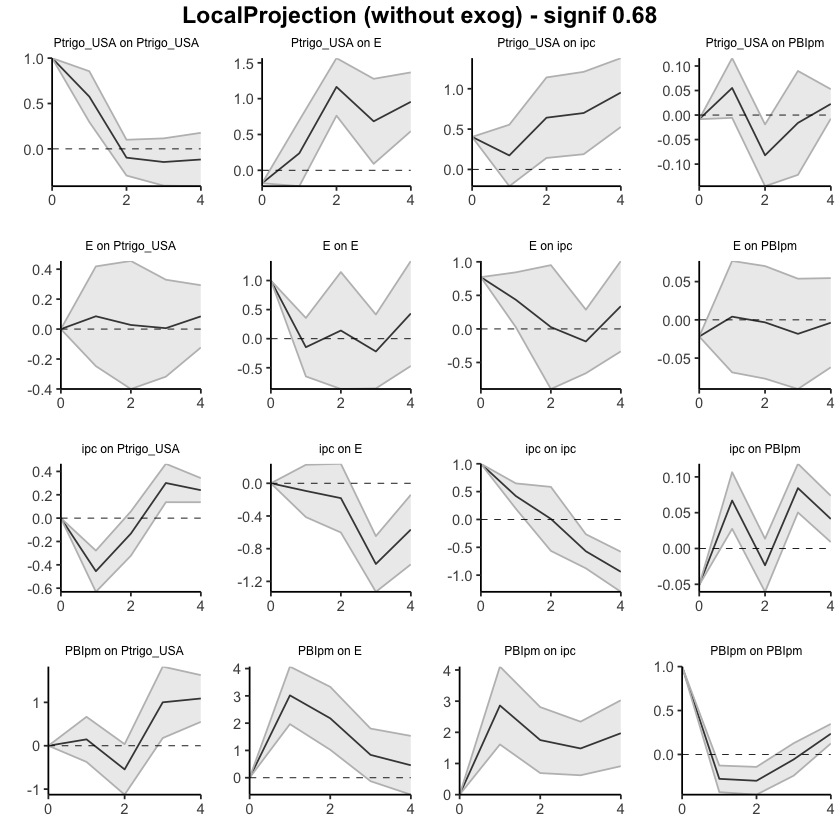

In [127]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.0937428,-0.4136669,0.2261813
38,ipc,E,2,-0.2755226,-1.0157624,0.4647173
39,ipc,E,3,-1.2624976,-2.3434091,-0.1815862
40,ipc,E,4,-1.8284520,-3.3351233,-0.3217807


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.000000,0.000000
52,PBIpm,E,1,3.017964,1.963642,4.072287
53,PBIpm,E,2,5.195188,2.988146,7.402229
54,PBIpm,E,3,6.032699,2.861917,9.203481
55,PBIpm,E,4,6.488914,2.241623,10.736205


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.18025952,-0.1802595,-0.1802595
2,Ptrigo_USA,E,1,0.05779887,-0.4018726,0.5174703
3,Ptrigo_USA,E,2,1.22174669,0.3603987,2.0830947
4,Ptrigo_USA,E,3,1.90540373,0.4508813,3.3599262
5,Ptrigo_USA,E,4,2.86162713,0.9969967,4.7262576


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,-0.008472152,-0.008472152,-0.008472152
12,Ptrigo_USA,PBIpm,1,0.046711525,-0.014141511,0.107564562
13,Ptrigo_USA,PBIpm,2,-0.035325275,-0.159124090,0.088473541
14,Ptrigo_USA,PBIpm,3,-0.051325315,-0.280993483,0.178342854
15,Ptrigo_USA,PBIpm,4,-0.028640812,-0.288255935,0.230974311


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,0.08552838,-0.2475654,0.4186222
18,E,Ptrigo_USA,2,0.11292611,-0.6477482,0.8736004
19,E,Ptrigo_USA,3,0.11889967,-0.9654971,1.2032964
20,E,Ptrigo_USA,4,0.20390707,-1.0883861,1.4962003


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
32,ipc,Ptrigo_USA,1,-0.45470740,-0.6312893,-0.2781255
33,ipc,Ptrigo_USA,2,-0.58714222,-0.9533468,-0.2209376
34,ipc,Ptrigo_USA,3,-0.28613252,-0.8169183,0.2446533
35,ipc,Ptrigo_USA,4,-0.04672786,-0.6806119,0.5871562


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,0.1473816,-0.3723251,0.6670884
48,PBIpm,Ptrigo_USA,2,-0.3980005,-1.4999848,0.7039838
49,PBIpm,Ptrigo_USA,3,0.6030888,-1.3224305,2.5286080
50,PBIpm,Ptrigo_USA,4,1.6924488,-0.7716405,4.1565381


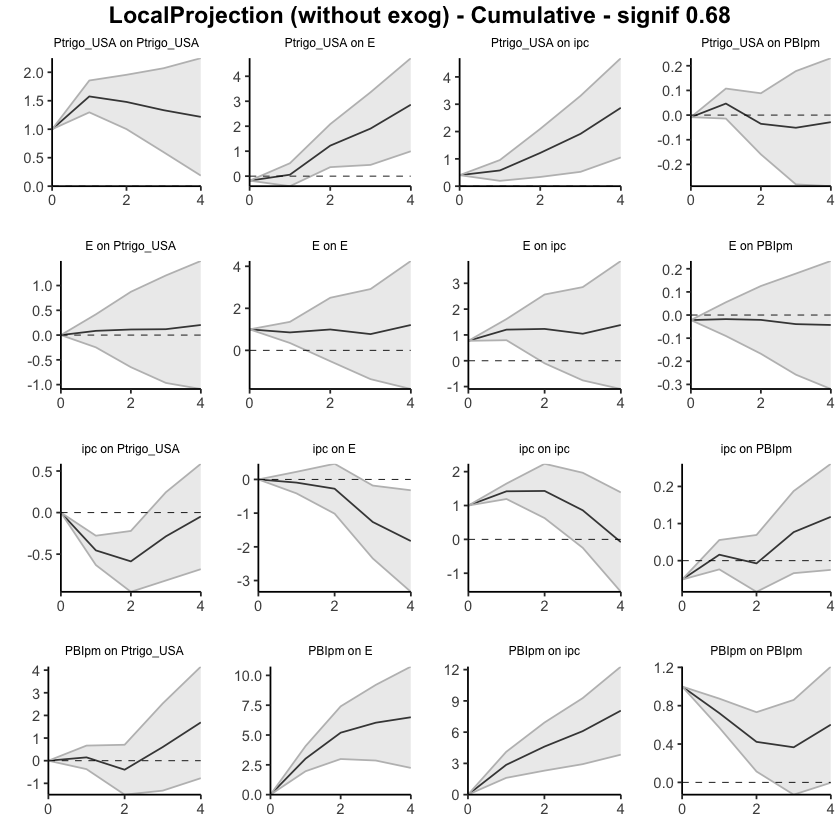

In [126]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

### 1935-1990. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.09892529,-0.2535024,0.05565183
13,ipc,E,2,0.08573579,-0.2250145,0.39648609
14,ipc,E,3,0.43993963,-0.1045360,0.98441522
15,ipc,E,4,1.12020481,0.7485322,1.49187739


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,1.0813449,-1.1791567,3.341847
23,PBIpm,E,2,1.7047526,0.5850569,2.824448
24,PBIpm,E,3,1.2964761,-1.4441510,4.037103
25,PBIpm,E,4,-0.1531396,-1.7514752,1.445196


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6444619,0.6444619,0.6444619
2,E,ipc,1,0.8537648,0.5850743,1.1224552
3,E,ipc,2,0.9348900,0.4819037,1.3878762
4,E,ipc,3,0.7289047,0.2767662,1.1810433
5,E,ipc,4,0.6339098,0.1551063,1.1127134


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.6018542,0.3778971,2.825811
28,PBIpm,ipc,2,1.4988974,0.4301961,2.567599
29,PBIpm,ipc,3,1.0104379,-1.1314442,3.152320
30,PBIpm,ipc,4,0.9654305,-0.6782229,2.609084


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.033075319,-0.03307532,-0.033075319
7,E,PBIpm,1,-0.027604681,-0.04692306,-0.008286301
8,E,PBIpm,2,-0.005487267,-0.03738062,0.026406085
9,E,PBIpm,3,-0.024568102,-0.06510301,0.015966802
10,E,PBIpm,4,-0.014492571,-0.04788745,0.018902310


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.023005322,-0.02300532,-0.02300532
17,ipc,PBIpm,1,0.027826744,0.01613221,0.03952128
18,ipc,PBIpm,2,-0.031164825,-0.05082570,-0.01150395
19,ipc,PBIpm,3,-0.002840374,-0.03191708,0.02623633
20,ipc,PBIpm,4,-0.042679379,-0.06139847,-0.02396029


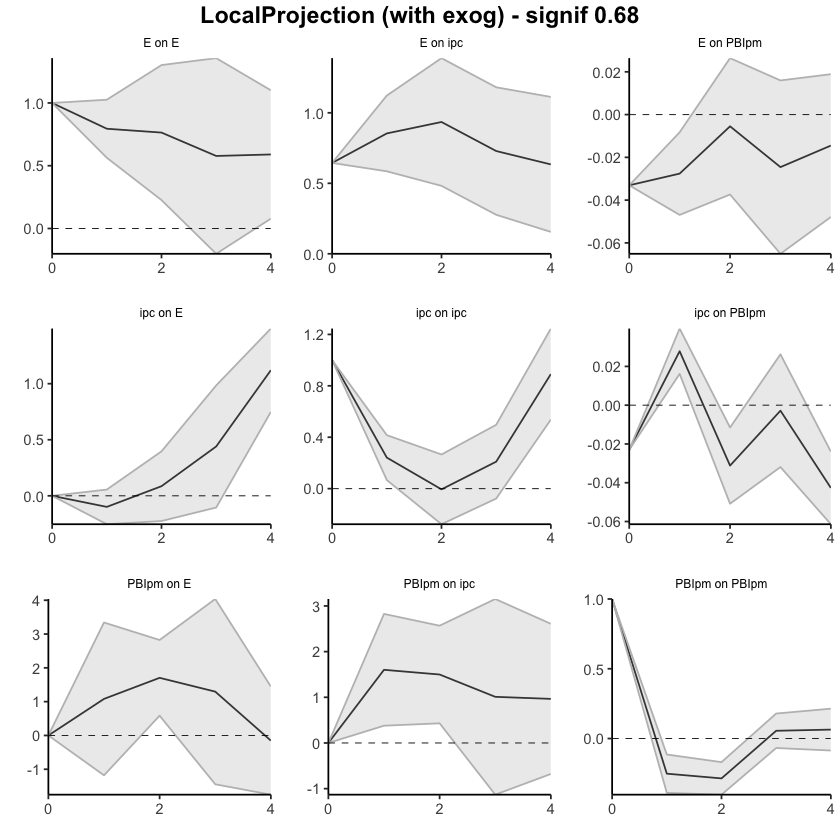

In [129]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.09892529,-0.2535024,0.05565183
13,ipc,E,2,-0.01318950,-0.4785169,0.45213792
14,ipc,E,3,0.42675013,-0.5830529,1.43655314
15,ipc,E,4,1.54695494,0.1654793,2.92843053


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,1.081345,-1.1791567,3.341847
23,PBIpm,E,2,2.786098,-0.5940998,6.166295
24,PBIpm,E,3,4.082574,-2.0382508,10.203398
25,PBIpm,E,4,3.929434,-3.7897260,11.648594


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6444619,0.6444619,0.6444619
2,E,ipc,1,1.4982267,1.2295362,1.7669172
3,E,ipc,2,2.4331167,1.7114399,3.1547934
4,E,ipc,3,3.1620214,1.9882060,4.3358367
5,E,ipc,4,3.7959312,2.1433123,5.4485501


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.601854,0.3778971,2.825811
28,PBIpm,ipc,2,3.100752,0.8080931,5.393410
29,PBIpm,ipc,3,4.111189,-0.3233510,8.545730
30,PBIpm,ipc,4,5.076620,-1.0015740,11.154814


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03307532,-0.03307532,-0.033075319
7,E,PBIpm,1,-0.06068000,-0.07999838,-0.041361620
8,E,PBIpm,2,-0.06616727,-0.11737900,-0.014955535
9,E,PBIpm,3,-0.09073537,-0.18248200,0.001011267
10,E,PBIpm,4,-0.10522794,-0.23036946,0.019913577


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.023005322,-0.023005322,-0.023005322
17,ipc,PBIpm,1,0.004821422,-0.006873115,0.016515959
18,ipc,PBIpm,2,-0.026343403,-0.057698819,0.005012013
19,ipc,PBIpm,3,-0.029183776,-0.089615895,0.031248342
20,ipc,PBIpm,4,-0.071863155,-0.151014364,0.007288053


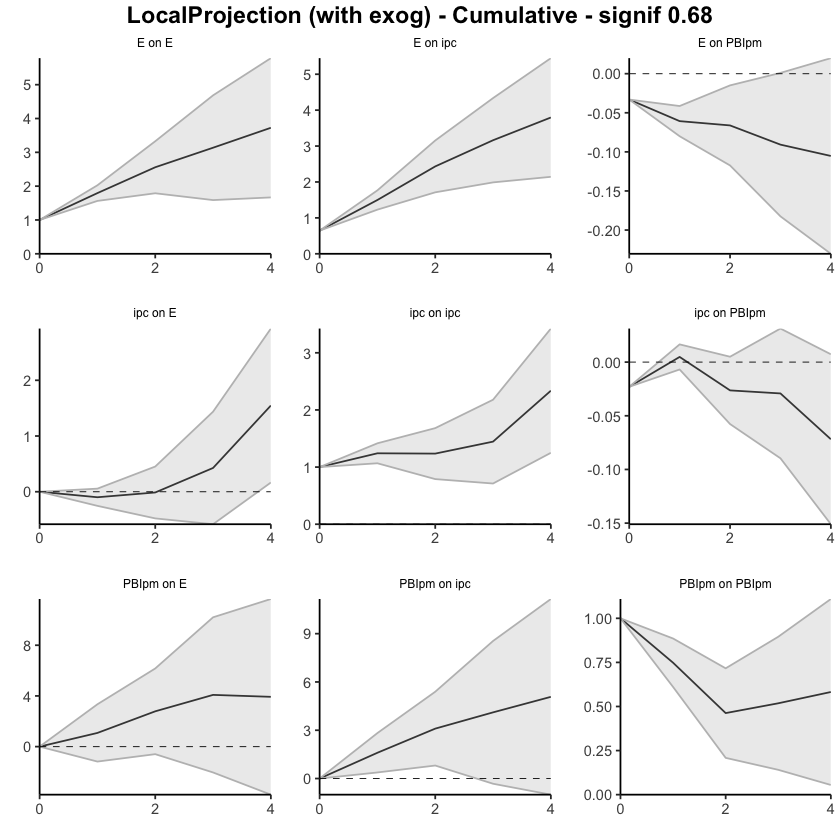

In [128]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,NA,NaN,NA,5,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.6663975,-0.9642612,-0.36853378
13,ipc,E,2,-0.0837352,-0.4110322,0.24356179
14,ipc,E,3,-1.2142369,-1.5832325,-0.84524126
15,ipc,E,4,-0.1061475,-0.2658961,0.05360099


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.00000000,0.0000000,0.000000
22,PBIpm,E,1,2.62610643,1.4825199,3.769693
23,PBIpm,E,2,1.21224917,0.1834646,2.241034
24,PBIpm,E,3,-0.09036603,-1.1161591,0.935427
25,PBIpm,E,4,0.17550391,-1.1005482,1.451556


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.680293682,0.6802937,0.6802937
2,E,ipc,1,0.588370249,0.3282076,0.8485329
3,E,ipc,2,0.276915237,-0.2579536,0.8117841
4,E,ipc,3,-0.001144689,-5.0534648,5.0511754
5,E,ipc,4,0.276497329,-0.2196362,0.7726309


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.000000000,0.000000
27,PBIpm,ipc,1,2.7794158,1.840487652,3.718344
28,PBIpm,ipc,2,1.2323236,0.008387118,2.456260
29,PBIpm,ipc,3,-0.4828274,-15.723210688,14.757556
30,PBIpm,ipc,4,1.0372553,-0.055037278,2.129548


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01394397,-0.01394397,-0.013943971
7,E,PBIpm,1,-0.01409100,-0.03165265,0.003470651
8,E,PBIpm,2,0.00807860,-0.02796873,0.044125927
9,E,PBIpm,3,-0.01619015,-0.05237313,0.019992829
10,E,PBIpm,4,-0.01708986,-0.08107049,0.046890770


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.057242096,-0.0572420962,-0.057242096
17,ipc,PBIpm,1,0.086828336,0.0829785328,0.090678139
18,ipc,PBIpm,2,-0.024592660,-0.0429312645,-0.006254056
19,ipc,PBIpm,3,0.021608784,0.0002164346,0.043001133
20,ipc,PBIpm,4,0.002486124,-0.0416381693,0.046610417


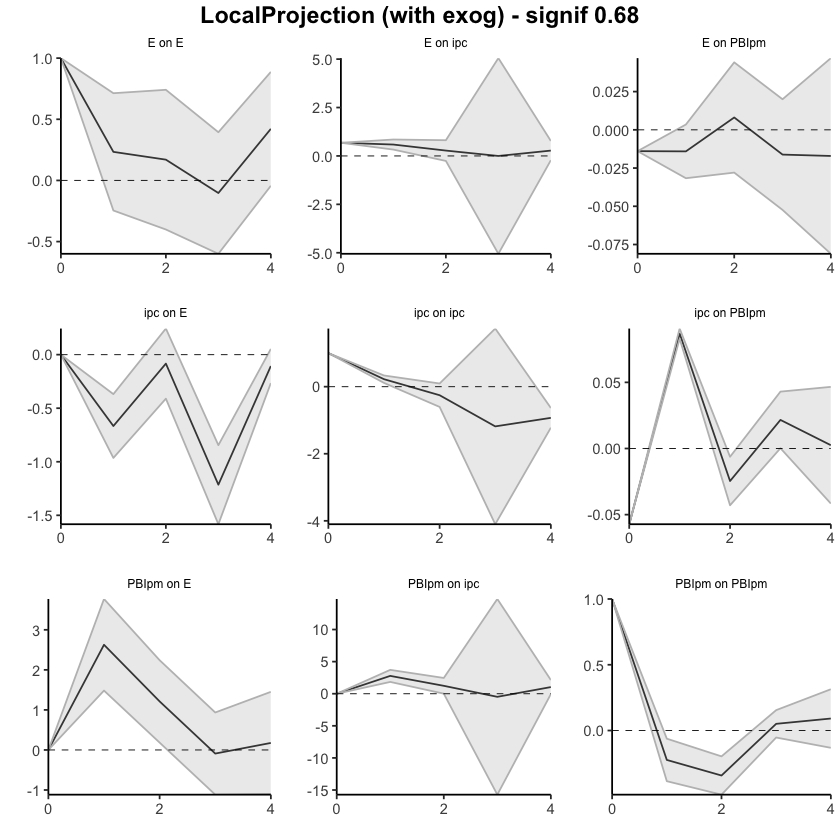

In [130]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 5, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,NA,NaN,NA,5,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,-0.6663975,-0.9642612,-0.3685338
13,ipc,E,2,-0.7501327,-1.3752934,-0.1249720
14,ipc,E,3,-1.9643696,-2.9585259,-0.9702133
15,ipc,E,4,-2.0705171,-3.2244219,-0.9166123


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,2.626106,1.4825199,3.769693
23,PBIpm,E,2,3.838356,1.6659845,6.010727
24,PBIpm,E,3,3.747990,0.5498254,6.946154
25,PBIpm,E,4,3.923493,-0.5507228,8.397710


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6802937,0.6802937,0.6802937
2,E,ipc,1,1.2686639,1.0085013,1.5288265
3,E,ipc,2,1.5455792,0.7505477,2.3406106
4,E,ipc,3,1.5444345,-4.3029170,7.3917860
5,E,ipc,4,1.8209318,-4.5225533,8.1644169


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.000000,0.000000
27,PBIpm,ipc,1,2.779416,1.840488,3.718344
28,PBIpm,ipc,2,4.011739,1.848875,6.174604
29,PBIpm,ipc,3,3.528912,-13.874336,20.932160
30,PBIpm,ipc,4,4.566167,-13.929373,23.061708


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01394397,-0.01394397,-0.01394397
7,E,PBIpm,1,-0.02803497,-0.04559663,-0.01047332
8,E,PBIpm,2,-0.01995637,-0.07356535,0.03365261
9,E,PBIpm,3,-0.03614652,-0.12593848,0.05364544
10,E,PBIpm,4,-0.05323638,-0.20700897,0.10053621


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.057242096,-0.05724210,-0.05724210
17,ipc,PBIpm,1,0.029586240,0.02573644,0.03343604
18,ipc,PBIpm,2,0.004993579,-0.01719483,0.02718199
19,ipc,PBIpm,3,0.026602363,-0.01697839,0.07018312
20,ipc,PBIpm,4,0.029088487,-0.05861656,0.11679354


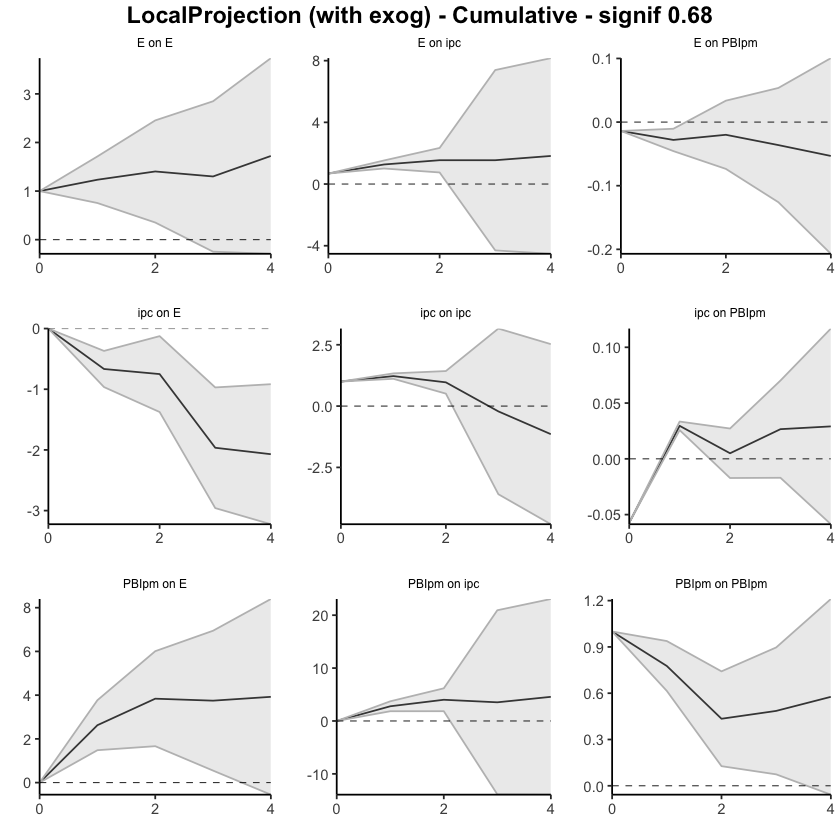

In [131]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 5, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.0000000
12,ipc,E,1,0.02247296,-0.13853881,0.1834847
13,ipc,E,2,0.21545576,-0.04246249,0.4733740
14,ipc,E,3,0.46135600,-0.05597970,0.9786917
15,ipc,E,4,1.07817575,0.74195002,1.4144015


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,1.6564042,-0.2721602,3.584969
23,PBIpm,E,2,2.2772374,1.0631754,3.491299
24,PBIpm,E,3,1.3897934,-1.1810509,3.960638
25,PBIpm,E,4,-0.3476482,-1.9602384,1.264942


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6510736,0.6510736,0.6510736
2,E,ipc,1,0.8005620,0.5272821,1.0738419
3,E,ipc,2,0.8612251,0.5517943,1.1706559
4,E,ipc,3,0.6717348,0.1786146,1.1648550
5,E,ipc,4,0.6637352,0.2067998,1.1206706


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,2.0276766,0.7684179,3.286935
28,PBIpm,ipc,2,2.0953432,1.0965100,3.094176
29,PBIpm,ipc,3,1.3443969,-0.5269642,3.215758
30,PBIpm,ipc,4,0.7756778,-0.8379608,2.389316


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.036754718,-0.03675472,-0.036754718
7,E,PBIpm,1,-0.021529773,-0.03713794,-0.005921606
8,E,PBIpm,2,-0.004064007,-0.03133604,0.023208027
9,E,PBIpm,3,-0.028154922,-0.06588872,0.009578873
10,E,PBIpm,4,-0.016656769,-0.04270484,0.009391305


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.023172368,-0.023172368,-0.02317237
17,ipc,PBIpm,1,0.017732828,0.007761406,0.02770425
18,ipc,PBIpm,2,-0.032509357,-0.049958389,-0.01506032
19,ipc,PBIpm,3,0.001664803,-0.026408890,0.02973850
20,ipc,PBIpm,4,-0.038157515,-0.053207134,-0.02310790


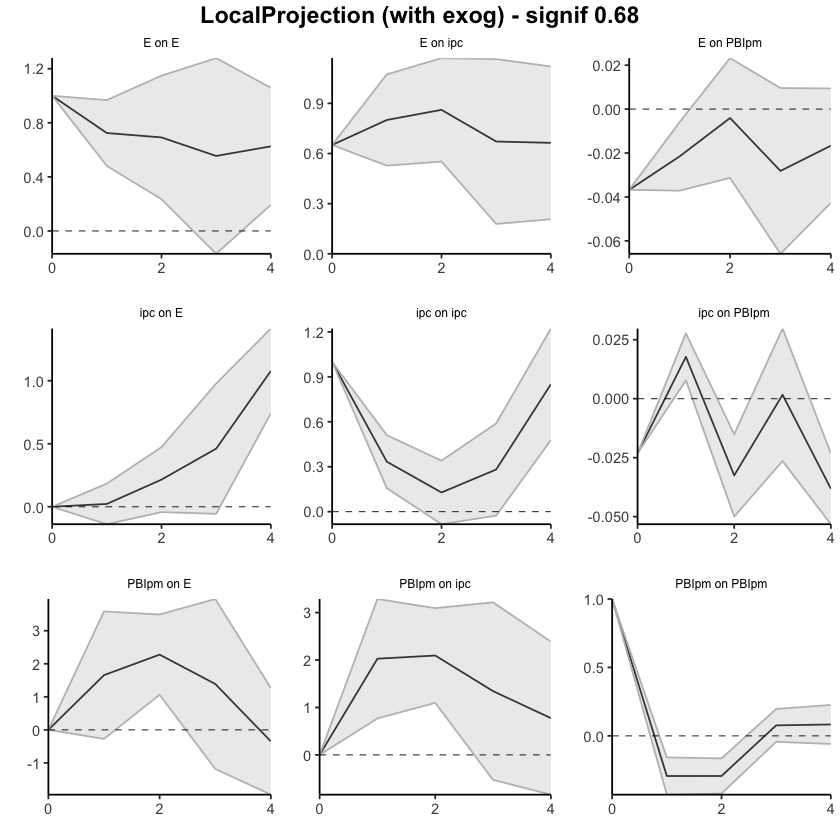

In [132]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.02247296,-0.1385388,0.1834847
13,ipc,E,2,0.23792872,-0.1810013,0.6568588
14,ipc,E,3,0.69928472,-0.2369810,1.6355504
15,ipc,E,4,1.77746047,0.5049690,3.0499519


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,1.656404,-0.2721602,3.584969
23,PBIpm,E,2,3.933642,0.7910152,7.076268
24,PBIpm,E,3,5.323435,-0.3900357,11.036906
25,PBIpm,E,4,4.975787,-2.3502741,12.301848


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6510736,0.6510736,0.6510736
2,E,ipc,1,1.4516356,1.1783557,1.7249156
3,E,ipc,2,2.3128608,1.7301500,2.8955715
4,E,ipc,3,2.9845955,1.9087646,4.0604265
5,E,ipc,4,3.6483307,2.1155644,5.1810971


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,2.027677,0.7684179,3.286935
28,PBIpm,ipc,2,4.123020,1.8649279,6.381112
29,PBIpm,ipc,3,5.467417,1.3379637,9.596870
30,PBIpm,ipc,4,6.243094,0.5000029,11.986186


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03675472,-0.03675472,-0.036754718
7,E,PBIpm,1,-0.05828449,-0.07389266,-0.042676324
8,E,PBIpm,2,-0.06234850,-0.10522870,-0.019468297
9,E,PBIpm,3,-0.09050342,-0.17111742,-0.009889424
10,E,PBIpm,4,-0.10716019,-0.21382226,-0.000498119


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.023172368,-0.02317237,-0.023172368
17,ipc,PBIpm,1,-0.005439539,-0.01541096,0.004531883
18,ipc,PBIpm,2,-0.037948897,-0.06536935,-0.010528442
19,ipc,PBIpm,3,-0.036284094,-0.09177824,0.019210054
20,ipc,PBIpm,4,-0.074441609,-0.14498538,-0.003897843


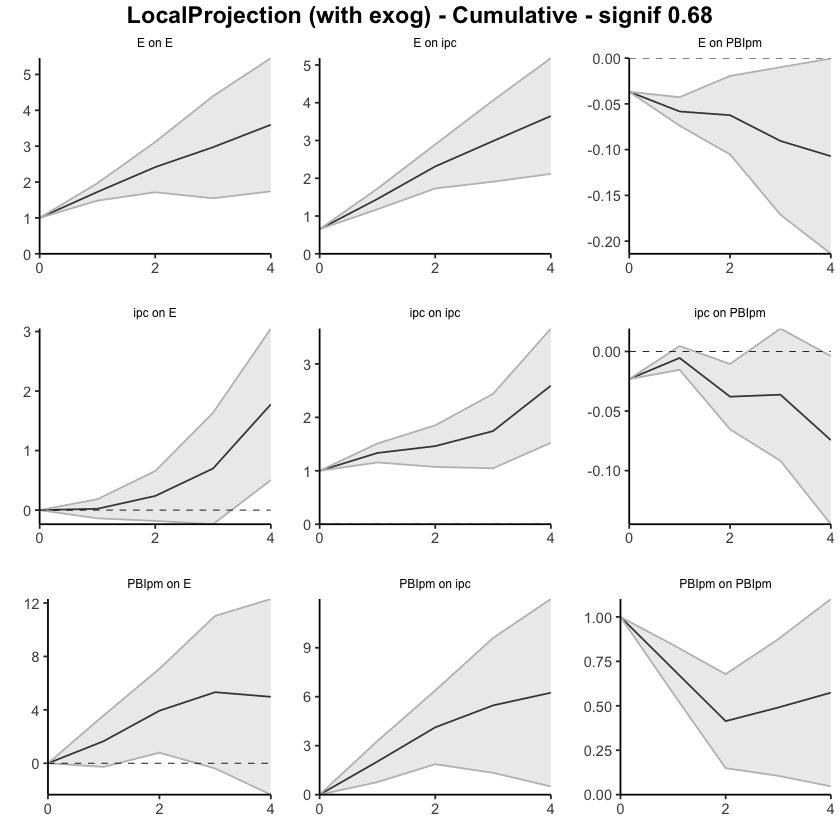

In [133]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,NA,NaN,NA,5,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.44396753,-0.6370284,-0.25090669
13,ipc,E,2,-0.07547056,-0.3060496,0.15510852
14,ipc,E,3,-0.87005542,-1.1797848,-0.56032602
15,ipc,E,4,-0.20468600,-0.3427630,-0.06660902


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,3.1139189,1.8942100,4.333628
23,PBIpm,E,2,1.6250138,0.4326761,2.817352
24,PBIpm,E,3,0.8272277,-0.3868141,2.041269
25,PBIpm,E,4,0.4448347,-1.2672621,2.156932


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.70657804,0.7065780,0.7065780
2,E,ipc,1,0.57350768,0.2448978,0.9021175
3,E,ipc,2,0.02497278,-7.3282504,7.3781959
4,E,ipc,3,-0.24370025,-0.8151799,0.3277794
5,E,ipc,4,0.17131813,-0.1625337,0.5051700


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,3.144903,1.6710355,4.618770
28,PBIpm,ipc,2,1.418800,-23.5166201,26.354220
29,PBIpm,ipc,3,0.419728,-0.9221872,1.761643
30,PBIpm,ipc,4,1.832992,0.5423562,3.123627


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.024910669,-0.02491067,-0.024910669
7,E,PBIpm,1,-0.006652350,-0.03197925,0.018674547
8,E,PBIpm,2,0.009477340,-0.01906643,0.038021115
9,E,PBIpm,3,-0.021970378,-0.05104008,0.007099322
10,E,PBIpm,4,-0.006449745,-0.06691132,0.054011831


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.05897613,-0.058976134,-0.05897613
17,ipc,PBIpm,1,0.08199439,0.069985315,0.09400346
18,ipc,PBIpm,2,-0.03320444,-0.047164900,-0.01924398
19,ipc,PBIpm,3,0.02187844,0.008197936,0.03555893
20,ipc,PBIpm,4,0.01976462,-0.020992475,0.06052171


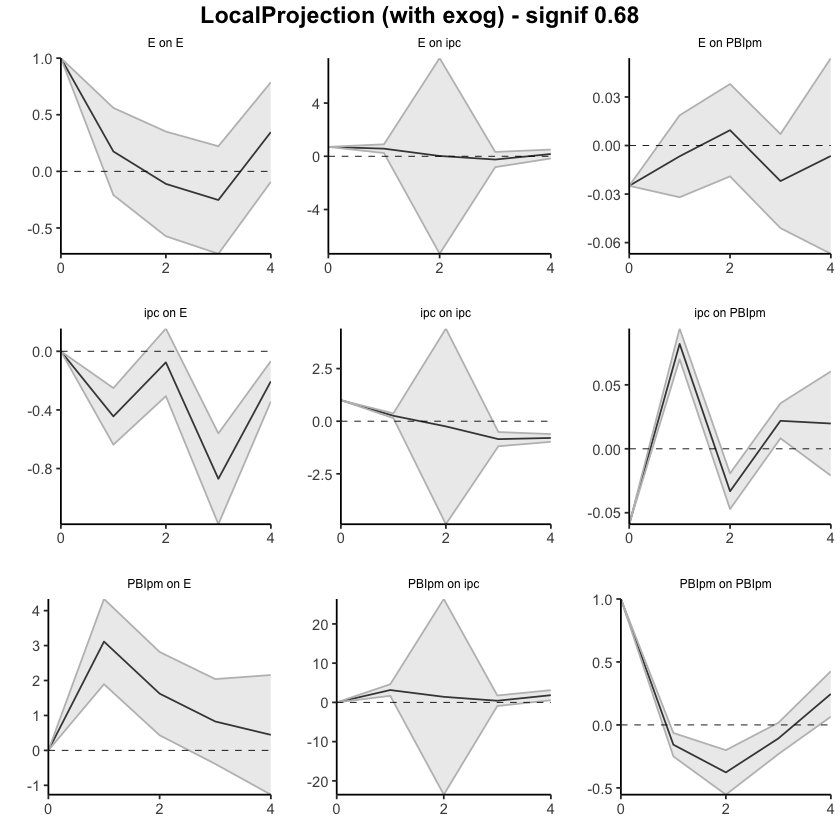

In [135]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 5, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,NA,NaN,NA,5,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.4439675,-0.6370284,-0.25090669
13,ipc,E,2,-0.5194381,-0.9430780,-0.09579818
14,ipc,E,3,-1.3894935,-2.1228628,-0.65612420
15,ipc,E,4,-1.5941795,-2.4656258,-0.72273321


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,3.113919,1.8942100,4.333628
23,PBIpm,E,2,4.738933,2.3268861,7.150979
24,PBIpm,E,3,5.566160,1.9400720,9.192249
25,PBIpm,E,4,6.010995,0.6728099,11.349180


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.706578,0.7065780,0.706578
2,E,ipc,1,1.280086,0.9514759,1.608696
3,E,ipc,2,1.305058,-6.3767745,8.986891
4,E,ipc,3,1.061358,-7.1919544,9.314671
5,E,ipc,4,1.232676,-7.3544881,9.819841


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.000000,0.00000
27,PBIpm,ipc,1,3.144903,1.671036,4.61877
28,PBIpm,ipc,2,4.563702,-21.845585,30.97299
29,PBIpm,ipc,3,4.983430,-22.767772,32.73463
30,PBIpm,ipc,4,6.816422,-22.225415,35.85826


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.02491067,-0.02491067,-0.024910669
7,E,PBIpm,1,-0.03156302,-0.05688992,-0.006236121
8,E,PBIpm,2,-0.02208568,-0.07595635,0.031784993
9,E,PBIpm,3,-0.04405606,-0.12699643,0.038884315
10,E,PBIpm,4,-0.05050580,-0.19390775,0.092896146


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.05897613,-0.05897613,-0.05897613
17,ipc,PBIpm,1,0.02301825,0.01100918,0.03502732
18,ipc,PBIpm,2,-0.01018619,-0.03615572,0.01578334
19,ipc,PBIpm,3,0.01169225,-0.02795778,0.05134228
20,ipc,PBIpm,4,0.03145687,-0.04895026,0.11186399


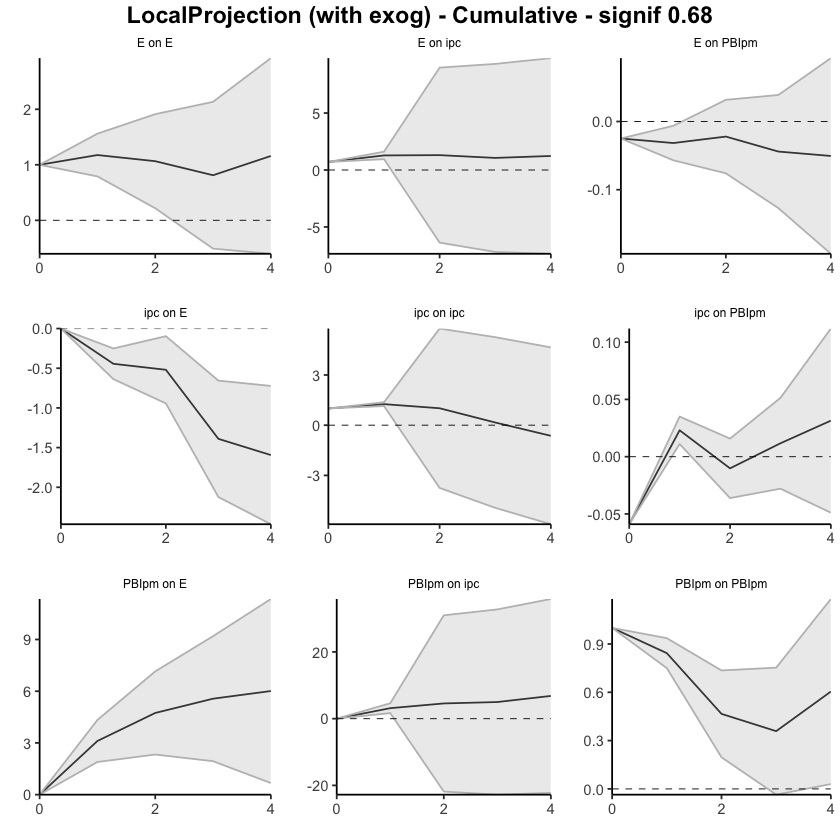

In [134]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 5, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.00000000,0.0000000
12,ipc,E,1,0.002036953,-0.15704578,0.1611197
13,ipc,E,2,0.088809325,-0.12062055,0.2982392
14,ipc,E,3,0.360662628,-0.09609604,0.8174213
15,ipc,E,4,1.015157705,0.69827385,1.3320416


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.000000000,0.000000
22,PBIpm,E,1,2.0644749,-0.002948705,4.131898
23,PBIpm,E,2,2.6802827,1.469021496,3.891544
24,PBIpm,E,3,1.4107915,-0.713498060,3.535081
25,PBIpm,E,4,-0.3016169,-1.960266707,1.357033


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6523217,0.6523217,0.6523217
2,E,ipc,1,0.8029334,0.5277354,1.0781315
3,E,ipc,2,0.9226833,0.5926624,1.2527042
4,E,ipc,3,0.7564857,0.3492259,1.1637455
5,E,ipc,4,0.7382543,0.2530608,1.2234478


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,2.2792246,1.0311849,3.527264
28,PBIpm,ipc,2,2.4740690,1.3474825,3.600656
29,PBIpm,ipc,3,1.3886234,-0.4091334,3.186380
30,PBIpm,ipc,4,0.8382308,-0.7378458,2.414307


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.035634469,-0.03563447,-0.035634469
7,E,PBIpm,1,-0.022091522,-0.03887447,-0.005308569
8,E,PBIpm,2,-0.008258881,-0.03365058,0.017132820
9,E,PBIpm,3,-0.028819941,-0.06526303,0.007623150
10,E,PBIpm,4,-0.017972327,-0.04737091,0.011426253


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.02307173,-0.023071727,-0.02307173
17,ipc,PBIpm,1,0.01853733,0.007898333,0.02917633
18,ipc,PBIpm,2,-0.02680507,-0.042635302,-0.01097484
19,ipc,PBIpm,3,0.00261791,-0.025057745,0.03029357
20,ipc,PBIpm,4,-0.03723743,-0.053730043,-0.02074481


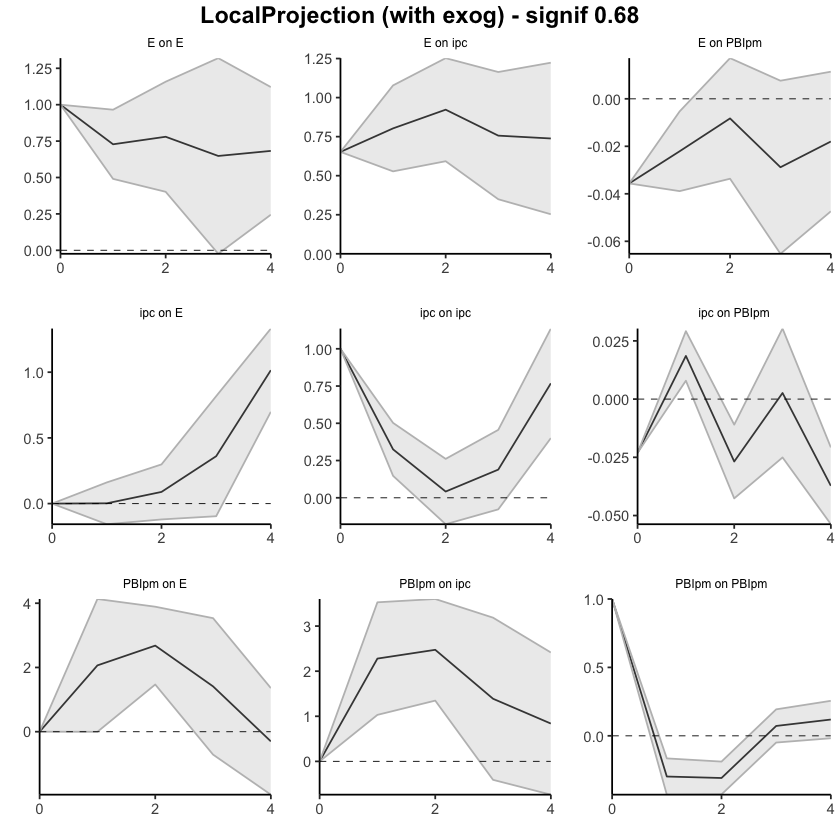

In [136]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.0000000,0.0000000
12,ipc,E,1,0.002036953,-0.1570458,0.1611197
13,ipc,E,2,0.090846279,-0.2776663,0.4593589
14,ipc,E,3,0.451508906,-0.3737624,1.2767802
15,ipc,E,4,1.466666612,0.3245115,2.6088217


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.000000000,0.000000
22,PBIpm,E,1,2.064475,-0.002948705,4.131898
23,PBIpm,E,2,4.744758,1.466072791,8.023442
24,PBIpm,E,3,6.155549,0.752574731,11.558524
25,PBIpm,E,4,5.853932,-1.207691977,12.915556


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6523217,0.6523217,0.6523217
2,E,ipc,1,1.4552551,1.1800570,1.7304531
3,E,ipc,2,2.3779383,1.7727194,2.9831573
4,E,ipc,3,3.1344241,2.1219453,4.1469028
5,E,ipc,4,3.8726784,2.3750061,5.3703506


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.000000,0.000000
27,PBIpm,ipc,1,2.279225,1.031185,3.527264
28,PBIpm,ipc,2,4.753294,2.378667,7.127920
29,PBIpm,ipc,3,6.141917,1.969534,10.314300
30,PBIpm,ipc,4,6.980148,1.231688,12.728607


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03563447,-0.03563447,-0.035634469
7,E,PBIpm,1,-0.05772599,-0.07450894,-0.040943039
8,E,PBIpm,2,-0.06598487,-0.10815952,-0.023810218
9,E,PBIpm,3,-0.09480481,-0.17342256,-0.016187068
10,E,PBIpm,4,-0.11277714,-0.22079346,-0.004760815


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.023071727,-0.02307173,-0.023071727
17,ipc,PBIpm,1,-0.004534396,-0.01517339,0.006104603
18,ipc,PBIpm,2,-0.031339466,-0.05780870,-0.004870235
19,ipc,PBIpm,3,-0.028721556,-0.08286644,0.025423331
20,ipc,PBIpm,4,-0.065958982,-0.13659649,0.004678521


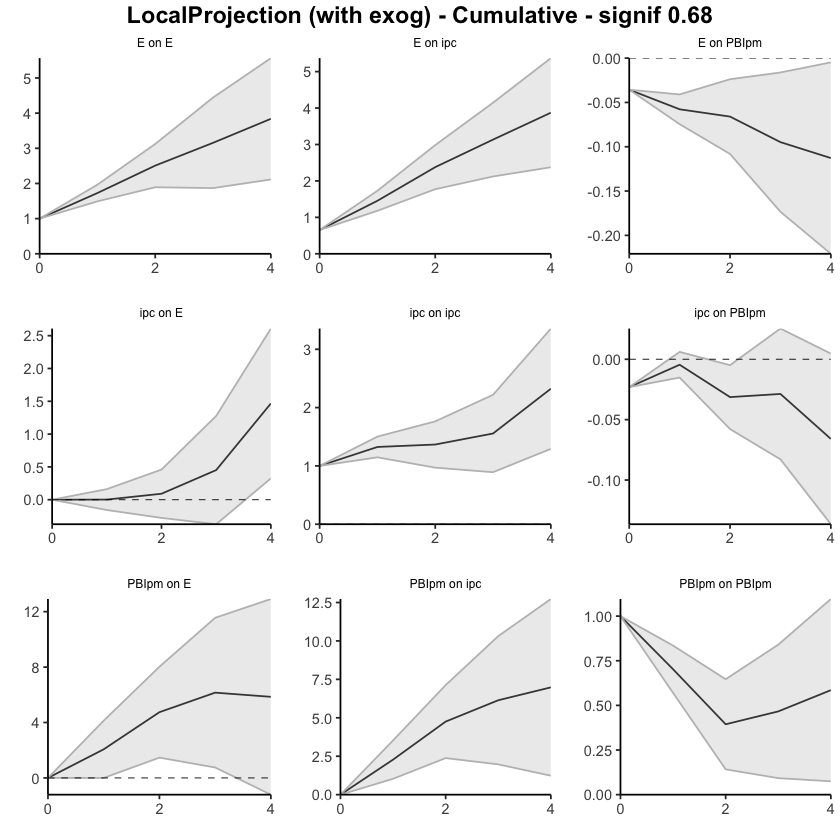

In [137]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,NA,NaN,NA,5,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,-0.4805955,-0.8308043,-0.1303867
13,ipc,E,2,-0.3791319,-0.6527481,-0.1055158
14,ipc,E,3,-1.2604571,-1.4873999,-1.0335143
15,ipc,E,4,-0.3757711,-0.6254785,-0.1260637


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,2.8121022,1.7660621,3.858142
23,PBIpm,E,2,2.0287856,1.0281270,3.029444
24,PBIpm,E,3,0.4682588,-0.8938062,1.830324
25,PBIpm,E,4,0.8013520,-0.5287641,2.131468


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.68601449,0.6860145,0.6860145
2,E,ipc,1,0.53511753,0.1963803,0.8738548
3,E,ipc,2,0.05462866,-0.5841399,0.6933972
4,E,ipc,3,-0.23458907,-0.7473849,0.2782067
5,E,ipc,4,0.32545692,-0.2272472,0.8781611


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,2.611541,1.5510116,3.672070
28,PBIpm,ipc,2,1.688527,0.3573924,3.019662
29,PBIpm,ipc,3,0.963982,-0.1362684,2.064232
30,PBIpm,ipc,4,1.820117,-1.8067099,5.446944


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.018640799,-0.01864080,-0.01864080
7,E,PBIpm,1,-0.009989670,-0.04803666,0.02805732
8,E,PBIpm,2,0.001978425,-0.04470925,0.04866609
9,E,PBIpm,3,-0.017193631,-0.05612921,0.02174195
10,E,PBIpm,4,-0.010675477,-0.08943942,0.06808846


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.06504007,-0.06504007,-0.0650400676
17,ipc,PBIpm,1,0.07518044,0.05758951,0.0927713736
18,ipc,PBIpm,2,-0.01958699,-0.03988913,0.0007151502
19,ipc,PBIpm,3,0.03720366,0.01653330,0.0578740247
20,ipc,PBIpm,4,0.02515536,-0.02004601,0.0703567410


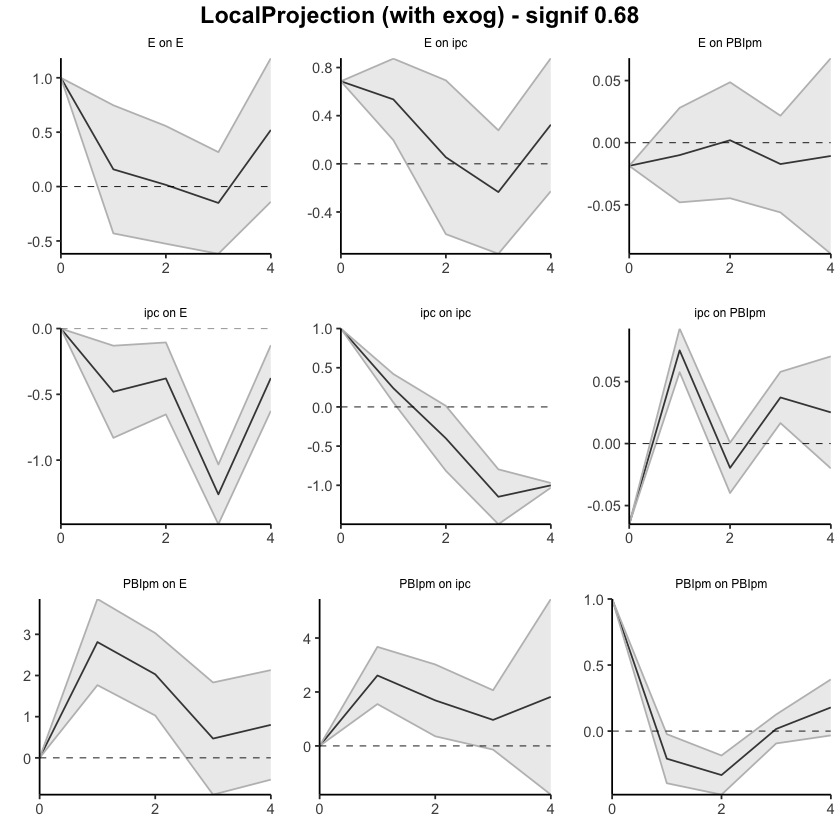

In [138]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 5, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,NA,NaN,NA,5,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,-0.4805955,-0.8308043,-0.1303867
13,ipc,E,2,-0.8597275,-1.4835524,-0.2359026
14,ipc,E,3,-2.1201845,-2.9709522,-1.2694168
15,ipc,E,4,-2.4959556,-3.5964307,-1.3954805


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.000000,0.000000
22,PBIpm,E,1,2.812102,1.766062,3.858142
23,PBIpm,E,2,4.840888,2.794189,6.887587
24,PBIpm,E,3,5.309147,1.900383,8.717911
25,PBIpm,E,4,6.110499,1.371619,10.849379


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6860145,0.6860145,0.6860145
2,E,ipc,1,1.2211320,0.8823948,1.5598692
3,E,ipc,2,1.2757607,0.2982549,2.2532664
4,E,ipc,3,1.0411716,-0.4491300,2.5314732
5,E,ipc,4,1.3666285,-0.6763772,3.4096342


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.00000000,0.000000
27,PBIpm,ipc,1,2.611541,1.55101158,3.672070
28,PBIpm,ipc,2,4.300068,1.90840396,6.691732
29,PBIpm,ipc,3,5.264050,1.77213561,8.755964
30,PBIpm,ipc,4,7.084167,-0.03457428,14.202909


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01864080,-0.01864080,-0.018640799
7,E,PBIpm,1,-0.02863047,-0.06667746,0.009416522
8,E,PBIpm,2,-0.02665204,-0.11138671,0.058082617
9,E,PBIpm,3,-0.04384568,-0.16751592,0.079824564
10,E,PBIpm,4,-0.05452115,-0.25695533,0.147913028


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.065040068,-0.065040068,-0.06504007
17,ipc,PBIpm,1,0.010140376,-0.007450554,0.02773131
18,ipc,PBIpm,2,-0.009446615,-0.047339686,0.02844646
19,ipc,PBIpm,3,0.027757048,-0.030806385,0.08632048
20,ipc,PBIpm,4,0.052912413,-0.050852396,0.15667722


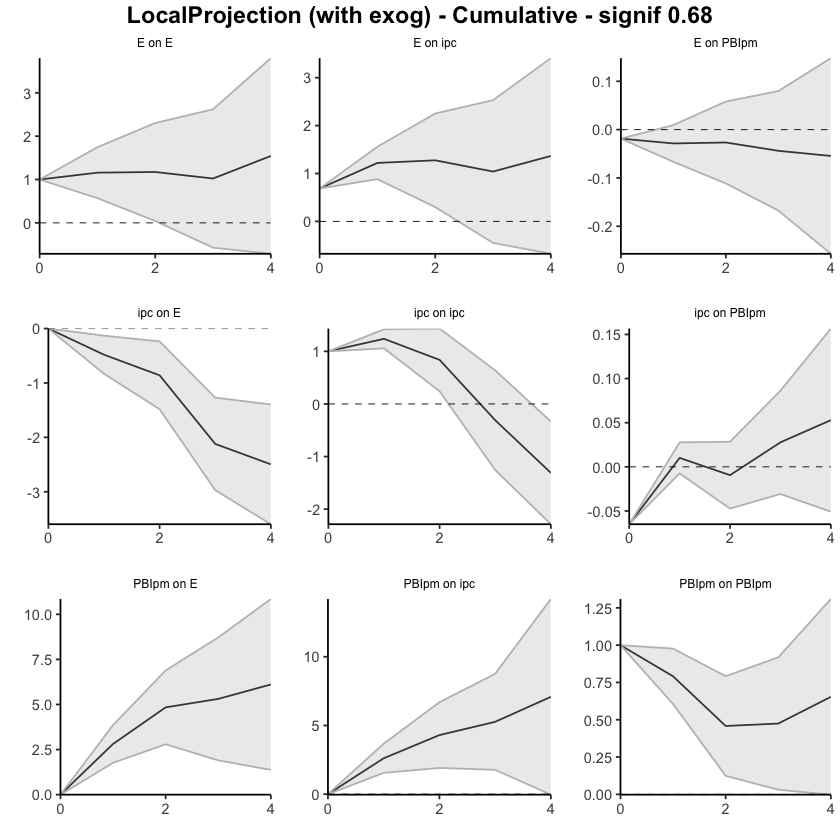

In [139]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 5, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

### 1950-2023. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.08675448,-0.3744059,0.2008969
38,ipc,E,2,-0.10945318,-0.4222591,0.2033527
39,ipc,E,3,0.06397946,-0.3651548,0.4931137
40,ipc,E,4,0.40688445,-0.1103343,0.9241032


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,0.5177239,-0.5384533,1.573901
53,PBIpm,E,2,0.6910942,-0.5070432,1.889232
54,PBIpm,E,3,-0.2824582,-1.8930425,1.328126
55,PBIpm,E,4,-1.2187810,-2.5145031,0.076941


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.6679555,-0.6679555410,-0.66795554
2,Psoja_USA,E,1,0.3492005,0.0005438318,0.69785718
3,Psoja_USA,E,2,0.6613715,0.4001611240,0.92258190
4,Psoja_USA,E,3,-0.3501794,-0.7241850639,0.02382636
5,Psoja_USA,E,4,-0.6971471,-1.0119393856,-0.38235475


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.086117785,0.08611778,0.08611778
12,Psoja_USA,PBIpm,1,-0.002200056,-0.03590889,0.03150878
13,Psoja_USA,PBIpm,2,-0.043625692,-0.06539528,-0.02185610
14,Psoja_USA,PBIpm,3,0.088587243,0.05407583,0.12309866
15,Psoja_USA,PBIpm,4,0.088549731,0.06345331,0.11364615


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.00000000,0.00000000
17,E,Psoja_USA,1,0.01806416,-0.06484280,0.10097112
18,E,Psoja_USA,2,0.01164651,-0.06525671,0.08854973
19,E,Psoja_USA,3,-0.04715779,-0.13690584,0.04259026
20,E,Psoja_USA,4,-0.03453585,-0.10118871,0.03211701


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Psoja_USA,1,-0.11426041,-0.17783770,-0.05068313
33,ipc,Psoja_USA,2,-0.07722987,-0.13837144,-0.01608829
34,ipc,Psoja_USA,3,0.08022187,0.01483501,0.14560874
35,ipc,Psoja_USA,4,0.06382888,0.01185927,0.11579849


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.0000000,0.00000000,0.00000000
47,PBIpm,Psoja_USA,1,0.1168424,-0.26336818,0.49705295
48,PBIpm,Psoja_USA,2,-0.4111312,-0.84871329,0.02645082
49,PBIpm,Psoja_USA,3,0.1453653,-0.35408993,0.64482047
50,PBIpm,Psoja_USA,4,0.4740066,0.04422292,0.90379020


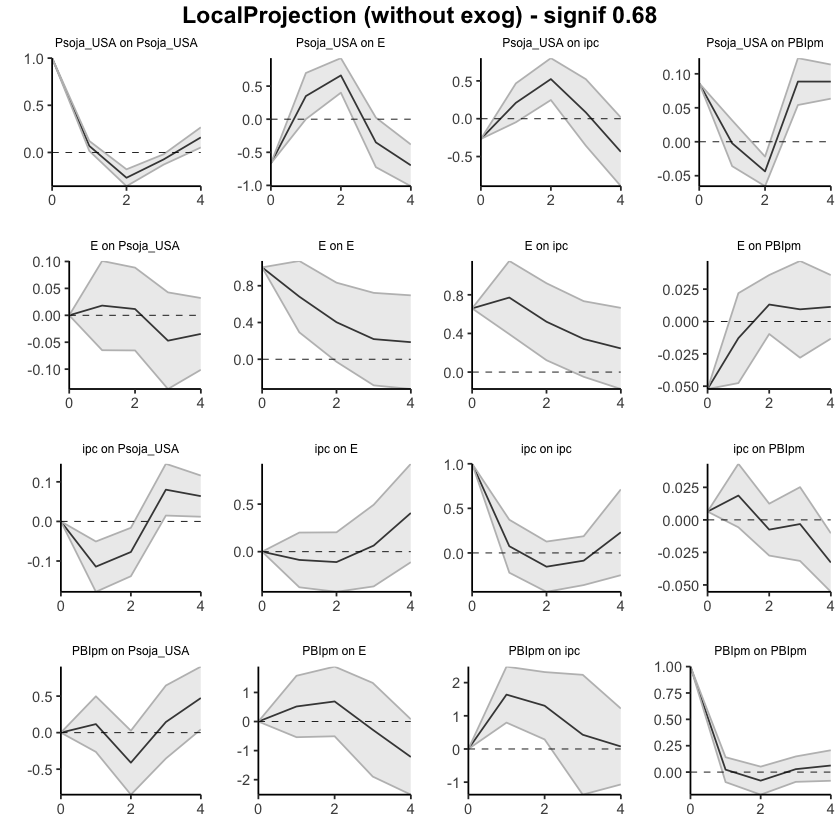

In [21]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"Psoja_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.08675448,-0.3744059,0.2008969
38,ipc,E,2,-0.19620766,-0.7966649,0.4042496
39,ipc,E,3,-0.13222820,-1.1618197,0.8973633
40,ipc,E,4,0.27465625,-1.2721540,1.8214665


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,0.5177239,-0.5384533,1.573901
53,PBIpm,E,2,1.2088181,-1.0454965,3.463133
54,PBIpm,E,3,0.9263599,-2.9385390,4.791259
55,PBIpm,E,4,-0.2924211,-5.4530420,4.868200


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.667955541,-0.6679555,-0.66795554
2,Psoja_USA,E,1,-0.318755037,-0.6674117,0.02990163
3,Psoja_USA,E,2,0.342616472,-0.2672506,0.95248353
4,Psoja_USA,E,3,-0.007562879,-0.9914356,0.97630989
5,Psoja_USA,E,4,-0.704709949,-2.0033750,0.59395514


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIpm,0,0.08611778,0.08611778,0.08611778
12,Psoja_USA,PBIpm,1,0.08391773,0.05020890,0.11762656
13,Psoja_USA,PBIpm,2,0.04029204,-0.01518638,0.09577046
14,Psoja_USA,PBIpm,3,0.12887928,0.03888944,0.21886912
15,Psoja_USA,PBIpm,4,0.21742901,0.10234275,0.33251527


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.0000000,0.0000000
17,E,Psoja_USA,1,0.01806416,-0.0648428,0.1009711
18,E,Psoja_USA,2,0.02971067,-0.1300995,0.1895209
19,E,Psoja_USA,3,-0.01744711,-0.2670053,0.2321111
20,E,Psoja_USA,4,-0.05198297,-0.3681941,0.2642281


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Psoja_USA,1,-0.11426041,-0.1778377,-0.05068313
33,ipc,Psoja_USA,2,-0.19149028,-0.3162091,-0.06677141
34,ipc,Psoja_USA,3,-0.11126841,-0.3013741,0.07883733
35,ipc,Psoja_USA,4,-0.04743952,-0.2895149,0.19463582


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Psoja_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Psoja_USA,1,0.1168424,-0.2633682,0.4970529
48,PBIpm,Psoja_USA,2,-0.2942888,-1.1120815,0.5235038
49,PBIpm,Psoja_USA,3,-0.1489236,-1.4661714,1.1683242
50,PBIpm,Psoja_USA,4,0.3250830,-1.4219485,2.0721144


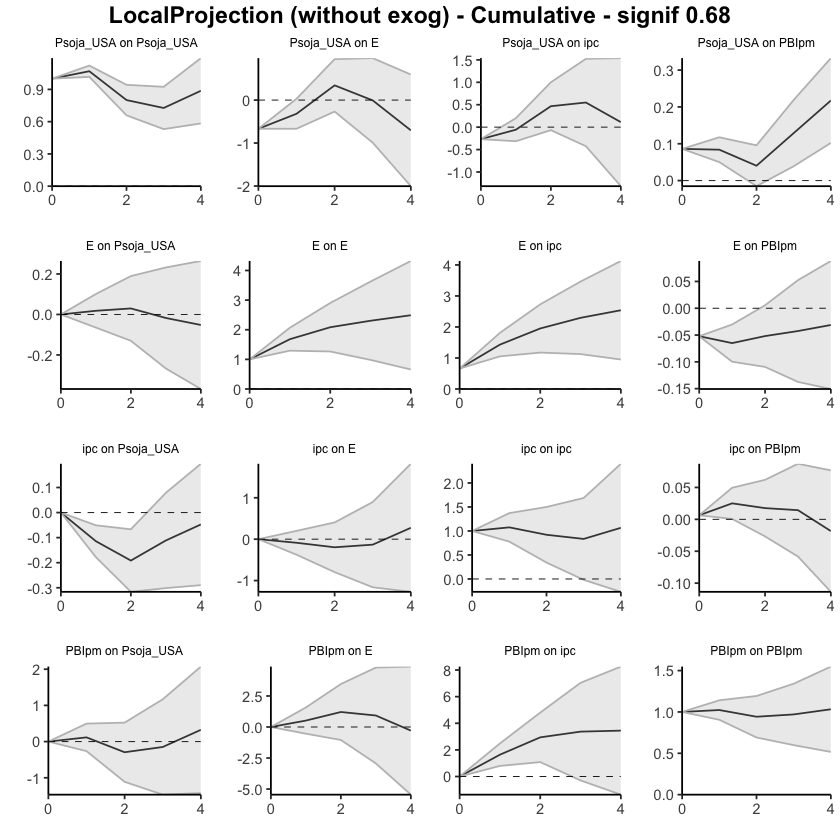

In [20]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative = TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.06102858,-0.3351961,0.2131390
38,ipc,E,2,-0.06623641,-0.3648596,0.2323868
39,ipc,E,3,0.06890396,-0.3416807,0.4794887
40,ipc,E,4,0.38082058,-0.1961532,0.9577944


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.00000000
52,PBIpm,E,1,0.4563889,-0.5472815,1.46005930
53,PBIpm,E,2,0.9383736,-0.4608471,2.33759432
54,PBIpm,E,3,-0.1530850,-1.9078915,1.60172153
55,PBIpm,E,4,-1.2916984,-2.6170597,0.03366286


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.1789687,-0.1789687,-0.1789687
2,Pmaíz_USA,E,1,0.7830944,0.4163068,1.1498819
3,Pmaíz_USA,E,2,0.4476197,-0.1037226,0.9989620
4,Pmaíz_USA,E,3,-0.6374076,-1.5138122,0.2389970
5,Pmaíz_USA,E,4,-0.6771088,-1.2824609,-0.0717567


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.05886409,0.05886409,0.0588640916
12,Pmaíz_USA,PBIpm,1,-0.03236741,-0.06565549,0.0009206675
13,Pmaíz_USA,PBIpm,2,-0.01157243,-0.04444849,0.0213036266
14,Pmaíz_USA,PBIpm,3,0.08481429,0.04480919,0.1248193883
15,Pmaíz_USA,PBIpm,4,0.06262664,0.02328254,0.1019707386


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.000000000,0.00000000,0.00000000
17,E,Pmaíz_USA,1,-0.004920013,-0.09522778,0.08538775
18,E,Pmaíz_USA,2,-0.012266459,-0.10807657,0.08354365
19,E,Pmaíz_USA,3,-0.047367579,-0.12729461,0.03255945
20,E,Pmaíz_USA,4,-0.030801706,-0.12930408,0.06770067


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.000000000,0.000000000
32,ipc,Pmaíz_USA,1,-0.06834035,-0.139857218,0.003176521
33,ipc,Pmaíz_USA,2,-0.06188683,-0.137083724,0.013310063
34,ipc,Pmaíz_USA,3,0.10097921,0.039890938,0.162067483
35,ipc,Pmaíz_USA,4,0.06301835,-0.006403298,0.132440003


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Pmaíz_USA,1,0.03503379,-0.3569570,0.4270246
48,PBIpm,Pmaíz_USA,2,-0.10738034,-0.5723178,0.3575572
49,PBIpm,Pmaíz_USA,3,-0.25124901,-0.7162348,0.2137367
50,PBIpm,Pmaíz_USA,4,0.58970121,0.1827503,0.9966521


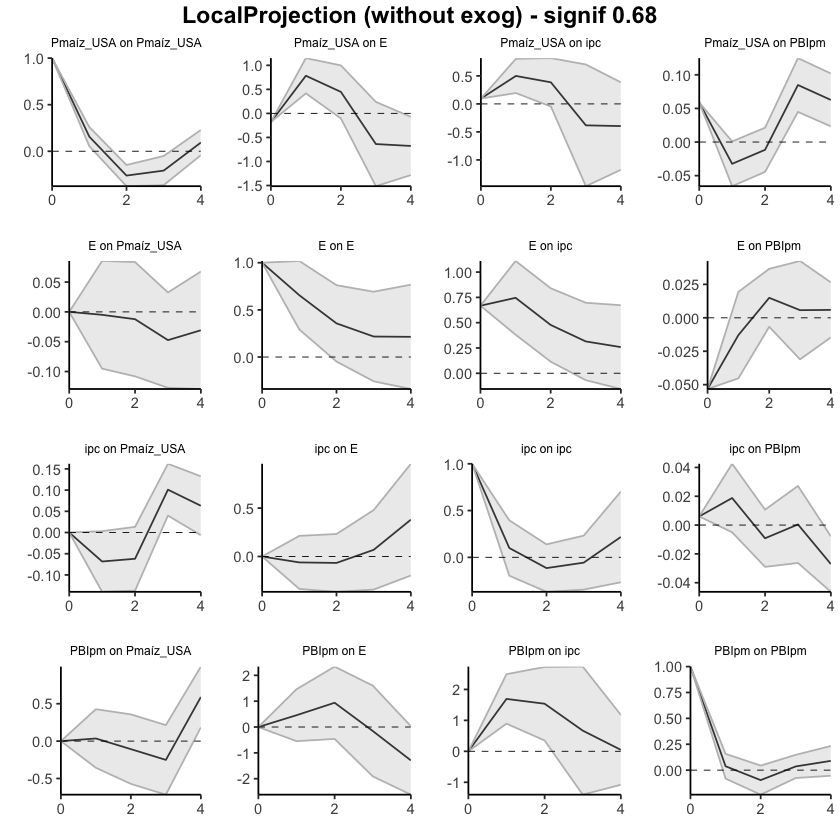

In [19]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.06102858,-0.3351961,0.2131390
38,ipc,E,2,-0.12726499,-0.7000557,0.4455257
39,ipc,E,3,-0.05836102,-1.0417364,0.9250144
40,ipc,E,4,0.32245956,-1.2378897,1.8828088


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.00000000,0.0000000,0.000000
52,PBIpm,E,1,0.45638890,-0.5472815,1.460059
53,PBIpm,E,2,1.39476249,-1.0081286,3.797654
54,PBIpm,E,3,1.24167750,-2.9160202,5.399375
55,PBIpm,E,4,-0.05002092,-5.5330798,5.433038


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.1789687,-0.1789687,-0.1789687
2,Pmaíz_USA,E,1,0.6041257,0.2373381,0.9709132
3,Pmaíz_USA,E,2,1.0517454,0.1336155,1.9698753
4,Pmaíz_USA,E,3,0.4143378,-1.3801967,2.2088723
5,Pmaíz_USA,E,4,-0.2627710,-2.6626575,2.1371156


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.05886409,0.058864092,0.05886409
12,Pmaíz_USA,PBIpm,1,0.02649668,-0.006791393,0.05978476
13,Pmaíz_USA,PBIpm,2,0.01492425,-0.051239885,0.08108839
14,Pmaíz_USA,PBIpm,3,0.09973854,-0.006430690,0.20590777
15,Pmaíz_USA,PBIpm,4,0.16236518,0.016851852,0.30787851


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.000000000,0.00000000,0.00000000
17,E,Pmaíz_USA,1,-0.004920013,-0.09522778,0.08538775
18,E,Pmaíz_USA,2,-0.017186472,-0.20330434,0.16893140
19,E,Pmaíz_USA,3,-0.064554051,-0.33059895,0.20149085
20,E,Pmaíz_USA,4,-0.095355756,-0.45990303,0.26919152


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.0000000,0.000000000
32,ipc,Pmaíz_USA,1,-0.06834035,-0.1398572,0.003176521
33,ipc,Pmaíz_USA,2,-0.13022718,-0.2769409,0.016486583
34,ipc,Pmaíz_USA,3,-0.02924797,-0.2370500,0.178554066
35,ipc,Pmaíz_USA,4,0.03377038,-0.2434533,0.310994069


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Pmaíz_USA,1,0.03503379,-0.3569570,0.4270246
48,PBIpm,Pmaíz_USA,2,-0.07234656,-0.9292748,0.7845817
49,PBIpm,Pmaíz_USA,3,-0.32359556,-1.6455096,0.9983185
50,PBIpm,Pmaíz_USA,4,0.26610564,-1.4627593,1.9949706


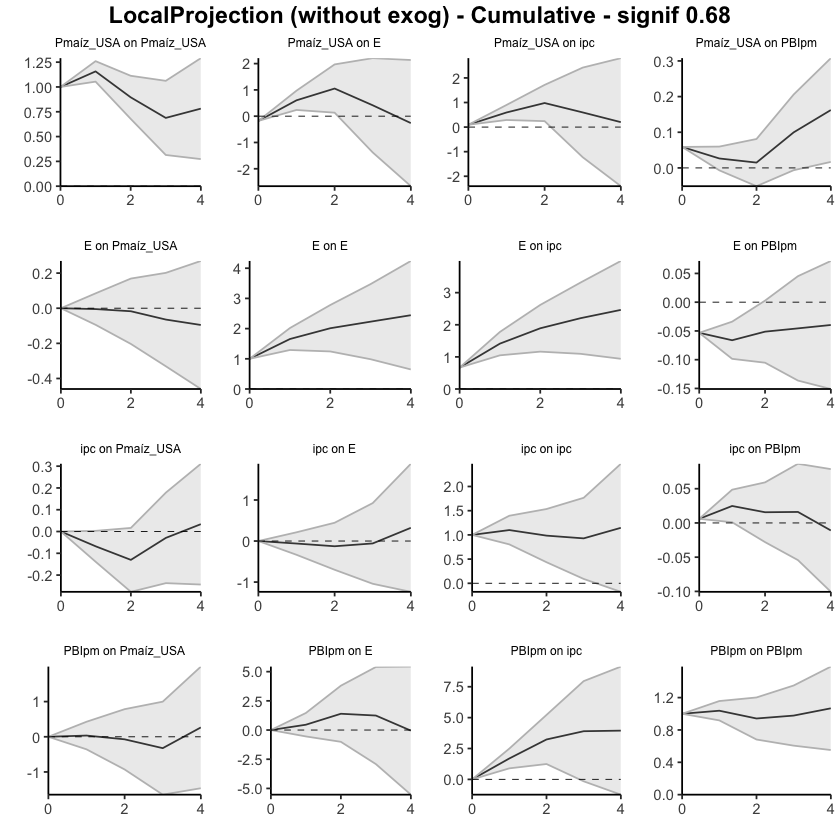

In [18]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative = TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,0.05207685,-0.3464065,0.4505602
38,ipc,E,2,-0.31577480,-0.7837435,0.1521939
39,ipc,E,3,-0.74981178,-1.3227279,-0.1768957
40,ipc,E,4,-0.24756557,-0.7059254,0.2107943


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.0000000
52,PBIpm,E,1,0.5919727,-0.5008107,1.6847562
53,PBIpm,E,2,0.6364578,-0.6764695,1.9493851
54,PBIpm,E,3,-1.0402915,-2.3869692,0.3063861
55,PBIpm,E,4,-2.2010694,-3.8746227,-0.5275160


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.2738727,-0.2738727,-0.2738727
2,Pmaíz_USA,E,1,0.7543599,0.3085282,1.2001916
3,Pmaíz_USA,E,2,0.6151771,0.2079850,1.0223691
4,Pmaíz_USA,E,3,-0.3869980,-0.8952403,0.1212443
5,Pmaíz_USA,E,4,-0.6035677,-0.9604374,-0.2466981


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.06724556,0.06724556,0.067245563
12,Pmaíz_USA,PBIpm,1,-0.03074027,-0.06005166,-0.001428885
13,Pmaíz_USA,PBIpm,2,-0.01662170,-0.04793277,0.014689372
14,Pmaíz_USA,PBIpm,3,0.07215112,0.03853082,0.105771417
15,Pmaíz_USA,PBIpm,4,0.06928407,0.03207114,0.106497008


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.000000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,0.023709822,-0.0913570,0.13877664
18,E,Pmaíz_USA,2,0.009663646,-0.1202291,0.13955644
19,E,Pmaíz_USA,3,-0.053679407,-0.1497666,0.04240778
20,E,Pmaíz_USA,4,-0.041890218,-0.1966901,0.11290964


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.000000000,0.000000000
32,ipc,Pmaíz_USA,1,-0.07497176,-0.193977374,0.044033855
33,ipc,Pmaíz_USA,2,-0.12360298,-0.256297994,0.009092033
34,ipc,Pmaíz_USA,3,0.09356365,-0.002322932,0.189450224
35,ipc,Pmaíz_USA,4,0.06943915,-0.072585340,0.211463639


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Pmaíz_USA,1,0.0782625,-0.3139092,0.4704342
48,PBIpm,Pmaíz_USA,2,-0.1850394,-0.7145093,0.3444304
49,PBIpm,Pmaíz_USA,3,-0.3057702,-0.7976940,0.1861537
50,PBIpm,Pmaíz_USA,4,0.5618883,0.1724541,0.9513226


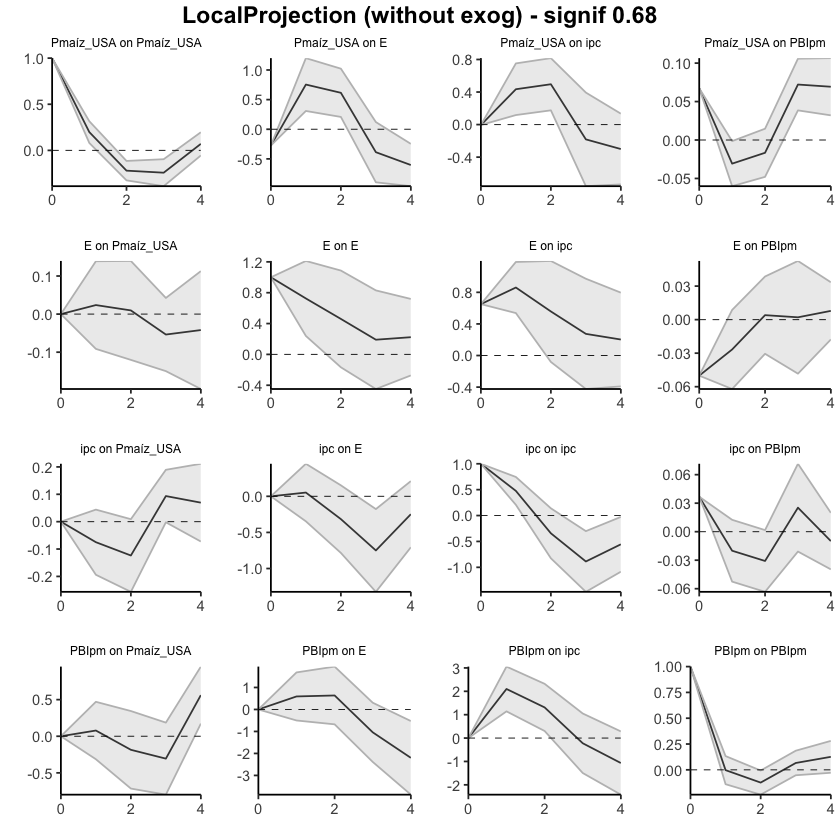

In [17]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"Pmaíz_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,0.05207685,-0.3464065,0.4505602
38,ipc,E,2,-0.26369795,-1.1301500,0.6027541
39,ipc,E,3,-1.01350973,-2.4528779,0.4258585
40,ipc,E,4,-1.26107530,-3.1588034,0.6366528


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,0.5919727,-0.5008107,1.684756
53,PBIpm,E,2,1.2284305,-1.1772802,3.634141
54,PBIpm,E,3,0.1881390,-3.5642494,3.940527
55,PBIpm,E,4,-2.0129304,-7.4388722,3.413011


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.2738727,-0.27387270,-0.2738727
2,Pmaíz_USA,E,1,0.4804872,0.03465553,0.9263189
3,Pmaíz_USA,E,2,1.0956643,0.24264055,1.9486881
4,Pmaíz_USA,E,3,0.7086663,-0.65259977,2.0699324
5,Pmaíz_USA,E,4,0.1050986,-1.61303713,1.8232343


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIpm,0,0.06724556,0.067245563,0.06724556
12,Pmaíz_USA,PBIpm,1,0.03650529,0.007193900,0.06581668
13,Pmaíz_USA,PBIpm,2,0.01988359,-0.040738872,0.08050605
14,Pmaíz_USA,PBIpm,3,0.09203471,-0.002208047,0.18627747
15,Pmaíz_USA,PBIpm,4,0.16131878,0.029863090,0.29277447


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,0.02370982,-0.0913570,0.1387766
18,E,Pmaíz_USA,2,0.03337347,-0.2115861,0.2783331
19,E,Pmaíz_USA,3,-0.02030594,-0.3613527,0.3207409
20,E,Pmaíz_USA,4,-0.06219616,-0.5580428,0.4336505


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Pmaíz_USA,1,-0.07497176,-0.1939774,0.04403386
33,ipc,Pmaíz_USA,2,-0.19857474,-0.4502754,0.05312589
34,ipc,Pmaíz_USA,3,-0.10501109,-0.4525983,0.24257611
35,ipc,Pmaíz_USA,4,-0.03557194,-0.5251836,0.45403975


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Pmaíz_USA,1,0.0782625,-0.3139092,0.4704342
48,PBIpm,Pmaíz_USA,2,-0.1067769,-1.0284185,0.8148646
49,PBIpm,Pmaíz_USA,3,-0.4125471,-1.8261124,1.0010183
50,PBIpm,Pmaíz_USA,4,0.1493413,-1.6536584,1.9523409


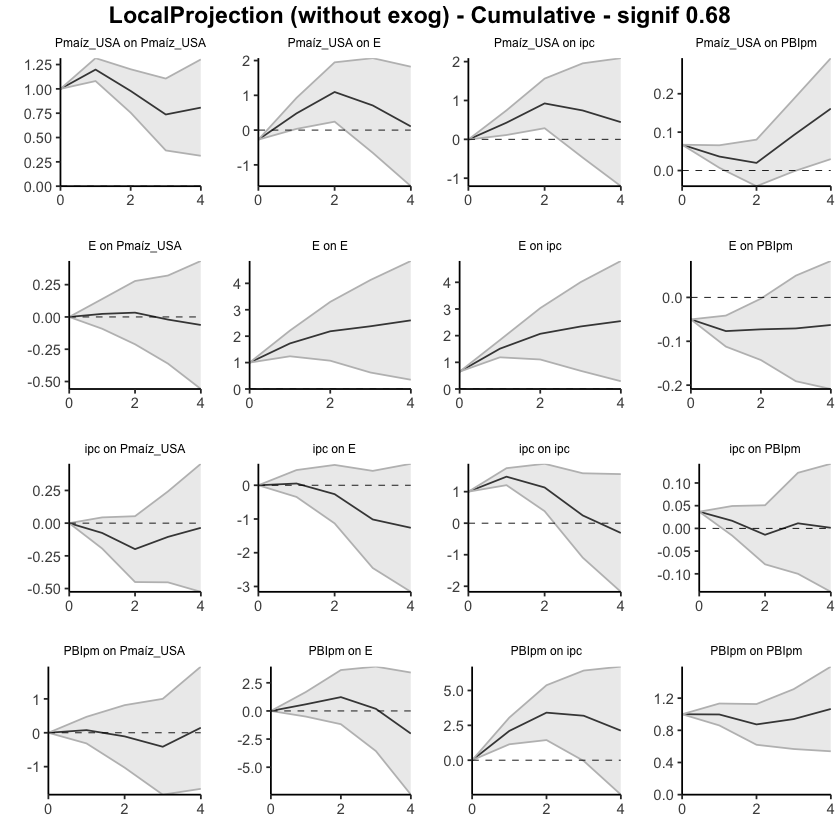

In [16]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10, cumulative = TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.02024521,-0.2892226,0.2487322
38,ipc,E,2,-0.03075559,-0.2983809,0.2368697
39,ipc,E,3,0.05022724,-0.3756217,0.4760762
40,ipc,E,4,0.34882850,-0.2889277,0.9865846


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.0000000
52,PBIpm,E,1,0.7790659,-0.2645887,1.8227205
53,PBIpm,E,2,1.0287056,-0.2706608,2.3280720
54,PBIpm,E,3,-0.3668894,-1.9503642,1.2165854
55,PBIpm,E,4,-1.4849358,-2.8551250,-0.1147465


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.11720845,-0.1172084,-0.1172084
2,Ptrigo_USA,E,1,0.62637021,0.3238228,0.9289176
3,Ptrigo_USA,E,2,0.73988252,0.3215506,1.1582145
4,Ptrigo_USA,E,3,0.05551588,-0.5529737,0.6640055
5,Ptrigo_USA,E,4,-0.29527617,-0.7207011,0.1301488


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.03537250,0.03537250,0.035372496
12,Ptrigo_USA,PBIpm,1,-0.02699965,-0.06383434,0.009835041
13,Ptrigo_USA,PBIpm,2,-0.02308789,-0.04992086,0.003745072
14,Ptrigo_USA,PBIpm,3,0.05577135,0.01905973,0.092482967
15,Ptrigo_USA,PBIpm,4,0.07536589,0.03306604,0.117665741


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.000000000,0.00000000,0.00000000
17,E,Ptrigo_USA,1,-0.041788157,-0.13953071,0.05595440
18,E,Ptrigo_USA,2,-0.027876343,-0.15816574,0.10241306
19,E,Ptrigo_USA,3,-0.005069121,-0.09831687,0.08817863
20,E,Ptrigo_USA,4,0.013508837,-0.08580951,0.11282718


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.02038077,-0.09101120,0.05024967
33,ipc,Ptrigo_USA,2,0.02481088,-0.07835064,0.12797240
34,ipc,Ptrigo_USA,3,0.04644232,-0.02382077,0.11670541
35,ipc,Ptrigo_USA,4,-0.01052572,-0.08698520,0.06593376


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,0.23948302,-0.1081109,0.5870769
48,PBIpm,Ptrigo_USA,2,-0.17565265,-0.6903422,0.3390369
49,PBIpm,Ptrigo_USA,3,0.02742606,-0.4133677,0.4682198
50,PBIpm,Ptrigo_USA,4,0.27161647,-0.1958183,0.7390513


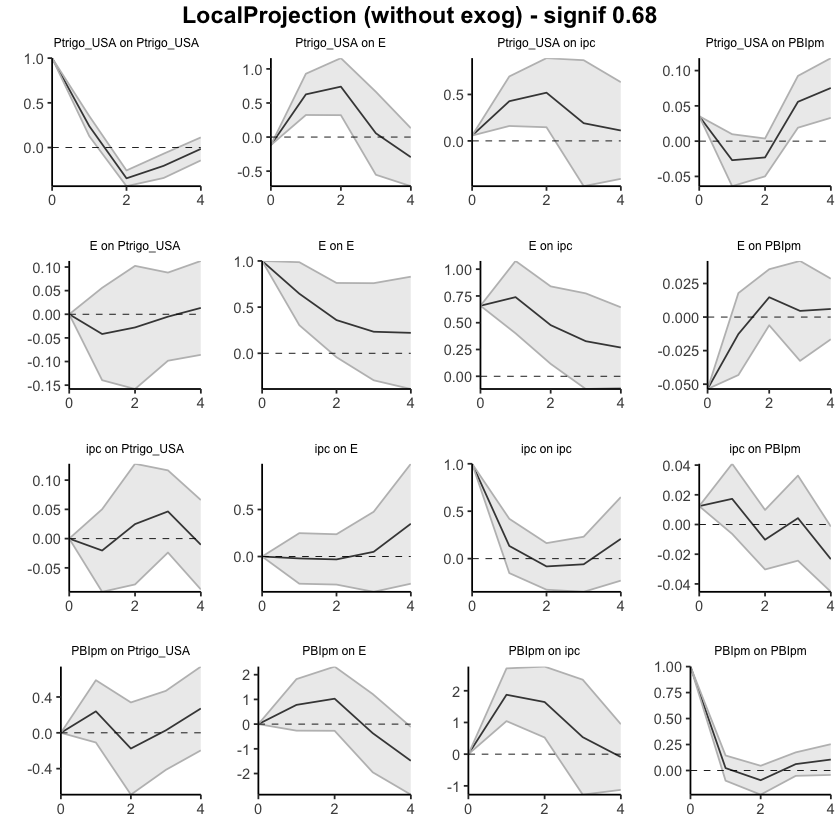

In [15]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000000,0.0000000,0.0000000
37,ipc,E,1,-0.0202452085,-0.2892226,0.2487322
38,ipc,E,2,-0.0510007944,-0.5876035,0.4856019
39,ipc,E,3,-0.0007735573,-0.9632252,0.9616781
40,ipc,E,4,0.3480549386,-1.2521528,1.9482627


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.00000000,0.0000000,0.000000
52,PBIpm,E,1,0.77906589,-0.2645887,1.822720
53,PBIpm,E,2,1.80777149,-0.5352495,4.150792
54,PBIpm,E,3,1.44088211,-2.4856137,5.367378
55,PBIpm,E,4,-0.04405365,-5.3407386,5.252631


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.1172084,-0.11720845,-0.1172084
2,Ptrigo_USA,E,1,0.5091618,0.20661434,0.8117092
3,Ptrigo_USA,E,2,1.2490443,0.52816492,1.9699236
4,Ptrigo_USA,E,3,1.3045602,-0.02480879,2.6339291
5,Ptrigo_USA,E,4,1.0092840,-0.74550992,2.7640779


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.035372496,0.03537250,0.03537250
12,Ptrigo_USA,PBIpm,1,0.008372844,-0.02846185,0.04520754
13,Ptrigo_USA,PBIpm,2,-0.014715050,-0.07838271,0.04895261
14,Ptrigo_USA,PBIpm,3,0.041056297,-0.05932298,0.14143557
15,Ptrigo_USA,PBIpm,4,0.116422186,-0.02625694,0.25910132


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,-0.04178816,-0.1395307,0.0559544
18,E,Ptrigo_USA,2,-0.06966450,-0.2976965,0.1583675
19,E,Ptrigo_USA,3,-0.07473362,-0.3960133,0.2465461
20,E,Ptrigo_USA,4,-0.06122478,-0.4818228,0.3593733


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.000000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.020380768,-0.0910112,0.05024967
33,ipc,Ptrigo_USA,2,0.004430111,-0.1693618,0.17822206
34,ipc,Ptrigo_USA,3,0.050872431,-0.1931826,0.29492747
35,ipc,Ptrigo_USA,4,0.040346708,-0.2801678,0.36086123


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,0.23948302,-0.1081109,0.5870769
48,PBIpm,Ptrigo_USA,2,0.06383037,-0.7984531,0.9261139
49,PBIpm,Ptrigo_USA,3,0.09125643,-1.2118208,1.3943337
50,PBIpm,Ptrigo_USA,4,0.36287291,-1.4076392,2.1333850


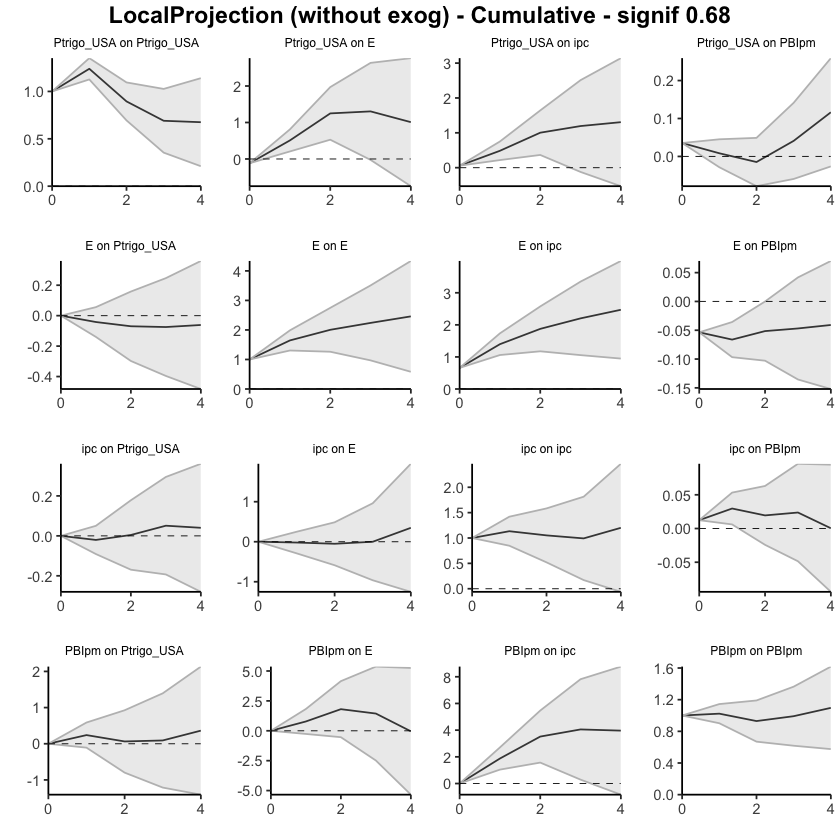

In [14]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative = TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,0.1975749,-0.1769721,0.5721219
38,ipc,E,2,-0.1995207,-0.6456085,0.2465672
39,ipc,E,3,-0.8018145,-1.4726870,-0.1309420
40,ipc,E,4,-0.3026644,-0.8629718,0.2576431


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000000
52,PBIpm,E,1,0.9682554,-0.09595909,2.032469941
53,PBIpm,E,2,0.7829919,-0.32471963,1.890703423
54,PBIpm,E,3,-1.2417650,-2.47372323,-0.009806762
55,PBIpm,E,4,-2.4370890,-4.22697581,-0.647202157


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.005891182,-0.005891182,-0.005891182
2,Ptrigo_USA,E,1,0.624206461,0.169627208,1.078785714
3,Ptrigo_USA,E,2,0.901530085,0.446902361,1.356157808
4,Ptrigo_USA,E,3,0.324699926,-0.284589615,0.933989468
5,Ptrigo_USA,E,4,-0.251895721,-0.713672124,0.209880682


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.02974602,0.029746024,0.029746024
12,Ptrigo_USA,PBIpm,1,-0.01957779,-0.063940797,0.024785215
13,Ptrigo_USA,PBIpm,2,-0.03400802,-0.066350623,-0.001665426
14,Ptrigo_USA,PBIpm,3,0.03834612,-0.008301744,0.084993991
15,Ptrigo_USA,PBIpm,4,0.08919364,0.034831420,0.143555865


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.0000000000,0.0000000,0.00000000
17,E,Ptrigo_USA,1,-0.0313839550,-0.1383887,0.07562077
18,E,Ptrigo_USA,2,-0.0268758713,-0.1813036,0.12755184
19,E,Ptrigo_USA,3,0.0004934433,-0.0887421,0.08972899
20,E,Ptrigo_USA,4,0.0172697743,-0.1208961,0.15543564


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.000000000,0.000000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.153347810,-0.253728636,-0.05296698
33,ipc,Ptrigo_USA,2,-0.057343291,-0.207716495,0.09302991
34,ipc,Ptrigo_USA,3,0.079945011,-0.005879204,0.16576923
35,ipc,Ptrigo_USA,4,-0.000951361,-0.138983263,0.13708054


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,0.1188082,-0.2001793,0.4377957
48,PBIpm,Ptrigo_USA,2,-0.2510490,-0.8047945,0.3026966
49,PBIpm,Ptrigo_USA,3,0.0516374,-0.3764368,0.4797116
50,PBIpm,Ptrigo_USA,4,0.2785433,-0.1608765,0.7179632


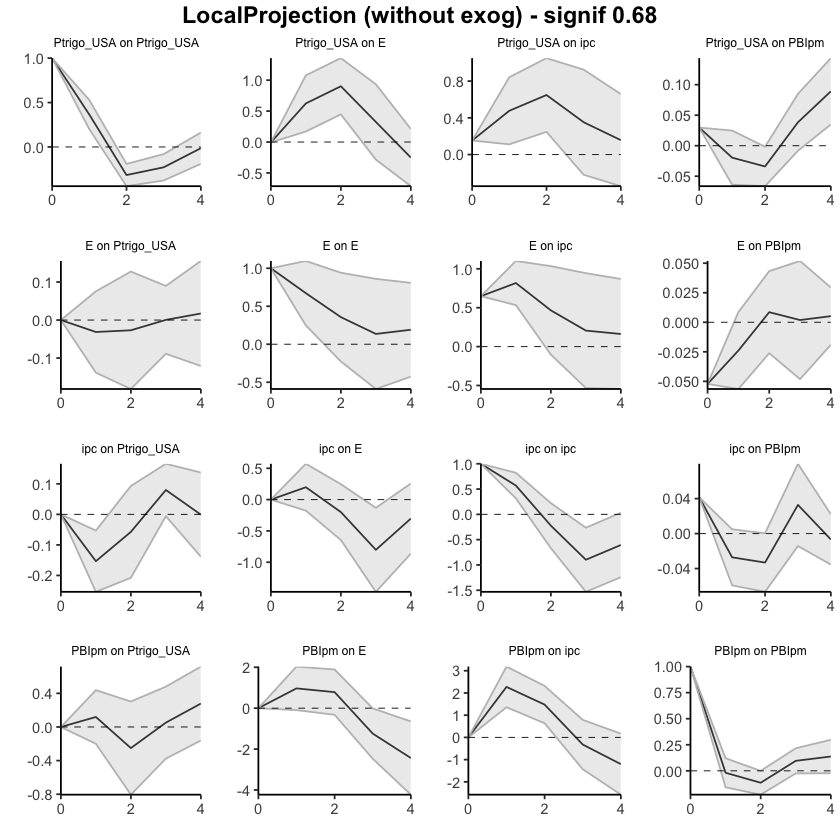

In [13]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"Ptrigo_USA, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.000000000,0.0000000,0.0000000
37,ipc,E,1,0.197574908,-0.1769721,0.5721219
38,ipc,E,2,-0.001945762,-0.8225806,0.8186891
39,ipc,E,3,-0.803760299,-2.2952676,0.6877470
40,ipc,E,4,-1.106424670,-3.1582395,0.9453901


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000
52,PBIpm,E,1,0.9682554,-0.09595909,2.032470
53,PBIpm,E,2,1.7512473,-0.42067872,3.923173
54,PBIpm,E,3,0.5094823,-2.89440195,3.913367
55,PBIpm,E,4,-1.9276067,-7.12137776,3.266164


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.005891182,-0.005891182,-0.005891182
2,Ptrigo_USA,E,1,0.618315279,0.163736026,1.072894532
3,Ptrigo_USA,E,2,1.519845363,0.610638386,2.429052340
4,Ptrigo_USA,E,3,1.844545290,0.326048771,3.363041808
5,Ptrigo_USA,E,4,1.592649568,-0.387623353,3.572922490


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIpm,0,0.02974602,0.02974602,0.02974602
12,Ptrigo_USA,PBIpm,1,0.01016823,-0.03419477,0.05453124
13,Ptrigo_USA,PBIpm,2,-0.02383979,-0.10054540,0.05286581
14,Ptrigo_USA,PBIpm,3,0.01450633,-0.10884714,0.13785980
15,Ptrigo_USA,PBIpm,4,0.10369997,-0.07401572,0.28141567


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
17,E,Ptrigo_USA,1,-0.03138395,-0.1383887,0.07562077
18,E,Ptrigo_USA,2,-0.05825983,-0.3196923,0.20317262
19,E,Ptrigo_USA,3,-0.05776638,-0.4084344,0.29290160
20,E,Ptrigo_USA,4,-0.04049661,-0.5293305,0.44833725


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.0000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.1533478,-0.2537286,-0.05296698
33,ipc,Ptrigo_USA,2,-0.2106911,-0.4614451,0.04006293
34,ipc,Ptrigo_USA,3,-0.1307461,-0.4673243,0.20583216
35,ipc,Ptrigo_USA,4,-0.1316975,-0.6063076,0.34291270


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIpm,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIpm,Ptrigo_USA,1,0.11880819,-0.2001793,0.4377957
48,PBIpm,Ptrigo_USA,2,-0.13224077,-1.0049738,0.7404923
49,PBIpm,Ptrigo_USA,3,-0.08060338,-1.3814106,1.2202038
50,PBIpm,Ptrigo_USA,4,0.19793995,-1.5422871,1.9381670


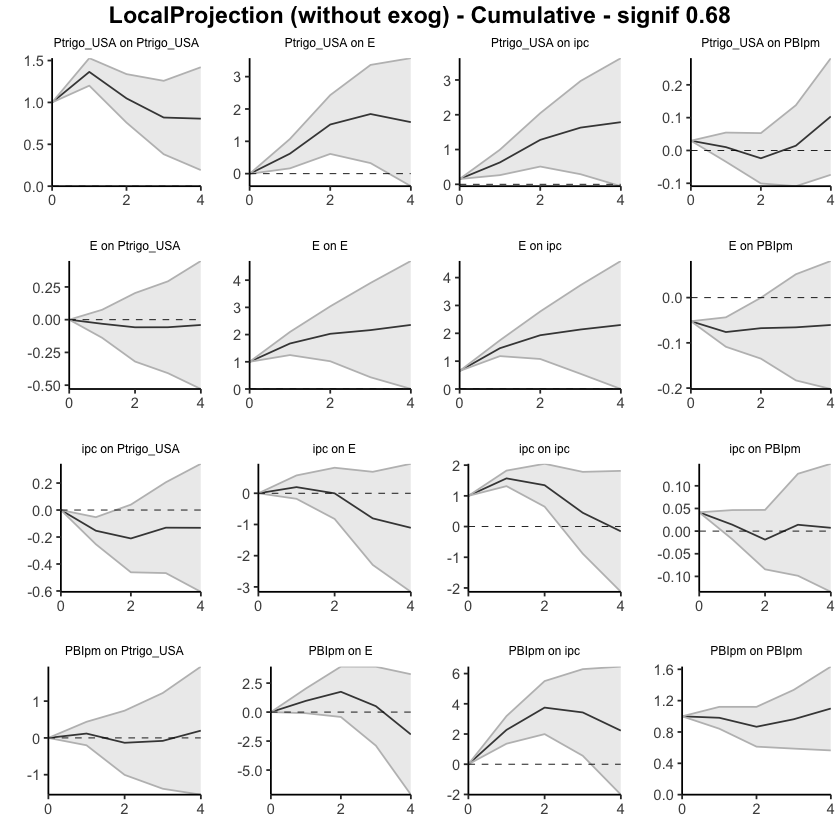

In [12]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10, cumulative = TRUE)

### 1950-2023. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.08301516,-0.3782949,0.2122646
13,ipc,E,2,-0.10446167,-0.4259212,0.2169979
14,ipc,E,3,0.06193937,-0.3788275,0.5027062
15,ipc,E,4,0.39808166,-0.1284956,0.9246589


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,0.5177239,-0.5384533,1.573901
23,PBIpm,E,2,0.6910942,-0.5070432,1.889232
24,PBIpm,E,3,-0.2824582,-1.8930425,1.328126
25,PBIpm,E,4,-1.2187810,-2.5145031,0.076941


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6473514,0.64735144,0.6473514
2,E,ipc,1,0.7650257,0.39250169,1.1375498
3,E,ipc,2,0.5185318,0.12696880,0.9100948
4,E,ipc,3,0.3422549,-0.03972393,0.7242337
5,E,ipc,4,0.2416810,-0.16859597,0.6519580


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.00000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.63935229,0.7949311,2.483773
28,PBIpm,ipc,2,1.30338845,0.2876555,2.319121
29,PBIpm,ipc,3,0.42936617,-1.3771718,2.235904
30,PBIpm,ipc,4,0.07501705,-1.0689165,1.218951


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.055739816,-0.055739816,-0.05573982
7,E,PBIpm,1,-0.013160976,-0.047183170,0.02086122
8,E,PBIpm,2,0.013491430,-0.008601297,0.03558416
9,E,PBIpm,3,0.009344798,-0.027272900,0.04596250
10,E,PBIpm,4,0.011479690,-0.012293910,0.03525329


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.013600162,0.013600162,0.013600162
17,ipc,PBIpm,1,0.018877932,-0.006382017,0.044137880
18,ipc,PBIpm,2,-0.008078698,-0.028982831,0.012825435
19,ipc,PBIpm,3,-0.002998405,-0.032222836,0.026226026
20,ipc,PBIpm,4,-0.032351375,-0.055895390,-0.008807359


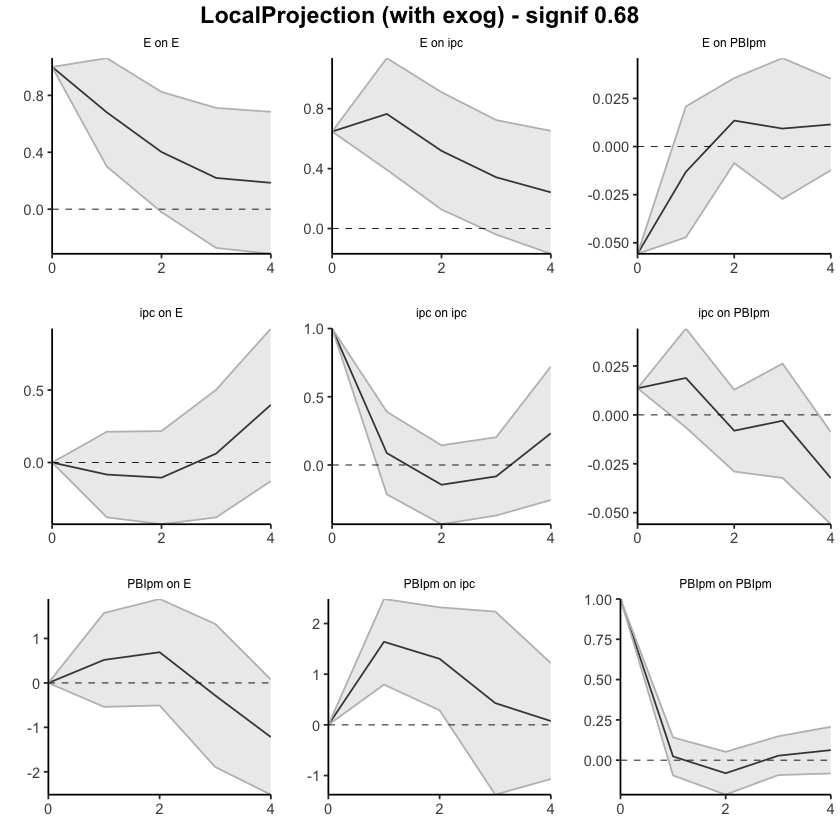

In [33]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.08301516,-0.3782949,0.2122646
13,ipc,E,2,-0.18747683,-0.8042161,0.4292625
14,ipc,E,3,-0.12553746,-1.1830436,0.9319687
15,ipc,E,4,0.27254420,-1.3115392,1.8566276


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,0.5177239,-0.5384533,1.573901
23,PBIpm,E,2,1.2088181,-1.0454965,3.463133
24,PBIpm,E,3,0.9263599,-2.9385390,4.791259
25,PBIpm,E,4,-0.2924211,-5.4530420,4.868200


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6473514,0.6473514,0.6473514
2,E,ipc,1,1.4123772,1.0398531,1.7849012
3,E,ipc,2,1.9309090,1.1668219,2.6949960
4,E,ipc,3,2.2731639,1.1270980,3.4192297
5,E,ipc,4,2.5148449,0.9585020,4.0711877


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.639352,0.7949311,2.483773
28,PBIpm,ipc,2,2.942741,1.0825866,4.802895
29,PBIpm,ipc,3,3.372107,-0.2945852,7.038799
30,PBIpm,ipc,4,3.447124,-1.3635017,8.257750


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05573982,-0.05573982,-0.0557398165
7,E,PBIpm,1,-0.06890079,-0.10292299,-0.0348785988
8,E,PBIpm,2,-0.05540936,-0.11152428,0.0007055584
9,E,PBIpm,3,-0.04606456,-0.13879718,0.0466680548
10,E,PBIpm,4,-0.03458487,-0.15109109,0.0819213444


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.01360016,0.013600162,0.01360016
17,ipc,PBIpm,1,0.03247809,0.007218146,0.05773804
18,ipc,PBIpm,2,0.02439940,-0.021764685,0.07056348
19,ipc,PBIpm,3,0.02140099,-0.053987521,0.09678950
20,ipc,PBIpm,4,-0.01095038,-0.109882911,0.08798214


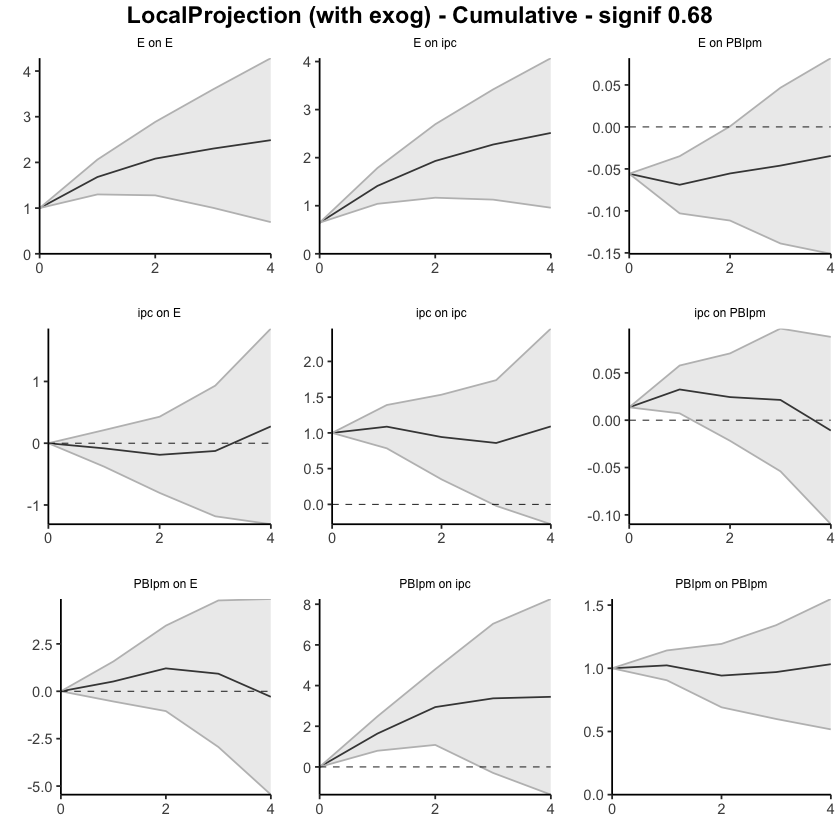

In [32]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,0.1241496,-0.2628340,0.5111332
13,ipc,E,2,-0.1924843,-0.6808301,0.2958615
14,ipc,E,3,-0.6951123,-1.4211887,0.0309640
15,ipc,E,4,-0.2442950,-0.8357100,0.3471200


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,0.6303589,-0.4892429,1.7499607
23,PBIpm,E,2,0.5600342,-0.6139974,1.7340657
24,PBIpm,E,3,-1.1186580,-2.4204371,0.1831212
25,PBIpm,E,4,-2.2433953,-3.8731619,-0.6136287


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6369154,0.63691536,0.6369154
2,E,ipc,1,0.8382847,0.49648452,1.1800848
3,E,ipc,2,0.5220086,-0.09313718,1.1371543
4,E,ipc,3,0.2808509,-0.44243519,1.0041369
5,E,ipc,4,0.1883956,-0.50319493,0.8799861


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIpm,ipc,1,2.0175419,1.1780399,2.8570439
28,PBIpm,ipc,2,1.1563158,0.3456436,1.9669879
29,PBIpm,ipc,3,-0.4473152,-1.6604379,0.7658074
30,PBIpm,ipc,4,-1.1184870,-2.4860000,0.2490261


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.052852028,-0.05285203,-0.05285203
7,E,PBIpm,1,-0.023967307,-0.05930246,0.01136785
8,E,PBIpm,2,0.003737342,-0.03325103,0.04072571
9,E,PBIpm,3,0.004952132,-0.03921843,0.04912269
10,E,PBIpm,4,0.016252630,-0.01605504,0.04856030


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.039103794,0.03910379,0.039103794
17,ipc,PBIpm,1,-0.026406473,-0.05895248,0.006139533
18,ipc,PBIpm,2,-0.041273790,-0.07646656,-0.006081019
19,ipc,PBIpm,3,0.015888080,-0.02598370,0.057759864
20,ipc,PBIpm,4,-0.006723696,-0.04211341,0.028666022


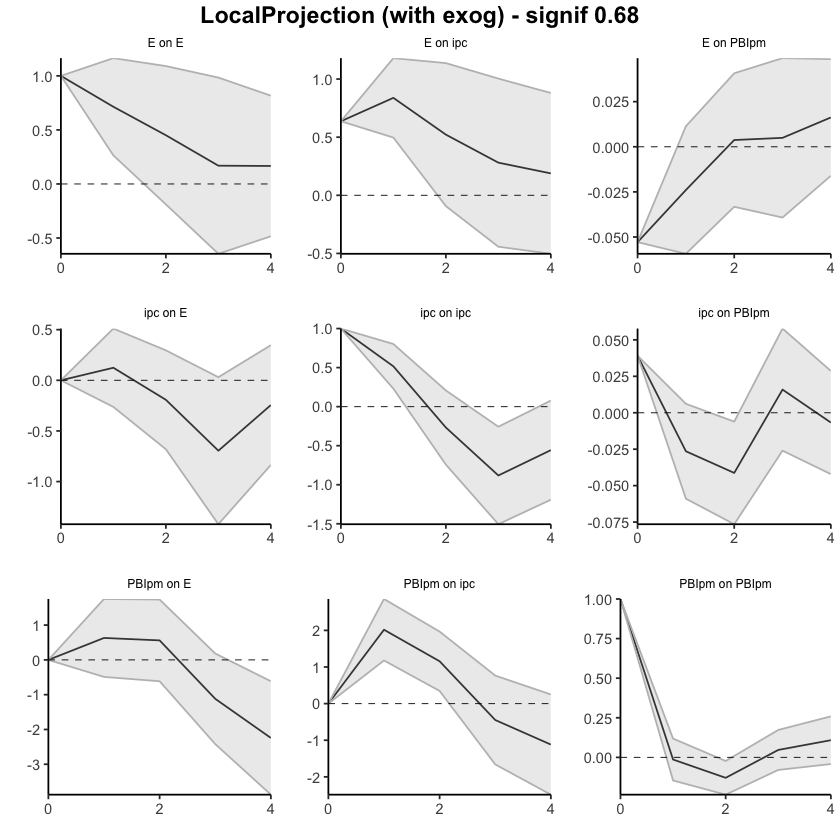

In [31]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.12414960,-0.2628340,0.5111332
13,ipc,E,2,-0.06833474,-0.9436641,0.8069947
14,ipc,E,3,-0.76344706,-2.3648528,0.8379587
15,ipc,E,4,-1.00774207,-3.2005628,1.1850787


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.00000000,0.0000000,0.000000
22,PBIpm,E,1,0.63035892,-0.4892429,1.749961
23,PBIpm,E,2,1.19039308,-1.1032403,3.484026
24,PBIpm,E,3,0.07173511,-3.5236774,3.667148
25,PBIpm,E,4,-2.17166019,-7.3968393,3.053519


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6369154,0.63691536,0.6369154
2,E,ipc,1,1.4752000,1.13339988,1.8170002
3,E,ipc,2,1.9972086,1.04026270,2.9541545
4,E,ipc,3,2.2780595,0.59782751,3.9582914
5,E,ipc,4,2.4664550,0.09463258,4.8382775


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,2.017542,1.1780399,2.857044
28,PBIpm,ipc,2,3.173858,1.5236836,4.824032
29,PBIpm,ipc,3,2.726542,-0.1367543,5.589839
30,PBIpm,ipc,4,1.608056,-2.6227543,5.838865


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05285203,-0.05285203,-0.052852028
7,E,PBIpm,1,-0.07681933,-0.11215449,-0.041484181
8,E,PBIpm,2,-0.07308199,-0.14540552,-0.000758468
9,E,PBIpm,3,-0.06812986,-0.18462394,0.048364222
10,E,PBIpm,4,-0.05187723,-0.20067898,0.096924520


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.03910379,0.03910379,0.03910379
17,ipc,PBIpm,1,0.01269732,-0.01984869,0.04524333
18,ipc,PBIpm,2,-0.02857647,-0.09631525,0.03916231
19,ipc,PBIpm,3,-0.01268839,-0.12229895,0.09692217
20,ipc,PBIpm,4,-0.01941208,-0.16441236,0.12558819


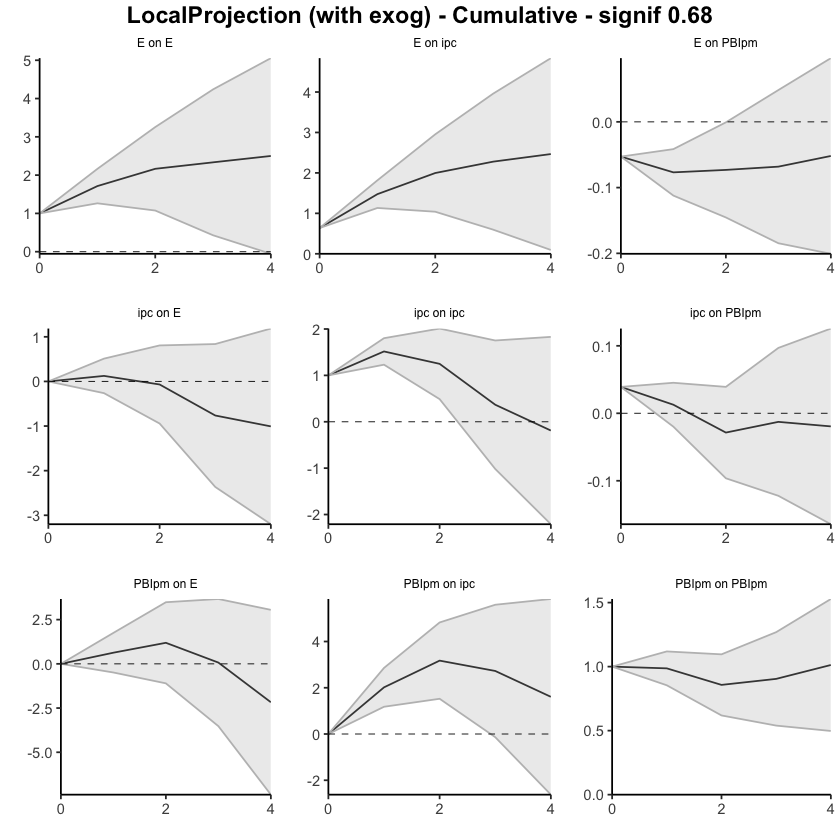

In [30]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.05617340,-0.3410182,0.2286714
13,ipc,E,2,-0.05625377,-0.3697622,0.2572546
14,ipc,E,3,0.06727541,-0.3619773,0.4965282
15,ipc,E,4,0.36707919,-0.2239941,0.9581525


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.00000000
22,PBIpm,E,1,0.4563889,-0.5472815,1.46005930
23,PBIpm,E,2,0.9383736,-0.4608471,2.33759432
24,PBIpm,E,3,-0.1530850,-1.9078915,1.60172153
25,PBIpm,E,4,-1.2916984,-2.6170597,0.03366286


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6625979,0.66259791,0.6625979
2,E,ipc,1,0.7432567,0.38130213,1.1052112
3,E,ipc,2,0.4764438,0.11612263,0.8367650
4,E,ipc,3,0.3141339,-0.06457149,0.6928392
5,E,ipc,4,0.2573834,-0.15294141,0.6677082


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.6932100,0.8938863,2.492534
28,PBIpm,ipc,2,1.5376285,0.3499937,2.725263
29,PBIpm,ipc,3,0.6688013,-1.3997709,2.737374
30,PBIpm,ipc,4,0.0476211,-1.0796441,1.174886


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.054386751,-0.054386751,-0.05438675
7,E,PBIpm,1,-0.013064252,-0.045140825,0.01901232
8,E,PBIpm,2,0.015093013,-0.006306093,0.03649212
9,E,PBIpm,3,0.005664761,-0.030873604,0.04220313
10,E,PBIpm,4,0.005935828,-0.014366231,0.02623789


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.0166445436,0.01664454,0.016644544
17,ipc,PBIpm,1,0.0191818626,-0.00586728,0.044231005
18,ipc,PBIpm,2,-0.0101793222,-0.03152890,0.011170256
19,ipc,PBIpm,3,0.0008208631,-0.02710078,0.028742509
20,ipc,PBIpm,4,-0.0261117816,-0.04690701,-0.005316551


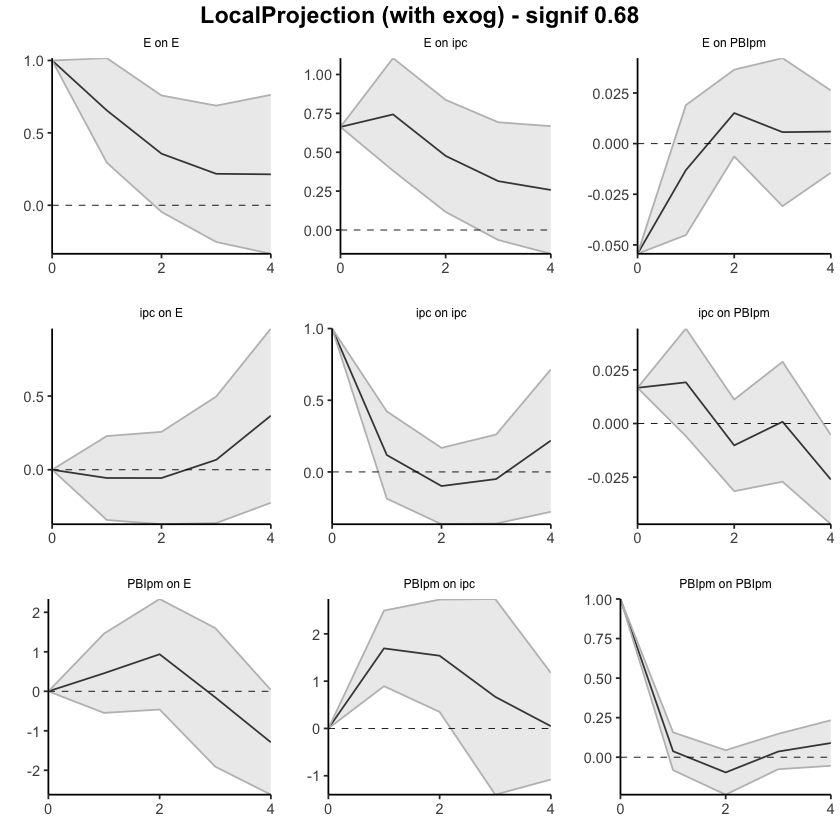

In [29]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.05617340,-0.3410182,0.2286714
13,ipc,E,2,-0.11242717,-0.7107804,0.4859261
14,ipc,E,3,-0.04515176,-1.0727578,0.9824542
15,ipc,E,4,0.32192742,-1.2967519,1.9406068


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.00000000,0.0000000,0.000000
22,PBIpm,E,1,0.45638890,-0.5472815,1.460059
23,PBIpm,E,2,1.39476249,-1.0081286,3.797654
24,PBIpm,E,3,1.24167750,-2.9160202,5.399375
25,PBIpm,E,4,-0.05002092,-5.5330798,5.433038


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6625979,0.6625979,0.6625979
2,E,ipc,1,1.4058546,1.0439000,1.7678091
3,E,ipc,2,1.8822984,1.1600227,2.6045741
4,E,ipc,3,2.1964323,1.0954512,3.2974134
5,E,ipc,4,2.4538157,0.9425098,3.9651216


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.693210,0.8938863,2.492534
28,PBIpm,ipc,2,3.230838,1.2438800,5.217797
29,PBIpm,ipc,3,3.899640,-0.1558909,7.955171
30,PBIpm,ipc,4,3.947261,-1.2355350,9.130057


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05438675,-0.05438675,-0.054386751
7,E,PBIpm,1,-0.06745100,-0.09952758,-0.035374431
8,E,PBIpm,2,-0.05235799,-0.10583367,0.001117689
9,E,PBIpm,3,-0.04669323,-0.13670727,0.043320814
10,E,PBIpm,4,-0.04075740,-0.15107350,0.069558702


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.0166445436,0.01664454,0.01664454
17,ipc,PBIpm,1,0.0358264062,0.01077726,0.06087555
18,ipc,PBIpm,2,0.0256470840,-0.02075164,0.07204580
19,ipc,PBIpm,3,0.0264679471,-0.04785242,0.10078831
20,ipc,PBIpm,4,0.0003561655,-0.09475943,0.09547176


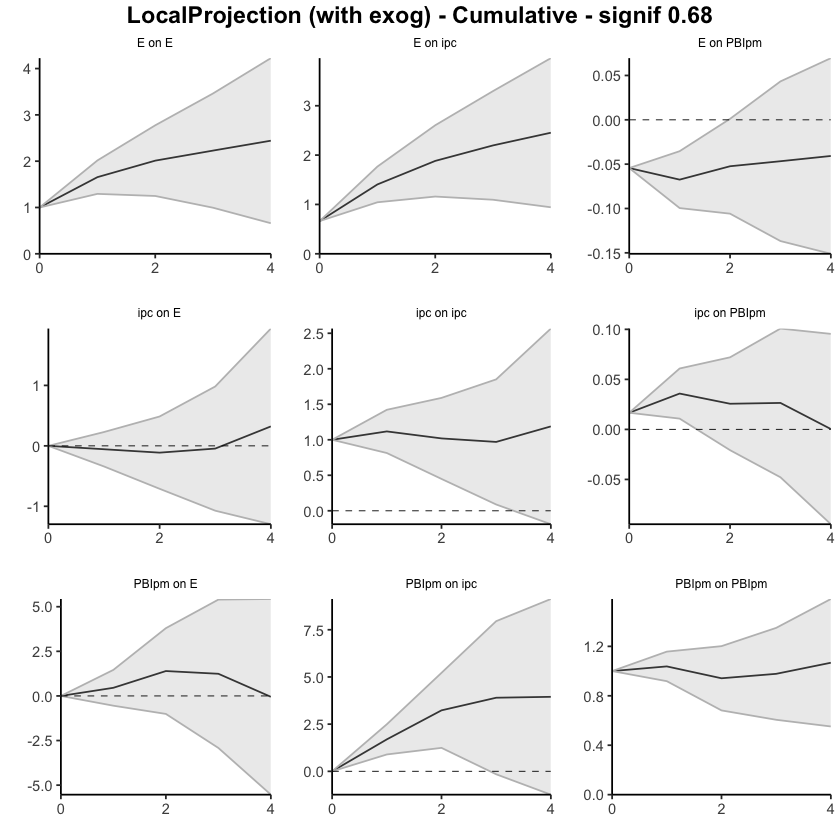

In [28]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.05757865,-0.3510611,0.4662184
13,ipc,E,2,-0.30985955,-0.7900306,0.1703115
14,ipc,E,3,-0.75948027,-1.3449124,-0.1740481
15,ipc,E,4,-0.26802234,-0.7419362,0.2058916


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,0.5919727,-0.5008107,1.6847562
23,PBIpm,E,2,0.6364578,-0.6764695,1.9493851
24,PBIpm,E,3,-1.0402915,-2.3869692,0.3063861
25,PBIpm,E,4,-2.2010694,-3.8746227,-0.5275160


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6452014,0.64520138,0.6452014
2,E,ipc,1,0.8549941,0.53444718,1.1755410
3,E,ipc,2,0.5578072,-0.07730843,1.1929229
4,E,ipc,3,0.2793970,-0.41341680,0.9722109
5,E,ipc,4,0.2071802,-0.38113047,0.7954909


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,2.0996227,1.1422859,3.056959
28,PBIpm,ipc,2,1.3113155,0.3024408,2.320190
29,PBIpm,ipc,3,-0.2218035,-1.4947987,1.051192
30,PBIpm,ipc,4,-1.0680178,-2.4202205,0.284185


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.051841026,-0.05184103,-0.051841026
7,E,PBIpm,1,-0.026573062,-0.06155091,0.008404784
8,E,PBIpm,2,0.004378555,-0.02983102,0.038588130
9,E,PBIpm,3,0.001840637,-0.04813574,0.051817009
10,E,PBIpm,4,0.007705057,-0.01747307,0.032883186


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.04610241,0.04610241,0.046102415
17,ipc,PBIpm,1,-0.02006269,-0.05385469,0.013729313
18,ipc,PBIpm,2,-0.03196102,-0.06552814,0.001606107
19,ipc,PBIpm,3,0.02589477,-0.02140171,0.073191253
20,ipc,PBIpm,4,-0.00874617,-0.03994138,0.022449043


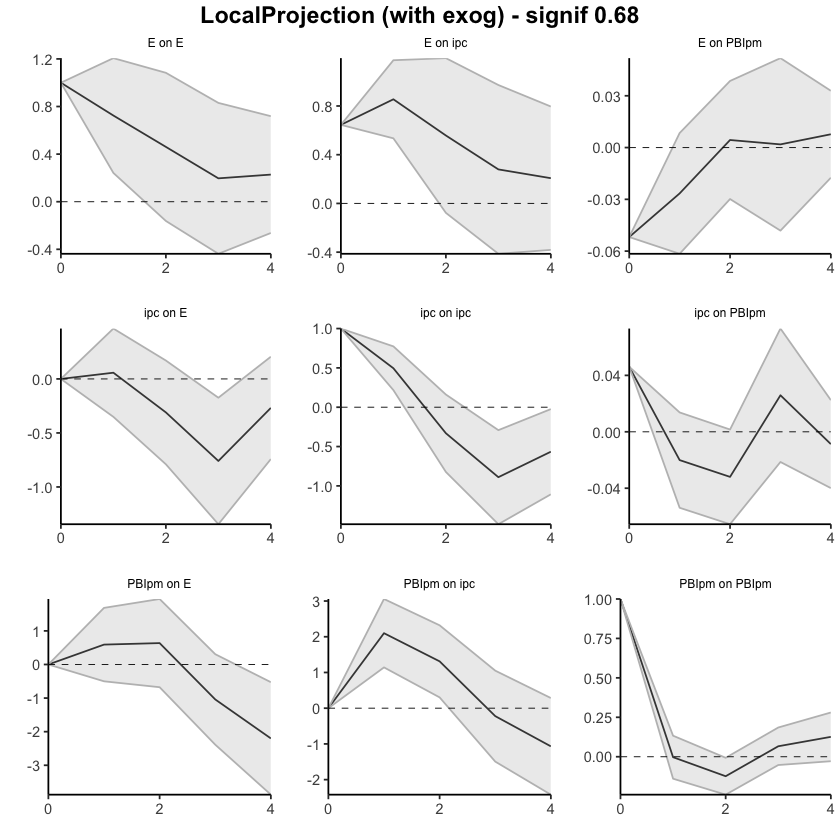

In [27]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.05757865,-0.3510611,0.4662184
13,ipc,E,2,-0.25228090,-1.1410917,0.6365299
14,ipc,E,3,-1.01176117,-2.4860041,0.4624818
15,ipc,E,4,-1.27978351,-3.2279403,0.6683733


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,0.5919727,-0.5008107,1.684756
23,PBIpm,E,2,1.2284305,-1.1772802,3.634141
24,PBIpm,E,3,0.1881390,-3.5642494,3.940527
25,PBIpm,E,4,-2.0129304,-7.4388722,3.413011


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6452014,0.6452014,0.6452014
2,E,ipc,1,1.5001955,1.1796486,1.8207424
3,E,ipc,2,2.0580027,1.1023401,3.0136653
4,E,ipc,3,2.3373998,0.6889233,3.9858762
5,E,ipc,4,2.5445799,0.3077929,4.7813670


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.00000000,0.000000
27,PBIpm,ipc,1,2.099623,1.14228590,3.056959
28,PBIpm,ipc,2,3.410938,1.44472671,5.377150
29,PBIpm,ipc,3,3.189135,-0.05007202,6.428341
30,PBIpm,ipc,4,2.121117,-2.47029254,6.712526


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05184103,-0.05184103,-0.051841026
7,E,PBIpm,1,-0.07841409,-0.11339193,-0.043436243
8,E,PBIpm,2,-0.07403553,-0.14322295,-0.004848113
9,E,PBIpm,3,-0.07219490,-0.19135869,0.046968896
10,E,PBIpm,4,-0.06448984,-0.20883176,0.079852082


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.04610241,0.046102415,0.04610241
17,ipc,PBIpm,1,0.02603973,-0.007752275,0.05983173
18,ipc,PBIpm,2,-0.00592129,-0.073280416,0.06143783
19,ipc,PBIpm,3,0.01997348,-0.094682129,0.13462909
20,ipc,PBIpm,4,0.01122731,-0.134623511,0.15707813


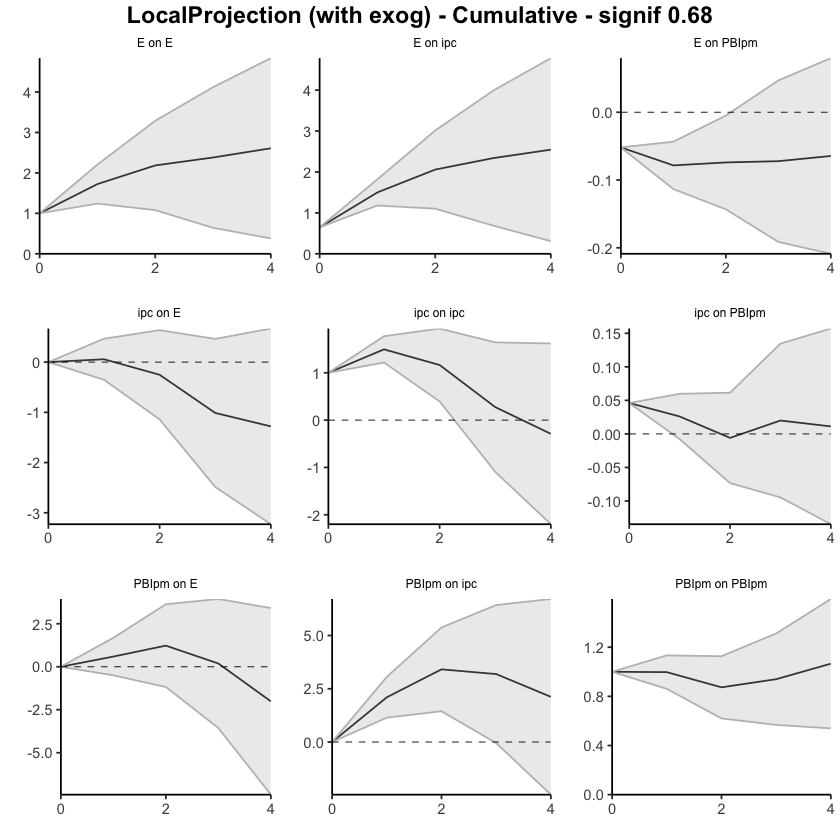

In [26]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.01729989,-0.2902229,0.2556231
13,ipc,E,2,-0.02686648,-0.2994041,0.2456712
14,ipc,E,3,0.04884018,-0.3829952,0.4806756
15,ipc,E,4,0.34321458,-0.2997217,0.9861508


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,0.7790659,-0.2645887,1.8227205
23,PBIpm,E,2,1.0287056,-0.2706608,2.3280720
24,PBIpm,E,3,-0.3668894,-1.9503642,1.2165854
25,PBIpm,E,4,-1.4849358,-2.8551250,-0.1147465


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6565319,0.6565319,0.6565319
2,E,ipc,1,0.7379143,0.4009522,1.0748764
3,E,ipc,2,0.4771244,0.1162269,0.8380220
4,E,ipc,3,0.3274420,-0.1176833,0.7725672
5,E,ipc,4,0.2677619,-0.1068128,0.6423367


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.00000000,0.0000000,0.0000000
27,PBIpm,ipc,1,1.87438161,1.0429361,2.7058271
28,PBIpm,ipc,2,1.64434718,0.5261862,2.7625082
29,PBIpm,ipc,3,0.53594526,-1.2773885,2.3492790
30,PBIpm,ipc,4,-0.09036156,-1.1254299,0.9447068


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.054007186,-0.054007186,-0.05400719
7,E,PBIpm,1,-0.012688282,-0.043103594,0.01772703
8,E,PBIpm,2,0.014815203,-0.005964749,0.03559516
9,E,PBIpm,3,0.004556090,-0.032553166,0.04166535
10,E,PBIpm,4,0.006033848,-0.016412967,0.02848066


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.016152574,0.016152574,0.0161525739
17,ipc,PBIpm,1,0.017379062,-0.006683773,0.0414418972
18,ipc,PBIpm,2,-0.010577092,-0.031140730,0.0099865458
19,ipc,PBIpm,3,0.004517907,-0.024546531,0.0335823438
20,ipc,PBIpm,4,-0.022951002,-0.045491629,-0.0004103744


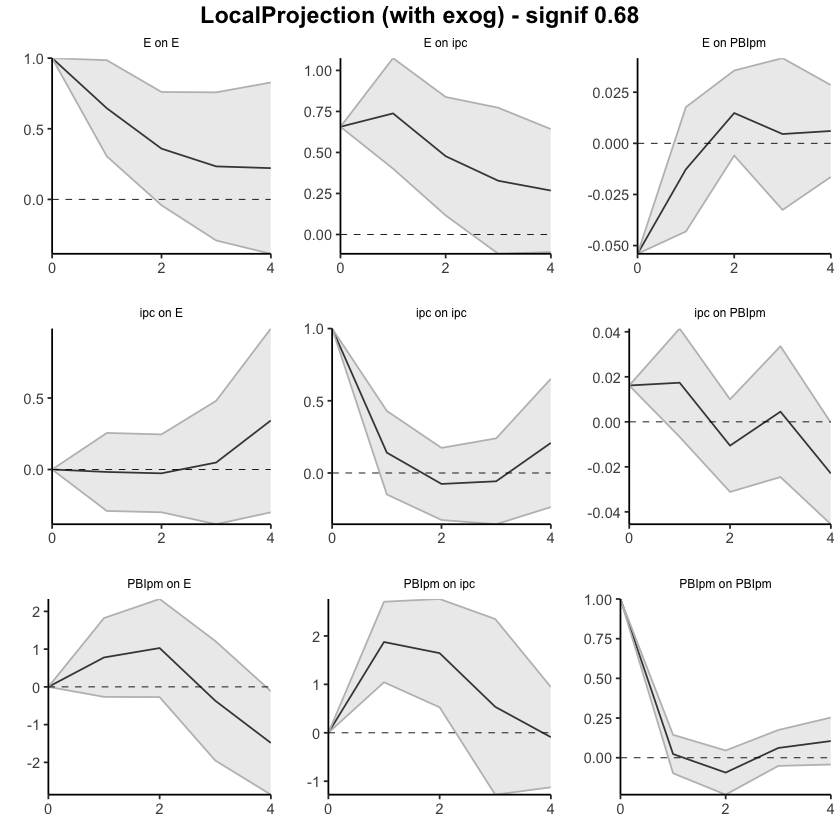

In [25]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.0000000,0.0000000
12,ipc,E,1,-0.017299890,-0.2902229,0.2556231
13,ipc,E,2,-0.044166374,-0.5896270,0.5012943
14,ipc,E,3,0.004673809,-0.9726222,0.9819699
15,ipc,E,4,0.347888390,-1.2723439,1.9681207


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.00000000,0.0000000,0.000000
22,PBIpm,E,1,0.77906589,-0.2645887,1.822720
23,PBIpm,E,2,1.80777149,-0.5352495,4.150792
24,PBIpm,E,3,1.44088211,-2.4856137,5.367378
25,PBIpm,E,4,-0.04405365,-5.3407386,5.252631


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6565319,0.6565319,0.6565319
2,E,ipc,1,1.3944462,1.0574841,1.7314082
3,E,ipc,2,1.8715706,1.1737110,2.5694302
4,E,ipc,3,2.1990126,1.0560277,3.3419975
5,E,ipc,4,2.4667745,0.9492149,3.9843341


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.874382,1.0429361,2.705827
28,PBIpm,ipc,2,3.518729,1.5691222,5.468335
29,PBIpm,ipc,3,4.054674,0.2917337,7.817614
30,PBIpm,ipc,4,3.964312,-0.8336961,8.762321


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05400719,-0.05400719,-0.0540071859
7,E,PBIpm,1,-0.06669547,-0.09711078,-0.0362801555
8,E,PBIpm,2,-0.05188026,-0.10307553,-0.0006850001
9,E,PBIpm,3,-0.04732417,-0.13562870,0.0409803452
10,E,PBIpm,4,-0.04129033,-0.15204166,0.0694610080


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.016152574,0.01615257,0.01615257
17,ipc,PBIpm,1,0.033531636,0.00946880,0.05759447
18,ipc,PBIpm,2,0.022954544,-0.02167193,0.06758102
19,ipc,PBIpm,3,0.027472450,-0.04621846,0.10116336
20,ipc,PBIpm,4,0.004521449,-0.09171009,0.10075299


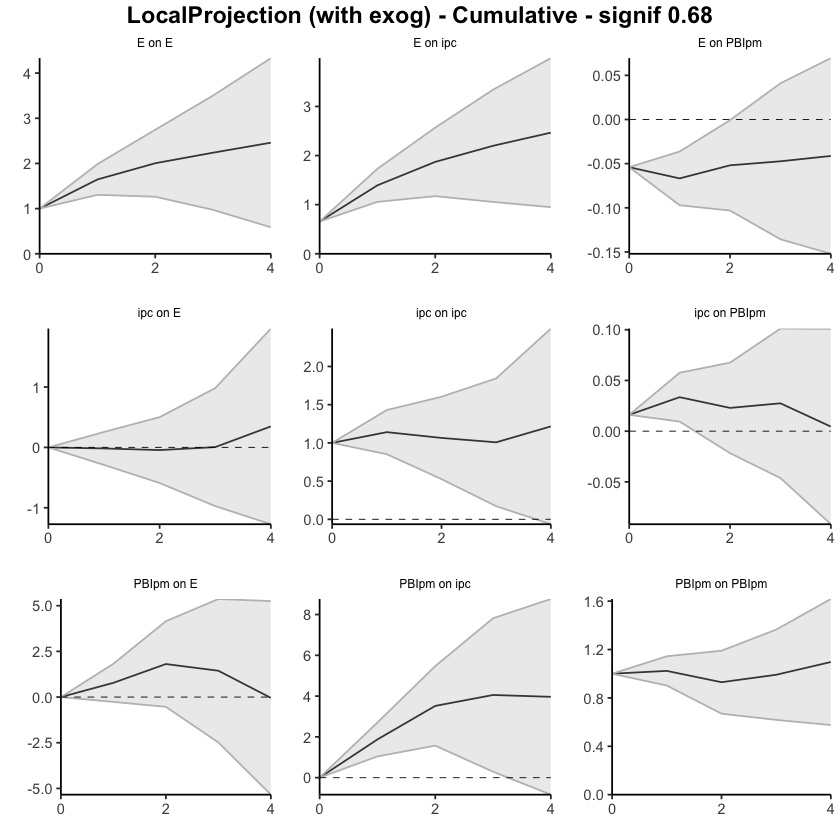

In [24]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,0.2010669,-0.1773182,0.5794519
13,ipc,E,2,-0.1966969,-0.6467796,0.2533859
14,ipc,E,3,-0.8062929,-1.4816083,-0.1309774
15,ipc,E,4,-0.3114536,-0.8782161,0.2553090


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.000000000
22,PBIpm,E,1,0.9682554,-0.09595909,2.032469941
23,PBIpm,E,2,0.7829919,-0.32471963,1.890703423
24,PBIpm,E,3,-1.2417650,-2.47372323,-0.009806762
25,PBIpm,E,4,-2.4370890,-4.22697581,-0.647202157


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6479329,0.6479329,0.6479329
2,E,ipc,1,0.8170969,0.5330543,1.1011394
3,E,ipc,2,0.4658790,-0.1029124,1.0346704
4,E,ipc,3,0.2059300,-0.5325692,0.9444293
5,E,ipc,4,0.1623141,-0.5448838,0.8695120


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIpm,ipc,1,2.2726820,1.3588322,3.1865319
28,PBIpm,ipc,2,1.4765890,0.6351937,2.3179843
29,PBIpm,ipc,3,-0.3208785,-1.4317160,0.7899590
30,PBIpm,ipc,4,-1.2037697,-2.5756400,0.1681005


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.052217862,-0.05221786,-0.052217862
7,E,PBIpm,1,-0.023933489,-0.05647651,0.008609536
8,E,PBIpm,2,0.008551661,-0.02619122,0.043294546
9,E,PBIpm,3,0.001891583,-0.04812462,0.051907782
10,E,PBIpm,4,0.005188590,-0.01902475,0.029401926


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.045092856,0.04509286,0.0450928563
17,ipc,PBIpm,1,-0.027216852,-0.05980494,0.0053712309
18,ipc,PBIpm,2,-0.033545088,-0.06744561,0.0003554293
19,ipc,PBIpm,3,0.033161192,-0.01433293,0.0806553122
20,ipc,PBIpm,4,-0.006227919,-0.03555010,0.0230942638


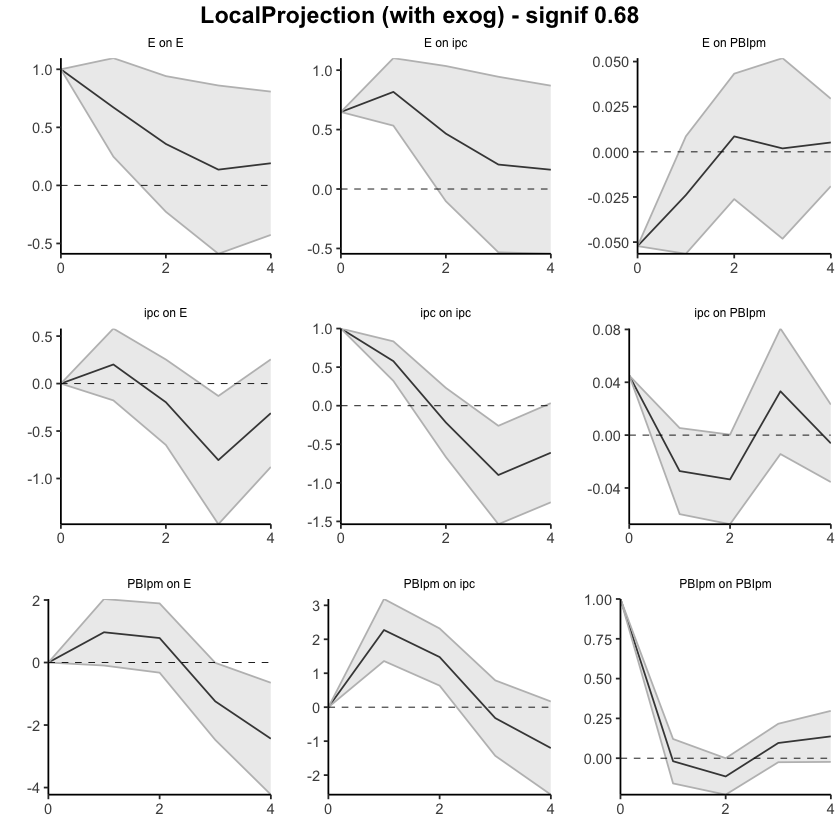

In [23]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,74,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.0000000,0.0000000
12,ipc,E,1,0.201066850,-0.1773182,0.5794519
13,ipc,E,2,0.004369983,-0.8240978,0.8328377
14,ipc,E,3,-0.801922888,-2.3057061,0.7018603
15,ipc,E,4,-1.113376442,-3.1839222,0.9571693


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.000000
22,PBIpm,E,1,0.9682554,-0.09595909,2.032470
23,PBIpm,E,2,1.7512473,-0.42067872,3.923173
24,PBIpm,E,3,0.5094823,-2.89440195,3.913367
25,PBIpm,E,4,-1.9276067,-7.12137776,3.266164


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6479329,0.6479328534,0.6479329
2,E,ipc,1,1.4650297,1.1809871916,1.7490722
3,E,ipc,2,1.9309087,1.0780747853,2.7837426
4,E,ipc,3,2.1368388,0.5455055500,3.7281720
5,E,ipc,4,2.2991529,0.0006217828,4.5976840


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,2.272682,1.3588322,3.186532
28,PBIpm,ipc,2,3.749271,1.9940259,5.504516
29,PBIpm,ipc,3,3.428392,0.5623099,6.294475
30,PBIpm,ipc,4,2.224623,-2.0133301,6.462576


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05221786,-0.05221786,-0.0522178623
7,E,PBIpm,1,-0.07615135,-0.10869438,-0.0436083268
8,E,PBIpm,2,-0.06759969,-0.13488560,-0.0003137812
9,E,PBIpm,3,-0.06570811,-0.18301022,0.0515940009
10,E,PBIpm,4,-0.06051952,-0.20203496,0.0809959271


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.04509286,0.04509286,0.04509286
17,ipc,PBIpm,1,0.01787600,-0.01471208,0.05046409
18,ipc,PBIpm,2,-0.01566908,-0.08215768,0.05081952
19,ipc,PBIpm,3,0.01749211,-0.09649061,0.13147483
20,ipc,PBIpm,4,0.01126419,-0.13204072,0.15456909


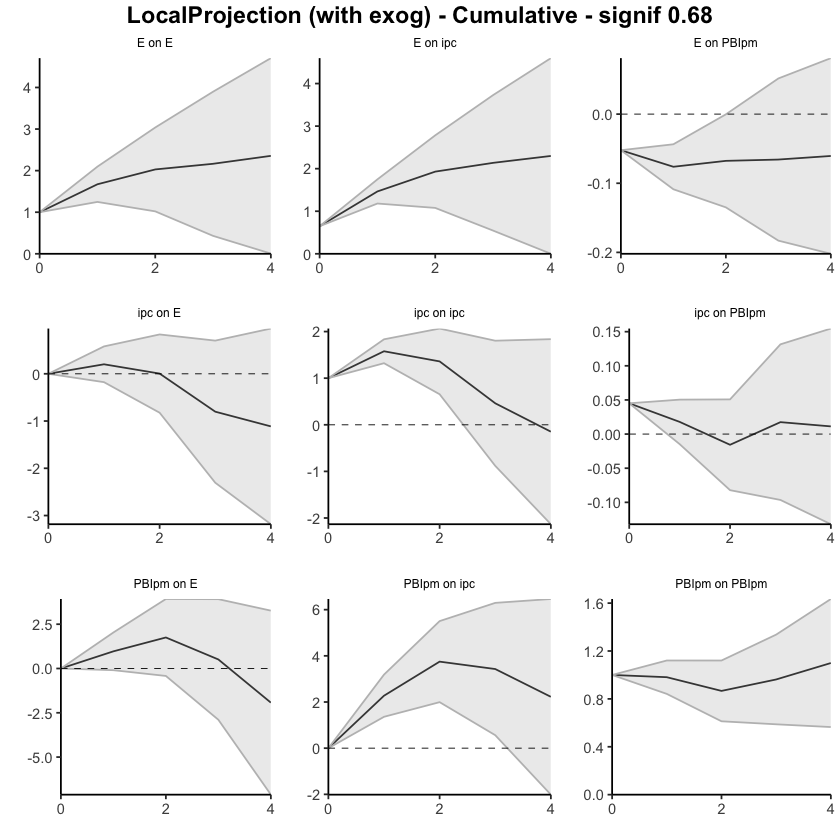

In [22]:
res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)